In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_removaldisp.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_cgrefcodes.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_structures.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_platformincs.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_authorityhist.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_ruers.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_inccount.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_leases.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_rightofways.txt
/kaggle/input/datasets/kabil908/bsee-ds/ProdByPlatformRawData/ProdByPlatformRawData/mv

In [5]:
"""Build a leakage-safe BSEE platform-year modelling table on Kaggle.

Upload this file to a Kaggle notebook and run:

    %run /path/to/kaggle_bsee_preprocessing.py

The script preserves all raw files and writes processed CSV files plus an audit
report under ``data/processed``. It intentionally uses only information known
by the end of year t to predict non-compliance outcomes in year t+1.
"""

from __future__ import annotations

import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd


LOG = logging.getLogger("bsee-preprocessing")
NA_VALUES = ["", " ", "NA", "N/A", "NULL", "None", "UNKNOWN"]


def clean_text(series: pd.Series) -> pd.Series:
    """Trim text while retaining pandas' nullable string representation."""
    return series.astype("string").str.strip().replace("", pd.NA)


def clean_identifier(series: pd.Series, width: int | None = None) -> pd.Series:
    """Normalize identifiers without converting missing values into strings."""
    result = clean_text(series)
    result = result.str.replace(r"\.0$", "", regex=True)
    if width is not None:
        result = result.str.zfill(width)
    return result


def read_csv(path: Path, usecols: list[str] | None = None) -> pd.DataFrame:
    LOG.info("Reading %s", path.name)
    return pd.read_csv(
        path,
        usecols=usecols,
        dtype="string",
        encoding="cp1252",
        na_values=NA_VALUES,
        keep_default_na=True,
        low_memory=False,
    )


def find_table(raw_dir: Path, filename: str) -> Path:
    """Find a BSEE table under either the local or nested Kaggle layout."""
    matches = list(raw_dir.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Could not find {filename!r} below {raw_dir}")
    if len(matches) > 1:
        raise RuntimeError(f"Found multiple copies of {filename!r}: {matches}")
    return matches[0]


def to_number(frame: pd.DataFrame, columns: list[str]) -> None:
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")


def platform_key(complex_id: pd.Series, structure_number: pd.Series) -> pd.Series:
    complex_clean = clean_identifier(complex_id)
    structure_clean = clean_identifier(structure_number)
    key = complex_clean + "::" + structure_clean
    return key.where(complex_clean.notna() & structure_clean.notna())


def aggregate_production(path: Path, chunksize: int) -> pd.DataFrame:
    columns = [
        "COMPLEX_ID_NUM", "STRUCTURE_NUMBER", "AREA_CODE", "BLOCK_NUMBER",
        "LEASE_NUMBER", "STRUCTURE_NAME", "INSTALL_DATE", "REMOVAL_DATE",
        "PF_OPERATOR", "PF_OPERATOR_NUM", "PRODUCTION_DATE", "PRODUCING_WELLS",
        "BOPD", "MCFPD", "BOEPD", "BWPD", "REGION_CODE",
    ]
    partials: list[pd.DataFrame] = []

    LOG.info("Aggregating platform production in chunks")
    for chunk in pd.read_csv(
        path,
        usecols=columns,
        dtype="string",
        encoding="cp1252",
        na_values=NA_VALUES,
        chunksize=chunksize,
        low_memory=False,
    ):
        chunk["platform_id"] = platform_key(
            chunk["COMPLEX_ID_NUM"], chunk["STRUCTURE_NUMBER"]
        )
        chunk["production_date"] = pd.to_datetime(
            chunk["PRODUCTION_DATE"], errors="coerce"
        )
        chunk["year"] = chunk["production_date"].dt.year.astype("Int64")
        chunk["operator_id"] = clean_identifier(chunk["PF_OPERATOR_NUM"], width=5)
        chunk["lease_number"] = clean_identifier(chunk["LEASE_NUMBER"])
        chunk["area_code"] = clean_text(chunk["AREA_CODE"])
        chunk["block_number"] = clean_identifier(chunk["BLOCK_NUMBER"])
        chunk["region_code"] = clean_text(chunk["REGION_CODE"])
        chunk["operator_name"] = clean_text(chunk["PF_OPERATOR"])
        chunk["structure_name"] = clean_text(chunk["STRUCTURE_NAME"])

        numeric = ["PRODUCING_WELLS", "BOPD", "MCFPD", "BOEPD", "BWPD"]
        to_number(chunk, numeric)
        chunk = chunk.dropna(subset=["platform_id", "year"])

        grouped = chunk.groupby(["platform_id", "year"], observed=True).agg(
            active_months=("production_date", "nunique"),
            producing_wells_mean=("PRODUCING_WELLS", "mean"),
            producing_wells_max=("PRODUCING_WELLS", "max"),
            bopd_mean=("BOPD", "mean"),
            bopd_max=("BOPD", "max"),
            mcfd_mean=("MCFPD", "mean"),
            mcfd_max=("MCFPD", "max"),
            boepd_mean=("BOEPD", "mean"),
            bwpd_mean=("BWPD", "mean"),
            operator_id=("operator_id", "last"),
            operator_name=("operator_name", "last"),
            lease_number=("lease_number", "last"),
            area_code=("area_code", "last"),
            block_number=("block_number", "last"),
            region_code=("region_code", "last"),
            structure_name=("structure_name", "last"),
        ).reset_index()
        partials.append(grouped)

    production = pd.concat(partials, ignore_index=True)
    # A platform-year may span input chunks; aggregate the partial results again.
    weighted_columns = [
        "producing_wells_mean", "bopd_mean", "mcfd_mean", "boepd_mean", "bwpd_mean"
    ]
    for column in weighted_columns:
        production[f"_{column}_weighted"] = production[column] * production["active_months"]

    aggregation: dict[str, tuple[str, str]] = {
        "active_months": ("active_months", "sum"),
        "producing_wells_max": ("producing_wells_max", "max"),
        "bopd_max": ("bopd_max", "max"),
        "mcfd_max": ("mcfd_max", "max"),
    }
    for column in weighted_columns:
        aggregation[f"_{column}_weighted"] = (f"_{column}_weighted", "sum")
    for column in [
        "operator_id", "operator_name", "lease_number", "area_code",
        "block_number", "region_code", "structure_name",
    ]:
        aggregation[column] = (column, "last")

    production = production.groupby(
        ["platform_id", "year"], observed=True
    ).agg(**aggregation).reset_index()
    for column in weighted_columns:
        production[column] = production[f"_{column}_weighted"] / production["active_months"]
        production.drop(columns=f"_{column}_weighted", inplace=True)

    production["year"] = production["year"].astype(int)
    return production


def load_structures(path: Path) -> pd.DataFrame:
    columns = [
        "COMPLEX_ID_NUM", "STRUCTURE_NUMBER", "STRUC_TYPE_CODE", "MAJ_STRUC_FLAG",
        "INSTALL_DATE", "REMOVAL_DATE", "DISTRICT_CODE", "HELIPORT_FLAG",
        "LEASE_NUMBER", "WATER_DEPTH", "LATITUDE", "LONGITUDE",
        "ATTENDED_8_HR_FL", "MANNED_24_HR_FL",
    ]
    structures = read_csv(path, columns)
    structures["platform_id"] = platform_key(
        structures["COMPLEX_ID_NUM"], structures["STRUCTURE_NUMBER"]
    )
    structures["install_date"] = pd.to_datetime(structures["INSTALL_DATE"], errors="coerce")
    structures["removal_date"] = pd.to_datetime(structures["REMOVAL_DATE"], errors="coerce")
    structures["lease_number_structure"] = clean_identifier(structures["LEASE_NUMBER"])
    rename = {
        "STRUC_TYPE_CODE": "structure_type",
        "MAJ_STRUC_FLAG": "major_structure_flag",
        "DISTRICT_CODE": "district_code",
        "HELIPORT_FLAG": "heliport_flag",
        "WATER_DEPTH": "water_depth",
        "LATITUDE": "latitude",
        "LONGITUDE": "longitude",
        "ATTENDED_8_HR_FL": "attended_8hr_flag",
        "MANNED_24_HR_FL": "manned_24hr_flag",
    }
    structures.rename(columns=rename, inplace=True)
    to_number(structures, ["water_depth", "latitude", "longitude"])
    keep = ["platform_id", "install_date", "removal_date", "lease_number_structure"] + list(rename.values())
    structures = structures[keep].dropna(subset=["platform_id"])
    return structures.drop_duplicates("platform_id", keep="last")


def load_platform_incs(path: Path) -> pd.DataFrame:
    columns = [
        "ID_NUMBER", "STRUCTURE_NUMBER", "INC_NUMBER", "INC_ENFRC_CODE",
        "MMS_COMPANY_NUM", "INC_ISSUE_DATE", "INSP_DATE",
    ]
    incs = read_csv(path, columns)
    incs["platform_id"] = platform_key(incs["ID_NUMBER"], incs["STRUCTURE_NUMBER"])
    incs["inc_date"] = pd.to_datetime(incs["INC_ISSUE_DATE"], errors="coerce")
    incs["year"] = incs["inc_date"].dt.year.astype("Int64")
    incs["operator_id_inc"] = clean_identifier(incs["MMS_COMPANY_NUM"], width=5)
    incs["enforcement_code"] = clean_text(incs["INC_ENFRC_CODE"])
    incs = incs.dropna(subset=["platform_id", "year"])
    result = incs.groupby(["platform_id", "year"], observed=True).agg(
        inc_count=("INC_NUMBER", "count"),
        enforcement_code_count=("enforcement_code", "nunique"),
        operator_id_inc=("operator_id_inc", "last"),
    ).reset_index()
    result["year"] = result["year"].astype(int)
    return result


def load_operator_activity(inspections_path: Path, incs_path: Path) -> pd.DataFrame:
    inspections = read_csv(inspections_path)
    inspections["date"] = pd.to_datetime(inspections["INS_DATE"], errors="coerce")
    inspections["year"] = inspections["date"].dt.year.astype("Int64")
    inspections["operator_id"] = clean_identifier(inspections["BUS_ASC_CODE"], width=5)
    to_number(inspections, ["FACILITIES_INSPECTED", "INSPECTION_RECORDS", "INSPECTION_TYPES"])
    inspections = inspections.dropna(subset=["operator_id", "year"])
    inspections = inspections.groupby(["operator_id", "year"], observed=True).agg(
        operator_facilities_inspected=("FACILITIES_INSPECTED", "sum"),
        operator_inspection_records=("INSPECTION_RECORDS", "sum"),
        operator_inspection_types=("INSPECTION_TYPES", "sum"),
    ).reset_index()

    incs = read_csv(incs_path)
    incs["date"] = pd.to_datetime(incs["INC_DATE"], errors="coerce")
    incs["year"] = incs["date"].dt.year.astype("Int64")
    incs["operator_id"] = clean_identifier(incs["BUS_ASC_CODE"], width=5)
    to_number(incs, ["WARNING_INCS", "COMP_SHUTIN_INCS", "FAC_SHUTIN_INCS"])
    incs = incs.dropna(subset=["operator_id", "year"])
    incs = incs.groupby(["operator_id", "year"], observed=True).agg(
        operator_warning_incs=("WARNING_INCS", "sum"),
        operator_component_shutin_incs=("COMP_SHUTIN_INCS", "sum"),
        operator_facility_shutin_incs=("FAC_SHUTIN_INCS", "sum"),
    ).reset_index()

    activity = inspections.merge(incs, on=["operator_id", "year"], how="outer")
    activity["year"] = activity["year"].astype(int)
    return activity


def load_accidents(path: Path) -> pd.DataFrame:
    accidents = read_csv(path)
    accidents["date"] = pd.to_datetime(accidents["DATE_OCCURRED"], errors="coerce")
    accidents["year"] = accidents["date"].dt.year.astype("Int64")
    accidents["lease_number"] = clean_identifier(accidents["LEASE_NUMBER"])
    accidents = accidents.dropna(subset=["lease_number", "year"])
    result = accidents.groupby(["lease_number", "year"], observed=True).agg(
        investigated_accident_count=("ACCIDENT_TYPE", "size"),
        accident_type_count=("ACCIDENT_TYPE", "nunique"),
    ).reset_index()
    result["year"] = result["year"].astype(int)
    return result


def add_history_and_targets(panel: pd.DataFrame) -> pd.DataFrame:
    panel = panel.sort_values(["platform_id", "year"]).reset_index(drop=True)
    group = panel.groupby("platform_id", observed=True, sort=False)

    panel["previous_year_inc_count"] = group["inc_count"].shift(1)
    panel["inc_count_previous_3_observations"] = group["inc_count"].transform(
        lambda values: values.shift(1).rolling(3, min_periods=1).sum()
    )
    panel["previous_year_accident_count"] = group["investigated_accident_count"].shift(1)
    panel["production_change_bopd"] = group["bopd_mean"].pct_change(fill_method=None)
    panel["production_change_mcfd"] = group["mcfd_mean"].pct_change(fill_method=None)

    next_year = panel[["platform_id", "year", "inc_count"]].copy()
    next_year["year"] = next_year["year"] - 1
    next_year.rename(columns={"inc_count": "next_year_inc_count"}, inplace=True)
    panel = panel.merge(next_year, on=["platform_id", "year"], how="left")
    panel["next_year_any_inc"] = np.where(
        panel["next_year_inc_count"].notna(),
        (panel["next_year_inc_count"] > 0).astype("int8"),
        np.nan,
    )
    return panel


def build_dataset(raw_dir: Path, output_dir: Path, chunksize: int) -> pd.DataFrame:
    production = aggregate_production(
        find_table(raw_dir, "mv_prod_by_platform_all.txt"), chunksize
    )
    structures = load_structures(
        find_table(raw_dir, "mv_platstruc_structures.txt")
    )
    platform_incs = load_platform_incs(
        find_table(raw_dir, "mv_platstruc_platformincs.txt")
    )
    operator_activity = load_operator_activity(
        find_table(raw_dir, "mv_insp_by_oper.txt"),
        find_table(raw_dir, "mv_incs_by_oper.txt"),
    )
    accidents = load_accidents(
        find_table(raw_dir, "mv_acc_investigations.txt")
    )

    panel = production.merge(structures, on="platform_id", how="left", validate="many_to_one")
    panel["lease_number"] = panel["lease_number"].fillna(panel["lease_number_structure"])
    panel.drop(columns="lease_number_structure", inplace=True)
    panel["platform_age"] = panel["year"] - panel["install_date"].dt.year
    panel["years_until_removal"] = panel["removal_date"].dt.year - panel["year"]

    panel = panel.merge(platform_incs, on=["platform_id", "year"], how="left", validate="one_to_one")
    panel["operator_id"] = panel["operator_id"].fillna(panel["operator_id_inc"])
    panel.drop(columns="operator_id_inc", inplace=True)
    panel = panel.merge(operator_activity, on=["operator_id", "year"], how="left", validate="many_to_one")
    panel = panel.merge(accidents, on=["lease_number", "year"], how="left", validate="many_to_one")

    count_columns = [
        "inc_count", "enforcement_code_count", "operator_facilities_inspected",
        "operator_inspection_records", "operator_inspection_types",
        "operator_warning_incs", "operator_component_shutin_incs",
        "operator_facility_shutin_incs", "investigated_accident_count",
        "accident_type_count",
    ]
    panel[count_columns] = panel[count_columns].fillna(0)
    panel["any_inc"] = (panel["inc_count"] > 0).astype("int8")
    panel = add_history_and_targets(panel)

    output_dir.mkdir(parents=True, exist_ok=True)
    full_path = output_dir / "bsee_platform_year_full.csv.gz"
    model_path = output_dir / "bsee_platform_year_model.csv.gz"
    panel.to_csv(full_path, index=False, compression="gzip")
    model = panel.loc[panel["next_year_inc_count"].notna()].copy()
    model.to_csv(model_path, index=False, compression="gzip")

    audit = {
        "rows_full": int(len(panel)),
        "rows_model": int(len(model)),
        "platforms": int(panel["platform_id"].nunique()),
        "minimum_year": int(panel["year"].min()),
        "maximum_year": int(panel["year"].max()),
        "current_inc_positive_rate": float(panel["any_inc"].mean()),
        "next_year_inc_positive_rate": float(model["next_year_any_inc"].mean()),
        "missing_percent": {
            column: round(float(panel[column].isna().mean() * 100), 3)
            for column in panel.columns
        },
    }
    (output_dir / "preprocessing_audit.json").write_text(
        json.dumps(audit, indent=2), encoding="utf-8"
    )
    LOG.info("Wrote %s", full_path)
    LOG.info("Wrote %s", model_path)
    return panel


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
    raw_dir = Path("/kaggle/input/datasets/kabil908/bsee-ds")
    output_dir = Path("/kaggle/working/bsee_processed")
    chunksize = 250_000

    if not raw_dir.exists():
        raise FileNotFoundError(f"BSEE Kaggle input directory not found: {raw_dir}")

    LOG.info("Input directory: %s", raw_dir)
    LOG.info("Output directory: %s", output_dir)
    panel = build_dataset(raw_dir, output_dir, chunksize)
    LOG.info("Finished: %s platform-year rows", f"{len(panel):,}")


if __name__ == "__main__":
    main()


INFO Input directory: /kaggle/input/datasets/kabil908/bsee-ds
INFO Output directory: /kaggle/working/bsee_processed
INFO Aggregating platform production in chunks
INFO Reading mv_platstruc_structures.txt
INFO Reading mv_platstruc_platformincs.txt
INFO Reading mv_insp_by_oper.txt
/tmp/ipykernel_49/3999677067.py:221: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  inspections["date"] = pd.to_datetime(inspections["INS_DATE"], errors="coerce")
INFO Reading mv_incs_by_oper.txt
INFO Reading mv_acc_investigations.txt
INFO Wrote /kaggle/working/bsee_processed/bsee_platform_year_full.csv.gz
INFO Wrote /kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz
INFO Finished: 148,672 platform-year rows


In [6]:
from pathlib import Path
import json
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/bsee_processed")

model = pd.read_csv(
    OUTPUT_DIR / "bsee_platform_year_model.csv.gz",
    low_memory=False,
)

with open(
    OUTPUT_DIR / "preprocessing_audit.json",
    encoding="utf-8",
) as file:
    audit = json.load(file)

print("Shape:", model.shape)
print("Platforms:", model["platform_id"].nunique())
print("Years:", model["year"].min(), "-", model["year"].max())

print("\nTarget distribution:")
print(model["next_year_any_inc"].value_counts())

print("\nTarget percentages:")
print(
    model["next_year_any_inc"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDuplicate platform-years:")
print(model.duplicated(["platform_id", "year"]).sum())

display(model.head())


Shape: (141730, 49)
Platforms: 6158
Years: 1947 - 2025

Target distribution:
next_year_any_inc
0.0    115487
1.0     26243
Name: count, dtype: int64

Target percentages:
next_year_any_inc
0.0    81.48
1.0    18.52
Name: proportion, dtype: float64

Duplicate platform-years:
0


,platform_id,year,active_months,producing_wells_max,bopd_max,mcfd_max,operator_id,operator_name,lease_number,area_code,...,investigated_accident_count,accident_type_count,any_inc,previous_year_inc_count,inc_count_previous_3_observations,previous_year_accident_count,production_change_bopd,production_change_mcfd,next_year_inc_count,next_year_any_inc
0,10001::1,1972,9,2,102,23139,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1,10001::1,1973,11,2,29,3347,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.870370,-0.852270,0.0,0.0
2,10001::1,1974,12,2,2,3940,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.880952,0.062484,0.0,0.0
3,10001::1,1975,12,2,3,3271,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,1.200000,0.032670,0.0,0.0
4,10001::1,1976,12,2,2,2947,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.318182,-0.303032,0.0,0.0


In [7]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

OUTPUT_DIR = Path("/kaggle/working/bsee_processed")
ZIP_PATH = Path("/kaggle/working/bsee_preprocessed_dataset.zip")

files_to_package = [
    OUTPUT_DIR / "bsee_platform_year_full.csv.gz",
    OUTPUT_DIR / "bsee_platform_year_model.csv.gz",
    OUTPUT_DIR / "preprocessing_audit.json",
]

# Validate files before creating the archive
missing_files = [
    str(file_path)
    for file_path in files_to_package
    if not file_path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following output files are missing:\n"
        + "\n".join(missing_files)
    )

# Create ZIP archive
with ZipFile(
    ZIP_PATH,
    mode="w",
    compression=ZIP_DEFLATED,
    compresslevel=9,
) as zip_file:
    for file_path in files_to_package:
        zip_file.write(
            filename=file_path,
            arcname=file_path.name,
        )

# Verify ZIP contents
with ZipFile(ZIP_PATH, mode="r") as zip_file:
    bad_files = zip_file.testzip()
    archive_contents = zip_file.infolist()

if bad_files is not None:
    raise RuntimeError(f"Corrupted file detected: {bad_files}")

print("ZIP archive created successfully")
print("Path:", ZIP_PATH)
print(f"Size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

print("\nArchive contents:")
for item in archive_contents:
    print(
        f"- {item.filename}: "
        f"{item.file_size / (1024**2):.2f} MB"
    )

display(FileLink(str(ZIP_PATH)))

ZIP archive created successfully
Path: /kaggle/working/bsee_preprocessed_dataset.zip
Size: 13.06 MB

Archive contents:
- bsee_platform_year_full.csv.gz: 6.63 MB
- bsee_platform_year_model.csv.gz: 6.42 MB
- preprocessing_audit.json: 0.00 MB


/kaggle/working/bsee_preprocessed_dataset.zip

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("/kaggle/working/bsee_processed")
FIGURE_DIR = Path("/kaggle/working/bsee_eda_figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = DATA_DIR / "bsee_platform_year_model.csv.gz"

df = pd.read_csv(MODEL_PATH, low_memory=False)

print("Shape:", df.shape)
print("Platforms:", df["platform_id"].nunique())
print("Years:", df["year"].min(), "-", df["year"].max())
print("Duplicate platform-years:",
      df.duplicated(["platform_id", "year"]).sum())

display(df.head())

Shape: (141730, 49)
Platforms: 6158
Years: 1947 - 2025
Duplicate platform-years: 0


,platform_id,year,active_months,producing_wells_max,bopd_max,mcfd_max,operator_id,operator_name,lease_number,area_code,...,investigated_accident_count,accident_type_count,any_inc,previous_year_inc_count,inc_count_previous_3_observations,previous_year_accident_count,production_change_bopd,production_change_mcfd,next_year_inc_count,next_year_any_inc
0,10001::1,1972,9,2,102,23139,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1,10001::1,1973,11,2,29,3347,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.870370,-0.852270,0.0,0.0
2,10001::1,1974,12,2,2,3940,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.880952,0.062484,0.0,0.0
3,10001::1,1975,12,2,3,3271,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,1.200000,0.032670,0.0,0.0
4,10001::1,1976,12,2,2,2947,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.318182,-0.303032,0.0,0.0


In [9]:
TARGET = "next_year_any_inc"

# Exclude observations whose outcome year is incomplete
df = df[df["year"] <= 2024].copy()

# Retain the complete history for temporal coverage analysis
df_history = df.copy()

# Candidate modern study period
df_eda = df[df["year"] >= 1990].copy()

print("Complete historical sample:", df_history.shape)
print("Candidate 1990–2024 sample:", df_eda.shape)
print("Candidate platforms:", df_eda["platform_id"].nunique())

print("\nTarget distribution:")
display(
    df_eda[TARGET]
    .value_counts(dropna=False)
    .rename_axis("class")
    .to_frame("count")
    .assign(
        percentage=lambda x:
        (100 * x["count"] / x["count"].sum()).round(2)
    )
)

Complete historical sample: (141110, 49)
Candidate 1990–2024 sample: (88472, 49)
Candidate platforms: 5478

Target distribution:


,count,percentage
class,,
0.0,66676,75.36
1.0,21796,24.64


,dtype,missing_count,missing_percent,unique_values
removal_date,object,30973,35.01,3185
years_until_removal,float64,30973,35.01,84
production_change_bopd,float64,29518,33.36,43908
production_change_mcfd,float64,22987,25.98,58573
previous_year_inc_count,float64,2125,2.40,53
inc_count_previous_3_observations,float64,2125,2.40,90
previous_year_accident_count,float64,2125,2.40,6
attended_8hr_flag,object,1757,1.99,2
lease_number,object,1705,1.93,2560
heliport_flag,object,895,1.01,2


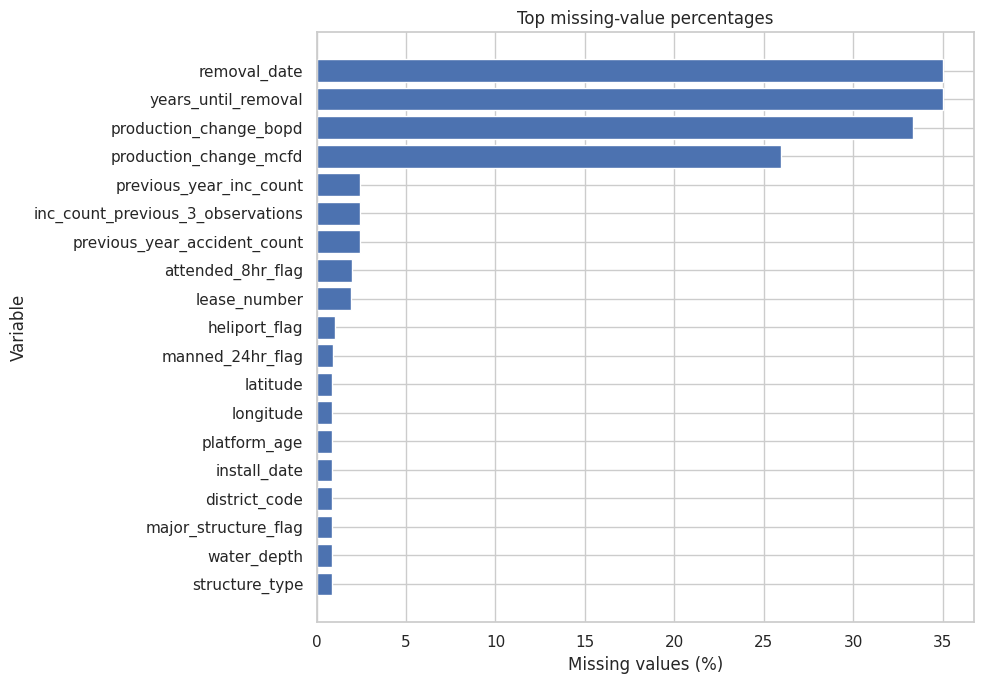

In [10]:
summary = pd.DataFrame({
    "dtype": df_eda.dtypes.astype(str),
    "missing_count": df_eda.isna().sum(),
    "missing_percent": df_eda.isna().mean().mul(100),
    "unique_values": df_eda.nunique(dropna=True),
})

summary = summary.sort_values(
    "missing_percent",
    ascending=False,
)

display(summary.round(2))

summary.to_csv(
    DATA_DIR / "eda_variable_summary.csv",
    index_label="variable",
)

missing_plot = (
    summary[summary["missing_percent"] > 0]
    .head(20)
    .sort_values("missing_percent")
)

plt.figure(figsize=(10, 7))
plt.barh(
    missing_plot.index,
    missing_plot["missing_percent"],
)
plt.xlabel("Missing values (%)")
plt.ylabel("Variable")
plt.title("Top missing-value percentages")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "01_missingness.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

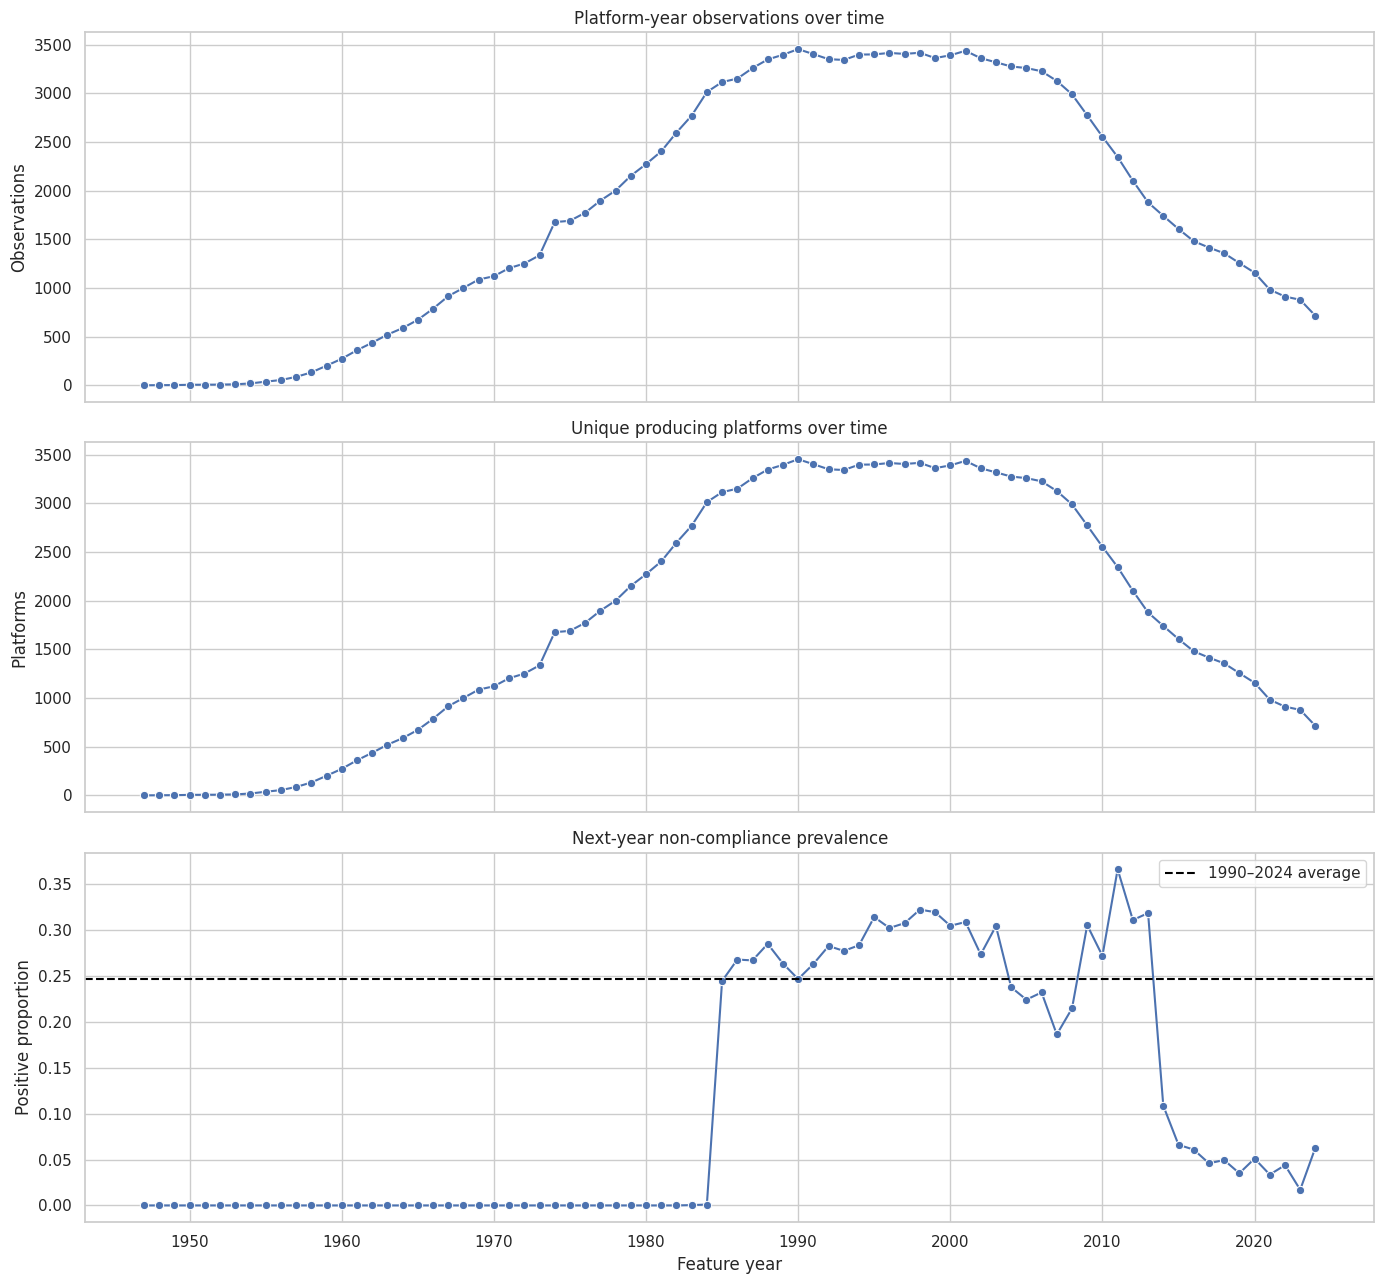

,year,observations,platforms,positive_cases,positive_rate,mean_inc_count
63,2010,2554,2554,694.0,0.271731,0.751762
64,2011,2345,2345,858.0,0.365885,0.950959
65,2012,2102,2102,653.0,0.310657,0.921979
66,2013,1879,1879,598.0,0.318254,0.873869
67,2014,1741,1741,189.0,0.108558,0.246410
68,2015,1606,1606,106.0,0.066002,0.180573
69,2016,1481,1481,90.0,0.060770,0.162053
70,2017,1415,1415,65.0,0.045936,0.071378
71,2018,1357,1357,67.0,0.049374,0.100221
72,2019,1256,1256,44.0,0.035032,0.050159


In [11]:
yearly = (
    df_history.groupby("year")
    .agg(
        observations=("platform_id", "size"),
        platforms=("platform_id", "nunique"),
        positive_cases=(TARGET, "sum"),
        positive_rate=(TARGET, "mean"),
        mean_inc_count=("next_year_inc_count", "mean"),
    )
    .reset_index()
)

yearly.to_csv(
    DATA_DIR / "eda_yearly_summary.csv",
    index=False,
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 13),
    sharex=True,
)

sns.lineplot(
    data=yearly,
    x="year",
    y="observations",
    marker="o",
    ax=axes[0],
)

axes[0].set_title("Platform-year observations over time")
axes[0].set_ylabel("Observations")

sns.lineplot(
    data=yearly,
    x="year",
    y="platforms",
    marker="o",
    ax=axes[1],
)

axes[1].set_title("Unique producing platforms over time")
axes[1].set_ylabel("Platforms")

sns.lineplot(
    data=yearly,
    x="year",
    y="positive_rate",
    marker="o",
    ax=axes[2],
)

axes[2].axhline(
    df_eda[TARGET].mean(),
    linestyle="--",
    color="black",
    label="1990–2024 average",
)

axes[2].set_title("Next-year non-compliance prevalence")
axes[2].set_ylabel("Positive proportion")
axes[2].set_xlabel("Feature year")
axes[2].legend()

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "02_temporal_coverage.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

display(yearly.tail(15))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness
active_months,88472.0,11.838,1.080,1.0,5.0,12.0,12.0,12.000,12.000,12.000,12.000,12.000,-7.582
producing_wells_mean,88472.0,1.951,3.434,0.0,0.0,0.0,0.0,1.000,2.000,8.000,17.583,49.333,4.184
bopd_mean,88472.0,576.012,4900.335,0.0,0.0,0.0,0.0,6.917,123.333,1178.871,9836.091,186785.750,18.417
mcfd_mean,88472.0,3400.089,14341.255,0.0,0.0,0.0,0.0,313.292,2234.000,14169.162,45928.346,801614.000,19.568
boepd_mean,88472.0,1181.007,6462.560,0.0,0.0,0.0,0.0,142.667,659.188,3552.921,17201.539,218855.083,15.443
bwpd_mean,88472.0,656.980,2414.475,0.0,0.0,0.0,0.0,21.833,427.083,2850.458,9675.638,99974.667,12.101
water_depth,87690.0,163.146,547.815,1.0,11.0,16.0,37.0,60.000,143.000,324.550,3216.000,9560.000,9.515
platform_age,87690.0,20.056,14.866,-19.0,-2.0,1.0,8.0,18.000,30.000,47.000,58.000,74.000,0.592
previous_year_inc_count,86347.0,0.839,2.520,0.0,0.0,0.0,0.0,0.000,1.000,5.000,11.000,102.000,7.848
inc_count_previous_3_observations,86347.0,2.495,5.410,0.0,0.0,0.0,0.0,0.000,3.000,12.000,26.000,123.000,5.286


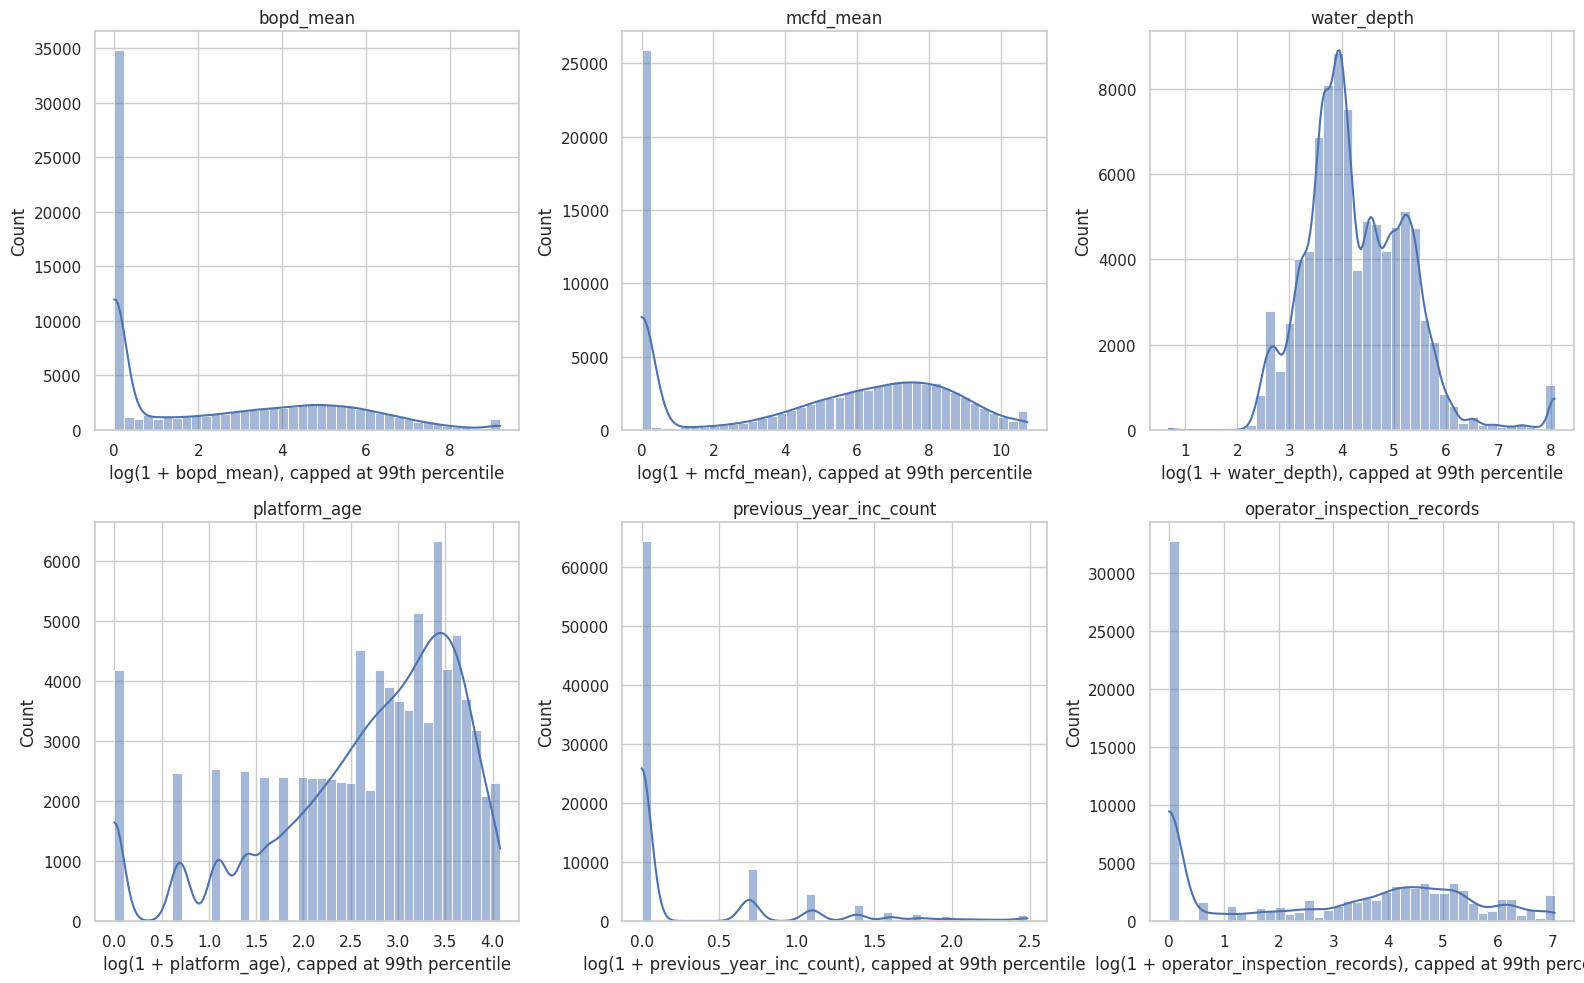

In [12]:
numeric_features = [
    "active_months",
    "producing_wells_mean",
    "bopd_mean",
    "mcfd_mean",
    "boepd_mean",
    "bwpd_mean",
    "water_depth",
    "platform_age",
    "previous_year_inc_count",
    "inc_count_previous_3_observations",
    "operator_inspection_records",
    "operator_warning_incs",
    "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
    "investigated_accident_count",
]

available_numeric = [
    column for column in numeric_features
    if column in df_eda.columns
]

description = (
    df_eda[available_numeric]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)

description["skewness"] = df_eda[available_numeric].skew()
display(description.round(3))

description.to_csv(
    DATA_DIR / "eda_numeric_summary.csv",
)

plot_features = [
    "bopd_mean",
    "mcfd_mean",
    "water_depth",
    "platform_age",
    "previous_year_inc_count",
    "operator_inspection_records",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for axis, column in zip(axes, plot_features):
    values = pd.to_numeric(
        df_eda[column],
        errors="coerce",
    ).clip(lower=0)

    upper_limit = values.quantile(0.99)
    plot_values = values.clip(upper=upper_limit)

    sns.histplot(
        np.log1p(plot_values.dropna()),
        bins=40,
        kde=True,
        ax=axis,
    )

    axis.set_title(column)
    axis.set_xlabel(f"log(1 + {column}), capped at 99th percentile")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "03_numeric_distributions.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical un

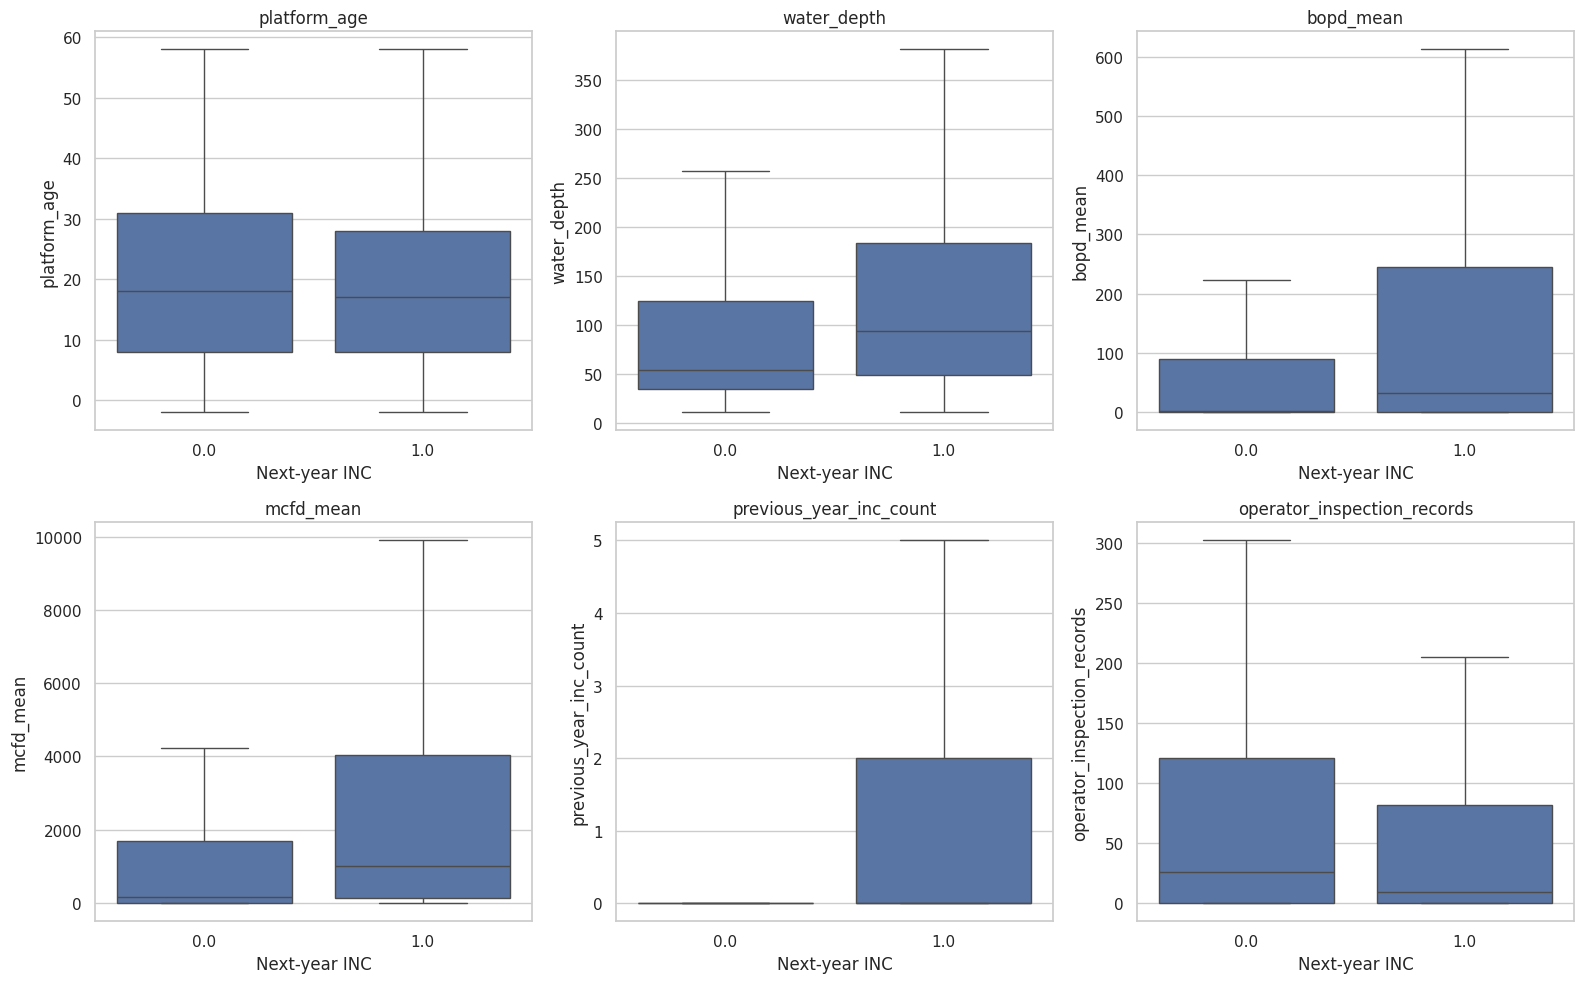

In [13]:
boxplot_features = [
    "platform_age",
    "water_depth",
    "bopd_mean",
    "mcfd_mean",
    "previous_year_inc_count",
    "operator_inspection_records",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

plot_sample = df_eda.sample(
    min(40_000, len(df_eda)),
    random_state=42,
)

for axis, column in zip(axes, boxplot_features):
    temporary = plot_sample[[TARGET, column]].copy()

    lower = temporary[column].quantile(0.01)
    upper = temporary[column].quantile(0.99)
    temporary[column] = temporary[column].clip(lower, upper)

    sns.boxplot(
        data=temporary,
        x=TARGET,
        y=column,
        showfliers=False,
        ax=axis,
    )

    axis.set_title(column)
    axis.set_xlabel("Next-year INC")
    axis.set_ylabel(column)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "04_target_boxplots.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [14]:
categorical_features = [
    "structure_type",
    "major_structure_flag",
    "district_code",
    "heliport_flag",
    "region_code",
    "attended_8hr_flag",
    "manned_24hr_flag",
]

categorical_results = []

for column in categorical_features:
    if column not in df_eda.columns:
        continue

    result = (
        df_eda.groupby(column, dropna=False)
        .agg(
            observations=(TARGET, "size"),
            positive_cases=(TARGET, "sum"),
            positive_rate=(TARGET, "mean"),
        )
        .reset_index()
    )

    # Avoid interpreting extremely small groups
    result = result[result["observations"] >= 100]
    result["variable"] = column
    categorical_results.append(result)

categorical_summary = pd.concat(
    categorical_results,
    ignore_index=True,
)

categorical_summary.to_csv(
    DATA_DIR / "eda_categorical_risk.csv",
    index=False,
)

display(
    categorical_summary.sort_values(
        ["variable", "positive_rate"],
        ascending=[True, False],
    )
)

,structure_type,observations,positive_cases,positive_rate,variable,major_structure_flag,district_code,heliport_flag,region_code,attended_8hr_flag,manned_24hr_flag
23,NaN,10370,3518.0,0.339248,attended_8hr_flag,NaN,NaN,NaN,NaN,Y,NaN
22,NaN,76345,18128.0,0.237448,attended_8hr_flag,NaN,NaN,NaN,NaN,N,NaN
24,NaN,1757,150.0,0.085373,attended_8hr_flag,NaN,NaN,NaN,NaN,NaN,NaN
14,NaN,9822,3144.0,0.320098,district_code,NaN,4.0,NaN,NaN,NaN,NaN
13,NaN,18677,5314.0,0.284521,district_code,NaN,3.0,NaN,NaN,NaN,NaN
15,NaN,18265,4499.0,0.246318,district_code,NaN,5.0,NaN,NaN,NaN,NaN
12,NaN,21936,5139.0,0.234272,district_code,NaN,2.0,NaN,NaN,NaN,NaN
11,NaN,18990,3700.0,0.194839,district_code,NaN,1.0,NaN,NaN,NaN,NaN
16,NaN,782,0.0,0.000000,district_code,NaN,NaN,NaN,NaN,NaN,NaN
18,NaN,49930,14634.0,0.293090,heliport_flag,NaN,NaN,Y,NaN,NaN,NaN


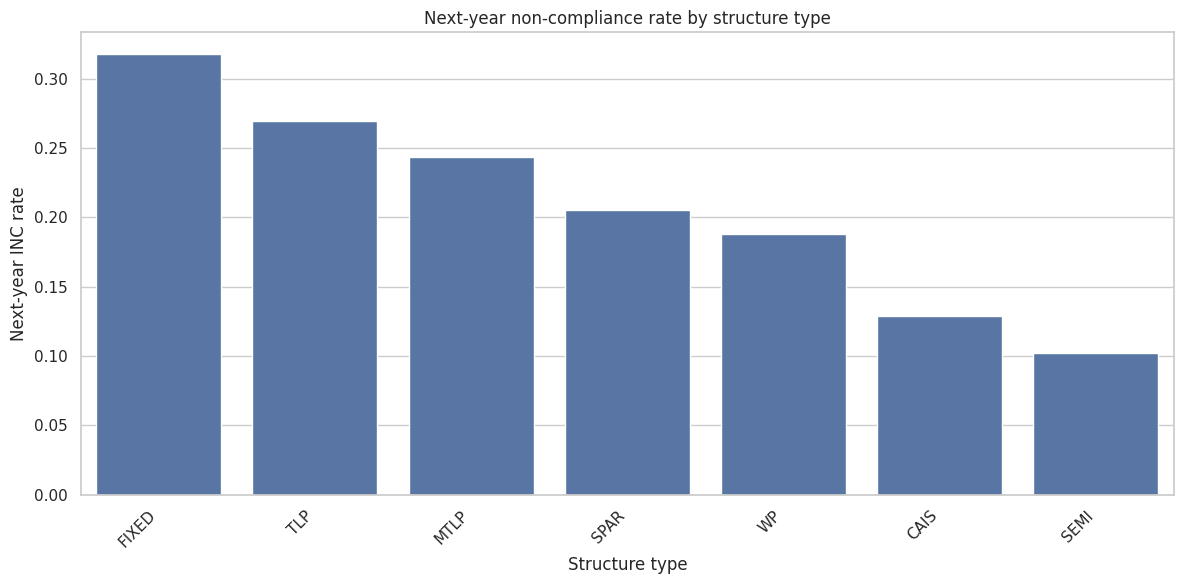

In [15]:
structure_risk = (
    categorical_summary[
        categorical_summary["variable"] == "structure_type"
    ]
    .sort_values("positive_rate", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=structure_risk,
    x="structure_type",
    y="positive_rate",
)

plt.ylabel("Next-year INC rate")
plt.xlabel("Structure type")
plt.title("Next-year non-compliance rate by structure type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_structure_type_risk.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

,target_correlation
inc_count_previous_3_observations,0.263268
enforcement_code_count,0.262638
any_inc,0.243562
inc_count,0.222459
previous_year_inc_count,0.208069
latitude,-0.149459
producing_wells_max,0.145387
producing_wells_mean,0.139927
year,-0.139614
years_until_removal,0.137817


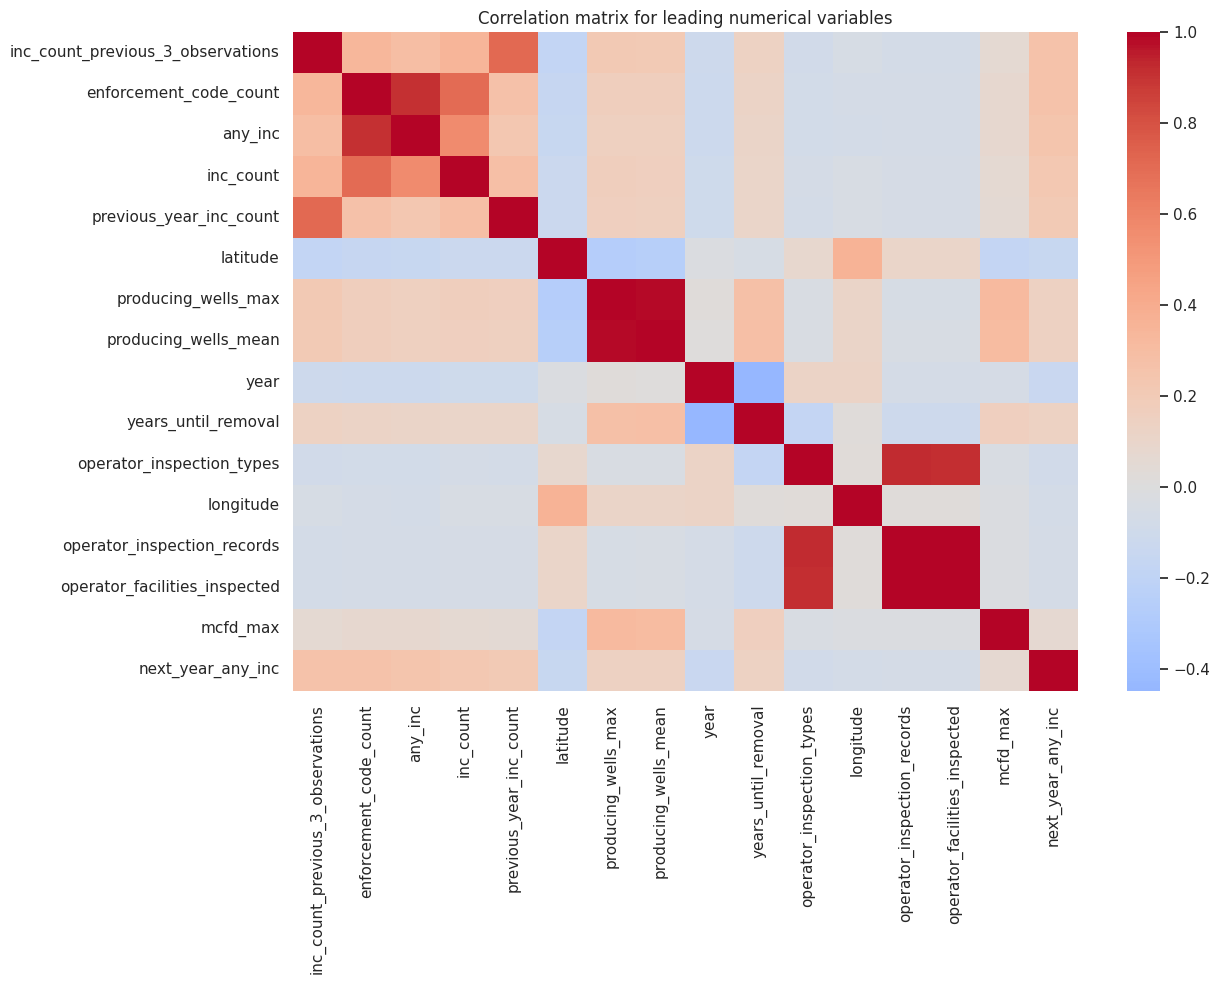

In [16]:
excluded_from_predictors = {
    "next_year_any_inc",
    "next_year_inc_count",
    "platform_id",
    "operator_name",
    "structure_name",
}

numeric_columns = (
    df_eda.select_dtypes(include=np.number)
    .columns
    .difference(list(excluded_from_predictors))
    .tolist()
)

correlations = (
    df_eda[numeric_columns + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

display(correlations.to_frame("target_correlation").head(25))

correlations.to_csv(
    DATA_DIR / "eda_target_correlations.csv",
    header=["target_correlation"],
)

top_correlation_features = correlations.head(15).index.tolist()

correlation_matrix = (
    df_eda[top_correlation_features + [TARGET]]
    .corr(numeric_only=True)
)

plt.figure(figsize=(13, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    square=False,
)
plt.title("Correlation matrix for leading numerical variables")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "06_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

,count,mean,std,min,25%,50%,75%,max
observed_years,5478.0,16.150,10.153,1.0,7.00,15.00,23.00,35.0
first_year,5478.0,1993.614,5.832,1990.0,1990.00,1990.00,1996.00,2023.0
last_year,5478.0,2008.824,10.209,1990.0,2001.00,2009.00,2017.00,2024.0
positive_years,5478.0,3.979,4.409,0.0,1.00,2.00,6.00,25.0
positive_rate,5478.0,0.230,0.209,0.0,0.05,0.19,0.36,1.0


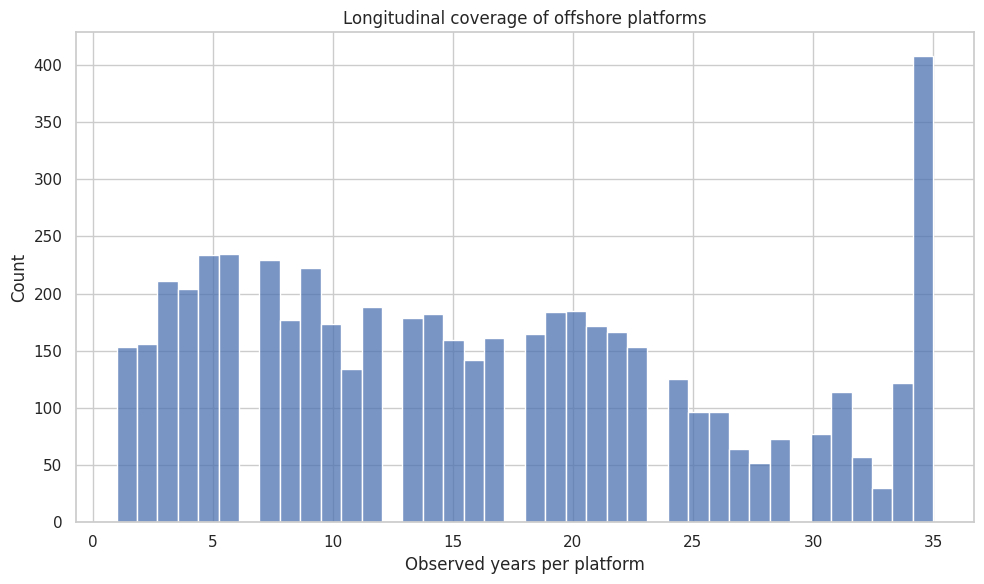

In [17]:
platform_summary = (
    df_eda.groupby("platform_id")
    .agg(
        observed_years=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        positive_years=(TARGET, "sum"),
        positive_rate=(TARGET, "mean"),
    )
    .reset_index()
)

display(platform_summary.describe().T.round(3))

plt.figure(figsize=(10, 6))
sns.histplot(
    platform_summary["observed_years"],
    bins=40,
)
plt.xlabel("Observed years per platform")
plt.title("Longitudinal coverage of offshore platforms")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "07_platform_observation_length.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [18]:
# Recommended initial study period
analysis_df = df_eda[
    (df_eda["year"] >= 2000)
    & (df_eda["year"] <= 2024)
].copy()

train = analysis_df[
    analysis_df["year"] <= 2017
].copy()

validation = analysis_df[
    analysis_df["year"].between(2018, 2021)
].copy()

test = analysis_df[
    analysis_df["year"].between(2022, 2024)
].copy()

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "years": ["2000–2017", "2018–2021", "2022–2024"],
    "rows": [len(train), len(validation), len(test)],
    "platforms": [
        train["platform_id"].nunique(),
        validation["platform_id"].nunique(),
        test["platform_id"].nunique(),
    ],
    "positive_rate": [
        train[TARGET].mean(),
        validation[TARGET].mean(),
        test[TARGET].mean(),
    ],
})

display(split_summary.round(4))

train.to_csv(
    DATA_DIR / "train_temporal.csv.gz",
    index=False,
    compression="gzip",
)

validation.to_csv(
    DATA_DIR / "validation_temporal.csv.gz",
    index=False,
    compression="gzip",
)

test.to_csv(
    DATA_DIR / "test_temporal.csv.gz",
    index=False,
    compression="gzip",
)

,split,years,rows,platforms,positive_rate
0,Train,2000–2017,47276,4260,0.2453
1,Validation,2018–2021,4753,1362,0.0427
2,Test,2022–2024,2505,915,0.0399


In [19]:
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

EDA_ZIP = Path("/kaggle/working/bsee_eda_outputs.zip")

files_to_package = (
    list(FIGURE_DIR.glob("*.png"))
    + list(DATA_DIR.glob("eda_*.csv"))
    + [
        DATA_DIR / "train_temporal.csv.gz",
        DATA_DIR / "validation_temporal.csv.gz",
        DATA_DIR / "test_temporal.csv.gz",
    ]
)

with ZipFile(
    EDA_ZIP,
    mode="w",
    compression=ZIP_DEFLATED,
    compresslevel=9,
) as archive:
    for file_path in files_to_package:
        if file_path.exists():
            archive.write(file_path, arcname=file_path.name)

with ZipFile(EDA_ZIP, "r") as archive:
    corrupted_file = archive.testzip()
    if corrupted_file:
        raise RuntimeError(f"Corrupted archive member: {corrupted_file}")

print("EDA archive:", EDA_ZIP)
print(f"Size: {EDA_ZIP.stat().st_size / (1024**2):.2f} MB")

display(FileLink(str(EDA_ZIP)))

EDA archive: /kaggle/working/bsee_eda_outputs.zip
Size: 4.27 MB


/kaggle/working/bsee_eda_outputs.zip

In [20]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/kaggle/working/bsee_processed")
TARGET = "next_year_any_inc"

df = pd.read_csv(
    DATA_DIR / "bsee_platform_year_model.csv.gz",
    low_memory=False,
)

# Use a more internally consistent reporting period.
analysis_df = df[
    df["year"].between(2014, 2024)
].copy()

# Temporal split
train = analysis_df[
    df.loc[analysis_df.index, "year"].between(2014, 2019)
].copy()

validation = analysis_df[
    df.loc[analysis_df.index, "year"].between(2020, 2021)
].copy()

test = analysis_df[
    df.loc[analysis_df.index, "year"].between(2022, 2024)
].copy()

def describe_split(name, frame):
    return {
        "split": name,
        "year_start": int(frame["year"].min()),
        "year_end": int(frame["year"].max()),
        "rows": len(frame),
        "platforms": frame["platform_id"].nunique(),
        "positive_cases": int(frame[TARGET].sum()),
        "positive_rate": frame[TARGET].mean(),
    }

split_summary = pd.DataFrame([
    describe_split("Train", train),
    describe_split("Validation", validation),
    describe_split("Test", test),
])

display(split_summary.round(4))

train.to_csv(
    DATA_DIR / "train_2014_2019.csv.gz",
    index=False,
    compression="gzip",
)

validation.to_csv(
    DATA_DIR / "validation_2020_2021.csv.gz",
    index=False,
    compression="gzip",
)

test.to_csv(
    DATA_DIR / "test_2022_2024.csv.gz",
    index=False,
    compression="gzip",
)

,split,year_start,year_end,rows,platforms,positive_cases,positive_rate
0,Train,2014,2019,8856,1752,561,0.0633
1,Validation,2020,2021,2140,1157,92,0.0430
2,Test,2022,2024,2505,915,100,0.0399


In [3]:
"""Leakage audit and model preprocessing for the BSEE platform-year study.

Run in Kaggle after creating ``bsee_platform_year_model.csv.gz``:

    %run /kaggle/working/kaggle_feature_audit_preprocessing.py

The script creates two experimental datasets:

1. early_warning: excludes all current-year non-compliance/enforcement outcomes.
2. enhanced_supervision: includes current-year outcomes to predict next-year risk.

Every learned preprocessing parameter is fitted on 2014-2019 only. Validation
(2020-2021) and test (2022-2024) remain strictly out of fit operations.
"""

from __future__ import annotations

import json
import logging
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.utils.class_weight import compute_class_weight


LOG = logging.getLogger("bsee-feature-preprocessing")
TARGET = "next_year_any_inc"
RANDOM_STATE = 42

# These columns identify an observation or are retained for evaluation/grouping.
# They must never be passed to an ordinary predictive model as numeric values.
IDENTIFIER_COLUMNS = [
    "platform_id",
    "operator_id",
    "operator_name",
    "lease_number",
    "structure_name",
    "block_number",
]

# Future labels. These are prohibited predictors in every experiment.
TARGET_COLUMNS = [
    "next_year_any_inc",
    "next_year_inc_count",
]

# Retrospectively known or unsuitable raw fields.
EXCLUDED_COLUMNS = [
    "install_date",          # represented safely by platform_age
    "removal_date",          # may reveal future platform retirement
    "years_until_removal",   # directly uses a future removal date
    "operator_id_inc",       # source-specific identifier if present
]

# Current-year compliance/enforcement outcomes. Excluded from early warning,
# included in enhanced supervision because they are known by the end of year t.
CURRENT_YEAR_COMPLIANCE_COLUMNS = [
    "inc_count",
    "enforcement_code_count",
    "any_inc",
    "operator_warning_incs",
    "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

# Approved categorical predictors with manageable and meaningful cardinality.
CATEGORICAL_FEATURES = [
    "area_code",
    "region_code",
    "structure_type",
    "major_structure_flag",
    "district_code",
    "heliport_flag",
    "attended_8hr_flag",
    "manned_24hr_flag",
]

# Approved predictors available by the end of feature year t.
BASE_NUMERIC_FEATURES = [
    "active_months",
    "producing_wells_mean",
    "producing_wells_max",
    "bopd_mean",
    "bopd_max",
    "mcfd_mean",
    "mcfd_max",
    "boepd_mean",
    "bwpd_mean",
    "water_depth",
    "latitude",
    "longitude",
    "platform_age",
    "operator_facilities_inspected",
    "operator_inspection_records",
    "operator_inspection_types",
    "investigated_accident_count",
    "accident_type_count",
    "previous_year_inc_count",
    "inc_count_previous_3_observations",
    "previous_year_accident_count",
    "production_change_bopd",
    "production_change_mcfd",
]


class QuantileClipper(BaseEstimator, TransformerMixin):
    """Winsorize numerical columns using quantiles learned from training only."""

    def __init__(self, lower: float = 0.01, upper: float = 0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        array = np.asarray(X, dtype=float)
        self.n_features_in_ = array.shape[1]
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.lower_bounds_ = np.nanquantile(array, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(array, self.upper, axis=0)
        return self

    def transform(self, X):
        array = np.asarray(X, dtype=float)
        return np.clip(array, self.lower_bounds_, self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        """Clipping changes values only, so feature names pass through unchanged."""
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_.copy()
        return np.asarray(
            [f"x{i}" for i in range(self.n_features_in_)], dtype=object
        )


def locate_model_file() -> Path:
    """Find compressed or uncompressed modelling data in Kaggle."""
    candidates = [
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/bsee-preprocessed-dataset/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/input/bsee-preprocessed-dataset/bsee_platform_year_model.csv"),
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate

    matches = list(Path("/kaggle/input").rglob("bsee_platform_year_model.csv.gz"))
    matches += list(Path("/kaggle/input").rglob("bsee_platform_year_model.csv"))
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise FileNotFoundError(
            "Could not find bsee_platform_year_model.csv(.gz) in /kaggle/working "
            "or /kaggle/input. Run the preprocessing pipeline first."
        )
    raise RuntimeError(f"Multiple modelling files found; keep one attached: {matches}")


def clean_model_frame(frame: pd.DataFrame) -> pd.DataFrame:
    """Apply deterministic cleaning that does not learn from future periods."""
    result = frame.copy()
    result[TARGET] = pd.to_numeric(result[TARGET], errors="coerce")
    result["year"] = pd.to_numeric(result["year"], errors="coerce")

    # Restrict the primary analysis to the stable reporting period.
    result = result[result["year"].between(2014, 2024)].copy()
    result = result[result[TARGET].isin([0, 1])].copy()
    result["year"] = result["year"].astype(int)
    result[TARGET] = result[TARGET].astype("int8")

    # pct_change can produce infinities when the previous value is zero.
    result.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Use ordinary object strings plus np.nan for broad sklearn compatibility.
    for column in CATEGORICAL_FEATURES:
        if column in result.columns:
            result[column] = result[column].astype("string").astype(object)
            result[column] = result[column].where(result[column].notna(), np.nan)

    if result.duplicated(["platform_id", "year"]).any():
        raise ValueError("Duplicate platform-year observations detected")
    return result


def temporal_split(frame: pd.DataFrame):
    train = frame[frame["year"].between(2014, 2019)].copy()
    validation = frame[frame["year"].between(2020, 2021)].copy()
    test = frame[frame["year"].between(2022, 2024)].copy()

    if min(len(train), len(validation), len(test)) == 0:
        raise ValueError("At least one temporal split is empty")
    return train, validation, test


def available(columns: list[str], frame: pd.DataFrame) -> list[str]:
    """Keep declared columns that exist and report schema differences."""
    present = [column for column in columns if column in frame.columns]
    missing = sorted(set(columns) - set(present))
    if missing:
        LOG.warning("Declared columns absent from dataset: %s", missing)
    return present


def feature_sets(frame: pd.DataFrame) -> dict[str, dict[str, list[str]]]:
    categorical = available(CATEGORICAL_FEATURES, frame)
    base_numeric = available(BASE_NUMERIC_FEATURES, frame)
    compliance = available(CURRENT_YEAR_COMPLIANCE_COLUMNS, frame)

    return {
        "early_warning": {
            "numeric": base_numeric,
            "categorical": categorical,
        },
        "enhanced_supervision": {
            "numeric": base_numeric + compliance,
            "categorical": categorical,
        },
    }


def audit_features(frame: pd.DataFrame, sets: dict) -> pd.DataFrame:
    all_columns = set(frame.columns)
    early = set(sets["early_warning"]["numeric"] + sets["early_warning"]["categorical"])
    enhanced = set(
        sets["enhanced_supervision"]["numeric"]
        + sets["enhanced_supervision"]["categorical"]
    )

    rows = []
    for column in sorted(all_columns):
        if column in TARGET_COLUMNS:
            role = "target_prohibited"
        elif column in IDENTIFIER_COLUMNS:
            role = "identifier_grouping_only"
        elif column in EXCLUDED_COLUMNS:
            role = "excluded_future_or_redundant"
        elif column in CURRENT_YEAR_COMPLIANCE_COLUMNS:
            role = "enhanced_only_current_compliance"
        elif column == "year":
            role = "split_and_drift_analysis_only"
        elif column in early:
            role = "approved_both_models"
        elif column in enhanced:
            role = "approved_enhanced_model"
        else:
            role = "excluded_unapproved"

        rows.append(
            {
                "feature": column,
                "role": role,
                "dtype": str(frame[column].dtype),
                "missing_percent": round(float(frame[column].isna().mean() * 100), 3),
                "unique_values": int(frame[column].nunique(dropna=True)),
            }
        )
    return pd.DataFrame(rows)


def build_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    numeric_pipeline = Pipeline(
        steps=[
            ("clip", QuantileClipper(lower=0.01, upper=0.99)),
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", RobustScaler()),
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            ("impute", SimpleImputer(strategy="most_frequent")),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=10,
                    sparse_output=True,
                ),
            ),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric),
            ("categorical", categorical_pipeline, categorical),
        ],
        remainder="drop",
        sparse_threshold=0.3,
        verbose_feature_names_out=False,
    )


def save_split_metadata(frame: pd.DataFrame, path: Path) -> None:
    columns = [
        column
        for column in ["platform_id", "operator_id", "year", TARGET]
        if column in frame.columns
    ]
    frame[columns].to_csv(path, index=False)


def process_experiment(
    name: str,
    specification: dict[str, list[str]],
    train: pd.DataFrame,
    validation: pd.DataFrame,
    test: pd.DataFrame,
    output_root: Path,
) -> dict:
    experiment_dir = output_root / name
    experiment_dir.mkdir(parents=True, exist_ok=True)

    numeric = specification["numeric"]
    categorical = specification["categorical"]
    features = numeric + categorical

    X_train_raw = train[features]
    X_validation_raw = validation[features]
    X_test_raw = test[features]
    y_train = train[TARGET].to_numpy(dtype=np.int8)
    y_validation = validation[TARGET].to_numpy(dtype=np.int8)
    y_test = test[TARGET].to_numpy(dtype=np.int8)

    preprocessor = build_preprocessor(numeric, categorical)
    LOG.info("Fitting %s preprocessor on training data only", name)
    X_train = preprocessor.fit_transform(X_train_raw, y_train)
    X_validation = preprocessor.transform(X_validation_raw)
    X_test = preprocessor.transform(X_test_raw)

    # Use CSR consistently for efficient storage and downstream classifiers.
    X_train = sparse.csr_matrix(X_train)
    X_validation = sparse.csr_matrix(X_validation)
    X_test = sparse.csr_matrix(X_test)

    feature_names = preprocessor.get_feature_names_out().tolist()
    if X_train.shape[1] != len(feature_names):
        raise RuntimeError("Feature-name count does not match transformed matrix")

    sparse.save_npz(experiment_dir / "X_train.npz", X_train)
    sparse.save_npz(experiment_dir / "X_validation.npz", X_validation)
    sparse.save_npz(experiment_dir / "X_test.npz", X_test)
    np.save(experiment_dir / "y_train.npy", y_train)
    np.save(experiment_dir / "y_validation.npy", y_validation)
    np.save(experiment_dir / "y_test.npy", y_test)
    joblib.dump(preprocessor, experiment_dir / "preprocessor.joblib")

    (experiment_dir / "feature_names.json").write_text(
        json.dumps(feature_names, indent=2), encoding="utf-8"
    )
    (experiment_dir / "input_feature_specification.json").write_text(
        json.dumps(specification, indent=2), encoding="utf-8"
    )
    save_split_metadata(train, experiment_dir / "train_metadata.csv")
    save_split_metadata(validation, experiment_dir / "validation_metadata.csv")
    save_split_metadata(test, experiment_dir / "test_metadata.csv")

    classes = np.array([0, 1])
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
    class_weights = {str(int(cls)): float(weight) for cls, weight in zip(classes, weights)}
    scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

    summary = {
        "experiment": name,
        "input_numeric_features": len(numeric),
        "input_categorical_features": len(categorical),
        "transformed_features": int(X_train.shape[1]),
        "train_shape": list(X_train.shape),
        "validation_shape": list(X_validation.shape),
        "test_shape": list(X_test.shape),
        "train_positive_rate": float(y_train.mean()),
        "validation_positive_rate": float(y_validation.mean()),
        "test_positive_rate": float(y_test.mean()),
        "class_weights": class_weights,
        "scale_pos_weight": scale_pos_weight,
    }
    (experiment_dir / "preprocessing_summary.json").write_text(
        json.dumps(summary, indent=2), encoding="utf-8"
    )
    return summary


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
    model_path = locate_model_file()
    output_root = Path("/kaggle/working/bsee_model_inputs")
    output_root.mkdir(parents=True, exist_ok=True)

    LOG.info("Reading %s", model_path)
    frame = pd.read_csv(model_path, low_memory=False)
    frame = clean_model_frame(frame)
    train, validation, test = temporal_split(frame)
    sets = feature_sets(frame)

    audit = audit_features(frame, sets)
    audit.to_csv(output_root / "feature_leakage_audit.csv", index=False)
    (output_root / "approved_feature_sets.json").write_text(
        json.dumps(sets, indent=2), encoding="utf-8"
    )

    split_summary = pd.DataFrame(
        [
            {
                "split": name,
                "year_start": int(part["year"].min()),
                "year_end": int(part["year"].max()),
                "rows": int(len(part)),
                "platforms": int(part["platform_id"].nunique()),
                "positive_cases": int(part[TARGET].sum()),
                "positive_rate": float(part[TARGET].mean()),
            }
            for name, part in [
                ("train", train),
                ("validation", validation),
                ("test", test),
            ]
        ]
    )
    split_summary.to_csv(output_root / "temporal_split_summary.csv", index=False)

    summaries = []
    for name, specification in sets.items():
        summaries.append(
            process_experiment(
                name,
                specification,
                train,
                validation,
                test,
                output_root,
            )
        )

    (output_root / "all_preprocessing_summaries.json").write_text(
        json.dumps(summaries, indent=2), encoding="utf-8"
    )

    print("\nFeature leakage audit")
    print(audit.groupby("role").size().to_string())
    print("\nTemporal splits")
    print(split_summary.to_string(index=False))
    print("\nExperiment summaries")
    print(json.dumps(summaries, indent=2))
    print(f"\nOutputs written to: {output_root}")


if __name__ == "__main__":
    main()


INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
INFO Fitting early_warning preprocessor on training data only
INFO Fitting enhanced_supervision preprocessor on training data only



Feature leakage audit
role
approved_both_models                31
enhanced_only_current_compliance     6
excluded_future_or_redundant         3
identifier_grouping_only             6
split_and_drift_analysis_only        1
target_prohibited                    2

Temporal splits
     split  year_start  year_end  rows  platforms  positive_cases  positive_rate
     train        2014      2019  8856       1752             561       0.063347
validation        2020      2021  2140       1157              92       0.042991
      test        2022      2024  2505        915             100       0.039920

Experiment summaries
[
  {
    "experiment": "early_warning",
    "input_numeric_features": 23,
    "input_categorical_features": 8,
    "transformed_features": 90,
    "train_shape": [
      8856,
      90
    ],
    "validation_shape": [
      2140,
      90
    ],
    "test_shape": [
      2505,
      90
    ],
    "train_positive_rate": 0.06334688346883469,
    "validation_positive_rate": 

In [4]:
from pathlib import Path
import shutil

INPUT_DIR = Path("/kaggle/working/bsee_model_inputs")
ZIP_BASE = Path("/kaggle/working/bsee_model_inputs")

if not INPUT_DIR.exists():
    raise FileNotFoundError(
        f"Model-input directory not found: {INPUT_DIR}. "
        "Run the preprocessing pipeline first."
    )

zip_path = Path(
    shutil.make_archive(
        base_name=str(ZIP_BASE),
        format="zip",
        root_dir=str(INPUT_DIR.parent),
        base_dir=INPUT_DIR.name,
    )
)

size_mb = zip_path.stat().st_size / (1024**2)

print("ZIP created successfully")
print("File:", zip_path)
print(f"Size: {size_mb:.2f} MB")

ZIP created successfully
File: /kaggle/working/bsee_model_inputs.zip
Size: 1.63 MB


In [6]:
"""Advanced BSEE platform-risk modelling on Kaggle.

Models: LightGBM, CatBoost, TabNet, and a PyTorch FT-style Transformer.
Protocol: tune on 2020-2021 validation PR-AUC, select the validation F1
threshold, refit five seeds on the unchanged training set, and report the
untouched 2022-2024 test set.  No test observation is used for selection.
"""

from __future__ import annotations

import gc
import json
import logging
import math
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("bsee_advanced_models")

# --------------------------- user controls ---------------------------
SEEDS = [11, 22, 33, 44, 55]
TUNING_SEED = 2026
N_TRIALS = 12                 # Increase to 25-50 for the final paper run.
NEURAL_EPOCHS = 120
NEURAL_PATIENCE = 15
EXPERIMENTS = ["early_warning", "enhanced_supervision"]
MODELS = ["lightgbm", "catboost", "tabnet", "ft_transformer"]
INPUT_ROOT = Path("/kaggle/working/bsee_model_inputs")
OUTPUT_ROOT = Path("/kaggle/working/bsee_advanced_results")


def ensure_packages() -> None:
    """Install only packages missing from the Kaggle image."""
    required = {
        "lightgbm": "lightgbm",
        "catboost": "catboost",
        "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *missing]
        )


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402
from torch import nn  # noqa: E402
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_input_root() -> Path:
    if (INPUT_ROOT / "early_warning" / "X_train.npz").exists():
        return INPUT_ROOT

    # The files may be nested differently after a Kaggle dataset upload or
    # archive extraction, so search both writable output and attached inputs.
    matches = []
    for search_root in [Path("/kaggle/working"), Path("/kaggle/input")]:
        if search_root.exists():
            matches.extend(
                path
                for path in search_root.rglob("X_train.npz")
                if path.parent.name.lower() == "early_warning"
            )

    # If only the generated ZIP remains, recover it automatically.
    if not matches:
        zip_candidates = [Path("/kaggle/working/bsee_model_inputs.zip")]
        zip_candidates.extend(Path("/kaggle/input").rglob("bsee_model_inputs.zip"))
        for zip_path in zip_candidates:
            if zip_path.exists():
                extraction_root = Path("/kaggle/working/bsee_model_inputs_extracted")
                extraction_root.mkdir(parents=True, exist_ok=True)
                LOG.info("Extracting model inputs from %s", zip_path)
                with zipfile.ZipFile(zip_path) as archive:
                    archive.extractall(extraction_root)
                matches.extend(
                    path
                    for path in extraction_root.rglob("X_train.npz")
                    if path.parent.name.lower() == "early_warning"
                )
                if matches:
                    break

    if not matches:
        raise FileNotFoundError(
            "Could not locate bsee_model_inputs. Run the feature-audit "
            "preprocessing notebook first or attach its output as a dataset."
        )
    return matches[0].parent.parent


def load_experiment(root: Path, name: str) -> dict:
    folder = root / name
    data = {
        "X_train": sparse.load_npz(folder / "X_train.npz").astype(np.float32),
        "X_val": sparse.load_npz(folder / "X_validation.npz").astype(np.float32),
        "X_test": sparse.load_npz(folder / "X_test.npz").astype(np.float32),
        "y_train": np.load(folder / "y_train.npy").astype(np.int64),
        "y_val": np.load(folder / "y_validation.npy").astype(np.int64),
        "y_test": np.load(folder / "y_test.npy").astype(np.int64),
        "meta_val": pd.read_csv(folder / "validation_metadata.csv"),
        "meta_test": pd.read_csv(folder / "test_metadata.csv"),
    }
    data["scale_pos_weight"] = float(
        (data["y_train"] == 0).sum() / (data["y_train"] == 1).sum()
    )
    return data


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    """Select threshold on validation only using exact prediction breakpoints."""
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    index = int(np.argmax(scores))
    return float(candidates[index]), float(scores[index])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {
        "pr_auc": safe_pr_auc(y, probability),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


# ------------------------ classical advanced models ------------------------
def suggest_lgbm(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 3000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 180),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def fit_lgbm(params: dict, data: dict, seed: int):
    model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=data["scale_pos_weight"], verbosity=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model


def suggest_catboost(trial: optuna.Trial) -> dict:
    return {
        "iterations": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }


def fit_catboost(params: dict, data: dict, seed: int):
    model = CatBoostClassifier(
        loss_function="Logloss", eval_metric="PRAUC", random_seed=seed,
        auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
        thread_count=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=(data["X_val"], data["y_val"]),
        early_stopping_rounds=100, verbose=False,
    )
    return model


# ------------------------------ TabNet ------------------------------
def suggest_tabnet(trial: optuna.Trial) -> dict:
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width,
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "lr": trial.suggest_float("lr", 5e-4, 3e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


def fit_tabnet(params: dict, data: dict, seed: int):
    Xtr = data["X_train"].toarray().astype(np.float32)
    Xva = data["X_val"].toarray().astype(np.float32)
    p = dict(params)
    lr, batch_size = p.pop("lr"), p.pop("batch_size")
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": lr, "weight_decay": 1e-5},
        scheduler_fn=torch.optim.lr_scheduler.ReduceLROnPlateau,
        scheduler_params={"mode": "max", "factor": 0.5, "patience": 5},
        verbose=0, device_name="auto", **p,
    )
    # Weighted loss without resampling.
    class_weights = {0: 1.0, 1: data["scale_pos_weight"]}
    model.fit(
        Xtr, data["y_train"], eval_set=[(Xva, data["y_val"])],
        eval_name=["validation"], eval_metric=["auc"],
        weights=class_weights, max_epochs=NEURAL_EPOCHS,
        patience=NEURAL_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0,
        drop_last=False,
    )
    return model


# -------------------------- FT-style Transformer --------------------------
class FTTransformer(nn.Module):
    """Tokenizes every transformed scalar feature and applies self-attention."""

    def __init__(self, n_features: int, d_token: int, n_heads: int,
                 n_layers: int, dropout: float, ff_factor: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.xavier_uniform_(self.weight)
        nn.init.zeros_(self.bias)
        layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * ff_factor,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, n_layers)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(self.norm(encoded[:, 0])).squeeze(1)


def suggest_ft(trial: optuna.Trial) -> dict:
    d_token = trial.suggest_categorical("d_token", [24, 32, 48, 64])
    valid_heads = [h for h in [2, 4, 8] if d_token % h == 0]
    return {
        "d_token": d_token,
        "n_heads": trial.suggest_categorical("n_heads", valid_heads),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.05, 0.35),
        "ff_factor": trial.suggest_categorical("ff_factor", [2, 3, 4]),
        "lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


class TorchWrapper:
    def __init__(self, model: nn.Module, device: torch.device, batch_size: int):
        self.model, self.device, self.batch_size = model, device, batch_size

    def predict_proba(self, X):
        array = X.toarray().astype(np.float32) if sparse.issparse(X) else np.asarray(X, np.float32)
        loader = DataLoader(TensorDataset(torch.from_numpy(array)), batch_size=self.batch_size)
        output = []
        self.model.eval()
        with torch.no_grad():
            for (xb,) in loader:
                output.append(torch.sigmoid(self.model(xb.to(self.device))).cpu().numpy())
        p = np.concatenate(output)
        return np.column_stack([1 - p, p])


def fit_ft(params: dict, data: dict, seed: int):
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    Xtr = torch.from_numpy(data["X_train"].toarray().astype(np.float32))
    ytr = torch.from_numpy(data["y_train"].astype(np.float32))
    Xva = data["X_val"]
    p = dict(params)
    lr, wd, batch_size = p.pop("lr"), p.pop("weight_decay"), p.pop("batch_size")
    model = FTTransformer(Xtr.shape[1], **p).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(data["scale_pos_weight"], device=device)
    )
    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_state, bad_epochs = -np.inf, None, 0
    wrapper = TorchWrapper(model, device, batch_size)
    for _epoch in range(NEURAL_EPOCHS):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb.to(device)), yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        score = safe_pr_auc(data["y_val"], wrapper.predict_proba(Xva)[:, 1])
        if score > best_score + 1e-5:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= NEURAL_PATIENCE:
                break
    model.load_state_dict(best_state)
    return wrapper


SUGGESTERS = {
    "lightgbm": suggest_lgbm, "catboost": suggest_catboost,
    "tabnet": suggest_tabnet, "ft_transformer": suggest_ft,
}
FITTERS = {
    "lightgbm": fit_lgbm, "catboost": fit_catboost,
    "tabnet": fit_tabnet, "ft_transformer": fit_ft,
}


def positive_probability(model, model_name: str, X) -> np.ndarray:
    if model_name == "tabnet":
        X = X.toarray().astype(np.float32)
    return np.asarray(model.predict_proba(X)[:, 1], dtype=float)


def tune_model(model_name: str, data: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    def objective(trial: optuna.Trial) -> float:
        params = SUGGESTERS[model_name](trial)
        try:
            model = FITTERS[model_name](params, data, TUNING_SEED)
            probability = positive_probability(model, model_name, data["X_val"])
            score = safe_pr_auc(data["y_val"], probability)
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            return score
        except Exception as error:
            LOG.exception("Trial failed for %s/%s: %s", experiment, model_name, error)
            return 0.0

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    trials = study.trials_dataframe()
    return SUGGESTERS[model_name](optuna.trial.FixedTrial(study.best_params)), trials


def save_model(model, model_name: str, path: Path) -> None:
    if model_name == "lightgbm":
        model.booster_.save_model(str(path.with_suffix(".txt")))
    elif model_name == "catboost":
        model.save_model(str(path.with_suffix(".cbm")))
    elif model_name == "tabnet":
        model.save_model(str(path))
    else:
        torch.save(model.model.state_dict(), path.with_suffix(".pt"))


def run_model(experiment: str, model_name: str, data: dict, output: Path) -> list[dict]:
    model_dir = output / experiment / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s / %s (%d trials)", experiment, model_name, N_TRIALS)
    best_params, trials = tune_model(model_name, data, experiment)
    trials.to_csv(model_dir / "optuna_trials.csv", index=False)
    (model_dir / "best_params.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    rows = []
    for seed in SEEDS:
        LOG.info("Final fit %s / %s / seed %d", experiment, model_name, seed)
        started = time.time()
        model = FITTERS[model_name](best_params, data, seed)
        val_p = positive_probability(model, model_name, data["X_val"])
        test_p = positive_probability(model, model_name, data["X_test"])
        threshold, _ = select_f1_threshold(data["y_val"], val_p)

        for split, y, probability in [
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ]:
            row = {
                "experiment": experiment, "model": model_name,
                "seed": seed, "split": split,
                "runtime_seconds": float(time.time() - started),
                **metrics(y, probability, threshold),
            }
            rows.append(row)

        prediction_frame = data["meta_test"].copy()
        prediction_frame["probability"] = test_p
        prediction_frame["threshold"] = threshold
        prediction_frame["prediction"] = (test_p >= threshold).astype(np.int8)
        prediction_frame.to_csv(model_dir / f"test_predictions_seed_{seed}.csv", index=False)
        save_model(model, model_name, model_dir / f"model_seed_{seed}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return rows


def aggregate_results(results: pd.DataFrame) -> pd.DataFrame:
    metric_columns = [
        "pr_auc", "roc_auc", "f1", "precision", "recall",
        "balanced_accuracy", "brier_score", "threshold", "runtime_seconds",
    ]
    grouped = results.groupby(["experiment", "model", "split"])[metric_columns]
    mean = grouped.mean().add_suffix("_mean")
    std = grouped.std(ddof=1).add_suffix("_std")
    return mean.join(std).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    input_root = locate_input_root()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Model inputs: %s", input_root)
    LOG.info("Results: %s", OUTPUT_ROOT)

    all_rows = []
    for experiment in EXPERIMENTS:
        data = load_experiment(input_root, experiment)
        for model_name in MODELS:
            all_rows.extend(run_model(experiment, model_name, data, OUTPUT_ROOT))

    results = pd.DataFrame(all_rows)
    summary = aggregate_results(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "seeds": SEEDS, "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "neural_epochs": NEURAL_EPOCHS, "neural_patience": NEURAL_PATIENCE,
        "selection_metric": "validation_pr_auc",
        "threshold_rule": "maximum validation F1",
        "test_use": "final evaluation only",
    }
    (OUTPUT_ROOT / "run_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_advanced_results",
        "zip",
        root_dir=str(OUTPUT_ROOT.parent),
        base_dir=OUTPUT_ROOT.name,
    )
    print("\nFive-seed results (mean ± standard deviation)")
    print(summary.to_string(index=False))
    print(f"\nOutputs written to: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


FileNotFoundError: Could not locate bsee_model_inputs. Run the feature-audit preprocessing notebook first or attach its output as a dataset.

In [3]:
"""Advanced BSEE platform-risk modelling on Kaggle.

Models: LightGBM, CatBoost, TabNet, and a PyTorch FT-style Transformer.
Protocol: tune on 2020-2021 validation PR-AUC, select the validation F1
threshold, refit five seeds on the unchanged training set, and report the
untouched 2022-2024 test set.  No test observation is used for selection.
"""

from __future__ import annotations

import gc
import json
import logging
import math
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("bsee_advanced_models")

# --------------------------- user controls ---------------------------
SEEDS = [11, 22, 33, 44, 55]
TUNING_SEED = 2026
N_TRIALS = 12                 # Increase to 25-50 for the final paper run.
NEURAL_EPOCHS = 120
NEURAL_PATIENCE = 15
EXPERIMENTS = ["early_warning", "enhanced_supervision"]
MODELS = ["lightgbm", "catboost", "tabnet", "ft_transformer"]
INPUT_ROOT = Path("/kaggle/working/bsee_model_inputs")
OUTPUT_ROOT = Path("/kaggle/working/bsee_advanced_results")


def ensure_packages() -> None:
    """Install only packages missing from the Kaggle image."""
    required = {
        "lightgbm": "lightgbm",
        "catboost": "catboost",
        "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *missing]
        )


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402
from torch import nn  # noqa: E402
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_input_root() -> Path:
    """Find and validate the uploaded bsee_model_inputs directory."""
    direct_candidates = [
        Path("/kaggle/working/bsee_model_inputs"),
        Path("/kaggle/input/bsee-model/bsee_model_inputs"),
        Path("/kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs"),
    ]

    # os.walk is reliable across both standard Kaggle mounts and the newer
    # /kaggle/input/datasets/<owner>/<slug> layout.
    discovered = []
    for search_root in ["/kaggle/input", "/kaggle/working"]:
        if not os.path.isdir(search_root):
            continue
        for directory, subdirectories, _files in os.walk(search_root):
            if os.path.basename(directory).lower() == "bsee_model_inputs":
                discovered.append(Path(directory))
                subdirectories[:] = []

    candidates = direct_candidates + discovered
    seen = set()
    candidates = [p for p in candidates if not (str(p) in seen or seen.add(str(p)))]

    required_relative = [
        Path(experiment) / filename
        for experiment in EXPERIMENTS
        for filename in [
            "X_train.npz", "X_validation.npz", "X_test.npz",
            "y_train.npy", "y_validation.npy", "y_test.npy",
            "validation_metadata.csv", "test_metadata.csv",
        ]
    ]

    diagnostics = []
    for candidate in candidates:
        if not candidate.is_dir():
            continue
        missing = [str(rel) for rel in required_relative if not (candidate / rel).is_file()]
        diagnostics.append((candidate, missing))
        if not missing:
            return candidate

    # Recover an attached/output ZIP if no complete directory was found.
    zip_candidates = [Path("/kaggle/working/bsee_model_inputs.zip")]
    for search_root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if search_root.exists():
            zip_candidates.extend(search_root.rglob("bsee_model_inputs.zip"))
    for zip_path in zip_candidates:
        if not zip_path.is_file():
            continue
        extraction_root = Path("/kaggle/working/bsee_model_inputs_recovered")
        extraction_root.mkdir(parents=True, exist_ok=True)
        LOG.info("Extracting %s", zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(extraction_root)
        for directory, _subdirectories, _files in os.walk(extraction_root):
            candidate = Path(directory)
            if candidate.name.lower() != "bsee_model_inputs":
                continue
            missing = [rel for rel in required_relative if not (candidate / rel).is_file()]
            if not missing:
                return candidate

    message = ["No complete bsee_model_inputs directory was found."]
    for candidate, missing in diagnostics:
        message.append(f"\nFound directory: {candidate}")
        message.append("Missing files:")
        message.extend(f"  - {item}" for item in missing)
    if not diagnostics:
        message.append("No directory named bsee_model_inputs was visible to Python.")
    raise FileNotFoundError("\n".join(message))


def load_experiment(root: Path, name: str) -> dict:
    folder = root / name
    data = {
        "X_train": sparse.load_npz(folder / "X_train.npz").astype(np.float32),
        "X_val": sparse.load_npz(folder / "X_validation.npz").astype(np.float32),
        "X_test": sparse.load_npz(folder / "X_test.npz").astype(np.float32),
        "y_train": np.load(folder / "y_train.npy").astype(np.int64),
        "y_val": np.load(folder / "y_validation.npy").astype(np.int64),
        "y_test": np.load(folder / "y_test.npy").astype(np.int64),
        "meta_val": pd.read_csv(folder / "validation_metadata.csv"),
        "meta_test": pd.read_csv(folder / "test_metadata.csv"),
    }
    data["scale_pos_weight"] = float(
        (data["y_train"] == 0).sum() / (data["y_train"] == 1).sum()
    )
    return data


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    """Select threshold on validation only using exact prediction breakpoints."""
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    index = int(np.argmax(scores))
    return float(candidates[index]), float(scores[index])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {
        "pr_auc": safe_pr_auc(y, probability),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


# ------------------------ classical advanced models ------------------------
def suggest_lgbm(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 3000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 180),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def fit_lgbm(params: dict, data: dict, seed: int):
    model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=data["scale_pos_weight"], verbosity=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model


def suggest_catboost(trial: optuna.Trial) -> dict:
    return {
        "iterations": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }


def fit_catboost(params: dict, data: dict, seed: int):
    model = CatBoostClassifier(
        loss_function="Logloss", eval_metric="PRAUC", random_seed=seed,
        auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
        thread_count=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=(data["X_val"], data["y_val"]),
        early_stopping_rounds=100, verbose=False,
    )
    return model


# ------------------------------ TabNet ------------------------------
def suggest_tabnet(trial: optuna.Trial) -> dict:
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width,
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "lr": trial.suggest_float("lr", 5e-4, 3e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


def fit_tabnet(params: dict, data: dict, seed: int):
    Xtr = data["X_train"].toarray().astype(np.float32)
    Xva = data["X_val"].toarray().astype(np.float32)
    p = dict(params)
    lr, batch_size = p.pop("lr"), p.pop("batch_size")
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": lr, "weight_decay": 1e-5},
        # Deliberately omit scheduler_fn/scheduler_params. This avoids
        # pytorch-tabnet/PyTorch callback incompatibilities on Kaggle.
        verbose=0, device_name="auto", **p,
    )
    # Weighted loss without resampling.
    class_weights = {0: 1.0, 1: data["scale_pos_weight"]}
    model.fit(
        Xtr, data["y_train"], eval_set=[(Xva, data["y_val"])],
        eval_name=["validation"], eval_metric=["auc"],
        weights=class_weights, max_epochs=NEURAL_EPOCHS,
        patience=NEURAL_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0,
        drop_last=False,
    )
    return model


# -------------------------- FT-style Transformer --------------------------
class FTTransformer(nn.Module):
    """Tokenizes every transformed scalar feature and applies self-attention."""

    def __init__(self, n_features: int, d_token: int, n_heads: int,
                 n_layers: int, dropout: float, ff_factor: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.xavier_uniform_(self.weight)
        nn.init.zeros_(self.bias)
        layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * ff_factor,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, n_layers)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(self.norm(encoded[:, 0])).squeeze(1)


def suggest_ft(trial: optuna.Trial) -> dict:
    d_token = trial.suggest_categorical("d_token", [24, 32, 48, 64])
    valid_heads = [h for h in [2, 4, 8] if d_token % h == 0]
    return {
        "d_token": d_token,
        "n_heads": trial.suggest_categorical("n_heads", valid_heads),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.05, 0.35),
        "ff_factor": trial.suggest_categorical("ff_factor", [2, 3, 4]),
        "lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


class TorchWrapper:
    def __init__(self, model: nn.Module, device: torch.device, batch_size: int):
        self.model, self.device, self.batch_size = model, device, batch_size

    def predict_proba(self, X):
        array = X.toarray().astype(np.float32) if sparse.issparse(X) else np.asarray(X, np.float32)
        loader = DataLoader(TensorDataset(torch.from_numpy(array)), batch_size=self.batch_size)
        output = []
        self.model.eval()
        with torch.no_grad():
            for (xb,) in loader:
                output.append(torch.sigmoid(self.model(xb.to(self.device))).cpu().numpy())
        p = np.concatenate(output)
        return np.column_stack([1 - p, p])


def fit_ft(params: dict, data: dict, seed: int):
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    Xtr = torch.from_numpy(data["X_train"].toarray().astype(np.float32))
    ytr = torch.from_numpy(data["y_train"].astype(np.float32))
    Xva = data["X_val"]
    p = dict(params)
    lr, wd, batch_size = p.pop("lr"), p.pop("weight_decay"), p.pop("batch_size")
    model = FTTransformer(Xtr.shape[1], **p).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(data["scale_pos_weight"], device=device)
    )
    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_state, bad_epochs = -np.inf, None, 0
    wrapper = TorchWrapper(model, device, batch_size)
    for _epoch in range(NEURAL_EPOCHS):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb.to(device)), yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        score = safe_pr_auc(data["y_val"], wrapper.predict_proba(Xva)[:, 1])
        if score > best_score + 1e-5:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= NEURAL_PATIENCE:
                break
    model.load_state_dict(best_state)
    return wrapper


SUGGESTERS = {
    "lightgbm": suggest_lgbm, "catboost": suggest_catboost,
    "tabnet": suggest_tabnet, "ft_transformer": suggest_ft,
}
FITTERS = {
    "lightgbm": fit_lgbm, "catboost": fit_catboost,
    "tabnet": fit_tabnet, "ft_transformer": fit_ft,
}


def positive_probability(model, model_name: str, X) -> np.ndarray:
    if model_name == "tabnet":
        X = X.toarray().astype(np.float32)
    return np.asarray(model.predict_proba(X)[:, 1], dtype=float)


def tune_model(model_name: str, data: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    def objective(trial: optuna.Trial) -> float:
        params = SUGGESTERS[model_name](trial)
        try:
            model = FITTERS[model_name](params, data, TUNING_SEED)
            probability = positive_probability(model, model_name, data["X_val"])
            score = safe_pr_auc(data["y_val"], probability)
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            return score
        except Exception as error:
            LOG.exception("Trial failed for %s/%s: %s", experiment, model_name, error)
            raise optuna.TrialPruned(str(error)) from error

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(
            f"All tuning trials failed for {experiment}/{model_name}. "
            "Review the first logged trial exception before continuing."
        )
    trials = study.trials_dataframe()
    return SUGGESTERS[model_name](optuna.trial.FixedTrial(study.best_params)), trials


def save_model(model, model_name: str, path: Path) -> None:
    if model_name == "lightgbm":
        model.booster_.save_model(str(path.with_suffix(".txt")))
    elif model_name == "catboost":
        model.save_model(str(path.with_suffix(".cbm")))
    elif model_name == "tabnet":
        model.save_model(str(path))
    else:
        torch.save(model.model.state_dict(), path.with_suffix(".pt"))


def run_model(experiment: str, model_name: str, data: dict, output: Path) -> list[dict]:
    model_dir = output / experiment / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s / %s (%d trials)", experiment, model_name, N_TRIALS)
    best_params, trials = tune_model(model_name, data, experiment)
    trials.to_csv(model_dir / "optuna_trials.csv", index=False)
    (model_dir / "best_params.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    rows = []
    for seed in SEEDS:
        LOG.info("Final fit %s / %s / seed %d", experiment, model_name, seed)
        started = time.time()
        model = FITTERS[model_name](best_params, data, seed)
        val_p = positive_probability(model, model_name, data["X_val"])
        test_p = positive_probability(model, model_name, data["X_test"])
        threshold, _ = select_f1_threshold(data["y_val"], val_p)

        for split, y, probability in [
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ]:
            row = {
                "experiment": experiment, "model": model_name,
                "seed": seed, "split": split,
                "runtime_seconds": float(time.time() - started),
                **metrics(y, probability, threshold),
            }
            rows.append(row)

        prediction_frame = data["meta_test"].copy()
        prediction_frame["probability"] = test_p
        prediction_frame["threshold"] = threshold
        prediction_frame["prediction"] = (test_p >= threshold).astype(np.int8)
        prediction_frame.to_csv(model_dir / f"test_predictions_seed_{seed}.csv", index=False)
        save_model(model, model_name, model_dir / f"model_seed_{seed}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return rows


def aggregate_results(results: pd.DataFrame) -> pd.DataFrame:
    metric_columns = [
        "pr_auc", "roc_auc", "f1", "precision", "recall",
        "balanced_accuracy", "brier_score", "threshold", "runtime_seconds",
    ]
    grouped = results.groupby(["experiment", "model", "split"])[metric_columns]
    mean = grouped.mean().add_suffix("_mean")
    std = grouped.std(ddof=1).add_suffix("_std")
    return mean.join(std).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    input_root = locate_input_root()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Model inputs: %s", input_root)
    LOG.info("Results: %s", OUTPUT_ROOT)

    all_rows = []
    for experiment in EXPERIMENTS:
        data = load_experiment(input_root, experiment)
        for model_name in MODELS:
            all_rows.extend(run_model(experiment, model_name, data, OUTPUT_ROOT))

    results = pd.DataFrame(all_rows)
    summary = aggregate_results(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "seeds": SEEDS, "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "neural_epochs": NEURAL_EPOCHS, "neural_patience": NEURAL_PATIENCE,
        "selection_metric": "validation_pr_auc",
        "threshold_rule": "maximum validation F1",
        "test_use": "final evaluation only",
    }
    (OUTPUT_ROOT / "run_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_advanced_results",
        "zip",
        root_dir=str(OUTPUT_ROOT.parent),
        base_dir=OUTPUT_ROOT.name,
    )
    print("\nFive-seed results (mean ± standard deviation)")
    print(summary.to_string(index=False))
    print(f"\nOutputs written to: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 04:15:36,897 INFO Model inputs: /kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs
2026-10-08 04:15:36,897 INFO Results: /kaggle/working/bsee_advanced_results
2026-10-08 04:15:36,925 INFO Tuning early_warning / lightgbm (12 trials)


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-08 04:15:41,993 INFO Final fit early_warning / lightgbm / seed 11
2026-10-08 04:15:42,456 INFO Final fit early_warning / lightgbm / seed 22
2026-10-08 04:15:42,933 INFO Final fit early_warning / lightgbm / seed 33
2026-10-08 04:15:43,401 INFO Final fit early_warning / lightgbm / seed 44
2026-10-08 04:15:43,864 INFO Final fit early_warning / lightgbm / seed 55
2026-10-08 04:15:44,356 INFO Tuning early_warning / catboost (12 trials)


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-08 04:16:27,502 INFO Final fit early_warning / catboost / seed 11
2026-10-08 04:16:35,405 INFO Final fit early_warning / catboost / seed 22
2026-10-08 04:16:42,955 INFO Final fit early_warning / catboost / seed 33
2026-10-08 04:16:44,459 INFO Final fit early_warning / catboost / seed 44
2026-10-08 04:16:45,783 INFO Final fit early_warning / catboost / seed 55
2026-10-08 04:16:49,205 INFO Tuning early_warning / tabnet (12 trials)


...

2026-10-08 04:46:07,785 INFO Tuning enhanced_supervision / ft_transformer (12 trials)


Successfully saved model at /kaggle/working/bsee_advanced_results/enhanced_supervision/tabnet/model_seed_55.zip


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-08 04:54:01,728 INFO Final fit enhanced_supervision / ft_transformer / seed 11
2026-10-08 04:54:29,908 INFO Final fit enhanced_supervision / ft_transformer / seed 22
2026-10-08 04:55:00,514 INFO Final fit enhanced_supervision / ft_transformer / seed 33
2026-10-08 04:55:39,681 INFO Final fit enhanced_supervision / ft_transformer / seed 44
2026-10-08 04:56:20,053 INFO Final fit enhanced_supervision / ft_transformer / seed 55



Five-seed results (mean ± standard deviation)
          experiment          model      split  pr_auc_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  brier_score_mean  threshold_mean  runtime_seconds_mean  pr_auc_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  brier_score_std  threshold_std  runtime_seconds_std
       early_warning       catboost       test     0.060996      0.603190 0.106499        0.060307     0.488000                0.585497          0.173055        0.390175              4.078915    0.003759     0.015931 0.012112       0.006610    0.148560               0.032880         0.084190       0.152416             3.193730
       early_warning       catboost validation     0.069962      0.650938 0.129142        0.072705     0.602174                0.627356          0.177660        0.390175              4.069321    0.004014     0.018335 0.005721       0.004086    0.129663               0.023625         0.078731   

In [ ]:
"""TECR-Net: proposed temporal compliance-risk model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset


LOG = logging.getLogger("tecrnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_results")
EXPERIMENTS = ["early_warning", "enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25):
        super().__init__()
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=2,
            dropout=dropout, batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=4, dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        _, hidden_state = self.temporal(dynamic)
        temporal = torch.cat([hidden_state[-2], hidden_state[-1]], dim=1)
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path) -> tuple[dict, pd.DataFrame]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        datasets["train"], batch_size=BATCH_SIZE, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=2.0)

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(validation_logits.reshape(-1, 1), arrays["validation"]["target"])
    validation_probability = calibrator.predict_proba(validation_logits.reshape(-1, 1))[:, 1]
    test_probability = calibrator.predict_proba(test_logits.reshape(-1, 1))[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
    pd.DataFrame(history).to_csv(experiment_dir / f"history_seed_{seed}.csv", index=False)

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    prediction_frame.to_csv(experiment_dir / f"test_predictions_seed_{seed}.csv", index=False)

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "pr_auc": float(average_precision_score(target, probability)),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _ = train_one_seed(arrays, preprocessing, seed, experiment_dir)
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "TECR-Net",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal loss",
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTECR-Net five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 05:22:58,301 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 05:23:00,265 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 05:24:13,088 INFO Training early_warning, seed 11
2026-10-08 05:24:25,196 INFO Training early_warning, seed 22
2026-10-08 05:24:39,784 INFO Training early_warning, seed 33
2026-10-08 05:24:51,168 INFO Training early_warning, seed 44
2026-10-08 05:25:19,540 INFO Training early_warning, seed 55
2026-10-08 05:27:03,676 INFO Training enhanced_supervision, seed 11
2026-10-08 05:27:18,467 INFO Training enhanced_supervision, seed 22
2026-10-08 05:27:33,382 INFO Training enhanced_supervision, seed 33
2026-10-08 05:27:51,921 INFO Training enhanced_supervision, seed 44


In [2]:
"""Leakage-safe next-year recorded-INC facility-risk model for Kaggle."""
from __future__ import annotations

import json, logging, random, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, matthews_corrcoef,
    precision_score, recall_score, roc_auc_score)

try:
    import optuna
    from catboost import CatBoostClassifier
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna", "catboost"])
    import optuna
    from catboost import CatBoostClassifier

LOG = logging.getLogger("bsee-two-stage")
SEEDS = [11, 22, 33, 44, 55]
TUNING_SEED = 2026
N_TRIALS = 12
TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)
OUTPUT = Path("/kaggle/working/bsee_recorded_inc_facility_results")


def seed_all(seed):
    random.seed(seed); np.random.seed(seed)


def find_file(name):
    candidates = list(Path("/kaggle/input").rglob(name)) + list(Path("/kaggle/working").rglob(name))
    if not candidates:
        raise FileNotFoundError(f"Could not locate {name}")
    return candidates[0]


def normalize_id(series):
    return (series.astype(str).str.strip().str.replace('"', '', regex=False)
            .str.replace(r"\.0$", "", regex=True).str.lstrip("0").replace("", "0"))


def mode_or_unknown(series):
    values = series.dropna().astype(str)
    return values.mode().iloc[0] if not values.empty else "Unknown"


def load_platform_panel():
    try:
        path = find_file("bsee_platform_year_full.csv")
    except FileNotFoundError:
        path = find_file("bsee_platform_year_full.csv.gz")
    LOG.info("Reading platform panel: %s", path)
    frame = pd.read_csv(path, low_memory=False)
    frame["facility_id"] = normalize_id(frame["platform_id"].str.split("::").str[0])
    frame["year"] = pd.to_numeric(frame["year"], errors="coerce").astype("Int64")
    frame = frame.dropna(subset=["facility_id", "year"]).copy()
    frame["year"] = frame["year"].astype(int)

    sum_columns = ["producing_wells_mean", "producing_wells_max", "bopd_mean", "bopd_max",
                   "mcfd_mean", "mcfd_max", "boepd_mean", "bwpd_mean"]
    max_columns = ["active_months", "water_depth", "platform_age"]
    mean_columns = ["latitude", "longitude", "production_change_bopd", "production_change_mcfd"]
    compliance_columns = ["inc_count", "enforcement_code_count", "investigated_accident_count",
                          "accident_type_count", "operator_facilities_inspected",
                          "operator_inspection_records", "operator_inspection_types",
                          "operator_warning_incs", "operator_component_shutin_incs",
                          "operator_facility_shutin_incs"]
    categorical = ["operator_name", "area_code", "region_code", "structure_type",
                   "major_structure_flag", "district_code", "heliport_flag",
                   "attended_8hr_flag", "manned_24hr_flag"]
    aggregation = {column: "sum" for column in sum_columns if column in frame}
    aggregation.update({column: "max" for column in max_columns if column in frame})
    aggregation.update({column: "mean" for column in mean_columns if column in frame})
    aggregation.update({column: "sum" for column in compliance_columns if column in frame})
    aggregation.update({column: mode_or_unknown for column in categorical if column in frame})
    facility = frame.groupby(["facility_id", "year"], as_index=False).agg(aggregation)
    structures = frame.groupby(["facility_id", "year"])["platform_id"].nunique().rename("structure_count").reset_index()
    return facility.merge(structures, on=["facility_id", "year"], how="left"), categorical


def load_inspections():
    paths = list(Path("/kaggle/input").rglob("mv_incs_inspections_*.txt"))
    if not paths:
        paths = list(Path("/kaggle/working").rglob("mv_incs_inspections_*.txt"))
    if not paths:
        raise FileNotFoundError("No regional inspection tables were found")
    parts = []
    for path in paths:
        table = pd.read_csv(path, low_memory=False)
        required = {"ID_NUMBER", "INSP_END_DATE", "INCCOUNT"}
        if not required.issubset(table.columns):
            continue
        table["facility_id"] = normalize_id(table["ID_NUMBER"])
        table["inspection_date"] = pd.to_datetime(table["INSP_END_DATE"], errors="coerce")
        table["year"] = table["inspection_date"].dt.year
        table["inspection_inc"] = pd.to_numeric(table["INCCOUNT"], errors="coerce").fillna(0)
        parts.append(table[["facility_id", "year", "inspection_date", "inspection_inc"]])
    inspections = pd.concat(parts, ignore_index=True).dropna(subset=["facility_id", "year"])
    inspections["year"] = inspections["year"].astype(int)
    result = inspections.groupby(["facility_id", "year"], as_index=False).agg(
        inspection_count=("inspection_date", "count"),
        inspection_days=("inspection_date", "nunique"),
        inspection_inc_count=("inspection_inc", "sum"))
    result["was_inspected"] = 1
    result["any_inspection_inc"] = (result["inspection_inc_count"] > 0).astype(int)
    return result


def build_facility_year():
    panel, categorical_candidates = load_platform_panel()
    inspections = load_inspections()
    panel = panel.merge(inspections, on=["facility_id", "year"], how="left")
    for column in ["inspection_count", "inspection_days", "inspection_inc_count",
                   "was_inspected", "any_inspection_inc"]:
        panel[column] = panel[column].fillna(0)
    panel = panel.sort_values(["facility_id", "year"]).reset_index(drop=True)

    # Leakage-safe history: shift first, then roll within facility.
    for column in ["inspection_count", "inspection_inc_count", "was_inspected"]:
        panel[f"previous_{column}"] = panel.groupby("facility_id")[column].shift(1)
        panel[f"previous_3y_{column}"] = panel.groupby("facility_id")[column].transform(
            lambda values: values.shift(1).rolling(3, min_periods=1).sum())
    panel["previous_inc_per_inspection"] = (
        panel["previous_3y_inspection_inc_count"] /
        panel["previous_3y_inspection_count"].replace(0, np.nan))

    # Explicit t+1 lookup prevents shifts across missing years.
    future = panel[["facility_id", "year", "was_inspected", "inspection_inc_count"]].copy()
    future["year"] = future["year"] - 1
    future = future.rename(columns={"was_inspected": "next_year_was_inspected",
                                    "inspection_inc_count": "next_year_inc_count"})
    panel = panel.merge(future, on=["facility_id", "year"], how="left", validate="one_to_one")
    panel = panel[panel["next_year_was_inspected"].notna()].copy()
    panel["next_year_was_inspected"] = panel["next_year_was_inspected"].astype(int)
    panel["next_year_any_inc"] = (panel["next_year_inc_count"] > 0).astype(int)
    categorical = [column for column in categorical_candidates if column in panel]
    excluded = {"facility_id", "year", "next_year_was_inspected", "next_year_inc_count",
                "next_year_any_inc"}
    numeric = [column for column in panel.select_dtypes(include=np.number).columns
               if column not in excluded]
    return panel, numeric, categorical


def prepare_splits(panel, numeric, categorical):
    splits = {"train": panel[panel.year.isin(TRAIN_YEARS)].copy(),
              "validation": panel[panel.year.isin(VALIDATION_YEARS)].copy(),
              "test": panel[panel.year.isin(TEST_YEARS)].copy()}
    train = splits["train"]
    lower = train[numeric].replace([np.inf, -np.inf], np.nan).quantile(.01)
    upper = train[numeric].replace([np.inf, -np.inf], np.nan).quantile(.99)
    median = train[numeric].replace([np.inf, -np.inf], np.nan).median().fillna(0)
    for split in splits.values():
        split[numeric] = split[numeric].replace([np.inf, -np.inf], np.nan)
        split[numeric] = split[numeric].clip(lower=lower, upper=upper, axis=1).fillna(median)
        for column in categorical:
            split[column] = split[column].fillna("Unknown").astype(str)
    return splits, {"lower": lower.to_dict(), "upper": upper.to_dict(), "median": median.to_dict()}


def suggest(trial):
    return {"iterations": 3000,
            "learning_rate": trial.suggest_float("learning_rate", .01, .12, log=True),
            "depth": trial.suggest_int("depth", 4, 9),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
            "random_strength": trial.suggest_float("random_strength", 0, 2),
            "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 2)}


def fit_catboost(X_train, y_train, X_val, y_val, categorical_indices, params, seed):
    model = CatBoostClassifier(loss_function="Logloss", eval_metric="PRAUC",
        auto_class_weights="Balanced", random_seed=seed, verbose=False,
        allow_writing_files=False, thread_count=-1, **params)
    model.fit(X_train, y_train, cat_features=categorical_indices,
              eval_set=(X_val, y_val), early_stopping_rounds=100, verbose=False)
    return model


def tune_stage(train, validation, features, categorical, target, stage):
    cat_indices = [features.index(column) for column in categorical]
    Xtr, ytr = train[features], train[target].astype(int)
    Xva, yva = validation[features], validation[target].astype(int)
    def objective(trial):
        model = fit_catboost(Xtr, ytr, Xva, yva, cat_indices, suggest(trial), TUNING_SEED)
        return float(average_precision_score(yva, model.predict_proba(Xva)[:, 1]))
    study = optuna.create_study(direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=TUNING_SEED), study_name=stage)
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    return suggest(optuna.trial.FixedTrial(study.best_params)), study.trials_dataframe()


def threshold_by_f1(y, probability):
    candidates = np.unique(probability)
    scores = [f1_score(y, probability >= threshold, zero_division=0) for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def metrics(y, probability, threshold):
    y = np.asarray(y, int); prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    specificity = tn / max(tn + fp, 1)
    result = {"prevalence": float(y.mean()), "pr_auc": float(average_precision_score(y, probability)),
        "pr_auc_over_prevalence": float(average_precision_score(y, probability) / max(y.mean(), 1e-12)),
        "roc_auc": float(roc_auc_score(y, probability)), "f1": float(f1_score(y, prediction)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)), "specificity": float(specificity),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "mcc": float(matthews_corrcoef(y, prediction)), "brier": float(brier_score_loss(y, probability)),
        "threshold": threshold, "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}
    order = np.argsort(-probability); positives = max(int(y.sum()), 1)
    for k in [50, 100, 200]:
        n = min(k, len(y)); hits = int(y[order[:n]].sum())
        result[f"precision_at_{k}"] = hits / n
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (hits / n) / max(y.mean(), 1e-12)
    return result


def calibrate(validation_probability, validation_y, test_probability, seed):
    model = LogisticRegression(random_state=seed, solver="lbfgs")
    model.fit(np.asarray(validation_probability).reshape(-1, 1), validation_y)
    return (model.predict_proba(np.asarray(validation_probability).reshape(-1, 1))[:, 1],
            model.predict_proba(np.asarray(test_probability).reshape(-1, 1))[:, 1])


def summarize(frame):
    numeric = [c for c in frame.select_dtypes(include=np.number) if c != "seed"]
    grouped = frame.groupby(["task", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(grouped.std(ddof=1).add_suffix("_std")).reset_index()


def main():
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_all(TUNING_SEED); OUTPUT.mkdir(parents=True, exist_ok=True)
    panel, numeric, categorical = build_facility_year()
    # The regional source contains INC-bearing inspection records rather than
    # a complete inspection denominator. Name the outcome accordingly.
    panel["next_year_recorded_inc"] = panel["next_year_was_inspected"].astype(int)
    panel.to_csv(OUTPUT / "facility_year_panel.csv.gz", index=False, compression="gzip")
    splits, preprocessing = prepare_splits(panel, numeric, categorical)
    (OUTPUT / "preprocessing.json").write_text(json.dumps(preprocessing, indent=2), encoding="utf-8")
    features = numeric + categorical

    train, validation, test = splits["train"], splits["validation"], splits["test"]
    target = "next_year_recorded_inc"
    split_rows = []
    for name, data in [("train", train), ("validation", validation), ("test", test)]:
        if data[target].nunique() != 2:
            raise ValueError(f"{name} target must contain both classes; found {data[target].value_counts().to_dict()}")
        split_rows.append({"split": name, "rows": len(data),
                           "facilities": data.facility_id.nunique(),
                           "positives": int(data[target].sum()),
                           "positive_rate": float(data[target].mean())})
    pd.DataFrame(split_rows).to_csv(OUTPUT / "split_summary.csv", index=False)

    LOG.info("Tuning next-year recorded-INC model")
    best_params, tuning_trials = tune_stage(
        train, validation, features, categorical, target, "recorded_inc_stage"
    )
    tuning_trials.to_csv(OUTPUT / "optuna_trials.csv", index=False)
    (OUTPUT / "best_parameters.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    cat_indices = [features.index(column) for column in categorical]
    rows = []
    for seed in SEEDS:
        LOG.info("Final recorded-INC fit, seed %d", seed)
        model = fit_catboost(train[features], train[target], validation[features],
                             validation[target], cat_indices, best_params, seed)
        validation_raw = model.predict_proba(validation[features])[:, 1]
        test_raw = model.predict_proba(test[features])[:, 1]
        validation_probability, test_probability = calibrate(
            validation_raw, validation[target], test_raw, seed
        )
        threshold = threshold_by_f1(validation[target], validation_probability)
        for split_name, data, probability in [("validation", validation, validation_probability),
                                               ("test", test, test_probability)]:
            rows.append({"seed": seed, "task": "next_year_recorded_inc",
                         "split": split_name,
                         **metrics(data[target], probability, threshold)})

        predictions = test[["facility_id", "year", target]].copy()
        predictions["probability"] = test_probability
        predictions["threshold"] = threshold
        predictions["prediction"] = (test_probability >= threshold).astype(int)
        predictions.to_csv(OUTPUT / f"test_predictions_seed_{seed}.csv", index=False)
        model.save_model(str(OUTPUT / f"recorded_inc_model_seed_{seed}.cbm"))

    results = pd.DataFrame(rows); summary = summarize(results)
    results.to_csv(OUTPUT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT / "five_seed_metrics_table.csv", index=False)
    operational_columns = ["task", "split"] + [c for c in summary.columns if
        any(key in c for key in ["precision_at_", "recall_at_", "lift_at_"])]
    summary[operational_columns].to_csv(OUTPUT / "five_seed_operational_table.csv", index=False)
    config = {"unit": "ID_NUMBER facility-year",
              "target": "next-year recorded INC-bearing inspection event",
              "interpretation": "regulatory prioritization score, not inspection-independent non-compliance probability",
              "seeds": SEEDS, "tuning_seed": TUNING_SEED,
              "trials_per_stage": N_TRIALS, "train_years": [2014, 2019],
              "validation_years": [2020, 2021], "test_years": [2022, 2024]}
    (OUTPUT / "configuration.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=str(OUTPUT.parent), base_dir=OUTPUT.name)
    print("\nFive-seed recorded-INC metrics table\n", summary.to_string(index=False))
    print("\nResults:", OUTPUT); print("Archive:", archive)


if __name__ == "__main__":
    main()


2026-10-08 06:53:50,961 INFO Reading platform panel: /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_full.csv
2026-10-08 07:00:08,200 INFO Tuning next-year recorded-INC model
[I 2026-10-08 07:00:08,207] A new study created in memory with name: recorded_inc_stage


  0%|          | 0/12 [00:00<?, ?it/s]

[I 2026-10-08 07:00:10,321] Trial 0 finished with value: 0.012128263700260204 and parameters: {'learning_rate': 0.017247005251999716, 'depth': 6, 'l2_leaf_reg': 27.708245244505353, 'random_strength': 0.17779804329625848, 'bagging_temperature': 0.9585797193603631}. Best is trial 0 with value: 0.012128263700260204.
[I 2026-10-08 07:00:13,066] Trial 1 finished with value: 0.007753828774774284 and parameters: {'learning_rate': 0.11634453090811463, 'depth': 5, 'l2_leaf_reg': 22.21845587702807, 'random_strength': 1.1165002297317166, 'bagging_temperature': 1.5664589369515223}. Best is trial 0 with value: 0.012128263700260204.
[I 2026-10-08 07:00:14,630] Trial 2 finished with value: 0.005613063757563161 and parameters: {'learning_rate': 0.021204452473152047, 'depth': 6, 'l2_leaf_reg': 2.736400185741201, 'random_strength': 1.7881769220289998, 'bagging_temperature': 0.09635020542570527}. Best is trial 0 with value: 0.012128263700260204.
[I 2026-10-08 07:00:25,597] Trial 3 finished with value: 0.

2026-10-08 07:00:52,567 INFO Final recorded-INC fit, seed 11


[I 2026-10-08 07:00:52,557] Trial 11 finished with value: 0.01050302574707825 and parameters: {'learning_rate': 0.04042357876666767, 'depth': 5, 'l2_leaf_reg': 23.533119053817348, 'random_strength': 0.460241504049956, 'bagging_temperature': 0.843546921932597}. Best is trial 7 with value: 0.015414109174084293.


2026-10-08 07:00:57,279 INFO Final recorded-INC fit, seed 22
2026-10-08 07:01:02,778 INFO Final recorded-INC fit, seed 33
2026-10-08 07:01:08,393 INFO Final recorded-INC fit, seed 44
2026-10-08 07:01:13,500 INFO Final recorded-INC fit, seed 55



Five-seed recorded-INC metrics table
                   task      split  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  specificity_mean  balanced_accuracy_mean  mcc_mean  brier_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std  precision_std  recall_std  specificity_std  balanced_accuracy_std  mcc_std    brier_std  threshold_std    tn_std    fp_std   fn_std   tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std
next_year_recorded_inc       test         0.003368     0.015133                     4.492627      0.757113 0.031675        0.0173

In [3]:
"""Leakage-safe five-seed BSEE heterogeneous stacked ensemble on Kaggle.

Base learners: LightGBM, CatBoost, TabNet, and an FT-style Transformer.
The proposed model is a validation-tuned convex blend of all four learners.
Protocol: tune on 2020-2021 validation PR-AUC, select the validation F1
threshold, refit five seeds on the unchanged training set, and report the
untouched 2022-2024 test set.  No test observation is used for selection.
"""

from __future__ import annotations

import gc
import json
import logging
import math
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    matthews_corrcoef,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("bsee_advanced_models")

# --------------------------- user controls ---------------------------
SEEDS = [11, 22, 33, 44, 55]
TUNING_SEED = 2026
N_TRIALS = 12                 # Increase to 25-50 for the final paper run.
NEURAL_EPOCHS = 120
NEURAL_PATIENCE = 15
EXPERIMENTS = ["early_warning", "enhanced_supervision"]
MODELS = ["lightgbm", "catboost", "tabnet", "ft_transformer"]
INPUT_ROOT = Path("/kaggle/working/bsee_model_inputs")
OUTPUT_ROOT = Path("/kaggle/working/bsee_powerful_ensemble_results")


def ensure_packages() -> None:
    """Install only packages missing from the Kaggle image."""
    required = {
        "lightgbm": "lightgbm",
        "catboost": "catboost",
        "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *missing]
        )


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402
from torch import nn  # noqa: E402
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_input_root() -> Path:
    """Find and validate the uploaded bsee_model_inputs directory."""
    direct_candidates = [
        Path("/kaggle/working/bsee_model_inputs"),
        Path("/kaggle/input/bsee-model/bsee_model_inputs"),
        Path("/kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs"),
    ]

    # os.walk is reliable across both standard Kaggle mounts and the newer
    # /kaggle/input/datasets/<owner>/<slug> layout.
    discovered = []
    for search_root in ["/kaggle/input", "/kaggle/working"]:
        if not os.path.isdir(search_root):
            continue
        for directory, subdirectories, _files in os.walk(search_root):
            if os.path.basename(directory).lower() == "bsee_model_inputs":
                discovered.append(Path(directory))
                subdirectories[:] = []

    candidates = direct_candidates + discovered
    seen = set()
    candidates = [p for p in candidates if not (str(p) in seen or seen.add(str(p)))]

    required_relative = [
        Path(experiment) / filename
        for experiment in EXPERIMENTS
        for filename in [
            "X_train.npz", "X_validation.npz", "X_test.npz",
            "y_train.npy", "y_validation.npy", "y_test.npy",
            "validation_metadata.csv", "test_metadata.csv",
        ]
    ]

    diagnostics = []
    for candidate in candidates:
        if not candidate.is_dir():
            continue
        missing = [str(rel) for rel in required_relative if not (candidate / rel).is_file()]
        diagnostics.append((candidate, missing))
        if not missing:
            return candidate

    # Recover an attached/output ZIP if no complete directory was found.
    zip_candidates = [Path("/kaggle/working/bsee_model_inputs.zip")]
    for search_root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if search_root.exists():
            zip_candidates.extend(search_root.rglob("bsee_model_inputs.zip"))
    for zip_path in zip_candidates:
        if not zip_path.is_file():
            continue
        extraction_root = Path("/kaggle/working/bsee_model_inputs_recovered")
        extraction_root.mkdir(parents=True, exist_ok=True)
        LOG.info("Extracting %s", zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(extraction_root)
        for directory, _subdirectories, _files in os.walk(extraction_root):
            candidate = Path(directory)
            if candidate.name.lower() != "bsee_model_inputs":
                continue
            missing = [rel for rel in required_relative if not (candidate / rel).is_file()]
            if not missing:
                return candidate

    message = ["No complete bsee_model_inputs directory was found."]
    for candidate, missing in diagnostics:
        message.append(f"\nFound directory: {candidate}")
        message.append("Missing files:")
        message.extend(f"  - {item}" for item in missing)
    if not diagnostics:
        message.append("No directory named bsee_model_inputs was visible to Python.")
    raise FileNotFoundError("\n".join(message))


def load_experiment(root: Path, name: str) -> dict:
    folder = root / name
    data = {
        "X_train": sparse.load_npz(folder / "X_train.npz").astype(np.float32),
        "X_val": sparse.load_npz(folder / "X_validation.npz").astype(np.float32),
        "X_test": sparse.load_npz(folder / "X_test.npz").astype(np.float32),
        "y_train": np.load(folder / "y_train.npy").astype(np.int64),
        "y_val": np.load(folder / "y_validation.npy").astype(np.int64),
        "y_test": np.load(folder / "y_test.npy").astype(np.int64),
        "meta_val": pd.read_csv(folder / "validation_metadata.csv"),
        "meta_test": pd.read_csv(folder / "test_metadata.csv"),
    }
    data["scale_pos_weight"] = float(
        (data["y_train"] == 0).sum() / (data["y_train"] == 1).sum()
    )
    return data


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    """Select threshold on validation only using exact prediction breakpoints."""
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    index = int(np.argmax(scores))
    return float(candidates[index]), float(scores[index])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(np.mean(y)),
        "pr_auc": safe_pr_auc(y, probability),
        "pr_auc_over_prevalence": float(safe_pr_auc(y, probability) / max(np.mean(y), 1e-12)),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(np.sum(y)), 1)
    prevalence = max(float(np.mean(y)), 1e-12)
    for k in (50, 100, 200):
        kk = min(k, len(y))
        hits = int(np.sum(y[order[:kk]]))
        precision_at_k = hits / kk
        result[f"precision_at_{k}"] = float(precision_at_k)
        result[f"recall_at_{k}"] = float(hits / positives)
        result[f"lift_at_{k}"] = float(precision_at_k / prevalence)
    return result


# ------------------------ classical advanced models ------------------------
def suggest_lgbm(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 3000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 180),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def fit_lgbm(params: dict, data: dict, seed: int):
    model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=data["scale_pos_weight"], verbosity=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model


def suggest_catboost(trial: optuna.Trial) -> dict:
    return {
        "iterations": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }


def fit_catboost(params: dict, data: dict, seed: int):
    model = CatBoostClassifier(
        loss_function="Logloss", eval_metric="PRAUC", random_seed=seed,
        auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
        thread_count=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=(data["X_val"], data["y_val"]),
        early_stopping_rounds=100, verbose=False,
    )
    return model


# ------------------------------ TabNet ------------------------------
def suggest_tabnet(trial: optuna.Trial) -> dict:
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width,
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "lr": trial.suggest_float("lr", 5e-4, 3e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


def fit_tabnet(params: dict, data: dict, seed: int):
    Xtr = data["X_train"].toarray().astype(np.float32)
    Xva = data["X_val"].toarray().astype(np.float32)
    p = dict(params)
    lr, batch_size = p.pop("lr"), p.pop("batch_size")
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": lr, "weight_decay": 1e-5},
        # Deliberately omit scheduler_fn/scheduler_params. This avoids
        # pytorch-tabnet/PyTorch callback incompatibilities on Kaggle.
        verbose=0, device_name="auto", **p,
    )
    # Weighted loss without resampling.
    class_weights = {0: 1.0, 1: data["scale_pos_weight"]}
    model.fit(
        Xtr, data["y_train"], eval_set=[(Xva, data["y_val"])],
        eval_name=["validation"], eval_metric=["auc"],
        weights=class_weights, max_epochs=NEURAL_EPOCHS,
        patience=NEURAL_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0,
        drop_last=False,
    )
    return model


# -------------------------- FT-style Transformer --------------------------
class FTTransformer(nn.Module):
    """Tokenizes every transformed scalar feature and applies self-attention."""

    def __init__(self, n_features: int, d_token: int, n_heads: int,
                 n_layers: int, dropout: float, ff_factor: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.xavier_uniform_(self.weight)
        nn.init.zeros_(self.bias)
        layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * ff_factor,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, n_layers)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(self.norm(encoded[:, 0])).squeeze(1)


def suggest_ft(trial: optuna.Trial) -> dict:
    d_token = trial.suggest_categorical("d_token", [24, 32, 48, 64])
    valid_heads = [h for h in [2, 4, 8] if d_token % h == 0]
    return {
        "d_token": d_token,
        "n_heads": trial.suggest_categorical("n_heads", valid_heads),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.05, 0.35),
        "ff_factor": trial.suggest_categorical("ff_factor", [2, 3, 4]),
        "lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


class TorchWrapper:
    def __init__(self, model: nn.Module, device: torch.device, batch_size: int):
        self.model, self.device, self.batch_size = model, device, batch_size

    def predict_proba(self, X):
        array = X.toarray().astype(np.float32) if sparse.issparse(X) else np.asarray(X, np.float32)
        loader = DataLoader(TensorDataset(torch.from_numpy(array)), batch_size=self.batch_size)
        output = []
        self.model.eval()
        with torch.no_grad():
            for (xb,) in loader:
                output.append(torch.sigmoid(self.model(xb.to(self.device))).cpu().numpy())
        p = np.concatenate(output)
        return np.column_stack([1 - p, p])


def fit_ft(params: dict, data: dict, seed: int):
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    Xtr = torch.from_numpy(data["X_train"].toarray().astype(np.float32))
    ytr = torch.from_numpy(data["y_train"].astype(np.float32))
    Xva = data["X_val"]
    p = dict(params)
    lr, wd, batch_size = p.pop("lr"), p.pop("weight_decay"), p.pop("batch_size")
    model = FTTransformer(Xtr.shape[1], **p).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(data["scale_pos_weight"], device=device)
    )
    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_state, bad_epochs = -np.inf, None, 0
    wrapper = TorchWrapper(model, device, batch_size)
    for _epoch in range(NEURAL_EPOCHS):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb.to(device)), yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        score = safe_pr_auc(data["y_val"], wrapper.predict_proba(Xva)[:, 1])
        if score > best_score + 1e-5:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= NEURAL_PATIENCE:
                break
    model.load_state_dict(best_state)
    return wrapper


SUGGESTERS = {
    "lightgbm": suggest_lgbm, "catboost": suggest_catboost,
    "tabnet": suggest_tabnet, "ft_transformer": suggest_ft,
}
FITTERS = {
    "lightgbm": fit_lgbm, "catboost": fit_catboost,
    "tabnet": fit_tabnet, "ft_transformer": fit_ft,
}


def positive_probability(model, model_name: str, X) -> np.ndarray:
    if model_name == "tabnet":
        X = X.toarray().astype(np.float32)
    return np.asarray(model.predict_proba(X)[:, 1], dtype=float)


def tune_model(model_name: str, data: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    def objective(trial: optuna.Trial) -> float:
        params = SUGGESTERS[model_name](trial)
        try:
            model = FITTERS[model_name](params, data, TUNING_SEED)
            probability = positive_probability(model, model_name, data["X_val"])
            score = safe_pr_auc(data["y_val"], probability)
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            return score
        except Exception as error:
            LOG.exception("Trial failed for %s/%s: %s", experiment, model_name, error)
            raise optuna.TrialPruned(str(error)) from error

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(
            f"All tuning trials failed for {experiment}/{model_name}. "
            "Review the first logged trial exception before continuing."
        )
    trials = study.trials_dataframe()
    return SUGGESTERS[model_name](optuna.trial.FixedTrial(study.best_params)), trials


def save_model(model, model_name: str, path: Path) -> None:
    if model_name == "lightgbm":
        model.booster_.save_model(str(path.with_suffix(".txt")))
    elif model_name == "catboost":
        model.save_model(str(path.with_suffix(".cbm")))
    elif model_name == "tabnet":
        model.save_model(str(path))
    else:
        torch.save(model.model.state_dict(), path.with_suffix(".pt"))


def run_model(experiment: str, model_name: str, data: dict, output: Path) -> tuple[list[dict], dict]:
    model_dir = output / experiment / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s / %s (%d trials)", experiment, model_name, N_TRIALS)
    best_params, trials = tune_model(model_name, data, experiment)
    trials.to_csv(model_dir / "optuna_trials.csv", index=False)
    (model_dir / "best_params.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    rows = []
    probabilities = {}
    for seed in SEEDS:
        LOG.info("Final fit %s / %s / seed %d", experiment, model_name, seed)
        started = time.time()
        model = FITTERS[model_name](best_params, data, seed)
        val_p = positive_probability(model, model_name, data["X_val"])
        test_p = positive_probability(model, model_name, data["X_test"])
        probabilities[seed] = {"validation": val_p, "test": test_p}
        threshold, _ = select_f1_threshold(data["y_val"], val_p)

        for split, y, probability in [
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ]:
            row = {
                "experiment": experiment, "model": model_name,
                "seed": seed, "split": split,
                "runtime_seconds": float(time.time() - started),
                **metrics(y, probability, threshold),
            }
            rows.append(row)

        prediction_frame = data["meta_test"].copy()
        prediction_frame["probability"] = test_p
        prediction_frame["threshold"] = threshold
        prediction_frame["prediction"] = (test_p >= threshold).astype(np.int8)
        prediction_frame.to_csv(model_dir / f"test_predictions_seed_{seed}.csv", index=False)
        validation_frame = data["meta_val"].copy()
        validation_frame["probability"] = val_p
        validation_frame["threshold"] = threshold
        validation_frame["prediction"] = (val_p >= threshold).astype(np.int8)
        validation_frame.to_csv(model_dir / f"validation_predictions_seed_{seed}.csv", index=False)
        save_model(model, model_name, model_dir / f"model_seed_{seed}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return rows, probabilities


def tune_blend_weights(y: np.ndarray, predictions: dict[str, np.ndarray], seed: int) -> tuple[np.ndarray, str, float]:
    """Tune non-negative blend weights and probability/rank mode on validation only."""
    names = list(predictions)
    matrix = np.column_stack([predictions[name] for name in names])
    rank_matrix = np.column_stack([
        pd.Series(predictions[name]).rank(method="average", pct=True).to_numpy()
        for name in names
    ])

    def objective(trial: optuna.Trial) -> float:
        raw = np.array([
            trial.suggest_float(f"weight_{name}", 0.001, 1.0, log=True)
            for name in names
        ])
        weights = raw / raw.sum()
        mode = trial.suggest_categorical("blend_mode", ["probability", "rank"])
        source = matrix if mode == "probability" else rank_matrix
        return safe_pr_auc(y, source @ weights)

    study = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed)
    )
    study.optimize(objective, n_trials=250, show_progress_bar=False)
    raw = np.array([study.best_params[f"weight_{name}"] for name in names])
    return raw / raw.sum(), str(study.best_params["blend_mode"]), float(study.best_value)


def apply_blend(predictions: dict[str, np.ndarray], weights: np.ndarray, mode: str) -> np.ndarray:
    matrix = np.column_stack([predictions[name] for name in predictions])
    if mode == "rank":
        matrix = np.column_stack([
            pd.Series(predictions[name]).rank(method="average", pct=True).to_numpy()
            for name in predictions
        ])
    return np.asarray(matrix @ weights, dtype=float)


def run_ensemble(experiment: str, data: dict, base_predictions: dict, output: Path) -> list[dict]:
    """Create one independently validation-tuned ensemble for every final seed."""
    ensemble_dir = output / experiment / "proposed_heterogeneous_ensemble"
    ensemble_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    weight_rows = []
    for seed in SEEDS:
        val_predictions = {
            model: base_predictions[model][seed]["validation"] for model in MODELS
        }
        test_predictions = {
            model: base_predictions[model][seed]["test"] for model in MODELS
        }
        weights, mode, tuning_score = tune_blend_weights(data["y_val"], val_predictions, seed)
        val_p = apply_blend(val_predictions, weights, mode)
        test_p = apply_blend(test_predictions, weights, mode)
        threshold, _ = select_f1_threshold(data["y_val"], val_p)
        weight_rows.append({
            "experiment": experiment, "seed": seed, "blend_mode": mode,
            "validation_tuning_pr_auc": tuning_score,
            **{f"weight_{name}": float(value) for name, value in zip(MODELS, weights)},
        })
        for split, y, probability in (
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ):
            rows.append({
                "experiment": experiment,
                "model": "proposed_heterogeneous_ensemble",
                "seed": seed, "split": split, "runtime_seconds": 0.0,
                **metrics(y, probability, threshold),
            })
        for split, metadata, probability in (
            ("validation", data["meta_val"], val_p),
            ("test", data["meta_test"], test_p),
        ):
            frame = metadata.copy()
            frame["probability"] = probability
            frame["threshold"] = threshold
            frame["prediction"] = (probability >= threshold).astype(np.int8)
            frame.to_csv(ensemble_dir / f"{split}_predictions_seed_{seed}.csv", index=False)
    pd.DataFrame(weight_rows).to_csv(ensemble_dir / "blend_weights.csv", index=False)
    return rows


def aggregate_results(results: pd.DataFrame) -> pd.DataFrame:
    metric_columns = [column for column in results.columns if column not in {
        "experiment", "model", "seed", "split"
    }]
    grouped = results.groupby(["experiment", "model", "split"])[metric_columns]
    mean = grouped.mean().add_suffix("_mean")
    std = grouped.std(ddof=1).add_suffix("_std")
    return mean.join(std).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    input_root = locate_input_root()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Model inputs: %s", input_root)
    LOG.info("Results: %s", OUTPUT_ROOT)

    all_rows = []
    for experiment in EXPERIMENTS:
        data = load_experiment(input_root, experiment)
        experiment_predictions = {}
        for model_name in MODELS:
            model_rows, model_predictions = run_model(
                experiment, model_name, data, OUTPUT_ROOT
            )
            all_rows.extend(model_rows)
            experiment_predictions[model_name] = model_predictions
        LOG.info("Building validation-tuned ensemble for %s", experiment)
        all_rows.extend(
            run_ensemble(experiment, data, experiment_predictions, OUTPUT_ROOT)
        )

    results = pd.DataFrame(all_rows)
    summary = aggregate_results(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "seeds": SEEDS, "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "neural_epochs": NEURAL_EPOCHS, "neural_patience": NEURAL_PATIENCE,
        "selection_metric": "validation_pr_auc",
        "ensemble": "non-negative convex blend; probability or rank mode selected on validation",
        "ensemble_trials_per_seed": 250,
        "threshold_rule": "maximum validation F1",
        "test_use": "final evaluation only",
    }
    (OUTPUT_ROOT / "run_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_powerful_ensemble_results",
        "zip",
        root_dir=str(OUTPUT_ROOT.parent),
        base_dir=OUTPUT_ROOT.name,
    )
    print("\nFive-seed results (mean ± standard deviation)")
    print(summary.to_string(index=False))
    print(f"\nOutputs written to: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 07:11:46,460 INFO Installing missing packages: pytorch-tabnet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.8 MB/s eta 0:00:00


2026-10-08 07:11:54,467 INFO Model inputs: /kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs
2026-10-08 07:11:54,469 INFO Results: /kaggle/working/bsee_powerful_ensemble_results
2026-10-08 07:11:54,541 INFO Tuning early_warning / lightgbm (12 trials)


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-08 07:11:59,320 INFO Final fit early_warning / lightgbm / seed 11
2026-10-08 07:11:59,779 INFO Final fit early_warning / lightgbm / seed 22
2026-10-08 07:12:00,254 INFO Final fit early_warning / lightgbm / seed 33
2026-10-08 07:12:00,737 INFO Final fit early_warning / lightgbm / seed 44
2026-10-08 07:12:01,198 INFO Final fit early_warning / lightgbm / seed 55
2026-10-08 07:12:01,652 INFO Tuning early_warning / catboost (12 trials)


...

2026-10-08 07:43:07,223 INFO Tuning enhanced_supervision / ft_transformer (12 trials)


Successfully saved model at /kaggle/working/bsee_powerful_ensemble_results/enhanced_supervision/tabnet/model_seed_55.zip


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-08 07:50:44,527 INFO Final fit enhanced_supervision / ft_transformer / seed 11
2026-10-08 07:51:12,046 INFO Final fit enhanced_supervision / ft_transformer / seed 22
2026-10-08 07:51:41,947 INFO Final fit enhanced_supervision / ft_transformer / seed 33
2026-10-08 07:52:20,121 INFO Final fit enhanced_supervision / ft_transformer / seed 44
2026-10-08 07:52:59,141 INFO Final fit enhanced_supervision / ft_transformer / seed 55
2026-10-08 07:53:36,890 INFO Building validation-tuned ensemble for enhanced_supervision



Five-seed results (mean ± standard deviation)
          experiment                           model      split  runtime_seconds_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std
       early_warning              

In [1]:
"""RegMixNet: custom temporal regulatory-risk model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation. The model uses learnable feature
gates, causal dilated temporal mixers, cross-modal interaction fusion, and a
joint focal-ranking objective. It does not use boosting, trees, RNNs, or a
Transformer architecture.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset


LOG = logging.getLogger("regmixnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 25
TUNING_SEED = 2026
OUTPUT_ROOT = Path("/kaggle/working/bsee_regmixnet_results")
EXPERIMENTS = ["early_warning", "enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class GatedResidualBlock(nn.Module):
    def __init__(self, width: int, expansion: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(width)
        self.value = nn.Sequential(
            nn.Linear(width, width * expansion), nn.SiLU(), nn.Dropout(dropout),
            nn.Linear(width * expansion, width),
        )
        self.gate = nn.Sequential(nn.Linear(width, width), nn.Sigmoid())

    def forward(self, x):
        normalized = self.norm(x)
        return x + self.gate(normalized) * self.value(normalized)


class CausalMixerBlock(nn.Module):
    """Causal dilated temporal mixing followed by gated channel mixing."""
    def __init__(self, width: int, dilation: int, dropout: float):
        super().__init__()
        self.dilation = dilation
        self.depthwise = nn.Conv1d(
            width, width, kernel_size=2, dilation=dilation,
            groups=width, padding=0,
        )
        self.pointwise = nn.Conv1d(width, width * 2, kernel_size=1)
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(width)
        self.channel_mixer = GatedResidualBlock(width, expansion=2, dropout=dropout)

    def forward(self, x):
        residual = x
        z = x.transpose(1, 2)
        z = nn.functional.pad(z, (self.dilation, 0))
        value, gate = self.pointwise(self.depthwise(z)).chunk(2, dim=1)
        z = (value * torch.sigmoid(gate)).transpose(1, 2)
        x = self.norm(residual + self.dropout(z))
        return self.channel_mixer(x)


class RegMixNet(nn.Module):
    """Custom regulatory-risk temporal mixer; no tree, RNN, or Transformer model."""
    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 mixer_blocks: int = 3, feature_gate_temperature: float = 1.0):
        super().__init__()
        self.temperature = feature_gate_temperature
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.dynamic_projection = nn.Linear(n_dynamic, hidden)
        dilations = [2 ** (index % 3) for index in range(mixer_blocks)]
        self.temporal_mixer = nn.ModuleList([
            CausalMixerBlock(hidden, dilation, dropout) for dilation in dilations
        ])
        self.time_score = nn.Sequential(
            nn.LayerNorm(hidden), nn.Linear(hidden, hidden // 2),
            nn.Tanh(), nn.Linear(hidden // 2, 1),
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden, 2, dropout), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.SiLU(),
            nn.Dropout(dropout), GatedResidualBlock(hidden, 2, dropout),
            nn.LayerNorm(hidden),
        )
        self.modality_gate = nn.Sequential(
            nn.Linear(hidden * 3, hidden), nn.SiLU(),
            nn.Linear(hidden, 3),
        )
        self.interaction = nn.Sequential(
            nn.Linear(hidden * 7, hidden * 2), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden * 2, 2, dropout),
            nn.Linear(hidden * 2, hidden), nn.SiLU(), nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(hidden, 1)

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits / self.temperature)
        temporal = self.dynamic_projection(dynamic * feature_gate)
        for block in self.temporal_mixer:
            temporal = block(temporal)
        time_attention = torch.softmax(self.time_score(temporal).squeeze(-1), dim=1)
        temporal_token = torch.sum(temporal * time_attention.unsqueeze(-1), dim=1)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        concatenated = torch.cat([temporal_token, static_token, category_token], dim=1)
        modality_attention = torch.softmax(self.modality_gate(concatenated), dim=1)
        tokens = torch.stack([temporal_token, static_token, category_token], dim=1)
        gated = (tokens * modality_attention.unsqueeze(-1)).sum(dim=1)
        pairwise = torch.cat([
            temporal_token * static_token,
            temporal_token * category_token,
            static_token * category_token,
        ], dim=1)
        fused = torch.cat([gated, concatenated, pairwise], dim=1)
        return self.classifier(self.interaction(fused)).squeeze(1), modality_attention


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


class FocalRankingLoss(nn.Module):
    """Rare-event classification plus a smooth positive-over-negative ranking objective."""
    def __init__(self, alpha: float, gamma: float, ranking_weight: float):
        super().__init__()
        self.focal = FocalLoss(alpha=alpha, gamma=gamma)
        self.ranking_weight = ranking_weight

    def forward(self, logits, targets):
        classification = self.focal(logits, targets)
        positive = logits[targets > 0.5]
        negative = logits[targets <= 0.5]
        if positive.numel() == 0 or negative.numel() == 0:
            return classification
        # Limit the Cartesian product to keep training memory bounded.
        if positive.numel() > 64:
            positive = positive[:64]
        if negative.numel() > 256:
            negative = negative[:256]
        differences = positive[:, None] - negative[None, :]
        ranking = nn.functional.softplus(-differences).mean()
        return classification + self.ranking_weight * ranking


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    hidden = trial.suggest_categorical("hidden", [32, 48, 64, 96])
    return {
        "hidden": hidden,
        "mixer_blocks": trial.suggest_int("mixer_blocks", 2, 5),
        "feature_gate_temperature": trial.suggest_float(
            "feature_gate_temperature", 0.5, 2.0
        ),
        "dropout": trial.suggest_float("dropout", 0.10, 0.40),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.0, 3.0),
        "ranking_weight": trial.suggest_float("ranking_weight", 0.02, 0.40, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        seed_everything(TUNING_SEED)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(TUNING_SEED), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = RegMixNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            mixer_blocks=int(params["mixer_blocks"]),
            feature_gate_temperature=float(params["feature_gate_temperature"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
        loss_function = FocalRankingLoss(
            alpha=positive_alpha, gamma=float(params["focal_gamma"]),
            ranking_weight=float(params["ranking_weight"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for epoch in range(1, MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

                validation_logits, _ = predict(model, validation_loader, device)
                if not np.isfinite(validation_logits).all():
                    raise FloatingPointError("Non-finite validation logits")
                probability = 1 / (
                    1 + np.exp(-np.clip(validation_logits, -30, 30))
                )
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                trial.report(score, step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= PATIENCE:
                        break
            return best_score
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    pruner = optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=10, interval_steps=5
    )
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"regmixnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No RegMixNet tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = RegMixNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        mixer_blocks=int(params["mixer_blocks"]),
        feature_gate_temperature=float(params["feature_gate_temperature"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalRankingLoss(
        alpha=positive_alpha, gamma=float(params["focal_gamma"]),
        ranking_weight=float(params["ranking_weight"]),
    )

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"regmixnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["raw_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "pr_auc": float(average_precision_score(target, probability)),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s RegMixNet with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "RegMixNet",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "RegMixNet", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal plus pairwise ranking loss",
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_regmixnet_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nRegMixNet five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 08:19:57,223 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 08:19:59,323 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 08:21:08,454 INFO Tuning early_warning RegMixNet with 25 trials
[I 2026-10-08 08:21:08,457] A new study created in memory with name: regmixnet_early_warning


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-08 08:21:21,320] Trial 0 finished with value: 0.05402718820270659 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.9813257413565049, 'dropout': 0.15944232670567546, 'learning_rate': 0.002221845587702807, 'weight_decay': 4.728793447944527e-05, 'focal_gamma': 2.5664589369515225, 'ranking_weight': 0.04949497528715515, 'batch_size': 512}. Best is trial 0 with value: 0.05402718820270659.
[I 2026-10-08 08:21:59,629] Trial 1 finished with value: 0.05484672273970998 and parameters: {'hidden': 64, 'mixer_blocks': 4, 'feature_gate_temperature': 1.885052123065428, 'dropout': 0.1091779202626652, 'learning_rate': 0.0001511229956280526, 'weight_decay': 4.962712423347362e-06, 'focal_gamma': 2.2857938995503426, 'ranking_weight': 0.04054961052900601, 'batch_size': 128}. Best is trial 1 with value: 0.05484672273970998.
[I 2026-10-08 08:22:10,486] Trial 2 finished with value: 0.05829735297852995 and parameters: {'hidden': 64, 'mixer_blocks': 4, 'feature_gate_temp

2026-10-08 08:32:40,767 INFO Best early_warning parameters: {'hidden': 96, 'mixer_blocks': 4, 'feature_gate_temperature': 1.2749909609282353, 'dropout': 0.2969758201546307, 'learning_rate': 0.0016519086198467107, 'weight_decay': 1.8484428859892414e-05, 'focal_gamma': 1.0066061017969978, 'ranking_weight': 0.09244314106642576, 'batch_size': 128}
2026-10-08 08:32:40,768 INFO Training early_warning, seed 11


[I 2026-10-08 08:32:40,749] Trial 24 finished with value: 0.0657450051583357 and parameters: {'hidden': 96, 'mixer_blocks': 5, 'feature_gate_temperature': 1.3913475759370593, 'dropout': 0.13335558348442028, 'learning_rate': 0.0014994251957947825, 'weight_decay': 6.85557862409616e-05, 'focal_gamma': 1.164476991267367, 'ranking_weight': 0.06358773374933276, 'batch_size': 128}. Best is trial 17 with value: 0.08104787952336982.


...

[I 2026-10-08 08:36:59,434] Trial 0 finished with value: 0.0859582100444284 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.9813257413565049, 'dropout': 0.15944232670567546, 'learning_rate': 0.002221845587702807, 'weight_decay': 4.728793447944527e-05, 'focal_gamma': 2.5664589369515225, 'ranking_weight': 0.04949497528715515, 'batch_size': 512}. Best is trial 0 with value: 0.0859582100444284.
[I 2026-10-08 08:37:39,193] Trial 1 finished with value: 0.08037745482255103 and parameters: {'hidden': 64, 'mixer_blocks': 4, 'feature_gate_temperature': 1.885052123065428, 'dropout': 0.1091779202626652, 'learning_rate': 0.0001511229956280526, 'weight_decay': 4.962712423347362e-06, 'focal_gamma': 2.2857938995503426, 'ranking_weight': 0.04054961052900601, 'batch_size': 128}. Best is trial 0 with value: 0.0859582100444284.
[I 2026-10-08 08:37:50,103] Trial 2 finished with value: 0.05781326923711586 and parameters: {'hidden': 64, 'mixer_blocks': 4, 'feature_gate_tempera

2026-10-08 08:44:25,915 INFO Best enhanced_supervision parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.6674986880805314, 'dropout': 0.13804639936959565, 'learning_rate': 0.002096170034134104, 'weight_decay': 3.4627132743852544e-05, 'focal_gamma': 2.6039614719387494, 'ranking_weight': 0.03874021016922383, 'batch_size': 512}
2026-10-08 08:44:25,915 INFO Training enhanced_supervision, seed 11


[I 2026-10-08 08:44:25,901] Trial 24 pruned. 


2026-10-08 08:44:41,521 INFO Training enhanced_supervision, seed 22
2026-10-08 08:44:51,867 INFO Training enhanced_supervision, seed 33
2026-10-08 08:45:11,772 INFO Training enhanced_supervision, seed 44
2026-10-08 08:45:24,503 INFO Training enhanced_supervision, seed 55



RegMixNet five-seed summary
          experiment      split  best_epoch_mean  pr_auc_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  precision_at_100_mean  recall_at_100_mean  precision_at_200_mean  recall_at_200_mean  runtime_seconds_mean  best_epoch_std  pr_auc_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  precision_at_100_std  recall_at_100_std  precision_at_200_std  recall_at_200_std  runtime_seconds_std
       early_warning       test              7.4     0.067583      0.648310 0.130106        0.078372     0.395745                0.594685          0.040700        0.045041   1668.2    433.8     56.8     37.2                 0.056           0.029787                  0.046            0.048936       

In [2]:
"""RegMixNet: custom temporal regulatory-risk model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation. The model uses learnable feature
gates, causal dilated temporal mixers, cross-modal interaction fusion, and a
joint focal-ranking objective. It does not use boosting, trees, RNNs, or a
Transformer architecture.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset


LOG = logging.getLogger("regmixnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 25
TUNING_SEED = 2026
OUTPUT_ROOT = Path("/kaggle/working/bsee_regmixnet_results")
EXPERIMENTS = ["early_warning", "enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "operator_id", "lease_number", "block_number",
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_full.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_full.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
            matches += list(root.rglob("bsee_platform_year_full.csv"))
            matches += list(root.rglob("bsee_platform_year_full.csv.gz"))
    if not matches:
        raise FileNotFoundError(
            "Could not locate bsee_platform_year_model/full.csv(.gz)."
        )
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        missing = np.isnan(values).astype(np.float32)
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        # Preserve whether a value was absent; regulatory datasets often have
        # informative missingness caused by reporting and inspection processes.
        return np.concatenate(
            [transformed.astype(np.float32), missing], axis=1
        )

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class GatedResidualBlock(nn.Module):
    def __init__(self, width: int, expansion: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(width)
        self.value = nn.Sequential(
            nn.Linear(width, width * expansion), nn.SiLU(), nn.Dropout(dropout),
            nn.Linear(width * expansion, width),
        )
        self.gate = nn.Sequential(nn.Linear(width, width), nn.Sigmoid())

    def forward(self, x):
        normalized = self.norm(x)
        return x + self.gate(normalized) * self.value(normalized)


class CausalMixerBlock(nn.Module):
    """Causal dilated temporal mixing followed by gated channel mixing."""
    def __init__(self, width: int, dilation: int, dropout: float):
        super().__init__()
        self.dilation = dilation
        self.depthwise = nn.Conv1d(
            width, width, kernel_size=2, dilation=dilation,
            groups=width, padding=0,
        )
        self.pointwise = nn.Conv1d(width, width * 2, kernel_size=1)
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(width)
        self.channel_mixer = GatedResidualBlock(width, expansion=2, dropout=dropout)

    def forward(self, x):
        residual = x
        z = x.transpose(1, 2)
        z = nn.functional.pad(z, (self.dilation, 0))
        value, gate = self.pointwise(self.depthwise(z)).chunk(2, dim=1)
        z = (value * torch.sigmoid(gate)).transpose(1, 2)
        x = self.norm(residual + self.dropout(z))
        return self.channel_mixer(x)


class RegMixNet(nn.Module):
    """Custom regulatory-risk temporal mixer; no tree, RNN, or Transformer model."""
    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 mixer_blocks: int = 3, feature_gate_temperature: float = 1.0):
        super().__init__()
        self.temperature = feature_gate_temperature
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.dynamic_projection = nn.Linear(n_dynamic, hidden)
        dilations = [2 ** (index % 3) for index in range(mixer_blocks)]
        self.temporal_mixer = nn.ModuleList([
            CausalMixerBlock(hidden, dilation, dropout) for dilation in dilations
        ])
        self.time_score = nn.Sequential(
            nn.LayerNorm(hidden), nn.Linear(hidden, hidden // 2),
            nn.Tanh(), nn.Linear(hidden // 2, 1),
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden, 2, dropout), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.SiLU(),
            nn.Dropout(dropout), GatedResidualBlock(hidden, 2, dropout),
            nn.LayerNorm(hidden),
        )
        self.modality_gate = nn.Sequential(
            nn.Linear(hidden * 3, hidden), nn.SiLU(),
            nn.Linear(hidden, 3),
        )
        self.interaction = nn.Sequential(
            nn.Linear(hidden * 7, hidden * 2), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden * 2, 2, dropout),
            nn.Linear(hidden * 2, hidden), nn.SiLU(), nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(hidden, 1)

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits / self.temperature)
        temporal = self.dynamic_projection(dynamic * feature_gate)
        for block in self.temporal_mixer:
            temporal = block(temporal)
        time_attention = torch.softmax(self.time_score(temporal).squeeze(-1), dim=1)
        temporal_token = torch.sum(temporal * time_attention.unsqueeze(-1), dim=1)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        concatenated = torch.cat([temporal_token, static_token, category_token], dim=1)
        modality_attention = torch.softmax(self.modality_gate(concatenated), dim=1)
        tokens = torch.stack([temporal_token, static_token, category_token], dim=1)
        gated = (tokens * modality_attention.unsqueeze(-1)).sum(dim=1)
        pairwise = torch.cat([
            temporal_token * static_token,
            temporal_token * category_token,
            static_token * category_token,
        ], dim=1)
        fused = torch.cat([gated, concatenated, pairwise], dim=1)
        return self.classifier(self.interaction(fused)).squeeze(1), modality_attention


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


class FocalRankingLoss(nn.Module):
    """Rare-event classification plus a smooth positive-over-negative ranking objective."""
    def __init__(self, alpha: float, gamma: float, ranking_weight: float):
        super().__init__()
        self.focal = FocalLoss(alpha=alpha, gamma=gamma)
        self.ranking_weight = ranking_weight

    def forward(self, logits, targets):
        classification = self.focal(logits, targets)
        positive = logits[targets > 0.5]
        negative = logits[targets <= 0.5]
        if positive.numel() == 0 or negative.numel() == 0:
            return classification
        # Limit the Cartesian product to keep training memory bounded.
        if positive.numel() > 64:
            positive = positive[:64]
        if negative.numel() > 256:
            negative = negative[:256]
        differences = positive[:, None] - negative[None, :]
        ranking = nn.functional.softplus(-differences).mean()
        return classification + self.ranking_weight * ranking


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    hidden = trial.suggest_categorical("hidden", [32, 48, 64, 96])
    return {
        "hidden": hidden,
        "mixer_blocks": trial.suggest_int("mixer_blocks", 2, 5),
        "feature_gate_temperature": trial.suggest_float(
            "feature_gate_temperature", 0.5, 2.0
        ),
        "dropout": trial.suggest_float("dropout", 0.10, 0.40),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.0, 3.0),
        "ranking_weight": trial.suggest_float("ranking_weight", 0.02, 0.40, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        seed_everything(TUNING_SEED)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(TUNING_SEED), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = RegMixNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            mixer_blocks=int(params["mixer_blocks"]),
            feature_gate_temperature=float(params["feature_gate_temperature"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
        loss_function = FocalRankingLoss(
            alpha=positive_alpha, gamma=float(params["focal_gamma"]),
            ranking_weight=float(params["ranking_weight"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for epoch in range(1, MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

                validation_logits, _ = predict(model, validation_loader, device)
                if not np.isfinite(validation_logits).all():
                    raise FloatingPointError("Non-finite validation logits")
                probability = 1 / (
                    1 + np.exp(-np.clip(validation_logits, -30, 30))
                )
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                trial.report(score, step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= PATIENCE:
                        break
            return best_score
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    pruner = optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=10, interval_steps=5
    )
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"regmixnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No RegMixNet tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = RegMixNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        mixer_blocks=int(params["mixer_blocks"]),
        feature_gate_temperature=float(params["feature_gate_temperature"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalRankingLoss(
        alpha=positive_alpha, gamma=float(params["focal_gamma"]),
        ranking_weight=float(params["ranking_weight"]),
    )

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"regmixnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["raw_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "pr_auc": float(average_precision_score(target, probability)),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s RegMixNet with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "RegMixNet",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "RegMixNet", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal plus pairwise ranking loss",
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_regmixnet_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nRegMixNet five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 09:31:48,290 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 09:31:50,235 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 09:33:03,680 INFO Tuning early_warning RegMixNet with 25 trials
[I 2026-10-08 09:33:03,682] A new study created in memory with name: regmixnet_early_warning


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-08 09:33:20,752] Trial 0 finished with value: 0.07787463122051969 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.9813257413565049, 'dropout': 0.15944232670567546, 'learning_rate': 0.002221845587702807, 'weight_decay': 4.728793447944527e-05, 'focal_gamma': 2.5664589369515225, 'ranking_weight': 0.04949497528715515, 'batch_size': 512}. Best is trial 0 with value: 0.07787463122051969.
[I 2026-10-08 09:33:45,755] Trial 1 finished with value: 0.05830967286056332 and parameters: {'hidden': 64, 'mixer_blocks': 4, 'feature_gate_temperature': 1.885052123065428, 'dropout': 0.1091779202626652, 'learning_rate': 0.0001511229956280526, 'weight_decay': 4.962712423347362e-06, 'focal_gamma': 2.2857938995503426, 'ranking_weight': 0.04054961052900601, 'batch_size': 128}. Best is trial 0 with value: 0.07787463122051969.
[I 2026-10-08 09:34:09,003] Trial 2 finished with value: 0.06259285254036068 and parameters: {'hidden': 64, 'mixer_blocks': 4, 'feature_gate_temp

2026-10-08 09:40:43,880 INFO Best early_warning parameters: {'hidden': 64, 'mixer_blocks': 2, 'feature_gate_temperature': 1.420580572456518, 'dropout': 0.21620344646551848, 'learning_rate': 0.0007232824777670899, 'weight_decay': 3.85719604624969e-05, 'focal_gamma': 2.512201050355375, 'ranking_weight': 0.04823525864021537, 'batch_size': 512}
2026-10-08 09:40:43,881 INFO Training early_warning, seed 11


[I 2026-10-08 09:40:43,867] Trial 24 finished with value: 0.08754011440110883 and parameters: {'hidden': 64, 'mixer_blocks': 2, 'feature_gate_temperature': 1.6328426229597741, 'dropout': 0.222914838563243, 'learning_rate': 0.0007486841761638157, 'weight_decay': 0.00022152229836391307, 'focal_gamma': 2.269938370052901, 'ranking_weight': 0.19011503078497954, 'batch_size': 512}. Best is trial 22 with value: 0.09390301383619361.


...

[I 2026-10-08 09:43:38,000] Trial 0 finished with value: 0.08047614887721581 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.9813257413565049, 'dropout': 0.15944232670567546, 'learning_rate': 0.002221845587702807, 'weight_decay': 4.728793447944527e-05, 'focal_gamma': 2.5664589369515225, 'ranking_weight': 0.04949497528715515, 'batch_size': 512}. Best is trial 0 with value: 0.08047614887721581.
[I 2026-10-08 09:44:30,979] Trial 1 finished with value: 0.06332151618063221 and parameters: {'hidden': 64, 'mixer_blocks': 4, 'feature_gate_temperature': 1.885052123065428, 'dropout': 0.1091779202626652, 'learning_rate': 0.0001511229956280526, 'weight_decay': 4.962712423347362e-06, 'focal_gamma': 2.2857938995503426, 'ranking_weight': 0.04054961052900601, 'batch_size': 128}. Best is trial 0 with value: 0.08047614887721581.
[I 2026-10-08 09:44:53,745] Trial 2 finished with value: 0.07284619098895082 and parameters: {'hidden': 64, 'mixer_blocks': 4, 'feature_gate_temp

2026-10-08 09:55:14,523 INFO Best enhanced_supervision parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 0.5370835160735273, 'dropout': 0.16724813061082594, 'learning_rate': 0.0009650066968460802, 'weight_decay': 9.738397212221756e-05, 'focal_gamma': 1.8756010155698726, 'ranking_weight': 0.02005337534619672, 'batch_size': 128}
2026-10-08 09:55:14,524 INFO Training enhanced_supervision, seed 11


[I 2026-10-08 09:55:14,510] Trial 24 finished with value: 0.08227898235809705 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 0.9858666890077965, 'dropout': 0.22750067620466682, 'learning_rate': 0.00043992591442112316, 'weight_decay': 0.0002525429507121309, 'focal_gamma': 1.8092412796403743, 'ranking_weight': 0.020478227396630754, 'batch_size': 128}. Best is trial 11 with value: 0.09011921644596346.


2026-10-08 09:55:39,939 INFO Training enhanced_supervision, seed 22
2026-10-08 09:56:09,811 INFO Training enhanced_supervision, seed 33
2026-10-08 09:56:48,582 INFO Training enhanced_supervision, seed 44
2026-10-08 09:57:14,203 INFO Training enhanced_supervision, seed 55



RegMixNet five-seed summary
          experiment      split  best_epoch_mean  pr_auc_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  precision_at_100_mean  recall_at_100_mean  precision_at_200_mean  recall_at_200_mean  runtime_seconds_mean  best_epoch_std  pr_auc_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  precision_at_100_std  recall_at_100_std  precision_at_200_std  recall_at_200_std  runtime_seconds_std
       early_warning       test             11.4     0.072825      0.637133 0.112944        0.072568     0.276596                0.559849          0.040737        0.047643   1772.2    329.8     68.0     26.0                 0.076           0.040426                  0.078            0.082979       

In [3]:
"""SIRAF-Net: Surveillance-Informed Regulatory-risk Attentive Fusion Network.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation. The model uses learnable feature
gates, causal dilated temporal mixers, cross-modal interaction fusion, and a
joint focal-ranking objective. Its two temporal streams explicitly separate
platform-risk evidence from regulatory-surveillance intensity before gated
fusion. It does not use boosting, trees, RNNs, or a Transformer architecture.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset


LOG = logging.getLogger("sirafnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 25
TUNING_SEED = 2026
OUTPUT_ROOT = Path("/kaggle/working/bsee_sirafnet_results")
EXPERIMENTS = ["early_warning", "enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "operator_id", "lease_number", "block_number",
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_full.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_full.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
            matches += list(root.rglob("bsee_platform_year_full.csv"))
            matches += list(root.rglob("bsee_platform_year_full.csv.gz"))
    if not matches:
        raise FileNotFoundError(
            "Could not locate bsee_platform_year_model/full.csv(.gz)."
        )
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        missing = np.isnan(values).astype(np.float32)
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        # Preserve whether a value was absent; regulatory datasets often have
        # informative missingness caused by reporting and inspection processes.
        return np.concatenate(
            [transformed.astype(np.float32), missing], axis=1
        )

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    surveillance_names = {
        "operator_facilities_inspected", "operator_inspection_records",
        "operator_inspection_types", "operator_warning_incs",
        "operator_component_shutin_incs", "operator_facility_shutin_incs",
    }
    surveillance_columns = [
        column for column in dynamic_columns if column in surveillance_names
    ]
    risk_columns = [
        column for column in dynamic_columns if column not in surveillance_names
    ]
    # A stable ordering makes the two pathways explicit and auditable.
    dynamic_columns = risk_columns + surveillance_columns

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
        "risk_columns": risk_columns,
        "surveillance_columns": surveillance_columns,
        # NumericProcessor appends one missingness flag for every raw feature.
        "surveillance_indices": (
            list(range(len(risk_columns), len(dynamic_columns)))
            + list(range(
                len(dynamic_columns) + len(risk_columns),
                2 * len(dynamic_columns),
            ))
        ),
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class GatedResidualBlock(nn.Module):
    def __init__(self, width: int, expansion: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(width)
        self.value = nn.Sequential(
            nn.Linear(width, width * expansion), nn.SiLU(), nn.Dropout(dropout),
            nn.Linear(width * expansion, width),
        )
        self.gate = nn.Sequential(nn.Linear(width, width), nn.Sigmoid())

    def forward(self, x):
        normalized = self.norm(x)
        return x + self.gate(normalized) * self.value(normalized)


class CausalMixerBlock(nn.Module):
    """Causal dilated temporal mixing followed by gated channel mixing."""
    def __init__(self, width: int, dilation: int, dropout: float):
        super().__init__()
        self.dilation = dilation
        self.depthwise = nn.Conv1d(
            width, width, kernel_size=2, dilation=dilation,
            groups=width, padding=0,
        )
        self.pointwise = nn.Conv1d(width, width * 2, kernel_size=1)
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(width)
        self.channel_mixer = GatedResidualBlock(width, expansion=2, dropout=dropout)

    def forward(self, x):
        residual = x
        z = x.transpose(1, 2)
        z = nn.functional.pad(z, (self.dilation, 0))
        value, gate = self.pointwise(self.depthwise(z)).chunk(2, dim=1)
        z = (value * torch.sigmoid(gate)).transpose(1, 2)
        x = self.norm(residual + self.dropout(z))
        return self.channel_mixer(x)


class RegMixNet(nn.Module):
    """Custom regulatory-risk temporal mixer; no tree, RNN, or Transformer model."""
    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 mixer_blocks: int = 3, feature_gate_temperature: float = 1.0):
        super().__init__()
        self.temperature = feature_gate_temperature
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.dynamic_projection = nn.Linear(n_dynamic, hidden)
        dilations = [2 ** (index % 3) for index in range(mixer_blocks)]
        self.temporal_mixer = nn.ModuleList([
            CausalMixerBlock(hidden, dilation, dropout) for dilation in dilations
        ])
        self.time_score = nn.Sequential(
            nn.LayerNorm(hidden), nn.Linear(hidden, hidden // 2),
            nn.Tanh(), nn.Linear(hidden // 2, 1),
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden, 2, dropout), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.SiLU(),
            nn.Dropout(dropout), GatedResidualBlock(hidden, 2, dropout),
            nn.LayerNorm(hidden),
        )
        self.modality_gate = nn.Sequential(
            nn.Linear(hidden * 3, hidden), nn.SiLU(),
            nn.Linear(hidden, 3),
        )
        self.interaction = nn.Sequential(
            nn.Linear(hidden * 7, hidden * 2), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden * 2, 2, dropout),
            nn.Linear(hidden * 2, hidden), nn.SiLU(), nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(hidden, 1)

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits / self.temperature)
        temporal = self.dynamic_projection(dynamic * feature_gate)
        for block in self.temporal_mixer:
            temporal = block(temporal)
        time_attention = torch.softmax(self.time_score(temporal).squeeze(-1), dim=1)
        temporal_token = torch.sum(temporal * time_attention.unsqueeze(-1), dim=1)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        concatenated = torch.cat([temporal_token, static_token, category_token], dim=1)
        modality_attention = torch.softmax(self.modality_gate(concatenated), dim=1)
        tokens = torch.stack([temporal_token, static_token, category_token], dim=1)
        gated = (tokens * modality_attention.unsqueeze(-1)).sum(dim=1)
        pairwise = torch.cat([
            temporal_token * static_token,
            temporal_token * category_token,
            static_token * category_token,
        ], dim=1)
        fused = torch.cat([gated, concatenated, pairwise], dim=1)
        return self.classifier(self.interaction(fused)).squeeze(1), modality_attention


class SIRAFNet(nn.Module):
    """Dual-path model separating intrinsic risk from surveillance intensity."""
    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 surveillance_indices: list[int], hidden: int = 64,
                 dropout: float = 0.2, mixer_blocks: int = 3,
                 feature_gate_temperature: float = 1.0):
        super().__init__()
        surveillance_mask = torch.zeros(n_dynamic, dtype=torch.float32)
        surveillance_mask[surveillance_indices] = 1.0
        self.register_buffer("surveillance_mask", surveillance_mask)
        self.register_buffer("risk_mask", 1.0 - surveillance_mask)
        self.temperature = feature_gate_temperature
        self.risk_feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.surveillance_feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.risk_projection = nn.Linear(n_dynamic, hidden)
        self.surveillance_projection = nn.Linear(n_dynamic, hidden)
        dilations = [2 ** (index % 3) for index in range(mixer_blocks)]
        self.risk_mixer = nn.ModuleList([
            CausalMixerBlock(hidden, dilation, dropout) for dilation in dilations
        ])
        self.surveillance_mixer = nn.ModuleList([
            CausalMixerBlock(hidden, dilation, dropout) for dilation in dilations
        ])
        self.risk_time_score = nn.Sequential(
            nn.LayerNorm(hidden), nn.Linear(hidden, hidden // 2),
            nn.Tanh(), nn.Linear(hidden // 2, 1),
        )
        self.surveillance_time_score = copy.deepcopy(self.risk_time_score)
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden, 2, dropout), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.SiLU(),
            nn.Dropout(dropout), GatedResidualBlock(hidden, 2, dropout),
            nn.LayerNorm(hidden),
        )
        # Risk representation excludes surveillance. The observation gate then
        # controls how strongly surveillance affects a recorded-INC prediction.
        self.risk_fusion = nn.Sequential(
            nn.Linear(hidden * 6, hidden * 2), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden * 2, 2, dropout),
            nn.Linear(hidden * 2, hidden), nn.SiLU(),
        )
        self.intrinsic_head = nn.Linear(hidden, 1)
        self.observation_gate = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.SiLU(),
            nn.Linear(hidden // 2, 1), nn.Sigmoid(),
        )
        self.surveillance_adjustment = nn.Linear(hidden, 1, bias=False)
        self.adjustment_scale = nn.Parameter(torch.tensor(-1.0))
        self.orthogonality_penalty = torch.tensor(0.0)

    @staticmethod
    def pool(sequence, scorer):
        weights = torch.softmax(scorer(sequence).squeeze(-1), dim=1)
        return torch.sum(sequence * weights.unsqueeze(-1), dim=1), weights

    def forward(self, dynamic, static, categorical):
        risk_gate = torch.sigmoid(self.risk_feature_logits / self.temperature)
        surveillance_gate = torch.sigmoid(
            self.surveillance_feature_logits / self.temperature
        )
        risk_sequence = self.risk_projection(
            dynamic * self.risk_mask * risk_gate
        )
        surveillance_sequence = self.surveillance_projection(
            dynamic * self.surveillance_mask * surveillance_gate
        )
        for block in self.risk_mixer:
            risk_sequence = block(risk_sequence)
        for block in self.surveillance_mixer:
            surveillance_sequence = block(surveillance_sequence)
        risk_token, risk_time = self.pool(risk_sequence, self.risk_time_score)
        surveillance_token, surveillance_time = self.pool(
            surveillance_sequence, self.surveillance_time_score
        )
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        interactions = torch.cat([
            risk_token, static_token, category_token,
            risk_token * static_token,
            risk_token * category_token,
            static_token * category_token,
        ], dim=1)
        intrinsic = self.risk_fusion(interactions)
        intrinsic_logit = self.intrinsic_head(intrinsic).squeeze(1)
        observed = self.observation_gate(surveillance_token).squeeze(1)
        adjustment = self.surveillance_adjustment(surveillance_token).squeeze(1)
        scale = nn.functional.softplus(self.adjustment_scale)
        logit = intrinsic_logit + scale * observed * adjustment
        normalized_risk = nn.functional.normalize(risk_token, dim=1)
        normalized_surveillance = nn.functional.normalize(
            surveillance_token, dim=1
        )
        self.orthogonality_penalty = (
            (normalized_risk * normalized_surveillance).sum(dim=1).pow(2).mean()
        )
        modality_weights = torch.stack([
            risk_time[:, -1], surveillance_time[:, -1],
            observed, 1.0 - observed,
        ], dim=1)
        return logit, modality_weights


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


class FocalRankingLoss(nn.Module):
    """Rare-event classification plus a smooth positive-over-negative ranking objective."""
    def __init__(self, alpha: float, gamma: float, ranking_weight: float):
        super().__init__()
        self.focal = FocalLoss(alpha=alpha, gamma=gamma)
        self.ranking_weight = ranking_weight

    def forward(self, logits, targets):
        classification = self.focal(logits, targets)
        positive = logits[targets > 0.5]
        negative = logits[targets <= 0.5]
        if positive.numel() == 0 or negative.numel() == 0:
            return classification
        # Limit the Cartesian product to keep training memory bounded.
        if positive.numel() > 64:
            positive = positive[:64]
        if negative.numel() > 256:
            negative = negative[:256]
        differences = positive[:, None] - negative[None, :]
        ranking = nn.functional.softplus(-differences).mean()
        return classification + self.ranking_weight * ranking


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    hidden = trial.suggest_categorical("hidden", [32, 48, 64, 96])
    return {
        "hidden": hidden,
        "mixer_blocks": trial.suggest_int("mixer_blocks", 2, 5),
        "feature_gate_temperature": trial.suggest_float(
            "feature_gate_temperature", 0.5, 2.0
        ),
        "dropout": trial.suggest_float("dropout", 0.10, 0.40),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.0, 3.0),
        "ranking_weight": trial.suggest_float("ranking_weight", 0.02, 0.40, log=True),
        "disentangle_weight": trial.suggest_float(
            "disentangle_weight", 1e-3, 0.10, log=True
        ),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        seed_everything(TUNING_SEED)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(TUNING_SEED), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = SIRAFNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            surveillance_indices=preprocessing["surveillance_indices"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            mixer_blocks=int(params["mixer_blocks"]),
            feature_gate_temperature=float(params["feature_gate_temperature"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
        loss_function = FocalRankingLoss(
            alpha=positive_alpha, gamma=float(params["focal_gamma"]),
            ranking_weight=float(params["ranking_weight"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for epoch in range(1, MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = (
                        loss_function(logits, target.to(device))
                        + float(params["disentangle_weight"])
                        * model.orthogonality_penalty
                    )
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

                validation_logits, _ = predict(model, validation_loader, device)
                if not np.isfinite(validation_logits).all():
                    raise FloatingPointError("Non-finite validation logits")
                probability = 1 / (
                    1 + np.exp(-np.clip(validation_logits, -30, 30))
                )
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                trial.report(score, step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= PATIENCE:
                        break
            return best_score
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    pruner = optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=10, interval_steps=5
    )
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"sirafnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No SIRAF-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = SIRAFNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        surveillance_indices=preprocessing["surveillance_indices"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        mixer_blocks=int(params["mixer_blocks"]),
        feature_gate_temperature=float(params["feature_gate_temperature"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalRankingLoss(
        alpha=positive_alpha, gamma=float(params["focal_gamma"]),
        ranking_weight=float(params["ranking_weight"]),
    )

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = (
                loss_function(logits, target.to(device))
                + float(params["disentangle_weight"])
                * model.orthogonality_penalty
            )
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"sirafnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["raw_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[[
        "risk_time_weight", "surveillance_time_weight",
        "observation_gate", "intrinsic_gate",
    ]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "pr_auc": float(average_precision_score(target, probability)),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s SIRAF-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "SIRAF-Net",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "SIRAF-Net", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal + pairwise ranking + risk-surveillance orthogonality",
        "novelty_components": [
            "explicit intrinsic-risk and surveillance temporal streams",
            "orthogonal latent separation",
            "observation-gated recorded-INC hazard fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_sirafnet_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nSIRAF-Net five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 10:06:09,605 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 10:06:11,566 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 10:07:19,318 INFO Tuning early_warning SIRAF-Net with 25 trials
[I 2026-10-08 10:07:19,320] A new study created in memory with name: sirafnet_early_warning


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-08 10:07:39,988] Trial 0 finished with value: 0.06209184428101855 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.9813257413565049, 'dropout': 0.15944232670567546, 'learning_rate': 0.002221845587702807, 'weight_decay': 4.728793447944527e-05, 'focal_gamma': 2.5664589369515225, 'ranking_weight': 0.04949497528715515, 'disentangle_weight': 0.006231634700201108, 'batch_size': 256}. Best is trial 0 with value: 0.06209184428101855.
[I 2026-10-08 10:07:50,439] Trial 1 finished with value: 0.05285650106089806 and parameters: {'hidden': 96, 'mixer_blocks': 5, 'feature_gate_temperature': 0.5458896013133261, 'dropout': 0.13642163157699655, 'learning_rate': 0.00022006644512216373, 'weight_decay': 8.485762046364562e-05, 'focal_gamma': 1.4718672015458265, 'ranking_weight': 0.362202433287625, 'disentangle_weight': 0.0019876241558723336, 'batch_size': 512}. Best is trial 0 with value: 0.06209184428101855.
[I 2026-10-08 10:08:31,863] Trial 2 finished with value

2026-10-08 10:27:54,699 INFO Best early_warning parameters: {'hidden': 32, 'mixer_blocks': 5, 'feature_gate_temperature': 1.7350894572289026, 'dropout': 0.1338636220273976, 'learning_rate': 0.002229923008831366, 'weight_decay': 7.934364114076221e-05, 'focal_gamma': 1.4926806554012302, 'ranking_weight': 0.1268615034284603, 'disentangle_weight': 0.00557209140828134, 'batch_size': 128}
2026-10-08 10:27:54,700 INFO Training early_warning, seed 11


[I 2026-10-08 10:27:54,685] Trial 24 finished with value: 0.0849349131338816 and parameters: {'hidden': 32, 'mixer_blocks': 4, 'feature_gate_temperature': 1.5567851938261785, 'dropout': 0.10652663834568973, 'learning_rate': 0.0018626989802915065, 'weight_decay': 0.00014910913896092705, 'focal_gamma': 1.5831951284464019, 'ranking_weight': 0.12038149946268913, 'disentangle_weight': 0.01075993425019948, 'batch_size': 128}. Best is trial 21 with value: 0.08860141616628214.


...

[I 2026-10-08 10:35:07,900] Trial 0 finished with value: 0.050677877087766485 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.9813257413565049, 'dropout': 0.15944232670567546, 'learning_rate': 0.002221845587702807, 'weight_decay': 4.728793447944527e-05, 'focal_gamma': 2.5664589369515225, 'ranking_weight': 0.04949497528715515, 'disentangle_weight': 0.006231634700201108, 'batch_size': 256}. Best is trial 0 with value: 0.050677877087766485.
[I 2026-10-08 10:35:18,782] Trial 1 finished with value: 0.05121597940475755 and parameters: {'hidden': 96, 'mixer_blocks': 5, 'feature_gate_temperature': 0.5458896013133261, 'dropout': 0.13642163157699655, 'learning_rate': 0.00022006644512216373, 'weight_decay': 8.485762046364562e-05, 'focal_gamma': 1.4718672015458265, 'ranking_weight': 0.362202433287625, 'disentangle_weight': 0.0019876241558723336, 'batch_size': 512}. Best is trial 1 with value: 0.05121597940475755.
[I 2026-10-08 10:35:38,069] Trial 2 finished with val

2026-10-08 10:55:19,734 INFO Best enhanced_supervision parameters: {'hidden': 32, 'mixer_blocks': 4, 'feature_gate_temperature': 1.5454148426703145, 'dropout': 0.20733441180620482, 'learning_rate': 0.002927554158004848, 'weight_decay': 4.1325876248364796e-05, 'focal_gamma': 2.3510538817579447, 'ranking_weight': 0.02110199240475464, 'disentangle_weight': 0.021595952567440145, 'batch_size': 128}
2026-10-08 10:55:19,735 INFO Training enhanced_supervision, seed 11


[I 2026-10-08 10:55:19,720] Trial 24 pruned. 


2026-10-08 10:55:55,342 INFO Training enhanced_supervision, seed 22
2026-10-08 10:56:29,009 INFO Training enhanced_supervision, seed 33
2026-10-08 10:57:39,904 INFO Training enhanced_supervision, seed 44
2026-10-08 10:59:13,194 INFO Training enhanced_supervision, seed 55



SIRAF-Net five-seed summary
          experiment      split  best_epoch_mean  pr_auc_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  precision_at_100_mean  recall_at_100_mean  precision_at_200_mean  recall_at_200_mean  runtime_seconds_mean  best_epoch_std  pr_auc_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  precision_at_100_std  recall_at_100_std  precision_at_200_std  recall_at_200_std  runtime_seconds_std
       early_warning       test             14.4     0.078114      0.664104 0.112445        0.075271     0.310638                0.572731          0.040643        0.048402   1754.8    347.2     64.8     29.2                 0.064           0.034043                  0.060            0.063830       

In [4]:
"""SIRAF-Net: Surveillance-Informed Regulatory-risk Attentive Fusion Network.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation. The model uses learnable feature
gates, causal dilated temporal mixers, cross-modal interaction fusion, and a
joint focal-ranking objective. Its two temporal streams explicitly separate
platform-risk evidence from regulatory-surveillance intensity before gated
fusion. It does not use boosting, trees, RNNs, or a Transformer architecture.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    log_loss,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset


LOG = logging.getLogger("sirafnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 25
TUNING_SEED = 2026
OUTPUT_ROOT = Path("/kaggle/working/bsee_sirafnet_v2_results")
EXPERIMENTS = ["early_warning", "enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "operator_id", "lease_number", "block_number",
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_full.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_full.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
            matches += list(root.rglob("bsee_platform_year_full.csv"))
            matches += list(root.rglob("bsee_platform_year_full.csv.gz"))
    if not matches:
        raise FileNotFoundError(
            "Could not locate bsee_platform_year_model/full.csv(.gz)."
        )
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        missing = np.isnan(values).astype(np.float32)
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        # Preserve whether a value was absent; regulatory datasets often have
        # informative missingness caused by reporting and inspection processes.
        return np.concatenate(
            [transformed.astype(np.float32), missing], axis=1
        )

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    surveillance_names = {
        "operator_facilities_inspected", "operator_inspection_records",
        "operator_inspection_types", "operator_warning_incs",
        "operator_component_shutin_incs", "operator_facility_shutin_incs",
    }
    surveillance_columns = [
        column for column in dynamic_columns if column in surveillance_names
    ]
    risk_columns = [
        column for column in dynamic_columns if column not in surveillance_names
    ]
    # A stable ordering makes the two pathways explicit and auditable.
    dynamic_columns = risk_columns + surveillance_columns

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
        "risk_columns": risk_columns,
        "surveillance_columns": surveillance_columns,
        # NumericProcessor appends one missingness flag for every raw feature.
        "surveillance_indices": (
            list(range(len(risk_columns), len(dynamic_columns)))
            + list(range(
                len(dynamic_columns) + len(risk_columns),
                2 * len(dynamic_columns),
            ))
        ),
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class GatedResidualBlock(nn.Module):
    def __init__(self, width: int, expansion: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(width)
        self.value = nn.Sequential(
            nn.Linear(width, width * expansion), nn.SiLU(), nn.Dropout(dropout),
            nn.Linear(width * expansion, width),
        )
        self.gate = nn.Sequential(nn.Linear(width, width), nn.Sigmoid())

    def forward(self, x):
        normalized = self.norm(x)
        return x + self.gate(normalized) * self.value(normalized)


class CausalMixerBlock(nn.Module):
    """Causal dilated temporal mixing followed by gated channel mixing."""
    def __init__(self, width: int, dilation: int, dropout: float):
        super().__init__()
        self.dilation = dilation
        self.depthwise = nn.Conv1d(
            width, width, kernel_size=2, dilation=dilation,
            groups=width, padding=0,
        )
        self.pointwise = nn.Conv1d(width, width * 2, kernel_size=1)
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(width)
        self.channel_mixer = GatedResidualBlock(width, expansion=2, dropout=dropout)

    def forward(self, x):
        residual = x
        z = x.transpose(1, 2)
        z = nn.functional.pad(z, (self.dilation, 0))
        value, gate = self.pointwise(self.depthwise(z)).chunk(2, dim=1)
        z = (value * torch.sigmoid(gate)).transpose(1, 2)
        x = self.norm(residual + self.dropout(z))
        return self.channel_mixer(x)


class RegMixNet(nn.Module):
    """Custom regulatory-risk temporal mixer; no tree, RNN, or Transformer model."""
    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 mixer_blocks: int = 3, feature_gate_temperature: float = 1.0):
        super().__init__()
        self.temperature = feature_gate_temperature
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.dynamic_projection = nn.Linear(n_dynamic, hidden)
        dilations = [2 ** (index % 3) for index in range(mixer_blocks)]
        self.temporal_mixer = nn.ModuleList([
            CausalMixerBlock(hidden, dilation, dropout) for dilation in dilations
        ])
        self.time_score = nn.Sequential(
            nn.LayerNorm(hidden), nn.Linear(hidden, hidden // 2),
            nn.Tanh(), nn.Linear(hidden // 2, 1),
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden, 2, dropout), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.SiLU(),
            nn.Dropout(dropout), GatedResidualBlock(hidden, 2, dropout),
            nn.LayerNorm(hidden),
        )
        self.modality_gate = nn.Sequential(
            nn.Linear(hidden * 3, hidden), nn.SiLU(),
            nn.Linear(hidden, 3),
        )
        self.interaction = nn.Sequential(
            nn.Linear(hidden * 7, hidden * 2), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden * 2, 2, dropout),
            nn.Linear(hidden * 2, hidden), nn.SiLU(), nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(hidden, 1)

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits / self.temperature)
        temporal = self.dynamic_projection(dynamic * feature_gate)
        for block in self.temporal_mixer:
            temporal = block(temporal)
        time_attention = torch.softmax(self.time_score(temporal).squeeze(-1), dim=1)
        temporal_token = torch.sum(temporal * time_attention.unsqueeze(-1), dim=1)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        concatenated = torch.cat([temporal_token, static_token, category_token], dim=1)
        modality_attention = torch.softmax(self.modality_gate(concatenated), dim=1)
        tokens = torch.stack([temporal_token, static_token, category_token], dim=1)
        gated = (tokens * modality_attention.unsqueeze(-1)).sum(dim=1)
        pairwise = torch.cat([
            temporal_token * static_token,
            temporal_token * category_token,
            static_token * category_token,
        ], dim=1)
        fused = torch.cat([gated, concatenated, pairwise], dim=1)
        return self.classifier(self.interaction(fused)).squeeze(1), modality_attention


class SIRAFNet(nn.Module):
    """Dual-path model separating intrinsic risk from surveillance intensity."""
    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 surveillance_indices: list[int], hidden: int = 64,
                 dropout: float = 0.2, mixer_blocks: int = 3,
                 feature_gate_temperature: float = 1.0):
        super().__init__()
        surveillance_mask = torch.zeros(n_dynamic, dtype=torch.float32)
        surveillance_mask[surveillance_indices] = 1.0
        self.register_buffer("surveillance_mask", surveillance_mask)
        self.register_buffer("risk_mask", 1.0 - surveillance_mask)
        self.temperature = feature_gate_temperature
        self.risk_feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.surveillance_feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.risk_projection = nn.Linear(n_dynamic, hidden)
        self.surveillance_projection = nn.Linear(n_dynamic, hidden)
        dilations = [2 ** (index % 3) for index in range(mixer_blocks)]
        self.risk_mixer = nn.ModuleList([
            CausalMixerBlock(hidden, dilation, dropout) for dilation in dilations
        ])
        self.surveillance_mixer = nn.ModuleList([
            CausalMixerBlock(hidden, dilation, dropout) for dilation in dilations
        ])
        self.risk_time_score = nn.Sequential(
            nn.LayerNorm(hidden), nn.Linear(hidden, hidden // 2),
            nn.Tanh(), nn.Linear(hidden // 2, 1),
        )
        self.surveillance_time_score = copy.deepcopy(self.risk_time_score)
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden, 2, dropout), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.SiLU(),
            nn.Dropout(dropout), GatedResidualBlock(hidden, 2, dropout),
            nn.LayerNorm(hidden),
        )
        # Risk representation excludes surveillance. The observation gate then
        # controls how strongly surveillance affects a recorded-INC prediction.
        self.risk_fusion = nn.Sequential(
            nn.Linear(hidden * 6, hidden * 2), nn.SiLU(), nn.Dropout(dropout),
            GatedResidualBlock(hidden * 2, 2, dropout),
            nn.Linear(hidden * 2, hidden), nn.SiLU(),
        )
        self.intrinsic_head = nn.Linear(hidden, 1)
        self.observation_gate = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.SiLU(),
            nn.Linear(hidden // 2, 1), nn.Sigmoid(),
        )
        self.surveillance_adjustment = nn.Linear(hidden, 1, bias=False)
        self.adjustment_scale = nn.Parameter(torch.tensor(-1.0))
        self.orthogonality_penalty = torch.tensor(0.0)

    @staticmethod
    def pool(sequence, scorer):
        weights = torch.softmax(scorer(sequence).squeeze(-1), dim=1)
        return torch.sum(sequence * weights.unsqueeze(-1), dim=1), weights

    def forward(self, dynamic, static, categorical):
        risk_gate = torch.sigmoid(self.risk_feature_logits / self.temperature)
        surveillance_gate = torch.sigmoid(
            self.surveillance_feature_logits / self.temperature
        )
        risk_sequence = self.risk_projection(
            dynamic * self.risk_mask * risk_gate
        )
        surveillance_sequence = self.surveillance_projection(
            dynamic * self.surveillance_mask * surveillance_gate
        )
        for block in self.risk_mixer:
            risk_sequence = block(risk_sequence)
        for block in self.surveillance_mixer:
            surveillance_sequence = block(surveillance_sequence)
        risk_token, risk_time = self.pool(risk_sequence, self.risk_time_score)
        surveillance_token, surveillance_time = self.pool(
            surveillance_sequence, self.surveillance_time_score
        )
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        interactions = torch.cat([
            risk_token, static_token, category_token,
            risk_token * static_token,
            risk_token * category_token,
            static_token * category_token,
        ], dim=1)
        intrinsic = self.risk_fusion(interactions)
        intrinsic_logit = self.intrinsic_head(intrinsic).squeeze(1)
        observed = self.observation_gate(surveillance_token).squeeze(1)
        adjustment = self.surveillance_adjustment(surveillance_token).squeeze(1)
        scale = nn.functional.softplus(self.adjustment_scale)
        logit = intrinsic_logit + scale * observed * adjustment
        normalized_risk = nn.functional.normalize(risk_token, dim=1)
        normalized_surveillance = nn.functional.normalize(
            surveillance_token, dim=1
        )
        self.orthogonality_penalty = (
            (normalized_risk * normalized_surveillance).sum(dim=1).pow(2).mean()
        )
        modality_weights = torch.stack([
            risk_time[:, -1], surveillance_time[:, -1],
            observed, 1.0 - observed,
        ], dim=1)
        return logit, modality_weights


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


class FocalRankingLoss(nn.Module):
    """Rare-event classification plus a smooth positive-over-negative ranking objective."""
    def __init__(self, alpha: float, gamma: float, ranking_weight: float):
        super().__init__()
        self.focal = FocalLoss(alpha=alpha, gamma=gamma)
        self.ranking_weight = ranking_weight

    def forward(self, logits, targets):
        classification = self.focal(logits, targets)
        positive = logits[targets > 0.5]
        negative = logits[targets <= 0.5]
        if positive.numel() == 0 or negative.numel() == 0:
            return classification
        # Limit the Cartesian product to keep training memory bounded.
        if positive.numel() > 64:
            positive = positive[:64]
        if negative.numel() > 256:
            negative = negative[:256]
        differences = positive[:, None] - negative[None, :]
        ranking = nn.functional.softplus(-differences).mean()
        return classification + self.ranking_weight * ranking


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    hidden = trial.suggest_categorical("hidden", [32, 48, 64, 96])
    return {
        "hidden": hidden,
        "mixer_blocks": trial.suggest_int("mixer_blocks", 2, 5),
        "feature_gate_temperature": trial.suggest_float(
            "feature_gate_temperature", 0.5, 2.0
        ),
        "dropout": trial.suggest_float("dropout", 0.10, 0.40),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.0, 3.0),
        "ranking_weight": trial.suggest_float("ranking_weight", 0.02, 0.40, log=True),
        "disentangle_weight": trial.suggest_float(
            "disentangle_weight", 1e-3, 0.10, log=True
        ),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        seed_everything(TUNING_SEED)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(TUNING_SEED), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = SIRAFNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            surveillance_indices=preprocessing["surveillance_indices"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            mixer_blocks=int(params["mixer_blocks"]),
            feature_gate_temperature=float(params["feature_gate_temperature"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
        loss_function = FocalRankingLoss(
            alpha=positive_alpha, gamma=float(params["focal_gamma"]),
            ranking_weight=float(params["ranking_weight"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for epoch in range(1, MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = (
                        loss_function(logits, target.to(device))
                        + float(params["disentangle_weight"])
                        * model.orthogonality_penalty
                    )
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

                validation_logits, _ = predict(model, validation_loader, device)
                if not np.isfinite(validation_logits).all():
                    raise FloatingPointError("Non-finite validation logits")
                probability = 1 / (
                    1 + np.exp(-np.clip(validation_logits, -30, 30))
                )
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                trial.report(score, step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= PATIENCE:
                        break
            return best_score
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    pruner = optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=10, interval_steps=5
    )
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"sirafnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No SIRAF-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float, dict]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = SIRAFNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        surveillance_indices=preprocessing["surveillance_indices"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        mixer_blocks=int(params["mixer_blocks"]),
        feature_gate_temperature=float(params["feature_gate_temperature"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalRankingLoss(
        alpha=positive_alpha, gamma=float(params["focal_gamma"]),
        ranking_weight=float(params["ranking_weight"]),
    )

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = (
                loss_function(logits, target.to(device))
                + float(params["disentangle_weight"])
                * model.orthogonality_penalty
            )
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"sirafnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["raw_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[[
        "risk_time_weight", "surveillance_time_weight",
        "observation_gate", "intrinsic_gate",
    ]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )
        validation_frame = arrays["validation"]["metadata"].copy()
        validation_frame["target"] = arrays["validation"]["target"].astype(int)
        validation_frame["probability"] = validation_probability
        validation_frame.to_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    probabilities = {
        "validation": validation_probability,
        "test": test_probability,
    }
    return rows, prediction_frame if save_outputs else None, best_score, probabilities


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    prevalence = float(target.mean())
    specificity = float(tn / max(tn + fp, 1))
    npv = float(tn / max(tn + fn, 1))
    bins = np.linspace(0.0, 1.0, 11)
    bin_ids = np.clip(np.digitize(probability, bins) - 1, 0, 9)
    ece = 0.0
    for bin_index in range(10):
        selected = bin_ids == bin_index
        if selected.any():
            ece += selected.mean() * abs(
                target[selected].mean() - probability[selected].mean()
            )
    result = {
        "prevalence": prevalence,
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(prevalence, 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "accuracy": float(accuracy_score(target, prediction)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "specificity": specificity,
        "negative_predictive_value": npv,
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "log_loss": float(log_loss(target, np.clip(probability, 1e-7, 1 - 1e-7))),
        "ece_10bin": float(ece),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(prevalence, 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "model", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def stratified_bootstrap_interval(target: np.ndarray, probability: np.ndarray,
                                  repetitions: int = 1000,
                                  seed: int = 2026) -> dict:
    """Bootstrap ranking metrics while retaining positives in every replicate."""
    generator = np.random.default_rng(seed)
    positive = np.flatnonzero(target == 1)
    negative = np.flatnonzero(target == 0)
    pr_scores, roc_scores = [], []
    for _ in range(repetitions):
        indices = np.concatenate([
            generator.choice(positive, len(positive), replace=True),
            generator.choice(negative, len(negative), replace=True),
        ])
        generator.shuffle(indices)
        pr_scores.append(average_precision_score(target[indices], probability[indices]))
        roc_scores.append(roc_auc_score(target[indices], probability[indices]))
    return {
        "pr_auc_ci_low": float(np.quantile(pr_scores, 0.025)),
        "pr_auc_ci_high": float(np.quantile(pr_scores, 0.975)),
        "roc_auc_ci_low": float(np.quantile(roc_scores, 0.025)),
        "roc_auc_ci_high": float(np.quantile(roc_scores, 0.975)),
        "bootstrap_repetitions": repetitions,
    }


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    confidence_intervals = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s SIRAF-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        seed_probabilities = []
        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _, probabilities = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "SIRAF-Net",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            seed_probabilities.append(probabilities)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # The final proposed predictor averages all five independently trained
        # checkpoints. Its threshold is still selected exclusively on validation.
        ensemble_validation = np.mean(
            [item["validation"] for item in seed_probabilities], axis=0
        )
        ensemble_test = np.mean(
            [item["test"] for item in seed_probabilities], axis=0
        )
        ensemble_threshold = select_threshold(
            arrays["validation"]["target"], ensemble_validation
        )
        for split, target, probability in (
            ("validation", arrays["validation"]["target"], ensemble_validation),
            ("test", arrays["test"]["target"], ensemble_test),
        ):
            all_results.append({
                "experiment": experiment,
                "model": "SIRAF-Net-5Seed-Ensemble",
                "seed": -1,
                "split": split,
                "best_epoch": np.nan,
                "runtime_seconds": np.nan,
                **calculate_metrics(target, probability, ensemble_threshold),
            })
        confidence_intervals.append({
            "experiment": experiment,
            "model": "SIRAF-Net-5Seed-Ensemble",
            "split": "test",
            **stratified_bootstrap_interval(
                arrays["test"]["target"].astype(int), ensemble_test,
            ),
        })
        ensemble_frame = arrays["test"]["metadata"].copy()
        ensemble_frame["target"] = arrays["test"]["target"].astype(int)
        ensemble_frame["probability"] = ensemble_test
        ensemble_frame["threshold"] = ensemble_threshold
        ensemble_frame["prediction"] = (
            ensemble_test >= ensemble_threshold
        ).astype(int)
        ensemble_frame.to_csv(
            experiment_dir / "test_predictions_5seed_ensemble.csv", index=False
        )

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    pd.DataFrame(confidence_intervals).to_csv(
        OUTPUT_ROOT / "bootstrap_confidence_intervals.csv", index=False
    )
    configuration = {
        "model": "SIRAF-Net", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal + pairwise ranking + risk-surveillance orthogonality",
        "novelty_components": [
            "explicit intrinsic-risk and surveillance temporal streams",
            "orthogonal latent separation",
            "observation-gated recorded-INC hazard fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
        "final_predictor": "mean probability across five independent checkpoints",
        "uncertainty": "1000-replicate stratified test bootstrap confidence intervals",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_sirafnet_v2_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nSIRAF-Net v2 individual-seed and ensemble summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 11:12:41,667 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 11:12:43,416 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 11:13:50,772 INFO Tuning early_warning SIRAF-Net with 25 trials
[I 2026-10-08 11:13:50,774] A new study created in memory with name: sirafnet_early_warning


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-08 11:14:11,134] Trial 0 finished with value: 0.06209184428101855 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.9813257413565049, 'dropout': 0.15944232670567546, 'learning_rate': 0.002221845587702807, 'weight_decay': 4.728793447944527e-05, 'focal_gamma': 2.5664589369515225, 'ranking_weight': 0.04949497528715515, 'disentangle_weight': 0.006231634700201108, 'batch_size': 256}. Best is trial 0 with value: 0.06209184428101855.
[I 2026-10-08 11:14:21,899] Trial 1 finished with value: 0.05285650106089806 and parameters: {'hidden': 96, 'mixer_blocks': 5, 'feature_gate_temperature': 0.5458896013133261, 'dropout': 0.13642163157699655, 'learning_rate': 0.00022006644512216373, 'weight_decay': 8.485762046364562e-05, 'focal_gamma': 1.4718672015458265, 'ranking_weight': 0.362202433287625, 'disentangle_weight': 0.0019876241558723336, 'batch_size': 512}. Best is trial 0 with value: 0.06209184428101855.
[I 2026-10-08 11:15:03,712] Trial 2 finished with value

2026-10-08 11:35:02,220 INFO Best early_warning parameters: {'hidden': 32, 'mixer_blocks': 5, 'feature_gate_temperature': 1.7350894572289026, 'dropout': 0.1338636220273976, 'learning_rate': 0.002229923008831366, 'weight_decay': 7.934364114076221e-05, 'focal_gamma': 1.4926806554012302, 'ranking_weight': 0.1268615034284603, 'disentangle_weight': 0.00557209140828134, 'batch_size': 128}
2026-10-08 11:35:02,220 INFO Training early_warning, seed 11


[I 2026-10-08 11:35:02,206] Trial 24 finished with value: 0.0849349131338816 and parameters: {'hidden': 32, 'mixer_blocks': 4, 'feature_gate_temperature': 1.5567851938261785, 'dropout': 0.10652663834568973, 'learning_rate': 0.0018626989802915065, 'weight_decay': 0.00014910913896092705, 'focal_gamma': 1.5831951284464019, 'ranking_weight': 0.12038149946268913, 'disentangle_weight': 0.01075993425019948, 'batch_size': 128}. Best is trial 21 with value: 0.08860141616628214.


...

[I 2026-10-08 11:42:34,537] Trial 0 finished with value: 0.050677877087766485 and parameters: {'hidden': 64, 'mixer_blocks': 3, 'feature_gate_temperature': 1.9813257413565049, 'dropout': 0.15944232670567546, 'learning_rate': 0.002221845587702807, 'weight_decay': 4.728793447944527e-05, 'focal_gamma': 2.5664589369515225, 'ranking_weight': 0.04949497528715515, 'disentangle_weight': 0.006231634700201108, 'batch_size': 256}. Best is trial 0 with value: 0.050677877087766485.
[I 2026-10-08 11:42:45,623] Trial 1 finished with value: 0.05121597940475755 and parameters: {'hidden': 96, 'mixer_blocks': 5, 'feature_gate_temperature': 0.5458896013133261, 'dropout': 0.13642163157699655, 'learning_rate': 0.00022006644512216373, 'weight_decay': 8.485762046364562e-05, 'focal_gamma': 1.4718672015458265, 'ranking_weight': 0.362202433287625, 'disentangle_weight': 0.0019876241558723336, 'batch_size': 512}. Best is trial 1 with value: 0.05121597940475755.
[I 2026-10-08 11:43:05,174] Trial 2 finished with val

2026-10-08 12:03:01,598 INFO Best enhanced_supervision parameters: {'hidden': 32, 'mixer_blocks': 4, 'feature_gate_temperature': 1.5454148426703145, 'dropout': 0.20733441180620482, 'learning_rate': 0.002927554158004848, 'weight_decay': 4.1325876248364796e-05, 'focal_gamma': 2.3510538817579447, 'ranking_weight': 0.02110199240475464, 'disentangle_weight': 0.021595952567440145, 'batch_size': 128}
2026-10-08 12:03:01,599 INFO Training enhanced_supervision, seed 11


[I 2026-10-08 12:03:01,583] Trial 24 pruned. 


2026-10-08 12:03:37,999 INFO Training enhanced_supervision, seed 22
2026-10-08 12:04:12,441 INFO Training enhanced_supervision, seed 33
2026-10-08 12:05:24,233 INFO Training enhanced_supervision, seed 44
2026-10-08 12:06:59,134 INFO Training enhanced_supervision, seed 55



SIRAF-Net v2 individual-seed and ensemble summary
          experiment                    model      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  accuracy_mean  f1_mean  f2_mean  precision_mean  recall_mean  specificity_mean  negative_predictive_value_mean  balanced_accuracy_mean  mcc_mean  brier_score_mean  log_loss_mean  ece_10bin_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std  accuracy_std   f1_std   f2_std  precision_std  recall_std  specificity_std  negative_predictive_value_std  balanced_accuracy_std  mcc_std  brier_score_std  log_loss_std  ece_10bin_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  reca

In [5]:
"""Tuned TECR-Net enhanced-supervision model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("tecrnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 25
TUNING_SEED = 2026
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_enhanced_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    hidden = trial.suggest_categorical("hidden", [32, 48, 64, 96])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_int("gru_layers", 1, 3),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.10, 0.40),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.0, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        seed_everything(TUNING_SEED)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(TUNING_SEED), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
        loss_function = FocalLoss(
            alpha=positive_alpha, gamma=float(params["focal_gamma"])
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for epoch in range(1, MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

                validation_logits, _ = predict(model, validation_loader, device)
                if not np.isfinite(validation_logits).all():
                    raise FloatingPointError("Non-finite validation logits")
                probability = 1 / (
                    1 + np.exp(-np.clip(validation_logits, -30, 30))
                )
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                trial.report(score, step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= PATIENCE:
                        break
            return best_score
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    pruner = optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=10, interval_steps=5
    )
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "TECR-Net-Enhanced",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Enhanced", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_enhanced_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTuned TECR-Net Enhanced five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 12:21:45,575 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 12:21:47,366 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 12:23:19,458 INFO Tuning enhanced_supervision TECR-Net with 25 trials
[I 2026-10-08 12:23:19,460] A new study created in memory with name: tecrnet_enhanced_supervision


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-08 12:23:34,340] Trial 0 finished with value: 0.062378145017124055 and parameters: {'hidden': 64, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.2674750344597575, 'learning_rate': 0.0014352412082031885, 'weight_decay': 8.080342487592334e-06, 'focal_gamma': 1.7946019869724685, 'batch_size': 256}. Best is trial 0 with value: 0.062378145017124055.
[I 2026-10-08 12:23:44,590] Trial 1 finished with value: 0.06048750030896832 and parameters: {'hidden': 96, 'gru_layers': 3, 'attention_heads': 8, 'dropout': 0.2928690849325514, 'learning_rate': 0.00022310152372121493, 'weight_decay': 0.000795421468696945, 'focal_gamma': 1.298334266146705, 'batch_size': 512}. Best is trial 0 with value: 0.062378145017124055.
[I 2026-10-08 12:23:55,127] Trial 2 finished with value: 0.06087651444718348 and parameters: {'hidden': 32, 'gru_layers': 1, 'attention_heads': 4, 'dropout': 0.1621540000644266, 'learning_rate': 0.00046345726092126736, 'weight_decay': 0.000660368854542824, 'focal_gamma': 1.62

2026-10-08 12:30:05,342 INFO Best enhanced_supervision parameters: {'hidden': 48, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.1490001504437745, 'learning_rate': 0.0017121485075553206, 'weight_decay': 3.6429214527049273e-06, 'focal_gamma': 2.1989770416106715, 'batch_size': 128}
2026-10-08 12:30:05,343 INFO Training enhanced_supervision, seed 11


[I 2026-10-08 12:30:05,329] Trial 24 finished with value: 0.08815666626669257 and parameters: {'hidden': 48, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.10383776891229551, 'learning_rate': 0.0014785130190871811, 'weight_decay': 1.096337337899543e-06, 'focal_gamma': 1.960742930235593, 'batch_size': 128}. Best is trial 9 with value: 0.09712149022975466.


...

2026-10-08 12:31:01,489 INFO Training enhanced_supervision, seed 44


TECR enhanced seed 44:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-08 12:31:15,863 INFO Training enhanced_supervision, seed 55


TECR enhanced seed 55:   0%|          | 0/100 [00:00<?, ?epoch/s]


Tuned TECR-Net Enhanced five-seed summary
          experiment      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhanced_supervisio

In [ ]:
"""Tuned TECR-Net enhanced-supervision model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("tecrnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 30
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 60
TUNING_PATIENCE = 12
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_stable_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.15, 0.35),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 2e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 2.75),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "TECR-Net-Enhanced",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Enhanced", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_stable_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTuned TECR-Net Enhanced five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 12:36:13,600 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 12:36:15,488 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 12:37:45,889 INFO Tuning enhanced_supervision TECR-Net with 30 trials
[I 2026-10-08 12:37:45,890] A new study created in memory with name: tecrnet_enhanced_supervision


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-08 12:38:27,172] Trial 0 finished with value: 0.06550149506878823 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.3066458936951522, 'learning_rate': 0.0004013345837234069, 'weight_decay': 1.5556180743194315e-05, 'focal_gamma': 1.6939509720356343, 'batch_size': 128}. Best is trial 0 with value: 0.06550149506878823.
[I 2026-10-08 12:38:49,241] Trial 1 finished with value: 0.0750825635783336 and parameters: {'hidden': 96, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.19718672015458263, 'learning_rate': 0.0018530868115425045, 'weight_decay': 2.802214649892505e-06, 'focal_gamma': 1.3203446592462411, 'batch_size': 256}. Best is trial 1 with value: 0.0750825635783336.
[I 2026-10-08 12:39:22,348] Trial 2 finished with value: 0.0721523204246804 and parameters: {'hidden': 48, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.24017671209482838, 'learning_rate': 0.0017416418681684394, 'weight_decay': 8.615116869989555e-06, 'focal_gamma': 1.2845

In [7]:
"""Tuned TECR-Net enhanced-supervision model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("tecrnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 30
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 60
TUNING_PATIENCE = 12
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_stable_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.15, 0.35),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 2e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 2.75),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "TECR-Net-Enhanced",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Enhanced", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_stable_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTuned TECR-Net Enhanced five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 12:48:23,630 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 12:48:25,421 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 12:49:56,737 INFO Tuning enhanced_supervision TECR-Net with 30 trials
[I 2026-10-08 12:49:56,739] A new study created in memory with name: tecrnet_enhanced_supervision


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-08 12:50:37,546] Trial 0 finished with value: 0.06550149506878823 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.3066458936951522, 'learning_rate': 0.0004013345837234069, 'weight_decay': 1.5556180743194315e-05, 'focal_gamma': 1.6939509720356343, 'batch_size': 128}. Best is trial 0 with value: 0.06550149506878823.
[I 2026-10-08 12:50:59,452] Trial 1 finished with value: 0.0750825635783336 and parameters: {'hidden': 96, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.19718672015458263, 'learning_rate': 0.0018530868115425045, 'weight_decay': 2.802214649892505e-06, 'focal_gamma': 1.3203446592462411, 'batch_size': 256}. Best is trial 1 with value: 0.0750825635783336.
[I 2026-10-08 12:51:32,384] Trial 2 finished with value: 0.0721523204246804 and parameters: {'hidden': 48, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.24017671209482838, 'learning_rate': 0.0017416418681684394, 'weight_decay': 8.615116869989555e-06, 'focal_gamma': 1.2845

2026-10-08 13:07:46,677 INFO Best enhanced_supervision parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.2753826131050416, 'learning_rate': 0.0018706877124394013, 'weight_decay': 1.4747630842337906e-06, 'focal_gamma': 1.9226263109871915, 'batch_size': 256}
2026-10-08 13:07:46,678 INFO Training enhanced_supervision, seed 11


[I 2026-10-08 13:07:46,663] Trial 29 finished with value: 0.07766235820064853 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.230198999856772, 'learning_rate': 0.0011219744572187268, 'weight_decay': 1.927452329459789e-06, 'focal_gamma': 1.6725020673109567, 'batch_size': 256}. Best is trial 24 with value: 0.08386990479244996.


...

2026-10-08 13:08:44,548 INFO Training enhanced_supervision, seed 44


TECR enhanced seed 44:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-08 13:08:58,169 INFO Training enhanced_supervision, seed 55


TECR enhanced seed 55:   0%|          | 0/100 [00:00<?, ?epoch/s]


Tuned TECR-Net Enhanced five-seed summary
          experiment      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhanced_supervisio

In [2]:
"""Final leakage-safe model for next-year *recorded* BSEE INC risk.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 30
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 60
TUNING_PATIENCE = 12
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_recorded_inc_final_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.15, 0.35),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 2e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 2.75),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "TECR-Net-Recorded-INC",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Recorded-INC", "sequence_length": SEQUENCE_LENGTH,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_recorded_inc_final_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nFinal next-year recorded-INC five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-09 03:50:16,667 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-09 03:50:19,278 INFO Constructed 12280 consecutive three-year sequences
2026-10-09 03:51:52,401 INFO Tuning enhanced_supervision TECR-Net with 30 trials
[I 2026-10-09 03:51:52,403] A new study created in memory with name: tecrnet_enhanced_supervision


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-09 03:52:41,471] Trial 0 finished with value: 0.06550149506878823 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.3066458936951522, 'learning_rate': 0.0004013345837234069, 'weight_decay': 1.5556180743194315e-05, 'focal_gamma': 1.6939509720356343, 'batch_size': 128}. Best is trial 0 with value: 0.06550149506878823.
[I 2026-10-09 03:53:04,611] Trial 1 finished with value: 0.0750825635783336 and parameters: {'hidden': 96, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.19718672015458263, 'learning_rate': 0.0018530868115425045, 'weight_decay': 2.802214649892505e-06, 'focal_gamma': 1.3203446592462411, 'batch_size': 256}. Best is trial 1 with value: 0.0750825635783336.
[I 2026-10-09 03:53:39,419] Trial 2 finished with value: 0.0721523204246804 and parameters: {'hidden': 48, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.24017671209482838, 'learning_rate': 0.0017416418681684394, 'weight_decay': 8.615116869989555e-06, 'focal_gamma': 1.2845

2026-10-09 04:10:55,587 INFO Best enhanced_supervision parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.2753826131050416, 'learning_rate': 0.0018706877124394013, 'weight_decay': 1.4747630842337906e-06, 'focal_gamma': 1.9226263109871915, 'batch_size': 256}
2026-10-09 04:10:55,587 INFO Training enhanced_supervision, seed 11


[I 2026-10-09 04:10:55,563] Trial 29 finished with value: 0.07766235820064853 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.230198999856772, 'learning_rate': 0.0011219744572187268, 'weight_decay': 1.927452329459789e-06, 'focal_gamma': 1.6725020673109567, 'batch_size': 256}. Best is trial 24 with value: 0.08386990479244996.


...

2026-10-09 04:11:57,279 INFO Training enhanced_supervision, seed 44


TECR enhanced seed 44:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 04:12:11,973 INFO Training enhanced_supervision, seed 55


TECR enhanced seed 55:   0%|          | 0/100 [00:00<?, ?epoch/s]


Final next-year recorded-INC five-seed summary
          experiment      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhanced_super

In [3]:
"""Seven-seed replication of the original fixed TECR-Net Enhanced model.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. The architecture and
optimizer configuration are frozen before replication. Validation years
select epochs, calibration, and thresholds; test years are used only for the
locked final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 30
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 60
TUNING_PATIENCE = 12
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_original_7seed_results")
EXPERIMENTS = ["enhanced_supervision"]

# Frozen original configuration. Do not tune this using the test period.
FIXED_PARAMS = {
    "hidden": 64,
    "gru_layers": 2,
    "attention_heads": 4,
    "dropout": 0.25,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "focal_gamma": 2.0,
    "batch_size": 256,
}

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        _, hidden_state = self.temporal(dynamic)
        temporal = torch.cat([hidden_state[-2], hidden_state[-1]], dim=1)
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.15, 0.35),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 2e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 2.75),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Return the preregistered original configuration without retuning."""

    audit = pd.DataFrame([{
        "selection": "frozen_original_configuration",
        "experiment": experiment,
        **FIXED_PARAMS,
    }])
    return dict(FIXED_PARAMS), audit

    # The legacy tuning implementation below is deliberately unreachable and
    # retained only to keep this replication file structurally comparable.
    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Loading frozen original %s TECR-Net parameters", experiment)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "frozen_parameter_audit.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "model": "TECR-Net-Enhanced-Original-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Enhanced-Original-7Seed", "sequence_length": SEQUENCE_LENGTH,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "hyperparameter_policy": "frozen original configuration; no retuning",
        "fixed_parameters": FIXED_PARAMS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC for checkpoint selection only",
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_original_7seed_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nOriginal TECR-Net Enhanced seven-seed replication summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-09 04:15:49,276 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-09 04:15:51,158 INFO Constructed 12280 consecutive three-year sequences
2026-10-09 04:17:25,099 INFO Loading frozen original enhanced_supervision TECR-Net parameters
2026-10-09 04:17:25,102 INFO Best enhanced_supervision parameters: {'hidden': 64, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.25, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'focal_gamma': 2.0, 'batch_size': 256}
2026-10-09 04:17:25,102 INFO Training enhanced_supervision, seed 11


TECR enhanced seed 11:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 04:17:41,370 INFO Training enhanced_supervision, seed 22


TECR enhanced seed 22:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 04:17:58,041 INFO Training enhanced_supervision, seed 33


...

2026-10-09 04:19:00,122 INFO Training enhanced_supervision, seed 66


TECR enhanced seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 04:19:13,840 INFO Training enhanced_supervision, seed 77


TECR enhanced seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


Original TECR-Net Enhanced seven-seed replication summary
          experiment      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean   fn_mean   tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_

In [4]:
"""Seven-seed, stability-tuned TECR-Net for next-year recorded INC risk.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 40
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 15
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_tuned_7seed_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "model": "TECR-Net-Tuned-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Tuned-7Seed", "sequence_length": SEQUENCE_LENGTH,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_tuned_7seed_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nStability-tuned TECR-Net seven-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-09 04:22:19,752 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-09 04:22:21,625 INFO Constructed 12280 consecutive three-year sequences
2026-10-09 04:23:56,895 INFO Tuning enhanced_supervision TECR-Net with 40 trials
[I 2026-10-09 04:23:56,896] A new study created in memory with name: tecrnet_enhanced_supervision


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-09 04:24:18,478] Trial 0 finished with value: 0.0639098230007911 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.1986439133010828, 'learning_rate': 0.0005865326887629308, 'weight_decay': 7.72506147328495e-06, 'focal_gamma': 2.814654806775375, 'batch_size': 512}. Best is trial 0 with value: 0.0639098230007911.
[I 2026-10-09 04:25:04,311] Trial 1 finished with value: 0.06922795162017034 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.13219307426934843, 'learning_rate': 0.0007150287050003218, 'weight_decay': 0.0001116175407417864, 'focal_gamma': 2.7889205285803937, 'batch_size': 128}. Best is trial 1 with value: 0.06922795162017034.
[I 2026-10-09 04:25:55,142] Trial 2 finished with value: 0.06869544944564056 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.17485569464168707, 'learning_rate': 0.0003462083296178055, 'weight_decay': 0.00010303671771425388, 'focal_gamma': 2.54892

2026-10-09 04:47:52,069 INFO Best enhanced_supervision parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.26902465735185316, 'learning_rate': 0.0016173513206233661, 'weight_decay': 2.4390872194884464e-05, 'focal_gamma': 1.752345631149382, 'batch_size': 256}
2026-10-09 04:47:52,069 INFO Training enhanced_supervision, seed 11


[I 2026-10-09 04:47:52,052] Trial 39 finished with value: 0.07362060014987538 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.25029270760615635, 'learning_rate': 0.0018082878721887305, 'weight_decay': 1.2236862508471087e-05, 'focal_gamma': 1.648748239316109, 'batch_size': 256}. Best is trial 34 with value: 0.0832876207748394.


...

2026-10-09 04:49:15,467 INFO Training enhanced_supervision, seed 66


TECR enhanced seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 04:49:30,045 INFO Training enhanced_supervision, seed 77


TECR enhanced seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


Stability-tuned TECR-Net seven-seed summary
          experiment      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean   fn_mean   tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhanced_s

In [5]:
"""MTRR-Net: multi-task temporal-relational recorded-INC model.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 5
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 30
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 15
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_mtrrnet_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-4,...,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 4, feature_year - 3, feature_year - 2,
                      feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_4": years_to_index[feature_year - 4],
                "row_t_minus_3": years_to_index[feature_year - 3],
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
                "target_count": float(max(next_year_inc_count, 0)),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive five-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_4", "row_t_minus_3", "row_t_minus_2",
                            "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "target_count": samples["target_count"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])
        self.target_count = torch.from_numpy(arrays["target_count"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return (self.dynamic[index], self.static[index], self.categorical[index],
                self.target[index], self.target_count[index])


class TECRNet(nn.Module):
    """Five-year temporal-relational encoder with occurrence/count heads."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )
        self.count_head = nn.Sequential(
            nn.Linear(hidden * 2, hidden // 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        occurrence_logit = self.classifier(fused).squeeze(1)
        log_count_rate = self.count_head(fused).squeeze(1).clamp(-8.0, 6.0)
        return occurrence_logit, log_count_rate, attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device):
    model.eval()
    logits, log_rates, attentions = [], [], []
    for dynamic, static, categorical, _target, _target_count in loader:
        output, log_rate, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        log_rates.append(log_rate.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return (np.concatenate(logits), np.concatenate(log_rates),
            np.concatenate(attentions))


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
        "count_loss_weight": trial.suggest_float(
            "count_loss_weight", 0.02, 0.30, log=True
        ),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target, target_count in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, log_rate, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    occurrence_loss = loss_function(logits, target.to(device))
                    count_loss = nn.functional.poisson_nll_loss(
                        log_rate, target_count.to(device), log_input=True,
                        full=False, reduction="mean",
                    )
                    loss = occurrence_loss + float(params["count_loss_weight"]) * count_loss
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                # Give 2020 and 2021 equal influence instead of allowing the
                # larger year to dominate pooled validation PR-AUC.
                validation_years = arrays["validation"]["metadata"][
                    "feature_year"
                ].to_numpy()
                yearly_scores = []
                for validation_year in np.unique(validation_years):
                    mask = validation_years == validation_year
                    yearly_target = arrays["validation"]["target"][mask]
                    if np.unique(yearly_target).size == 2:
                        yearly_scores.append(float(average_precision_score(
                            yearly_target, probability[mask]
                        )))
                if not yearly_scores:
                    raise ValueError("No validation year contains both target classes")
                score = float(
                    np.mean(yearly_scores) - 0.10 * np.std(yearly_scores, ddof=0)
                )
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"MTRR-Net seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target, target_count in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, log_rate, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            occurrence_loss = loss_function(logits, target.to(device))
            count_loss = nn.functional.poisson_nll_loss(
                log_rate, target_count.to(device), log_input=True,
                full=False, reduction="mean",
            )
            loss = occurrence_loss + float(params["count_loss_weight"]) * count_loss
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        validation_years = arrays["validation"]["metadata"]["feature_year"].to_numpy()
        yearly_pr_auc = []
        for validation_year in np.unique(validation_years):
            mask = validation_years == validation_year
            yearly_target = arrays["validation"]["target"][mask]
            if np.unique(yearly_target).size == 2:
                yearly_pr_auc.append(float(average_precision_score(
                    yearly_target, validation_probability[mask]
                )))
        validation_selection_score = float(
            np.mean(yearly_pr_auc) - 0.10 * np.std(yearly_pr_auc, ddof=0)
        )
        scheduler.step(validation_selection_score)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "validation_year_balanced_score": validation_selection_score,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_selection_score):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_selection_score > best_score + 1e-5:
            best_score, best_epoch = validation_selection_score, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_log_rate, validation_attention = predict(
        model, loaders["validation"], device
    )
    test_logits, test_log_rate, test_attention = predict(
        model, loaders["test"], device
    )

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"mtrrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["predicted_inc_count"] = np.exp(
        np.clip(test_log_rate, -8, 6)
    )
    prediction_frame["observed_inc_count"] = arrays["test"]["target_count"]
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability, log_rate in [
        ("validation", arrays["validation"]["target"],
         validation_probability, validation_log_rate),
        ("test", arrays["test"]["target"], test_probability, test_log_rate),
    ]:
        predicted_count = np.exp(np.clip(log_rate, -8, 6))
        observed_count = arrays[split]["target_count"]
        rows.append({
            "seed": seed, "split": split, "best_epoch": best_epoch,
            "count_mae": float(np.mean(np.abs(observed_count - predicted_count))),
            "count_rmse": float(np.sqrt(np.mean((observed_count - predicted_count) ** 2))),
            **calculate_metrics(target, probability, threshold),
        })
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive five-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s MTRR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "model": "MTRR-Net-Multitask-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    configuration = {
        "model": "MTRR-Net-Multitask-7Seed", "sequence_length": SEQUENCE_LENGTH,
        "auxiliary_target": "next-year recorded INC count",
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_mtrrnet_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nMTRR-Net multi-task seven-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-09 04:57:50,032 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-09 04:57:51,915 INFO Constructed 12157 consecutive five-year sequences
2026-10-09 04:59:24,507 INFO Tuning enhanced_supervision MTRR-Net with 30 trials
[I 2026-10-09 04:59:24,509] A new study created in memory with name: tecrnet_enhanced_supervision


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-09 04:59:50,615] Trial 0 finished with value: 0.08722300808566014 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.1986439133010828, 'learning_rate': 0.0005865326887629308, 'weight_decay': 7.72506147328495e-06, 'focal_gamma': 2.814654806775375, 'batch_size': 512, 'count_loss_weight': 0.05355396039893838}. Best is trial 0 with value: 0.08722300808566014.
[I 2026-10-09 05:00:54,005] Trial 1 finished with value: 0.08641593946119441 and parameters: {'hidden': 64, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.24231729811934205, 'learning_rate': 0.0012699990826408223, 'weight_decay': 0.0004346598017328604, 'focal_gamma': 2.44511065131999, 'batch_size': 128, 'count_loss_weight': 0.07916215639007515}. Best is trial 0 with value: 0.08722300808566014.
[I 2026-10-09 05:01:34,392] Trial 2 finished with value: 0.08825883229418022 and parameters: {'hidden': 128, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.2944593080160639, 'learning_rate': 0

2026-10-09 05:26:08,583 INFO Best enhanced_supervision parameters: {'hidden': 128, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.3187879822568491, 'learning_rate': 0.0014881261248329601, 'weight_decay': 0.0003670564941639809, 'focal_gamma': 1.645223938479379, 'batch_size': 128, 'count_loss_weight': 0.058541658419376065}
2026-10-09 05:26:08,584 INFO Training enhanced_supervision, seed 11


[I 2026-10-09 05:26:08,568] Trial 29 finished with value: 0.07893184666183287 and parameters: {'hidden': 128, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.26926935141700337, 'learning_rate': 0.0024263613712392834, 'weight_decay': 0.00021998888889687005, 'focal_gamma': 1.4044901603128808, 'batch_size': 256, 'count_loss_weight': 0.04219895814617949}. Best is trial 20 with value: 0.09122169853586998.


...

2026-10-09 05:28:14,596 INFO Training enhanced_supervision, seed 66


MTRR-Net seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 05:28:40,856 INFO Training enhanced_supervision, seed 77


MTRR-Net seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


MTRR-Net multi-task seven-seed summary
          experiment      split  best_epoch_mean  count_mae_mean  count_rmse_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean   fn_mean   tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  count_mae_std  count_rmse_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_

In [6]:
"""BSEE RiskFormer: multi-view temporal risk ranking for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("aegisnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 30
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 60
TUNING_PATIENCE = 12
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_riskformer_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class RiskFormer(nn.Module):
    """TCN/GRU operational branch + compliance Transformer + gated risk experts."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4,
                 expert_count: int = 4, gate_temperature: float = 1.0,
                 compliance_width: int = len(COMPLIANCE_NUMERIC)):
        super().__init__()
        self.compliance_width = compliance_width
        operational_width = n_dynamic - compliance_width
        if operational_width <= 0:
            raise ValueError("RiskFormer requires operational and compliance features")
        self.feature_logits = nn.Parameter(torch.zeros(operational_width))
        self.tcn = nn.Sequential(
            nn.Conv1d(operational_width, hidden, 3, padding=1), nn.GELU(),
            nn.Conv1d(hidden, hidden, 3, padding=2, dilation=2), nn.GELU(),
            nn.Dropout(dropout),
        )
        self.temporal = nn.GRU(
            input_size=hidden, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.compliance_projection = nn.Linear(compliance_width, hidden)
        compliance_layer = nn.TransformerEncoderLayer(
            d_model=hidden, nhead=attention_heads, dim_feedforward=hidden * 2,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
        )
        self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.shared = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden),
            nn.Dropout(dropout),
        )
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden, hidden // 2), nn.GELU(), nn.Dropout(dropout),
                nn.Linear(hidden // 2, hidden),
            ) for _ in range(expert_count)
        ])
        self.expert_gate = nn.Sequential(
            nn.Linear(hidden * 4, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, expert_count),
        )
        self.gate_temperature = gate_temperature
        self.classification_head = nn.Linear(hidden, 1)
        self.ranking_head = nn.Linear(hidden, 1)

    def forward(self, dynamic, static, categorical):
        operational = dynamic[:, :, :-self.compliance_width]
        compliance = dynamic[:, :, -self.compliance_width:]
        feature_gate = torch.sigmoid(self.feature_logits)
        tcn_sequence = self.tcn((operational * feature_gate).transpose(1, 2)).transpose(1, 2)
        temporal_sequence, _ = self.temporal(tcn_sequence)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        compliance_sequence = self.compliance_transformer(
            self.compliance_projection(compliance)
        )
        compliance_token = compliance_sequence.mean(dim=1)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack(
            [temporal, compliance_token, static_token, category_token], dim=1
        )
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = self.shared(torch.cat(
            [attended.squeeze(1), modalities.mean(dim=1)], dim=1
        ))
        expert_vectors = torch.stack([expert(fused) for expert in self.experts], dim=1)
        gate = torch.softmax(
            self.expert_gate(modalities.flatten(start_dim=1)) /
            max(float(self.gate_temperature), 1e-3), dim=1
        )
        # Small direct temporal residual protects ranking when the regime gate
        # is uncertain early in training.
        mixed = (gate.unsqueeze(-1) * expert_vectors).sum(dim=1)
        classification_logit = self.classification_head(mixed).squeeze(1)
        ranking_score = self.ranking_head(mixed).squeeze(1)
        # Penalize collapsed routing; zero is attained by uniform batch usage.
        balance_loss = ((gate.mean(dim=0) - 1.0 / gate.shape[1]) ** 2).mean()
        return classification_logit, ranking_score, attention.squeeze(1), balance_loss


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


def pairwise_ranking_loss(scores: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """Logistic loss over every positive-negative pair in a minibatch."""
    positive, negative = scores[targets > 0.5], scores[targets <= 0.5]
    if positive.numel() == 0 or negative.numel() == 0:
        return scores.sum() * 0.0
    return nn.functional.softplus(-(positive[:, None] - negative[None, :])).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, _ranking, attention, _balance = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.15, 0.35),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 2e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 2.75),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256]),
        "expert_count": trial.suggest_categorical("expert_count", [2, 3, 4]),
        "gate_temperature": trial.suggest_categorical(
            "gate_temperature", [0.75, 1.0, 1.25]
        ),
        "ranking_weight": trial.suggest_float("ranking_weight", 0.10, 0.50),
        "balance_weight": trial.suggest_float("balance_weight", 0.001, 0.03, log=True),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = RiskFormer(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
            expert_count=int(params["expert_count"]),
            gate_temperature=float(params["gate_temperature"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, ranking, _attention, balance = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    target_device = target.to(device)
                    loss = (loss_function(logits, target_device)
                            + params["ranking_weight"] * pairwise_ranking_loss(ranking, target_device)
                            + params["balance_weight"] * balance)
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"riskformer_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No RiskFormer tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = RiskFormer(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
        expert_count=int(params["expert_count"]),
        gate_temperature=float(params["gate_temperature"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"RiskFormer seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, ranking, _attention, balance = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            target_device = target.to(device)
            loss = (loss_function(logits, target_device)
                    + params["ranking_weight"] * pairwise_ranking_loss(ranking, target_device)
                    + params["balance_weight"] * balance)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"riskformer_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_operational", "attention_compliance",
                      "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s RiskFormer with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "BSEE-RiskFormer",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "BSEE-RiskFormer", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal + pairwise ranking + expert-balance loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "dilated TCN plus bidirectional GRU operational encoder",
            "two-layer compliance-history Transformer",
            "static and categorical encoders",
            "four-way cross-modality attention fusion",
            "sample-specific mixture of risk experts",
            "classification and pairwise ranking heads",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_riskformer_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nBSEE-RiskFormer stability-tuned five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-09 05:30:48,580 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-09 05:30:50,512 INFO Constructed 12280 consecutive three-year sequences
2026-10-09 05:32:23,777 INFO Tuning enhanced_supervision RiskFormer with 30 trials
[I 2026-10-09 05:32:23,779] A new study created in memory with name: riskformer_enhanced_supervision


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_48/190077911.py:383: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)
/tmp/ipykernel_48/190077911.py:383: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)
/tmp/ipykernel_48/190077911.py:383: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)


[I 2026-10-09 05:33:25,912] Trial 0 finished with value: 0.07023227717046068 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.3066458936951522, 'learning_rate': 0.0004013345837234069, 'weight_decay': 1.5556180743194315e-05, 'focal_gamma': 1.6939509720356343, 'batch_size': 128, 'expert_count': 3, 'gate_temperature': 1.0, 'ranking_weight': 0.14856217543599537, 'balance_weight': 0.0022006644512216358}. Best is trial 0 with value: 0.07023227717046068.


/tmp/ipykernel_48/190077911.py:383: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)
/tmp/ipykernel_48/190077911.py:383: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)
/tmp/ipykernel_48/190077911.py:383: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)


...

2026-10-09 06:00:53,548 INFO Training enhanced_supervision, seed 44
/tmp/ipykernel_48/190077911.py:383: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)


RiskFormer seed 44:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 06:01:18,194 INFO Training enhanced_supervision, seed 55
/tmp/ipykernel_48/190077911.py:383: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.compliance_transformer = nn.TransformerEncoder(compliance_layer, num_layers=2)


RiskFormer seed 55:   0%|          | 0/100 [00:00<?, ?epoch/s]


BSEE-RiskFormer stability-tuned five-seed summary
          experiment      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std    tn_std    fp_std  fn_std  tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhanced_supervis

In [7]:
"""Seven-seed, stability-tuned TECR-Net for next-year recorded INC risk.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 40
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 15
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_tuned_7seed_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "model": "TECR-Net-Tuned-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Tuned-7Seed", "sequence_length": SEQUENCE_LENGTH,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_tuned_7seed_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nStability-tuned TECR-Net seven-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-09 06:05:26,101 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-09 06:05:27,951 INFO Constructed 12280 consecutive three-year sequences
2026-10-09 06:07:02,617 INFO Tuning enhanced_supervision TECR-Net with 40 trials
[I 2026-10-09 06:07:02,619] A new study created in memory with name: tecrnet_enhanced_supervision


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-09 06:07:24,754] Trial 0 finished with value: 0.0639098230007911 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.1986439133010828, 'learning_rate': 0.0005865326887629308, 'weight_decay': 7.72506147328495e-06, 'focal_gamma': 2.814654806775375, 'batch_size': 512}. Best is trial 0 with value: 0.0639098230007911.
[I 2026-10-09 06:08:10,336] Trial 1 finished with value: 0.06922795162017034 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.13219307426934843, 'learning_rate': 0.0007150287050003218, 'weight_decay': 0.0001116175407417864, 'focal_gamma': 2.7889205285803937, 'batch_size': 128}. Best is trial 1 with value: 0.06922795162017034.
[I 2026-10-09 06:09:00,500] Trial 2 finished with value: 0.06869544944564056 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.17485569464168707, 'learning_rate': 0.0003462083296178055, 'weight_decay': 0.00010303671771425388, 'focal_gamma': 2.54892

2026-10-09 06:30:51,476 INFO Best enhanced_supervision parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.26902465735185316, 'learning_rate': 0.0016173513206233661, 'weight_decay': 2.4390872194884464e-05, 'focal_gamma': 1.752345631149382, 'batch_size': 256}
2026-10-09 06:30:51,477 INFO Training enhanced_supervision, seed 11


[I 2026-10-09 06:30:51,459] Trial 39 finished with value: 0.07362060014987538 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.25029270760615635, 'learning_rate': 0.0018082878721887305, 'weight_decay': 1.2236862508471087e-05, 'focal_gamma': 1.648748239316109, 'batch_size': 256}. Best is trial 34 with value: 0.0832876207748394.


...

2026-10-09 06:32:14,900 INFO Training enhanced_supervision, seed 66


TECR enhanced seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 06:32:29,476 INFO Training enhanced_supervision, seed 77


TECR enhanced seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


Stability-tuned TECR-Net seven-seed summary
          experiment      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean   fn_mean   tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhanced_s

In [8]:
"""Seven-seed, stability-tuned TECR-Net for next-year recorded INC risk.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 40
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 15
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_7seed_all_splits")
EXPERIMENTS = ["enhanced_supervision"]
FINAL_PARAMS = {
    "hidden": 80,
    "gru_layers": 1,
    "attention_heads": 8,
    "dropout": 0.26902465735185316,
    "learning_rate": 0.0016173513206233661,
    "weight_decay": 2.4390872194884464e-05,
    "focal_gamma": 1.752345631149382,
    "batch_size": 256,
}

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Load the already selected final parameters for split evaluation."""
    return dict(FINAL_PARAMS), pd.DataFrame([{
        "selection": "previously_selected_trial_34",
        "objective": 0.0832876207748394,
        **FINAL_PARAMS,
    }])

    # Unreachable original tuning implementation is retained for provenance.
    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, _train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    train_probability = calibrator.predict_proba(
        neural_train.reshape(-1, 1)
    )[:, 1]
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], train_probability),
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Loading finalized %s TECR-Net parameters", experiment)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "model": "TECR-Net-Tuned-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Tuned-7Seed", "sequence_length": SEQUENCE_LENGTH,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_7seed_all_splits", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nStability-tuned TECR-Net seven-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-09 06:35:35,525 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-09 06:35:37,370 INFO Constructed 12280 consecutive three-year sequences
2026-10-09 06:37:13,205 INFO Loading finalized enhanced_supervision TECR-Net parameters
2026-10-09 06:37:13,208 INFO Best enhanced_supervision parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.26902465735185316, 'learning_rate': 0.0016173513206233661, 'weight_decay': 2.4390872194884464e-05, 'focal_gamma': 1.752345631149382, 'batch_size': 256}
2026-10-09 06:37:13,208 INFO Training enhanced_supervision, seed 11


TECR enhanced seed 11:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 06:37:31,295 INFO Training enhanced_supervision, seed 22


TECR enhanced seed 22:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 06:37:48,666 INFO Training enhanced_supervision, seed 33


...

2026-10-09 06:38:36,685 INFO Training enhanced_supervision, seed 66


TECR enhanced seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-09 06:38:51,492 INFO Training enhanced_supervision, seed 77


TECR enhanced seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


Stability-tuned TECR-Net seven-seed summary
          experiment      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean     fp_mean    fn_mean    tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std      tn_std      fp_std     fn_std     tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enh

In [ ]:
"""Seven-seed, stability-tuned TECR-Net architectural ablation study.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation. The full model and every single-layer
ablation receive independent hyperparameter tuning under the same protocol.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import os
import random
import shutil
import time
from pathlib import Path

# Required by deterministic CUDA matrix operations when CUDA is available.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
N_TRIALS = 40
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 15
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_8layer_ablation_7seed")
EXPERIMENTS = ["enhanced_supervision"]
ABLATIONS = [
    "full_model",
    "no_feature_gate",
    "no_gru_encoder",
    "no_temporal_attention",
    "no_static_encoder",
    "no_categorical_encoder",
    "no_cross_modality_attention",
    "no_residual_mean_fusion",
]
TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4,
                 ablation: str = "full_model"):
        super().__init__()
        if ablation not in ABLATIONS:
            raise ValueError(f"Unknown ablation: {ablation}")
        self.ablation = ablation
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        # Used only by no_gru_encoder. It preserves the temporal tensor width,
        # ensuring that this ablation removes the recurrent encoder alone.
        self.nonrecurrent_temporal = nn.Linear(n_dynamic, hidden * 2)
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        if self.ablation == "no_feature_gate":
            gated_dynamic = dynamic
        else:
            gated_dynamic = dynamic * torch.sigmoid(self.feature_logits)

        if self.ablation == "no_gru_encoder":
            temporal_sequence = self.nonrecurrent_temporal(gated_dynamic)
        else:
            temporal_sequence, _ = self.temporal(gated_dynamic)

        if self.ablation == "no_temporal_attention":
            temporal = temporal_sequence.mean(dim=1)
        else:
            time_weights = torch.softmax(
                self.temporal_score(temporal_sequence).squeeze(-1), dim=1
            )
            temporal = torch.sum(
                temporal_sequence * time_weights.unsqueeze(-1), dim=1
            )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        if self.ablation == "no_static_encoder":
            static_token = torch.zeros_like(static_token)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        if self.ablation == "no_categorical_encoder":
            category_token = torch.zeros_like(category_token)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        if self.ablation == "no_cross_modality_attention":
            attended = modalities.mean(dim=1, keepdim=True)
            attention = torch.full(
                (dynamic.size(0), modalities.size(1)),
                1.0 / modalities.size(1),
                dtype=modalities.dtype,
                device=modalities.device,
            )
        else:
            query = self.query.expand(dynamic.size(0), -1, -1)
            attended, attention = self.modality_attention(
                query=query, key=modalities, value=modalities,
                need_weights=True, average_attn_weights=True,
            )
        residual_mean = modalities.mean(dim=1)
        if self.ablation == "no_residual_mean_fusion":
            residual_mean = torch.zeros_like(residual_mean)
        fused = torch.cat([attended.squeeze(1), residual_mean], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str, ablation: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC only, using three seeds per trial.

    The test split is never evaluated inside this function.  The stability
    penalty discourages selecting a configuration that performs well only
    because of one favourable random initialization.
    """
    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
            ablation=ablation,
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}_{ablation}",
        # Every ablation receives an independent, reproducible search.
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   ablation: str = "full_model",
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
        ablation=ablation,
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"{ablation} seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, _train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    train_probability = calibrator.predict_proba(
        neural_train.reshape(-1, 1)
    )[:, 1]
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "ablation": ablation,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        validation_frame = arrays["validation"]["metadata"].copy()
        validation_frame["target"] = arrays["validation"]["target"].astype(int)
        validation_frame["probability"] = validation_probability
        validation_frame["neural_probability"] = neural_validation
        validation_frame.to_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv",
            index=False,
        )
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], train_probability),
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "ablation", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    all_ensemble_rows = []
    # All variants use the enhanced-supervision feature set. Only the named
    # architectural component changes between variants.
    experiment = "enhanced_supervision"
    for ablation in ABLATIONS:
        experiment_dir = OUTPUT_ROOT / ablation
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info(
            "Tuning %s/%s: %d trials, tuning seeds=%s",
            experiment, ablation, N_TRIALS, TUNING_SEEDS,
        )
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment, ablation
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", ablation, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", ablation, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, ablation=ablation, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "ablation": ablation,
                    "model": "TECR-Net-Tuned-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # Average calibrated probabilities across the seven independently
        # initialized models. The operating threshold is selected exclusively
        # from the validation ensemble and then applied unchanged to test.
        validation_frames = [pd.read_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv"
        ) for seed in SEEDS]
        test_frames = [pd.read_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv"
        ) for seed in SEEDS]
        key_columns = ["platform_id", "feature_year", "target_year"]
        for frames, split_name in [
            (validation_frames, "validation"), (test_frames, "test")
        ]:
            reference_keys = frames[0][key_columns].astype(str)
            reference_target = frames[0]["target"].to_numpy(dtype=int)
            for frame_index, candidate in enumerate(frames[1:], start=1):
                if not reference_keys.equals(candidate[key_columns].astype(str)):
                    raise RuntimeError(
                        f"{split_name} prediction rows are misaligned at seed "
                        f"{SEEDS[frame_index]}"
                    )
                if not np.array_equal(
                    reference_target, candidate["target"].to_numpy(dtype=int)
                ):
                    raise RuntimeError(f"{split_name} targets differ across seeds")

        validation_ensemble = np.mean(np.column_stack([
            item["probability"].to_numpy(dtype=float)
            for item in validation_frames
        ]), axis=1)
        test_ensemble = np.mean(np.column_stack([
            item["probability"].to_numpy(dtype=float)
            for item in test_frames
        ]), axis=1)
        validation_target = validation_frames[0]["target"].to_numpy(dtype=int)
        test_target = test_frames[0]["target"].to_numpy(dtype=int)
        ensemble_threshold = select_threshold(
            validation_target, validation_ensemble
        )
        ensemble_rows = []
        for split_name, target, probability in [
            ("validation", validation_target, validation_ensemble),
            ("test", test_target, test_ensemble),
        ]:
            ensemble_rows.append({
                "model": "TECR-Net-7Seed-Probability-Ensemble",
                "experiment": experiment,
                "ablation": ablation,
                "split": split_name,
                "ensemble_size": len(SEEDS),
                **calculate_metrics(target, probability, ensemble_threshold),
            })
        pd.DataFrame(ensemble_rows).to_csv(
            experiment_dir / "ensemble_metrics.csv", index=False
        )
        all_ensemble_rows.extend(ensemble_rows)
        for split_name, frames, probability, target in [
            ("validation", validation_frames, validation_ensemble, validation_target),
            ("test", test_frames, test_ensemble, test_target),
        ]:
            output = frames[0][key_columns].copy()
            output["target"] = target
            output["ensemble_probability"] = probability
            output["prediction"] = (
                probability >= ensemble_threshold
            ).astype(int)
            output.to_csv(
                experiment_dir / f"{split_name}_ensemble_predictions.csv",
                index=False,
            )

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    pd.DataFrame(all_ensemble_rows).to_csv(
        OUTPUT_ROOT / "ablation_ensemble_metrics.csv", index=False
    )
    ensemble_table = pd.DataFrame(all_ensemble_rows)
    test_comparison = ensemble_table[ensemble_table["split"] == "test"].copy()
    full_test = test_comparison.loc[
        test_comparison["ablation"] == "full_model"
    ].iloc[0]
    for metric in ["pr_auc", "roc_auc", "f1", "precision", "recall", "mcc"]:
        test_comparison[f"delta_{metric}_vs_full"] = (
            test_comparison[metric] - float(full_test[metric])
        )
    test_comparison["pr_auc_rank"] = test_comparison["pr_auc"].rank(
        ascending=False, method="min"
    ).astype(int)
    test_comparison.sort_values("pr_auc_rank").to_csv(
        OUTPUT_ROOT / "ablation_test_comparison.csv", index=False
    )
    configuration = {
        "model": "TECR-Net-8Layer-Ablation-7Seed", "sequence_length": SEQUENCE_LENGTH,
        "ablation_variants": ABLATIONS,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "1 learnable dynamic-feature gate",
            "2 bidirectional GRU temporal encoder",
            "3 hierarchical temporal-attention pooling",
            "4 static numerical encoder",
            "5 categorical embedding encoder",
            "6 cross-modality attention",
            "7 residual mean-fusion pathway",
            "8 nonlinear classification head",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
        "ensemble": (
            "arithmetic mean of seven calibrated probabilities; threshold "
            "selected on validation ensemble only"
        ),
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_8layer_ablation_7seed", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTECR-Net eight-layer, seven-seed ablation summary")
    print(summary.to_string(index=False))
    print("\nSeven-seed probability-ensemble metrics")
    print(pd.DataFrame(all_ensemble_rows).to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-12 04:23:46,467 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-12 04:23:48,609 INFO Constructed 12280 consecutive three-year sequences
2026-10-12 04:25:16,471 INFO Tuning enhanced_supervision/full_model: 40 trials, tuning seeds=[101, 202, 303]
[I 2026-10-12 04:25:16,474] A new study created in memory with name: tecrnet_enhanced_supervision_full_model


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-12 04:26:03,221] Trial 0 finished with value: 0.07681362288050377 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.1986439133010828, 'learning_rate': 0.0005865326887629308, 'weight_decay': 7.72506147328495e-06, 'focal_gamma': 2.814654806775375, 'batch_size': 512}. Best is trial 0 with value: 0.07681362288050377.
[I 2026-10-12 04:27:22,022] Trial 1 finished with value: 0.07264998343963908 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.13219307426934843, 'learning_rate': 0.0007150287050003218, 'weight_decay': 0.0001116175407417864, 'focal_gamma': 2.7889205285803937, 'batch_size': 128}. Best is trial 0 with value: 0.07681362288050377.
[I 2026-10-12 04:29:13,434] Trial 2 finished with value: 0.07282874645988055 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.17485569464168707, 'learning_rate': 0.0003462083296178055, 'weight_decay': 0.00010303671771425388, 'focal_gamma': 2.548

2026-10-12 04:51:07,300 INFO Best full_model parameters: {'hidden': 64, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.18689397351827478, 'learning_rate': 0.002898972829857053, 'weight_decay': 8.074250698581208e-05, 'focal_gamma': 2.278738935616003, 'batch_size': 256}
2026-10-12 04:51:07,301 INFO Training full_model, seed 11


[I 2026-10-12 04:51:07,275] Trial 39 finished with value: 0.07608907127027004 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.2299551661745649, 'learning_rate': 0.001641239201265408, 'weight_decay': 9.721624426254338e-05, 'focal_gamma': 2.3344806244393923, 'batch_size': 256}. Best is trial 24 with value: 0.07714157682174552.


...

2026-10-12 07:54:20,944 INFO Training no_cross_modality_attention, seed 77


no_cross_modality_attention seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-12 07:56:09,182 INFO Tuning enhanced_supervision/no_residual_mean_fusion: 40 trials, tuning seeds=[101, 202, 303]
[I 2026-10-12 07:56:09,184] A new study created in memory with name: tecrnet_enhanced_supervision_no_residual_mean_fusion


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-12 07:56:34,519] Trial 0 finished with value: 0.06749470666670042 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.1986439133010828, 'learning_rate': 0.0005865326887629308, 'weight_decay': 7.72506147328495e-06, 'focal_gamma': 2.814654806775375, 'batch_size': 512}. Best is trial 0 with value: 0.06749470666670042.
[I 2026-10-12 07:58:04,125] Trial 1 finished with value: 0.07717137918551986 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.13219307426934843, 'learning_rate': 0.0007150287050003218, 'weight_decay': 0.0001116175407417864, 'focal_gamma': 2.7889205285803937, 'batch_size': 128}. Best is trial 1 with value: 0.07717137918551986.
[I 2026-10-12 07:59:40,329] Trial 2 finished with value: 0.07690318210885151 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.17485569464168707, 'learning_rate': 0.0003462083296178055, 'weight_decay': 0.00010303671771425388, 'focal_gamma': 2.548

In [ ]:
"""Advanced BSEE platform-risk modelling on Kaggle.

Models: LightGBM, CatBoost, TabNet, and a PyTorch FT-style Transformer.
Protocol: stability-tune on 2020-2021 validation PR-AUC, select the validation
F1 threshold, refit seven seeds on the unchanged training set, and report the
untouched 2022-2024 test set.  No test observation is used for selection.
"""

from __future__ import annotations

import gc
import json
import logging
import math
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("bsee_advanced_models")

# --------------------------- user controls ---------------------------
SEEDS = [11, 22, 33, 44, 55, 66, 77]
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
STABILITY_PENALTY = 0.25
N_TRIALS = 40
NEURAL_EPOCHS = 120
NEURAL_PATIENCE = 15
EXPERIMENTS = ["early_warning", "enhanced_supervision"]
MODELS = ["lightgbm", "catboost", "tabnet", "ft_transformer"]
INPUT_ROOT = Path("/kaggle/working/bsee_model_inputs")
OUTPUT_ROOT = Path("/kaggle/working/bsee_four_sota_7seed_results")


def ensure_packages() -> None:
    """Install only packages missing from the Kaggle image."""
    required = {
        "lightgbm": "lightgbm",
        "catboost": "catboost",
        "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *missing]
        )


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402
from torch import nn  # noqa: E402
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_input_root() -> Path:
    """Find and validate the uploaded bsee_model_inputs directory."""
    direct_candidates = [
        Path("/kaggle/working/bsee_model_inputs"),
        Path("/kaggle/input/bsee-model/bsee_model_inputs"),
        Path("/kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs"),
    ]

    # os.walk is reliable across both standard Kaggle mounts and the newer
    # /kaggle/input/datasets/<owner>/<slug> layout.
    discovered = []
    for search_root in ["/kaggle/input", "/kaggle/working"]:
        if not os.path.isdir(search_root):
            continue
        for directory, subdirectories, _files in os.walk(search_root):
            if os.path.basename(directory).lower() == "bsee_model_inputs":
                discovered.append(Path(directory))
                subdirectories[:] = []

    candidates = direct_candidates + discovered
    seen = set()
    candidates = [p for p in candidates if not (str(p) in seen or seen.add(str(p)))]

    required_relative = [
        Path(experiment) / filename
        for experiment in EXPERIMENTS
        for filename in [
            "X_train.npz", "X_validation.npz", "X_test.npz",
            "y_train.npy", "y_validation.npy", "y_test.npy",
            "validation_metadata.csv", "test_metadata.csv",
        ]
    ]

    diagnostics = []
    for candidate in candidates:
        if not candidate.is_dir():
            continue
        missing = [str(rel) for rel in required_relative if not (candidate / rel).is_file()]
        diagnostics.append((candidate, missing))
        if not missing:
            return candidate

    # Recover an attached/output ZIP if no complete directory was found.
    zip_candidates = [Path("/kaggle/working/bsee_model_inputs.zip")]
    for search_root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if search_root.exists():
            zip_candidates.extend(search_root.rglob("bsee_model_inputs.zip"))
    for zip_path in zip_candidates:
        if not zip_path.is_file():
            continue
        extraction_root = Path("/kaggle/working/bsee_model_inputs_recovered")
        extraction_root.mkdir(parents=True, exist_ok=True)
        LOG.info("Extracting %s", zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(extraction_root)
        for directory, _subdirectories, _files in os.walk(extraction_root):
            candidate = Path(directory)
            if candidate.name.lower() != "bsee_model_inputs":
                continue
            missing = [rel for rel in required_relative if not (candidate / rel).is_file()]
            if not missing:
                return candidate

    message = ["No complete bsee_model_inputs directory was found."]
    for candidate, missing in diagnostics:
        message.append(f"\nFound directory: {candidate}")
        message.append("Missing files:")
        message.extend(f"  - {item}" for item in missing)
    if not diagnostics:
        message.append("No directory named bsee_model_inputs was visible to Python.")
    raise FileNotFoundError("\n".join(message))


def load_experiment(root: Path, name: str) -> dict:
    folder = root / name
    data = {
        "X_train": sparse.load_npz(folder / "X_train.npz").astype(np.float32),
        "X_val": sparse.load_npz(folder / "X_validation.npz").astype(np.float32),
        "X_test": sparse.load_npz(folder / "X_test.npz").astype(np.float32),
        "y_train": np.load(folder / "y_train.npy").astype(np.int64),
        "y_val": np.load(folder / "y_validation.npy").astype(np.int64),
        "y_test": np.load(folder / "y_test.npy").astype(np.int64),
        "meta_val": pd.read_csv(folder / "validation_metadata.csv"),
        "meta_test": pd.read_csv(folder / "test_metadata.csv"),
    }
    data["scale_pos_weight"] = float(
        (data["y_train"] == 0).sum() / (data["y_train"] == 1).sum()
    )
    return data


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    """Select threshold on validation only using exact prediction breakpoints."""
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    index = int(np.argmax(scores))
    return float(candidates[index]), float(scores[index])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    prevalence = float(np.mean(y))
    result = {
        "prevalence": prevalence,
        "pr_auc": safe_pr_auc(y, probability),
        "pr_auc_over_prevalence": safe_pr_auc(y, probability) / max(prevalence, 1e-12),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "f2": float(fbeta_score(y, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(np.sum(y)), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(y))
        hits = int(np.sum(y[order[:effective_k]]))
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = result[f"precision_at_{k}"] / max(prevalence, 1e-12)
    return result


# ------------------------ classical advanced models ------------------------
def suggest_lgbm(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 3000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 180),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def fit_lgbm(params: dict, data: dict, seed: int):
    model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=data["scale_pos_weight"], verbosity=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model


def suggest_catboost(trial: optuna.Trial) -> dict:
    return {
        "iterations": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }


def fit_catboost(params: dict, data: dict, seed: int):
    model = CatBoostClassifier(
        loss_function="Logloss", eval_metric="PRAUC", random_seed=seed,
        auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
        thread_count=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=(data["X_val"], data["y_val"]),
        early_stopping_rounds=100, verbose=False,
    )
    return model


# ------------------------------ TabNet ------------------------------
def suggest_tabnet(trial: optuna.Trial) -> dict:
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width,
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "lr": trial.suggest_float("lr", 5e-4, 3e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


def fit_tabnet(params: dict, data: dict, seed: int):
    Xtr = data["X_train"].toarray().astype(np.float32)
    Xva = data["X_val"].toarray().astype(np.float32)
    p = dict(params)
    lr, batch_size = p.pop("lr"), p.pop("batch_size")
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": lr, "weight_decay": 1e-5},
        # Deliberately omit scheduler_fn/scheduler_params. This avoids
        # pytorch-tabnet/PyTorch callback incompatibilities on Kaggle.
        verbose=0, device_name="auto", **p,
    )
    # Weighted loss without resampling.
    class_weights = {0: 1.0, 1: data["scale_pos_weight"]}
    model.fit(
        Xtr, data["y_train"], eval_set=[(Xva, data["y_val"])],
        eval_name=["validation"], eval_metric=["auc"],
        weights=class_weights, max_epochs=NEURAL_EPOCHS,
        patience=NEURAL_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0,
        drop_last=False,
    )
    return model


# -------------------------- FT-style Transformer --------------------------
class FTTransformer(nn.Module):
    """Tokenizes every transformed scalar feature and applies self-attention."""

    def __init__(self, n_features: int, d_token: int, n_heads: int,
                 n_layers: int, dropout: float, ff_factor: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.xavier_uniform_(self.weight)
        nn.init.zeros_(self.bias)
        layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * ff_factor,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, n_layers)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(self.norm(encoded[:, 0])).squeeze(1)


def suggest_ft(trial: optuna.Trial) -> dict:
    d_token = trial.suggest_categorical("d_token", [24, 32, 48, 64])
    valid_heads = [h for h in [2, 4, 8] if d_token % h == 0]
    return {
        "d_token": d_token,
        "n_heads": trial.suggest_categorical("n_heads", valid_heads),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.05, 0.35),
        "ff_factor": trial.suggest_categorical("ff_factor", [2, 3, 4]),
        "lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


class TorchWrapper:
    def __init__(self, model: nn.Module, device: torch.device, batch_size: int):
        self.model, self.device, self.batch_size = model, device, batch_size

    def predict_proba(self, X):
        array = X.toarray().astype(np.float32) if sparse.issparse(X) else np.asarray(X, np.float32)
        loader = DataLoader(TensorDataset(torch.from_numpy(array)), batch_size=self.batch_size)
        output = []
        self.model.eval()
        with torch.no_grad():
            for (xb,) in loader:
                output.append(torch.sigmoid(self.model(xb.to(self.device))).cpu().numpy())
        p = np.concatenate(output)
        return np.column_stack([1 - p, p])


def fit_ft(params: dict, data: dict, seed: int):
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    Xtr = torch.from_numpy(data["X_train"].toarray().astype(np.float32))
    ytr = torch.from_numpy(data["y_train"].astype(np.float32))
    Xva = data["X_val"]
    p = dict(params)
    lr, wd, batch_size = p.pop("lr"), p.pop("weight_decay"), p.pop("batch_size")
    model = FTTransformer(Xtr.shape[1], **p).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(data["scale_pos_weight"], device=device)
    )
    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_state, bad_epochs = -np.inf, None, 0
    wrapper = TorchWrapper(model, device, batch_size)
    for _epoch in range(NEURAL_EPOCHS):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb.to(device)), yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        score = safe_pr_auc(data["y_val"], wrapper.predict_proba(Xva)[:, 1])
        if score > best_score + 1e-5:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= NEURAL_PATIENCE:
                break
    model.load_state_dict(best_state)
    return wrapper


SUGGESTERS = {
    "lightgbm": suggest_lgbm, "catboost": suggest_catboost,
    "tabnet": suggest_tabnet, "ft_transformer": suggest_ft,
}
FITTERS = {
    "lightgbm": fit_lgbm, "catboost": fit_catboost,
    "tabnet": fit_tabnet, "ft_transformer": fit_ft,
}


def positive_probability(model, model_name: str, X) -> np.ndarray:
    if model_name == "tabnet":
        X = X.toarray().astype(np.float32)
    return np.asarray(model.predict_proba(X)[:, 1], dtype=float)


def tune_model(model_name: str, data: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    def objective(trial: optuna.Trial) -> float:
        params = SUGGESTERS[model_name](trial)
        scores = []
        try:
            for index, tuning_seed in enumerate(TUNING_SEEDS):
                model = FITTERS[model_name](params, data, tuning_seed)
                probability = positive_probability(model, model_name, data["X_val"])
                score = safe_pr_auc(data["y_val"], probability)
                scores.append(score)
                trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", score)
                partial = float(np.mean(scores) - STABILITY_PENALTY * np.std(scores))
                trial.report(partial, step=index)
                del model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            mean_score = float(np.mean(scores))
            score_std = float(np.std(scores, ddof=0))
            trial.set_user_attr("validation_pr_auc_mean", mean_score)
            trial.set_user_attr("validation_pr_auc_std", score_std)
            return mean_score - STABILITY_PENALTY * score_std
        except Exception as error:
            LOG.exception("Trial failed for %s/%s: %s", experiment, model_name, error)
            raise optuna.TrialPruned(str(error)) from error

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=optuna.pruners.NopPruner()
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(
            f"All tuning trials failed for {experiment}/{model_name}. "
            "Review the first logged trial exception before continuing."
        )
    trials = study.trials_dataframe()
    return SUGGESTERS[model_name](optuna.trial.FixedTrial(study.best_params)), trials


def save_model(model, model_name: str, path: Path) -> None:
    if model_name == "lightgbm":
        model.booster_.save_model(str(path.with_suffix(".txt")))
    elif model_name == "catboost":
        model.save_model(str(path.with_suffix(".cbm")))
    elif model_name == "tabnet":
        model.save_model(str(path))
    else:
        torch.save(model.model.state_dict(), path.with_suffix(".pt"))


def run_model(experiment: str, model_name: str, data: dict,
              output: Path) -> tuple[list[dict], list[dict]]:
    model_dir = output / experiment / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s / %s (%d trials)", experiment, model_name, N_TRIALS)
    best_params, trials = tune_model(model_name, data, experiment)
    trials.to_csv(model_dir / "optuna_trials.csv", index=False)
    (model_dir / "best_params.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    rows = []
    for seed in SEEDS:
        LOG.info("Final fit %s / %s / seed %d", experiment, model_name, seed)
        started = time.time()
        model = FITTERS[model_name](best_params, data, seed)
        val_p = positive_probability(model, model_name, data["X_val"])
        test_p = positive_probability(model, model_name, data["X_test"])
        threshold, _ = select_f1_threshold(data["y_val"], val_p)

        for split, y, probability in [
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ]:
            row = {
                "experiment": experiment, "model": model_name,
                "seed": seed, "split": split,
                "runtime_seconds": float(time.time() - started),
                **metrics(y, probability, threshold),
            }
            rows.append(row)

        prediction_frame = data["meta_test"].copy()
        prediction_frame["target"] = data["y_test"]
        prediction_frame["probability"] = test_p
        prediction_frame["threshold"] = threshold
        prediction_frame["prediction"] = (test_p >= threshold).astype(np.int8)
        prediction_frame.to_csv(model_dir / f"test_predictions_seed_{seed}.csv", index=False)
        validation_frame = data["meta_val"].copy()
        validation_frame["target"] = data["y_val"]
        validation_frame["probability"] = val_p
        validation_frame.to_csv(
            model_dir / f"validation_predictions_seed_{seed}.csv", index=False
        )
        save_model(model, model_name, model_dir / f"model_seed_{seed}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    validation_probabilities = np.column_stack([
        pd.read_csv(model_dir / f"validation_predictions_seed_{seed}.csv")["probability"]
        .to_numpy(dtype=float) for seed in SEEDS
    ])
    test_probabilities = np.column_stack([
        pd.read_csv(model_dir / f"test_predictions_seed_{seed}.csv")["probability"]
        .to_numpy(dtype=float) for seed in SEEDS
    ])
    validation_ensemble = validation_probabilities.mean(axis=1)
    test_ensemble = test_probabilities.mean(axis=1)
    ensemble_threshold, _ = select_f1_threshold(data["y_val"], validation_ensemble)
    ensemble_rows = []
    for split, y, probability in [
        ("validation", data["y_val"], validation_ensemble),
        ("test", data["y_test"], test_ensemble),
    ]:
        ensemble_rows.append({
            "experiment": experiment,
            "model": model_name,
            "split": split,
            "ensemble_size": len(SEEDS),
            **metrics(y, probability, ensemble_threshold),
        })
        metadata = data["meta_val"].copy() if split == "validation" else data["meta_test"].copy()
        metadata["target"] = y
        metadata["ensemble_probability"] = probability
        metadata["prediction"] = (probability >= ensemble_threshold).astype(np.int8)
        metadata.to_csv(model_dir / f"{split}_ensemble_predictions.csv", index=False)
    pd.DataFrame(ensemble_rows).to_csv(model_dir / "ensemble_metrics.csv", index=False)
    return rows, ensemble_rows


def aggregate_results(results: pd.DataFrame) -> pd.DataFrame:
    metric_columns = [
        "prevalence", "pr_auc", "pr_auc_over_prevalence", "roc_auc",
        "f1", "f2", "precision", "recall", "balanced_accuracy",
        "specificity", "mcc", "brier_score", "threshold",
        "precision_at_50", "recall_at_50", "lift_at_50",
        "precision_at_100", "recall_at_100", "lift_at_100",
        "precision_at_200", "recall_at_200", "lift_at_200",
        "runtime_seconds",
    ]
    grouped = results.groupby(["experiment", "model", "split"])[metric_columns]
    mean = grouped.mean().add_suffix("_mean")
    std = grouped.std(ddof=1).add_suffix("_std")
    return mean.join(std).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    input_root = locate_input_root()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Model inputs: %s", input_root)
    LOG.info("Results: %s", OUTPUT_ROOT)

    all_rows, all_ensemble_rows = [], []
    for experiment in EXPERIMENTS:
        data = load_experiment(input_root, experiment)
        for model_name in MODELS:
            seed_rows, ensemble_rows = run_model(
                experiment, model_name, data, OUTPUT_ROOT
            )
            all_rows.extend(seed_rows)
            all_ensemble_rows.extend(ensemble_rows)

    results = pd.DataFrame(all_rows)
    summary = aggregate_results(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    ensemble_results = pd.DataFrame(all_ensemble_rows)
    ensemble_results.to_csv(OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False)
    test_ranking = ensemble_results[ensemble_results["split"] == "test"].copy()
    test_ranking["pr_auc_rank"] = test_ranking.groupby("experiment")["pr_auc"].rank(
        ascending=False, method="min"
    ).astype(int)
    test_ranking.sort_values(["experiment", "pr_auc_rank"]).to_csv(
        OUTPUT_ROOT / "test_model_ranking.csv", index=False
    )
    configuration = {
        "models": MODELS,
        "seeds": SEEDS, "tuning_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials_per_model_per_experiment": N_TRIALS,
        "neural_epochs": NEURAL_EPOCHS, "neural_patience": NEURAL_PATIENCE,
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times population standard deviation"
        ),
        "threshold_rule": "maximum validation F1",
        "test_use": "final evaluation only",
    }
    (OUTPUT_ROOT / "run_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_four_sota_7seed_results",
        "zip",
        root_dir=str(OUTPUT_ROOT.parent),
        base_dir=OUTPUT_ROOT.name,
    )
    print("\nSeven-seed results (mean ± standard deviation)")
    print(summary.to_string(index=False))
    print("\nSeven-seed ensemble test ranking")
    print(test_ranking.to_string(index=False))
    print(f"\nOutputs written to: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.3 MB/s eta 0:00:00


2026-10-12 09:40:03,487 INFO Model inputs: /kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs
2026-10-12 09:40:03,488 INFO Results: /kaggle/working/bsee_four_sota_7seed_results
2026-10-12 09:40:03,562 INFO Tuning early_warning / lightgbm (40 trials)


  0%|          | 0/40 [00:00<?, ?it/s]

2026-10-12 09:40:47,829 INFO Final fit early_warning / lightgbm / seed 11
2026-10-12 09:40:48,302 INFO Final fit early_warning / lightgbm / seed 22
2026-10-12 09:40:48,785 INFO Final fit early_warning / lightgbm / seed 33
2026-10-12 09:40:49,287 INFO Final fit early_warning / lightgbm / seed 44
2026-10-12 09:40:49,772 INFO Final fit early_warning / lightgbm / seed 55
2026-10-12 09:40:50,235 INFO Final fit early_warning / lightgbm / seed 66
2026-10-12 09:40:50,703 INFO Final fit early_warning / lightgbm / seed 77
2026-10-12 09:40:53,400 INFO Tuning early_warning / catboost (40 trials)


  0%|          | 0/40 [00:00<?, ?it/s]

...

Successfully saved model at /kaggle/working/bsee_four_sota_7seed_results/enhanced_supervision/tabnet/model_seed_55.zip

Early stopping occurred at epoch 24 with best_epoch = 9 and best_validation_auc = 0.65381


2026-10-12 13:28:59,136 INFO Final fit enhanced_supervision / tabnet / seed 77


Successfully saved model at /kaggle/working/bsee_four_sota_7seed_results/enhanced_supervision/tabnet/model_seed_66.zip

Early stopping occurred at epoch 20 with best_epoch = 5 and best_validation_auc = 0.67467
Successfully saved model at /kaggle/working/bsee_four_sota_7seed_results/enhanced_supervision/tabnet/model_seed_77.zip


2026-10-12 13:29:38,739 INFO Tuning enhanced_supervision / ft_transformer (40 trials)


  0%|          | 0/40 [00:00<?, ?it/s]

In [2]:
"""HTCT-Net: hierarchical temporal cross-Transformer for BSEE risk ranking.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Year 2020 selects hyperparameters and epochs, year 2021 fits
calibration and thresholds, and 2022-2024 are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("htctnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 60
PATIENCE = 10
BATCH_SIZE = 256
N_TRIALS = 12
TUNING_SEED = 2026
# Separate tuning seeds prevent selecting hyperparameters for the final seeds.
TUNING_SEEDS = [101, 202]
TUNING_MAX_EPOCHS = 40
TUNING_PATIENCE = 10
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_htctnet_transformer_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = [2020]
CALIBRATION_YEARS = [2021]
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray, add_missing: bool = False) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        missing = (~np.isfinite(values)).astype(np.float32)
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        transformed = transformed.astype(np.float32)
        if add_missing:
            # Interleave value and mask so feature-group boundaries remain intact.
            return np.stack([transformed, missing], axis=-1).reshape(len(values), -1)
        return transformed

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    calibration_samples = sequence_index[sequence_index["feature_year"].isin(CALIBRATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(calibration_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            , add_missing=True) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "calibration": convert(calibration_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class HTCTNet(nn.Module):
    """Feature Transformer -> temporal Transformer -> static cross-attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.2,
                 attention_heads: int = 4, feature_layers: int = 2,
                 temporal_layers: int = 2, static_layers: int = 1,
                 ff_factor: int = 3, expert_count: int = 3,
                 gate_temperature: float = 1.0, **_unused):
        super().__init__()
        self.n_dynamic = n_dynamic
        self.dynamic_weight = nn.Parameter(torch.empty(n_dynamic, hidden))
        self.dynamic_bias = nn.Parameter(torch.zeros(n_dynamic, hidden))
        self.feature_identity = nn.Parameter(torch.empty(1, 1, n_dynamic, hidden))
        nn.init.xavier_uniform_(self.dynamic_weight)
        nn.init.normal_(self.feature_identity, std=0.02)

        def encoder(layers):
            block = nn.TransformerEncoderLayer(
                d_model=hidden, nhead=attention_heads,
                dim_feedforward=hidden * ff_factor, dropout=dropout,
                activation="gelu", batch_first=True, norm_first=True,
            )
            return nn.TransformerEncoder(block, num_layers=layers)

        self.feature_transformer = encoder(feature_layers)
        self.year_pool_query = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.year_pool = nn.MultiheadAttention(
            hidden, attention_heads, dropout=dropout, batch_first=True
        )
        self.temporal_cls = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.temporal_position = nn.Parameter(torch.randn(1, SEQUENCE_LENGTH + 1, hidden) * 0.02)
        self.temporal_transformer = encoder(temporal_layers)

        self.static_weight = nn.Parameter(torch.empty(n_static, hidden))
        self.static_bias = nn.Parameter(torch.zeros(n_static, hidden))
        nn.init.xavier_uniform_(self.static_weight)
        self.category_embeddings = nn.ModuleList([
            nn.Embedding(cardinality, hidden, padding_idx=0)
            for cardinality in cardinalities
        ])
        self.static_cls = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.static_transformer = encoder(static_layers)
        self.cross_attention = nn.MultiheadAttention(
            hidden, attention_heads, dropout=dropout, batch_first=True
        )
        self.fusion_gate = nn.Sequential(
            nn.Linear(hidden * 3, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 3),
        )
        self.fusion_norm = nn.LayerNorm(hidden)
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden, hidden), nn.GELU(), nn.Dropout(dropout),
                nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
            ) for _ in range(expert_count)
        ])
        self.expert_router = nn.Linear(hidden, expert_count)
        self.gate_temperature = gate_temperature
        self.classification_head = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1),
        )
        self.ranking_head = nn.Linear(hidden, 1)

    def forward(self, dynamic, static, categorical):
        batch, years, features = dynamic.shape
        tokens = (dynamic.unsqueeze(-1) * self.dynamic_weight[None, None]
                  + self.dynamic_bias[None, None] + self.feature_identity)
        encoded_features = self.feature_transformer(
            tokens.reshape(batch * years, features, -1)
        )
        year_query = self.year_pool_query.expand(batch * years, -1, -1)
        year_tokens, _ = self.year_pool(
            year_query, encoded_features, encoded_features, need_weights=False
        )
        year_tokens = year_tokens.reshape(batch, years, -1)
        temporal_cls = self.temporal_cls.expand(batch, -1, -1)
        temporal_sequence = torch.cat([temporal_cls, year_tokens], dim=1)
        temporal_sequence = self.temporal_transformer(
            temporal_sequence + self.temporal_position[:, :years + 1]
        )
        temporal = temporal_sequence[:, 0]

        numeric_tokens = (static.unsqueeze(-1) * self.static_weight[None]
                          + self.static_bias[None])
        category_tokens = torch.stack([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.category_embeddings)
        ], dim=1)
        static_cls = self.static_cls.expand(batch, -1, -1)
        static_sequence = self.static_transformer(torch.cat(
            [static_cls, numeric_tokens, category_tokens], dim=1
        ))
        static_context = static_sequence[:, 0]
        cross, cross_weights = self.cross_attention(
            temporal.unsqueeze(1), static_sequence[:, 1:], static_sequence[:, 1:],
            need_weights=True, average_attn_weights=True,
        )
        cross = cross.squeeze(1)
        sources = torch.stack([temporal, static_context, cross], dim=1)
        fusion_weights = torch.softmax(
            self.fusion_gate(sources.flatten(start_dim=1)), dim=1
        )
        fused = self.fusion_norm((fusion_weights.unsqueeze(-1) * sources).sum(dim=1))
        expert_vectors = torch.stack([expert(fused) for expert in self.experts], dim=1)
        expert_weights = torch.softmax(
            self.expert_router(fused) / max(float(self.gate_temperature), 1e-3), dim=1
        )
        mixed = (expert_weights.unsqueeze(-1) * expert_vectors).sum(dim=1)
        classification_logit = self.classification_head(mixed).squeeze(1)
        ranking_score = self.ranking_head(mixed).squeeze(1)
        balance_loss = ((expert_weights.mean(0) - 1.0 / expert_weights.shape[1]) ** 2).mean()
        return classification_logit, ranking_score, cross_weights.squeeze(1), balance_loss


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


def pairwise_ranking_loss(scores: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """Logistic loss over every positive-negative pair in a minibatch."""
    positive, negative = scores[targets > 0.5], scores[targets <= 0.5]
    if positive.numel() == 0 or negative.numel() == 0:
        return scores.sum() * 0.0
    return nn.functional.softplus(-(positive[:, None] - negative[None, :])).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, _ranking, attention, _balance = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Constrained search space for the small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [32, 48, 64])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "feature_layers": trial.suggest_int("feature_layers", 1, 2),
        "temporal_layers": trial.suggest_int("temporal_layers", 1, 2),
        "static_layers": trial.suggest_categorical("static_layers", [1]),
        "ff_factor": trial.suggest_categorical("ff_factor", [2, 3]),
        "dropout": trial.suggest_float("dropout", 0.15, 0.30),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 2e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 2.75),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512]),
        "expert_count": trial.suggest_categorical("expert_count", [2, 3]),
        "gate_temperature": trial.suggest_categorical(
            "gate_temperature", [0.75, 1.0, 1.25]
        ),
        "ranking_weight": trial.suggest_float("ranking_weight", 0.10, 0.50),
        "balance_weight": trial.suggest_float("balance_weight", 0.001, 0.03, log=True),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = HTCTNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            attention_heads=int(params["attention_heads"]),
            feature_layers=int(params["feature_layers"]),
            temporal_layers=int(params["temporal_layers"]),
            static_layers=int(params["static_layers"]),
            ff_factor=int(params["ff_factor"]),
            expert_count=int(params["expert_count"]),
            gate_temperature=float(params["gate_temperature"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, ranking, _attention, balance = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    target_device = target.to(device)
                    loss = (loss_function(logits, target_device)
                            + params["ranking_weight"] * pairwise_ranking_loss(ranking, target_device)
                            + params["balance_weight"] * balance)
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration receives all seven runs.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"htctnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No HTCT-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = HTCTNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        attention_heads=int(params["attention_heads"]),
        feature_layers=int(params["feature_layers"]),
        temporal_layers=int(params["temporal_layers"]),
        static_layers=int(params["static_layers"]),
        ff_factor=int(params["ff_factor"]),
        expert_count=int(params["expert_count"]),
        gate_temperature=float(params["gate_temperature"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"HTCT-Net seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, ranking, _attention, balance = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            target_device = target.to(device)
            loss = (loss_function(logits, target_device)
                    + params["ranking_weight"] * pairwise_ranking_loss(ranking, target_device)
                    + params["balance_weight"] * balance)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, _train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    calibration_logits, calibration_attention = predict(model, loaders["calibration"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_calibration = 1 / (1 + np.exp(-np.clip(calibration_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Year 2021 is reserved for calibration and operating-point selection.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        neural_calibration.reshape(-1, 1), arrays["calibration"]["target"],
    )
    train_probability = calibrator.predict_proba(
        neural_train.reshape(-1, 1)
    )[:, 1]
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    calibration_probability = calibrator.predict_proba(
        neural_calibration.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["calibration"]["target"], calibration_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"htctnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    split_predictions = {
        "train": (train_probability, neural_train),
        "validation": (validation_probability, neural_validation),
        "calibration": (calibration_probability, neural_calibration),
        "test": (test_probability, neural_test),
    }
    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame["cross_attention_mean"] = test_attention.mean(axis=1)
    prediction_frame["cross_attention_max"] = test_attention.max(axis=1)
    if save_outputs:
        for split_name, (probability, neural_probability) in split_predictions.items():
            split_frame = arrays[split_name]["metadata"].copy()
            split_frame["target"] = arrays[split_name]["target"].astype(int)
            split_frame["probability"] = probability
            split_frame["neural_probability"] = neural_probability
            split_frame["prediction"] = (probability >= threshold).astype(int)
            split_frame.to_csv(
                experiment_dir / f"{split_name}_predictions_seed_{seed}.csv", index=False
            )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], train_probability),
        ("validation", arrays["validation"]["target"], validation_probability),
        ("calibration", arrays["calibration"]["target"], calibration_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results, all_ensemble_results = [], []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s HTCT-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "HTCT-Net",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        key_columns = ["platform_id", "feature_year", "target_year"]
        ensemble_data = {}
        for split_name in ["train", "validation", "calibration", "test"]:
            frames = [pd.read_csv(
                experiment_dir / f"{split_name}_predictions_seed_{seed}.csv"
            ) for seed in SEEDS]
            reference_keys = frames[0][key_columns].astype(str)
            reference_target = frames[0]["target"].to_numpy(dtype=int)
            for seed, candidate in zip(SEEDS[1:], frames[1:]):
                if not reference_keys.equals(candidate[key_columns].astype(str)):
                    raise RuntimeError(f"Misaligned {split_name} rows for seed {seed}")
                if not np.array_equal(reference_target, candidate["target"].to_numpy(dtype=int)):
                    raise RuntimeError(f"Mismatched {split_name} targets for seed {seed}")
            probability = np.mean(np.column_stack([
                item["probability"].to_numpy(dtype=float) for item in frames
            ]), axis=1)
            ensemble_data[split_name] = (frames[0], reference_target, probability)

        calibration_target = ensemble_data["calibration"][1]
        calibration_probability = ensemble_data["calibration"][2]
        ensemble_threshold = select_threshold(calibration_target, calibration_probability)
        for split_name in ["train", "validation", "calibration", "test"]:
            reference, target, probability = ensemble_data[split_name]
            row = {
                "experiment": experiment, "model": "HTCT-Net-7Seed-Ensemble",
                "split": split_name, "ensemble_size": len(SEEDS),
                **calculate_metrics(target, probability, ensemble_threshold),
            }
            all_ensemble_results.append(row)
            output = reference[key_columns].copy()
            output["target"] = target
            output["ensemble_probability"] = probability
            output["prediction"] = (probability >= ensemble_threshold).astype(int)
            output.to_csv(
                experiment_dir / f"{split_name}_ensemble_predictions.csv", index=False
            )
        pd.DataFrame(all_ensemble_results).to_csv(
            OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False
        )

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    ensemble_results = pd.DataFrame(all_ensemble_results)
    ensemble_results.to_csv(OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False)
    configuration = {
        "model": "HTCT-Net", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2020],
        "calibration_feature_years": [2021, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across two tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal + pairwise ranking + expert-balance loss",
        "architecture_extensions": [
            "interleaved numerical missingness indicators",
            "scalar feature tokenization with feature identities",
            "intra-year feature Transformer",
            "learned temporal-position embeddings",
            "inter-year temporal Transformer without GRU",
            "static numerical and categorical Transformer",
            "temporal-to-static cross-attention",
            "three-source gated residual fusion",
            "sample-specific mixture of risk experts",
            "classification and pairwise ranking heads",
        ],
        "calibration": "2021-only Platt scaling",
        "threshold": "maximum 2021 calibration-set F1",
        "ensemble": "arithmetic mean of seven calibrated probabilities",
        "runtime_profile": "two-hour Kaggle budget: 12 trials x 2 tuning seeds + 7 final seeds",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_htctnet_transformer_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nHTCT-Net stability-tuned seven-seed summary")
    print(summary.to_string(index=False))
    print("\nHTCT-Net seven-seed ensemble metrics")
    print(ensemble_results.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-13 03:54:51,250 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-13 03:54:53,059 INFO Constructed 12280 consecutive three-year sequences
2026-10-13 03:56:23,568 INFO Tuning enhanced_supervision HTCT-Net with 12 trials
[I 2026-10-13 03:56:23,570] A new study created in memory with name: htctnet_enhanced_supervision


  0%|          | 0/12 [00:00<?, ?it/s]

/tmp/ipykernel_48/3293883856.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)
/tmp/ipykernel_48/3293883856.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


[I 2026-10-13 03:56:59,577] Trial 0 finished with value: 0.05846804643530964 and parameters: {'hidden': 64, 'attention_heads': 8, 'feature_layers': 1, 'temporal_layers': 2, 'static_layers': 1, 'ff_factor': 3, 'dropout': 0.1953714884429324, 'learning_rate': 0.0004992648475589325, 'weight_decay': 7.72506147328495e-06, 'focal_gamma': 2.59113269152175, 'batch_size': 512, 'expert_count': 2, 'gate_temperature': 1.0, 'ranking_weight': 0.14856217543599537, 'balance_weight': 0.0022006644512216358}. Best is trial 0 with value: 0.05846804643530964.


/tmp/ipykernel_48/3293883856.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)
/tmp/ipykernel_48/3293883856.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


...

2026-10-13 04:06:44,885 INFO Training enhanced_supervision, seed 66
/tmp/ipykernel_48/3293883856.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


HTCT-Net seed 66:   0%|          | 0/60 [00:00<?, ?epoch/s]

2026-10-13 04:07:04,773 INFO Training enhanced_supervision, seed 77
/tmp/ipykernel_48/3293883856.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


HTCT-Net seed 77:   0%|          | 0/60 [00:00<?, ?epoch/s]


HTCT-Net stability-tuned seven-seed summary
          experiment       split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean    fn_mean    tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhance

In [3]:
"""Regularized HTCT-Net for temporally robust BSEE risk ranking.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Year 2020 selects hyperparameters and epochs, year 2021 fits
calibration and thresholds, and 2022-2024 are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("htctnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 60
PATIENCE = 10
BATCH_SIZE = 256
N_TRIALS = 12
TUNING_SEED = 2026
# Separate tuning seeds prevent selecting hyperparameters for the final seeds.
TUNING_SEEDS = [101, 202]
TUNING_MAX_EPOCHS = 40
TUNING_PATIENCE = 10
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_htctnet_regularized_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = [2020]
CALIBRATION_YEARS = [2021]
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray, add_missing: bool = False) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        missing = (~np.isfinite(values)).astype(np.float32)
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        transformed = transformed.astype(np.float32)
        if add_missing:
            # Interleave value and mask so feature-group boundaries remain intact.
            return np.stack([transformed, missing], axis=-1).reshape(len(values), -1)
        return transformed

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    calibration_samples = sequence_index[sequence_index["feature_year"].isin(CALIBRATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(calibration_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            , add_missing=True) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "calibration": convert(calibration_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class HTCTNet(nn.Module):
    """Feature Transformer -> temporal Transformer -> static cross-attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.2,
                 attention_heads: int = 4, feature_layers: int = 2,
                 temporal_layers: int = 2, static_layers: int = 1,
                 ff_factor: int = 3, expert_count: int = 3,
                 gate_temperature: float = 1.0, **_unused):
        super().__init__()
        self.n_dynamic = n_dynamic
        self.dynamic_weight = nn.Parameter(torch.empty(n_dynamic, hidden))
        self.dynamic_bias = nn.Parameter(torch.zeros(n_dynamic, hidden))
        self.feature_identity = nn.Parameter(torch.empty(1, 1, n_dynamic, hidden))
        nn.init.xavier_uniform_(self.dynamic_weight)
        nn.init.normal_(self.feature_identity, std=0.02)

        def encoder(layers):
            block = nn.TransformerEncoderLayer(
                d_model=hidden, nhead=attention_heads,
                dim_feedforward=hidden * ff_factor, dropout=dropout,
                activation="gelu", batch_first=True, norm_first=True,
            )
            return nn.TransformerEncoder(block, num_layers=layers)

        self.feature_transformer = encoder(feature_layers)
        self.feature_dropout = nn.Dropout(dropout)
        self.year_pool_query = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.year_pool = nn.MultiheadAttention(
            hidden, attention_heads, dropout=dropout, batch_first=True
        )
        self.temporal_cls = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.temporal_position = nn.Parameter(torch.randn(1, SEQUENCE_LENGTH + 1, hidden) * 0.02)
        self.temporal_transformer = encoder(temporal_layers)

        self.static_weight = nn.Parameter(torch.empty(n_static, hidden))
        self.static_bias = nn.Parameter(torch.zeros(n_static, hidden))
        nn.init.xavier_uniform_(self.static_weight)
        self.category_embeddings = nn.ModuleList([
            nn.Embedding(cardinality, hidden, padding_idx=0)
            for cardinality in cardinalities
        ])
        self.static_cls = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.static_transformer = encoder(static_layers)
        self.cross_attention = nn.MultiheadAttention(
            hidden, attention_heads, dropout=dropout, batch_first=True
        )
        self.fusion_gate = nn.Sequential(
            nn.Linear(hidden * 3, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 3),
        )
        self.fusion_norm = nn.LayerNorm(hidden)
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden, hidden), nn.GELU(), nn.Dropout(dropout),
                nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
            ) for _ in range(expert_count)
        ])
        self.expert_router = nn.Linear(hidden, expert_count)
        self.gate_temperature = gate_temperature
        self.classification_head = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1),
        )
        self.ranking_head = nn.Linear(hidden, 1)

    def forward(self, dynamic, static, categorical):
        batch, years, features = dynamic.shape
        tokens = (dynamic.unsqueeze(-1) * self.dynamic_weight[None, None]
                  + self.dynamic_bias[None, None] + self.feature_identity)
        encoded_features = self.feature_transformer(
            self.feature_dropout(tokens.reshape(batch * years, features, -1))
        )
        year_query = self.year_pool_query.expand(batch * years, -1, -1)
        year_tokens, _ = self.year_pool(
            year_query, encoded_features, encoded_features, need_weights=False
        )
        year_tokens = year_tokens.reshape(batch, years, -1)
        temporal_cls = self.temporal_cls.expand(batch, -1, -1)
        temporal_sequence = torch.cat([temporal_cls, year_tokens], dim=1)
        temporal_sequence = self.temporal_transformer(
            temporal_sequence + self.temporal_position[:, :years + 1]
        )
        temporal = temporal_sequence[:, 0]

        numeric_tokens = (static.unsqueeze(-1) * self.static_weight[None]
                          + self.static_bias[None])
        category_tokens = torch.stack([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.category_embeddings)
        ], dim=1)
        static_cls = self.static_cls.expand(batch, -1, -1)
        static_sequence = self.static_transformer(torch.cat(
            [static_cls, numeric_tokens, category_tokens], dim=1
        ))
        static_context = static_sequence[:, 0]
        cross, cross_weights = self.cross_attention(
            temporal.unsqueeze(1), static_sequence[:, 1:], static_sequence[:, 1:],
            need_weights=True, average_attn_weights=True,
        )
        cross = cross.squeeze(1)
        sources = torch.stack([temporal, static_context, cross], dim=1)
        fusion_weights = torch.softmax(
            self.fusion_gate(sources.flatten(start_dim=1)), dim=1
        )
        fused = self.fusion_norm((fusion_weights.unsqueeze(-1) * sources).sum(dim=1))
        expert_vectors = torch.stack([expert(fused) for expert in self.experts], dim=1)
        expert_weights = torch.softmax(
            self.expert_router(fused) / max(float(self.gate_temperature), 1e-3), dim=1
        )
        mixed = (expert_weights.unsqueeze(-1) * expert_vectors).sum(dim=1)
        classification_logit = self.classification_head(mixed).squeeze(1)
        ranking_score = self.ranking_head(mixed).squeeze(1)
        balance_loss = ((expert_weights.mean(0) - 1.0 / expert_weights.shape[1]) ** 2).mean()
        return classification_logit, ranking_score, cross_weights.squeeze(1), balance_loss


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


def pairwise_ranking_loss(scores: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """Logistic loss over every positive-negative pair in a minibatch."""
    positive, negative = scores[targets > 0.5], scores[targets <= 0.5]
    if positive.numel() == 0 or negative.numel() == 0:
        return scores.sum() * 0.0
    return nn.functional.softplus(-(positive[:, None] - negative[None, :])).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, _ranking, attention, _balance = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Constrained search space for the small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [24, 32, 48])
    valid_heads = [heads for heads in [2, 4] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "feature_layers": trial.suggest_categorical("feature_layers", [1]),
        "temporal_layers": trial.suggest_categorical("temporal_layers", [1]),
        "static_layers": trial.suggest_categorical("static_layers", [1]),
        "ff_factor": trial.suggest_categorical("ff_factor", [2]),
        "dropout": trial.suggest_float("dropout", 0.25, 0.50),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 1e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-4, 1e-2, log=True
        ),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512]),
        "expert_count": trial.suggest_categorical("expert_count", [1, 2]),
        "gate_temperature": trial.suggest_categorical(
            "gate_temperature", [0.75, 1.0, 1.25]
        ),
        "ranking_weight": trial.suggest_float("ranking_weight", 0.02, 0.20),
        "balance_weight": trial.suggest_float("balance_weight", 1e-4, 0.01, log=True),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = HTCTNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            attention_heads=int(params["attention_heads"]),
            feature_layers=int(params["feature_layers"]),
            temporal_layers=int(params["temporal_layers"]),
            static_layers=int(params["static_layers"]),
            ff_factor=int(params["ff_factor"]),
            expert_count=int(params["expert_count"]),
            gate_temperature=float(params["gate_temperature"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_weight = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))
        loss_function = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(positive_weight, dtype=torch.float32, device=device)
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, ranking, _attention, balance = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    target_device = target.to(device)
                    loss = (loss_function(logits, target_device)
                            + params["ranking_weight"] * pairwise_ranking_loss(ranking, target_device)
                            + params["balance_weight"] * balance)
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration receives all seven runs.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"htctnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No HTCT-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = HTCTNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        attention_heads=int(params["attention_heads"]),
        feature_layers=int(params["feature_layers"]),
        temporal_layers=int(params["temporal_layers"]),
        static_layers=int(params["static_layers"]),
        ff_factor=int(params["ff_factor"]),
        expert_count=int(params["expert_count"]),
        gate_temperature=float(params["gate_temperature"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_weight = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))
    loss_function = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(positive_weight, dtype=torch.float32, device=device)
    )

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"HTCT-Net seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, ranking, _attention, balance = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            target_device = target.to(device)
            loss = (loss_function(logits, target_device)
                    + params["ranking_weight"] * pairwise_ranking_loss(ranking, target_device)
                    + params["balance_weight"] * balance)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, _train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    calibration_logits, calibration_attention = predict(model, loaders["calibration"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_calibration = 1 / (1 + np.exp(-np.clip(calibration_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Year 2021 is reserved for calibration and operating-point selection.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        neural_calibration.reshape(-1, 1), arrays["calibration"]["target"],
    )
    train_probability = calibrator.predict_proba(
        neural_train.reshape(-1, 1)
    )[:, 1]
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    calibration_probability = calibrator.predict_proba(
        neural_calibration.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["calibration"]["target"], calibration_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"htctnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    split_predictions = {
        "train": (train_probability, neural_train),
        "validation": (validation_probability, neural_validation),
        "calibration": (calibration_probability, neural_calibration),
        "test": (test_probability, neural_test),
    }
    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame["cross_attention_mean"] = test_attention.mean(axis=1)
    prediction_frame["cross_attention_max"] = test_attention.max(axis=1)
    if save_outputs:
        for split_name, (probability, neural_probability) in split_predictions.items():
            split_frame = arrays[split_name]["metadata"].copy()
            split_frame["target"] = arrays[split_name]["target"].astype(int)
            split_frame["probability"] = probability
            split_frame["neural_probability"] = neural_probability
            split_frame["prediction"] = (probability >= threshold).astype(int)
            split_frame.to_csv(
                experiment_dir / f"{split_name}_predictions_seed_{seed}.csv", index=False
            )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], train_probability),
        ("validation", arrays["validation"]["target"], validation_probability),
        ("calibration", arrays["calibration"]["target"], calibration_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results, all_ensemble_results = [], []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s HTCT-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "HTCT-Net",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        key_columns = ["platform_id", "feature_year", "target_year"]
        ensemble_data = {}
        for split_name in ["train", "validation", "calibration", "test"]:
            frames = [pd.read_csv(
                experiment_dir / f"{split_name}_predictions_seed_{seed}.csv"
            ) for seed in SEEDS]
            reference_keys = frames[0][key_columns].astype(str)
            reference_target = frames[0]["target"].to_numpy(dtype=int)
            for seed, candidate in zip(SEEDS[1:], frames[1:]):
                if not reference_keys.equals(candidate[key_columns].astype(str)):
                    raise RuntimeError(f"Misaligned {split_name} rows for seed {seed}")
                if not np.array_equal(reference_target, candidate["target"].to_numpy(dtype=int)):
                    raise RuntimeError(f"Mismatched {split_name} targets for seed {seed}")
            probability = np.mean(np.column_stack([
                item["probability"].to_numpy(dtype=float) for item in frames
            ]), axis=1)
            ensemble_data[split_name] = (frames[0], reference_target, probability)

        calibration_target = ensemble_data["calibration"][1]
        calibration_probability = ensemble_data["calibration"][2]
        ensemble_threshold = select_threshold(calibration_target, calibration_probability)
        for split_name in ["train", "validation", "calibration", "test"]:
            reference, target, probability = ensemble_data[split_name]
            row = {
                "experiment": experiment, "model": "HTCT-Net-7Seed-Ensemble",
                "split": split_name, "ensemble_size": len(SEEDS),
                **calculate_metrics(target, probability, ensemble_threshold),
            }
            all_ensemble_results.append(row)
            output = reference[key_columns].copy()
            output["target"] = target
            output["ensemble_probability"] = probability
            output["prediction"] = (probability >= ensemble_threshold).astype(int)
            output.to_csv(
                experiment_dir / f"{split_name}_ensemble_predictions.csv", index=False
            )
        pd.DataFrame(all_ensemble_results).to_csv(
            OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False
        )

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    ensemble_results = pd.DataFrame(all_ensemble_results)
    ensemble_results.to_csv(OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False)
    configuration = {
        "model": "HTCT-Net", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2020],
        "calibration_feature_years": [2021, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across two tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-weighted BCE + pairwise ranking + expert-balance loss",
        "architecture_extensions": [
            "interleaved numerical missingness indicators",
            "scalar feature tokenization with feature identities",
            "intra-year feature Transformer",
            "learned temporal-position embeddings",
            "inter-year temporal Transformer without GRU",
            "static numerical and categorical Transformer",
            "temporal-to-static cross-attention",
            "three-source gated residual fusion",
            "sample-specific mixture of risk experts",
            "classification and pairwise ranking heads",
        ],
        "calibration": "2021-only Platt scaling",
        "threshold": "maximum 2021 calibration-set F1",
        "ensemble": "arithmetic mean of seven calibrated probabilities",
        "runtime_profile": "two-hour Kaggle budget: 12 trials x 2 tuning seeds + 7 final seeds",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_htctnet_regularized_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nHTCT-Net stability-tuned seven-seed summary")
    print(summary.to_string(index=False))
    print("\nHTCT-Net seven-seed ensemble metrics")
    print(ensemble_results.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()



2026-10-13 04:14:39,903 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-13 04:14:41,713 INFO Constructed 12280 consecutive three-year sequences
2026-10-13 04:16:10,733 INFO Tuning enhanced_supervision HTCT-Net with 12 trials
[I 2026-10-13 04:16:10,734] A new study created in memory with name: htctnet_enhanced_supervision


  0%|          | 0/12 [00:00<?, ?it/s]

/tmp/ipykernel_48/121177980.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)
/tmp/ipykernel_48/121177980.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


[I 2026-10-13 04:16:57,765] Trial 0 finished with value: 0.05636764293888916 and parameters: {'hidden': 48, 'attention_heads': 4, 'feature_layers': 1, 'temporal_layers': 1, 'static_layers': 1, 'ff_factor': 2, 'dropout': 0.4968876235594175, 'learning_rate': 0.00015781238706988568, 'weight_decay': 0.006659327347332389, 'batch_size': 512, 'expert_count': 2, 'gate_temperature': 1.0, 'ranking_weight': 0.10011217569744539, 'balance_weight': 0.00132980443923028}. Best is trial 0 with value: 0.05636764293888916.


/tmp/ipykernel_48/121177980.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)
/tmp/ipykernel_48/121177980.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


...

2026-10-13 04:23:05,250 INFO Training enhanced_supervision, seed 66
/tmp/ipykernel_48/121177980.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


HTCT-Net seed 66:   0%|          | 0/60 [00:00<?, ?epoch/s]

2026-10-13 04:23:19,691 INFO Training enhanced_supervision, seed 77
/tmp/ipykernel_48/121177980.py:380: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


HTCT-Net seed 77:   0%|          | 0/60 [00:00<?, ?epoch/s]


HTCT-Net stability-tuned seven-seed summary
          experiment       split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean    fn_mean    tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhance

In [4]:
"""Regularized HTCT-Net for temporally robust BSEE risk ranking.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Year 2020 selects hyperparameters and epochs, year 2021 fits
calibration and thresholds, and 2022-2024 are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("htctnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 60
PATIENCE = 10
BATCH_SIZE = 256
N_TRIALS = 12
TUNING_SEED = 2026
# Separate tuning seeds prevent selecting hyperparameters for the final seeds.
TUNING_SEEDS = [101, 202]
TUNING_MAX_EPOCHS = 40
TUNING_PATIENCE = 10
STABILITY_PENALTY = 0.25
# The primary operating point values recall more than F1 while preventing the
# trivial "predict almost everything" solution on the calibration year.
THRESHOLD_BETA = 2.0
MIN_PRECISION_MULTIPLIER = 1.50
MIN_ABSOLUTE_PRECISION = 0.08
OUTPUT_ROOT = Path("/kaggle/working/bsee_htctnet_recall_balanced_results")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = [2020]
CALIBRATION_YEARS = [2021]
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray, add_missing: bool = False) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        missing = (~np.isfinite(values)).astype(np.float32)
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        transformed = transformed.astype(np.float32)
        if add_missing:
            # Interleave value and mask so feature-group boundaries remain intact.
            return np.stack([transformed, missing], axis=-1).reshape(len(values), -1)
        return transformed

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    calibration_samples = sequence_index[sequence_index["feature_year"].isin(CALIBRATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(calibration_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            , add_missing=True) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "calibration": convert(calibration_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class HTCTNet(nn.Module):
    """Feature Transformer -> temporal Transformer -> static cross-attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.2,
                 attention_heads: int = 4, feature_layers: int = 2,
                 temporal_layers: int = 2, static_layers: int = 1,
                 ff_factor: int = 3, expert_count: int = 3,
                 gate_temperature: float = 1.0, **_unused):
        super().__init__()
        self.n_dynamic = n_dynamic
        self.dynamic_weight = nn.Parameter(torch.empty(n_dynamic, hidden))
        self.dynamic_bias = nn.Parameter(torch.zeros(n_dynamic, hidden))
        self.feature_identity = nn.Parameter(torch.empty(1, 1, n_dynamic, hidden))
        nn.init.xavier_uniform_(self.dynamic_weight)
        nn.init.normal_(self.feature_identity, std=0.02)

        def encoder(layers):
            block = nn.TransformerEncoderLayer(
                d_model=hidden, nhead=attention_heads,
                dim_feedforward=hidden * ff_factor, dropout=dropout,
                activation="gelu", batch_first=True, norm_first=True,
            )
            return nn.TransformerEncoder(block, num_layers=layers)

        self.feature_transformer = encoder(feature_layers)
        self.feature_dropout = nn.Dropout(dropout)
        self.year_pool_query = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.year_pool = nn.MultiheadAttention(
            hidden, attention_heads, dropout=dropout, batch_first=True
        )
        self.temporal_cls = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.temporal_position = nn.Parameter(torch.randn(1, SEQUENCE_LENGTH + 1, hidden) * 0.02)
        self.temporal_transformer = encoder(temporal_layers)

        self.static_weight = nn.Parameter(torch.empty(n_static, hidden))
        self.static_bias = nn.Parameter(torch.zeros(n_static, hidden))
        nn.init.xavier_uniform_(self.static_weight)
        self.category_embeddings = nn.ModuleList([
            nn.Embedding(cardinality, hidden, padding_idx=0)
            for cardinality in cardinalities
        ])
        self.static_cls = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        self.static_transformer = encoder(static_layers)
        self.cross_attention = nn.MultiheadAttention(
            hidden, attention_heads, dropout=dropout, batch_first=True
        )
        self.fusion_gate = nn.Sequential(
            nn.Linear(hidden * 3, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 3),
        )
        self.fusion_norm = nn.LayerNorm(hidden)
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden, hidden), nn.GELU(), nn.Dropout(dropout),
                nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
            ) for _ in range(expert_count)
        ])
        self.expert_router = nn.Linear(hidden, expert_count)
        self.gate_temperature = gate_temperature
        self.classification_head = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1),
        )
        self.ranking_head = nn.Linear(hidden, 1)

    def forward(self, dynamic, static, categorical):
        batch, years, features = dynamic.shape
        tokens = (dynamic.unsqueeze(-1) * self.dynamic_weight[None, None]
                  + self.dynamic_bias[None, None] + self.feature_identity)
        encoded_features = self.feature_transformer(
            self.feature_dropout(tokens.reshape(batch * years, features, -1))
        )
        year_query = self.year_pool_query.expand(batch * years, -1, -1)
        year_tokens, _ = self.year_pool(
            year_query, encoded_features, encoded_features, need_weights=False
        )
        year_tokens = year_tokens.reshape(batch, years, -1)
        temporal_cls = self.temporal_cls.expand(batch, -1, -1)
        temporal_sequence = torch.cat([temporal_cls, year_tokens], dim=1)
        temporal_sequence = self.temporal_transformer(
            temporal_sequence + self.temporal_position[:, :years + 1]
        )
        temporal = temporal_sequence[:, 0]

        numeric_tokens = (static.unsqueeze(-1) * self.static_weight[None]
                          + self.static_bias[None])
        category_tokens = torch.stack([
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.category_embeddings)
        ], dim=1)
        static_cls = self.static_cls.expand(batch, -1, -1)
        static_sequence = self.static_transformer(torch.cat(
            [static_cls, numeric_tokens, category_tokens], dim=1
        ))
        static_context = static_sequence[:, 0]
        cross, cross_weights = self.cross_attention(
            temporal.unsqueeze(1), static_sequence[:, 1:], static_sequence[:, 1:],
            need_weights=True, average_attn_weights=True,
        )
        cross = cross.squeeze(1)
        sources = torch.stack([temporal, static_context, cross], dim=1)
        fusion_weights = torch.softmax(
            self.fusion_gate(sources.flatten(start_dim=1)), dim=1
        )
        fused = self.fusion_norm((fusion_weights.unsqueeze(-1) * sources).sum(dim=1))
        expert_vectors = torch.stack([expert(fused) for expert in self.experts], dim=1)
        expert_weights = torch.softmax(
            self.expert_router(fused) / max(float(self.gate_temperature), 1e-3), dim=1
        )
        mixed = (expert_weights.unsqueeze(-1) * expert_vectors).sum(dim=1)
        classification_logit = self.classification_head(mixed).squeeze(1)
        ranking_score = self.ranking_head(mixed).squeeze(1)
        balance_loss = ((expert_weights.mean(0) - 1.0 / expert_weights.shape[1]) ** 2).mean()
        return classification_logit, ranking_score, cross_weights.squeeze(1), balance_loss


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


def pairwise_ranking_loss(scores: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """Logistic loss over every positive-negative pair in a minibatch."""
    positive, negative = scores[targets > 0.5], scores[targets <= 0.5]
    if positive.numel() == 0 or negative.numel() == 0:
        return scores.sum() * 0.0
    return nn.functional.softplus(-(positive[:, None] - negative[None, :])).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, _ranking, attention, _balance = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Constrained search space for the small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [24, 32, 48])
    valid_heads = [heads for heads in [2, 4] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "feature_layers": trial.suggest_categorical("feature_layers", [1]),
        "temporal_layers": trial.suggest_categorical("temporal_layers", [1]),
        "static_layers": trial.suggest_categorical("static_layers", [1]),
        "ff_factor": trial.suggest_categorical("ff_factor", [2]),
        "dropout": trial.suggest_float("dropout", 0.25, 0.50),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 1e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-4, 1e-2, log=True
        ),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512]),
        "expert_count": trial.suggest_categorical("expert_count", [1, 2]),
        "gate_temperature": trial.suggest_categorical(
            "gate_temperature", [0.75, 1.0, 1.25]
        ),
        "ranking_weight": trial.suggest_float("ranking_weight", 0.02, 0.20),
        "balance_weight": trial.suggest_float("balance_weight", 1e-4, 0.01, log=True),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = HTCTNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            attention_heads=int(params["attention_heads"]),
            feature_layers=int(params["feature_layers"]),
            temporal_layers=int(params["temporal_layers"]),
            static_layers=int(params["static_layers"]),
            ff_factor=int(params["ff_factor"]),
            expert_count=int(params["expert_count"]),
            gate_temperature=float(params["gate_temperature"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_weight = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))
        loss_function = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(positive_weight, dtype=torch.float32, device=device)
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, ranking, _attention, balance = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    target_device = target.to(device)
                    loss = (loss_function(logits, target_device)
                            + params["ranking_weight"] * pairwise_ranking_loss(ranking, target_device)
                            + params["balance_weight"] * balance)
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration receives all seven runs.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"htctnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No HTCT-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = HTCTNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        attention_heads=int(params["attention_heads"]),
        feature_layers=int(params["feature_layers"]),
        temporal_layers=int(params["temporal_layers"]),
        static_layers=int(params["static_layers"]),
        ff_factor=int(params["ff_factor"]),
        expert_count=int(params["expert_count"]),
        gate_temperature=float(params["gate_temperature"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_weight = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))
    loss_function = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(positive_weight, dtype=torch.float32, device=device)
    )

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"HTCT-Net seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, ranking, _attention, balance = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            target_device = target.to(device)
            loss = (loss_function(logits, target_device)
                    + params["ranking_weight"] * pairwise_ranking_loss(ranking, target_device)
                    + params["balance_weight"] * balance)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, _train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    calibration_logits, calibration_attention = predict(model, loaders["calibration"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_calibration = 1 / (1 + np.exp(-np.clip(calibration_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Year 2021 is reserved for calibration and operating-point selection.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        neural_calibration.reshape(-1, 1), arrays["calibration"]["target"],
    )
    train_probability = calibrator.predict_proba(
        neural_train.reshape(-1, 1)
    )[:, 1]
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    calibration_probability = calibrator.predict_proba(
        neural_calibration.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["calibration"]["target"], calibration_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"htctnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    split_predictions = {
        "train": (train_probability, neural_train),
        "validation": (validation_probability, neural_validation),
        "calibration": (calibration_probability, neural_calibration),
        "test": (test_probability, neural_test),
    }
    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame["cross_attention_mean"] = test_attention.mean(axis=1)
    prediction_frame["cross_attention_max"] = test_attention.max(axis=1)
    if save_outputs:
        for split_name, (probability, neural_probability) in split_predictions.items():
            split_frame = arrays[split_name]["metadata"].copy()
            split_frame["target"] = arrays[split_name]["target"].astype(int)
            split_frame["probability"] = probability
            split_frame["neural_probability"] = neural_probability
            split_frame["prediction"] = (probability >= threshold).astype(int)
            split_frame.to_csv(
                experiment_dir / f"{split_name}_predictions_seed_{seed}.csv", index=False
            )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], train_probability),
        ("validation", arrays["validation"]["target"], validation_probability),
        ("calibration", arrays["calibration"]["target"], calibration_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(
    target: np.ndarray,
    probability: np.ndarray,
    beta: float = THRESHOLD_BETA,
) -> float:
    """Choose a recall-aware threshold using calibration data only.

    The precision floor is relative to prevalence (and at least 0.08), so the
    F-beta optimum cannot obtain high recall merely by flagging nearly every
    platform. If no point satisfies the floor, the unconstrained F-beta optimum
    is used. Test labels are never passed to this function.
    """
    target = np.asarray(target, dtype=int)
    probability = np.asarray(probability, dtype=float)
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.unique(np.quantile(candidates, np.linspace(0, 1, 2000)))

    prevalence = float(target.mean())
    precision_floor = max(
        MIN_ABSOLUTE_PRECISION,
        MIN_PRECISION_MULTIPLIER * prevalence,
    )
    rows = []
    for threshold in candidates:
        prediction = probability >= threshold
        precision = precision_score(target, prediction, zero_division=0)
        recall = recall_score(target, prediction, zero_division=0)
        score = fbeta_score(
            target, prediction, beta=beta, zero_division=0
        )
        rows.append((float(score), float(recall), float(precision), float(threshold)))

    feasible = [row for row in rows if row[2] >= precision_floor]
    pool = feasible if feasible else rows
    # Deterministic tie-breaking: F-beta, then recall, precision, threshold.
    return max(pool, key=lambda row: (row[0], row[1], row[2], row[3]))[3]


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results, all_ensemble_results = [], []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s HTCT-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "HTCT-Net",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        key_columns = ["platform_id", "feature_year", "target_year"]
        ensemble_data = {}
        for split_name in ["train", "validation", "calibration", "test"]:
            frames = [pd.read_csv(
                experiment_dir / f"{split_name}_predictions_seed_{seed}.csv"
            ) for seed in SEEDS]
            reference_keys = frames[0][key_columns].astype(str)
            reference_target = frames[0]["target"].to_numpy(dtype=int)
            for seed, candidate in zip(SEEDS[1:], frames[1:]):
                if not reference_keys.equals(candidate[key_columns].astype(str)):
                    raise RuntimeError(f"Misaligned {split_name} rows for seed {seed}")
                if not np.array_equal(reference_target, candidate["target"].to_numpy(dtype=int)):
                    raise RuntimeError(f"Mismatched {split_name} targets for seed {seed}")
            probability = np.mean(np.column_stack([
                item["probability"].to_numpy(dtype=float) for item in frames
            ]), axis=1)
            ensemble_data[split_name] = (frames[0], reference_target, probability)

        calibration_target = ensemble_data["calibration"][1]
        calibration_probability = ensemble_data["calibration"][2]
        ensemble_threshold = select_threshold(
            calibration_target, calibration_probability, beta=THRESHOLD_BETA
        )
        for split_name in ["train", "validation", "calibration", "test"]:
            reference, target, probability = ensemble_data[split_name]
            row = {
                "experiment": experiment, "model": "HTCT-Net-7Seed-Ensemble",
                "split": split_name, "ensemble_size": len(SEEDS),
                **calculate_metrics(target, probability, ensemble_threshold),
            }
            all_ensemble_results.append(row)
            output = reference[key_columns].copy()
            output["target"] = target
            output["ensemble_probability"] = probability
            output["prediction"] = (probability >= ensemble_threshold).astype(int)
            output.to_csv(
                experiment_dir / f"{split_name}_ensemble_predictions.csv", index=False
            )
        pd.DataFrame(all_ensemble_results).to_csv(
            OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False
        )

        # Sensitivity analysis is fixed entirely from the 2021 calibration
        # labels. These rows show the deployment trade-off without test tuning.
        operating_point_rows = []
        for label, beta in [("balanced_f1", 1.0), ("primary_f2", 2.0),
                            ("recall_f3", 3.0)]:
            candidate_threshold = select_threshold(
                calibration_target, calibration_probability, beta=beta
            )
            for split_name in ["calibration", "test"]:
                _, target, probability = ensemble_data[split_name]
                operating_point_rows.append({
                    "experiment": experiment,
                    "model": "HTCT-Net-7Seed-Ensemble",
                    "operating_point": label,
                    "selected_on": "2021 calibration only",
                    "split": split_name,
                    **calculate_metrics(target, probability, candidate_threshold),
                })
        pd.DataFrame(operating_point_rows).to_csv(
            experiment_dir / "operating_point_sensitivity.csv", index=False
        )

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    ensemble_results = pd.DataFrame(all_ensemble_results)
    ensemble_results.to_csv(OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False)
    configuration = {
        "model": "HTCT-Net", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2020],
        "calibration_feature_years": [2021, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across two tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-weighted BCE + pairwise ranking + expert-balance loss",
        "architecture_extensions": [
            "interleaved numerical missingness indicators",
            "scalar feature tokenization with feature identities",
            "intra-year feature Transformer",
            "learned temporal-position embeddings",
            "inter-year temporal Transformer without GRU",
            "static numerical and categorical Transformer",
            "temporal-to-static cross-attention",
            "three-source gated residual fusion",
            "sample-specific mixture of risk experts",
            "classification and pairwise ranking heads",
        ],
        "calibration": "2021-only Platt scaling",
        "threshold": (
            "maximum 2021 calibration-set F2 subject to precision >= "
            "max(0.08, 1.5 * calibration prevalence); never selected on test"
        ),
        "ensemble": "arithmetic mean of seven calibrated probabilities",
        "runtime_profile": "two-hour Kaggle budget: 12 trials x 2 tuning seeds + 7 final seeds",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_htctnet_recall_balanced_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nHTCT-Net stability-tuned seven-seed summary")
    print(summary.to_string(index=False))
    print("\nHTCT-Net seven-seed ensemble metrics")
    print(ensemble_results.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-13 04:24:33,599 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-13 04:24:35,431 INFO Constructed 12280 consecutive three-year sequences
2026-10-13 04:26:04,974 INFO Tuning enhanced_supervision HTCT-Net with 12 trials
[I 2026-10-13 04:26:04,976] A new study created in memory with name: htctnet_enhanced_supervision


  0%|          | 0/12 [00:00<?, ?it/s]

/tmp/ipykernel_48/2667501985.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)
/tmp/ipykernel_48/2667501985.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


[I 2026-10-13 04:26:51,840] Trial 0 finished with value: 0.05636764293888916 and parameters: {'hidden': 48, 'attention_heads': 4, 'feature_layers': 1, 'temporal_layers': 1, 'static_layers': 1, 'ff_factor': 2, 'dropout': 0.4968876235594175, 'learning_rate': 0.00015781238706988568, 'weight_decay': 0.006659327347332389, 'batch_size': 512, 'expert_count': 2, 'gate_temperature': 1.0, 'ranking_weight': 0.10011217569744539, 'balance_weight': 0.00132980443923028}. Best is trial 0 with value: 0.05636764293888916.


/tmp/ipykernel_48/2667501985.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)
/tmp/ipykernel_48/2667501985.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


...

2026-10-13 04:33:15,835 INFO Training enhanced_supervision, seed 66
/tmp/ipykernel_48/2667501985.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


HTCT-Net seed 66:   0%|          | 0/60 [00:00<?, ?epoch/s]

2026-10-13 04:33:33,090 INFO Training enhanced_supervision, seed 77
/tmp/ipykernel_48/2667501985.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  return nn.TransformerEncoder(block, num_layers=layers)


HTCT-Net seed 77:   0%|          | 0/60 [00:00<?, ?epoch/s]


HTCT-Net stability-tuned seven-seed summary
          experiment       split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean    fn_mean    tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enhance

In [5]:
"""Final confirmatory TECR-Net: mean pooling and raw-logit seven-seed ensemble.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Year 2020 selects
hyperparameters and epochs, year 2021 fits calibration and selects the
classification threshold, and 2022--2024 are used once for locked evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 10
BATCH_SIZE = 256
N_TRIALS = 40
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 10
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_final_confirmatory")
EXPERIMENTS = ["enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = [2020]
CALIBRATION_YEARS = [2021]
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    calibration_samples = sequence_index[sequence_index["feature_year"].isin(CALIBRATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(calibration_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "calibration": convert(calibration_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        # Confirmatory ablation choice: regularized mean pooling over t-2,t-1,t.
        temporal = temporal_sequence.mean(dim=1)
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"TECR enhanced seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    calibration_logits, calibration_attention = predict(model, loaders["calibration"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_calibration = 1 / (1 + np.exp(-np.clip(calibration_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))
    threshold = select_threshold(arrays["calibration"]["target"], neural_calibration)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["raw_logit"] = test_logits
    prediction_frame["raw_probability"] = neural_test
    prediction_frame["prediction"] = (neural_test >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        for split_name, split_logits, split_probability, split_attention in [
            ("train", train_logits, neural_train, train_attention),
            ("validation", validation_logits, neural_validation, validation_attention),
            ("calibration", calibration_logits, neural_calibration, calibration_attention),
        ]:
            split_frame = arrays[split_name]["metadata"].copy()
            split_frame["target"] = arrays[split_name]["target"].astype(int)
            split_frame["raw_logit"] = split_logits
            split_frame["raw_probability"] = split_probability
            split_frame[["attention_temporal", "attention_static", "attention_categorical"]] = split_attention
            split_frame.to_csv(experiment_dir / f"{split_name}_raw_seed_{seed}.csv", index=False)
        prediction_frame.to_csv(
            experiment_dir / f"test_raw_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], neural_train),
        ("validation", arrays["validation"]["target"], neural_validation),
        ("calibration", arrays["calibration"]["target"], neural_calibration),
        ("test", arrays["test"]["target"], neural_test),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "model": "TECR-Net-Final-No-Temporal-Attention",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # Average raw logits first, then fit exactly one calibrator on 2021.
        key_columns = ["platform_id", "feature_year", "target_year"]
        split_frames = {}
        for split_name in ["train", "validation", "calibration", "test"]:
            frames = [pd.read_csv(
                experiment_dir / f"{split_name}_raw_seed_{seed}.csv"
            ) for seed in SEEDS]
            reference_keys = frames[0][key_columns].astype(str)
            reference_target = frames[0]["target"].to_numpy(dtype=int)
            for seed, candidate in zip(SEEDS[1:], frames[1:]):
                if not reference_keys.equals(candidate[key_columns].astype(str)):
                    raise RuntimeError(f"Misaligned {split_name} rows for seed {seed}")
                if not np.array_equal(reference_target, candidate["target"].to_numpy(dtype=int)):
                    raise RuntimeError(f"Mismatched {split_name} targets for seed {seed}")
            mean_logit = np.mean(np.column_stack([
                frame["raw_logit"].to_numpy(dtype=float) for frame in frames
            ]), axis=1)
            split_frames[split_name] = (frames[0], reference_target, mean_logit)

        calibration_target = split_frames["calibration"][1]
        calibration_logit = split_frames["calibration"][2]
        ensemble_calibrator = LogisticRegression(random_state=TUNING_SEED, solver="lbfgs")
        ensemble_calibrator.fit(calibration_logit.reshape(-1, 1), calibration_target)
        calibration_probability = ensemble_calibrator.predict_proba(
            calibration_logit.reshape(-1, 1)
        )[:, 1]
        ensemble_threshold = select_threshold(calibration_target, calibration_probability)

        ensemble_rows = []
        for split_name in ["train", "validation", "calibration", "test"]:
            reference, target, mean_logit = split_frames[split_name]
            probability = ensemble_calibrator.predict_proba(
                mean_logit.reshape(-1, 1)
            )[:, 1]
            ensemble_rows.append({
                "model": "TECR-Net-Final-Raw-Logit-Ensemble",
                "split": split_name,
                "ensemble_size": len(SEEDS),
                **calculate_metrics(target, probability, ensemble_threshold),
            })
            output = reference[key_columns].copy()
            output["target"] = target
            output["mean_raw_logit"] = mean_logit
            output["calibrated_probability"] = probability
            output["prediction"] = (probability >= ensemble_threshold).astype(int)
            output.to_csv(experiment_dir / f"{split_name}_ensemble_predictions.csv", index=False)
        pd.DataFrame(ensemble_rows).to_csv(
            experiment_dir / "ensemble_metrics.csv", index=False
        )
        (experiment_dir / "ensemble_calibration.json").write_text(json.dumps({
            "coefficient": ensemble_calibrator.coef_.tolist(),
            "intercept": ensemble_calibrator.intercept_.tolist(),
            "threshold": ensemble_threshold,
        }, indent=2), encoding="utf-8")

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net-Final-No-Temporal-Attention", "sequence_length": SEQUENCE_LENGTH,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2020],
        "calibration_feature_years": [2021, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "GRU temporal encoder",
            "regularized mean temporal pooling selected by validation ablation",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "ensemble": "arithmetic mean of seven raw logits",
        "calibration": "one Platt calibrator fitted to 2021 mean ensemble logits",
        "threshold": "maximum 2021 calibration-set F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_final_confirmatory", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nFinal confirmatory TECR-Net seven-seed summary")
    print(summary.to_string(index=False))
    print("\nFinal raw-logit ensemble metrics")
    print(pd.DataFrame(ensemble_rows).to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-13 04:37:21,331 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-13 04:37:23,104 INFO Constructed 12280 consecutive three-year sequences
2026-10-13 04:38:52,980 INFO Tuning enhanced_supervision TECR-Net with 40 trials
[I 2026-10-13 04:38:52,982] A new study created in memory with name: tecrnet_enhanced_supervision


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-13 04:39:02,182] Trial 0 finished with value: 0.05104173610054498 and parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 2, 'dropout': 0.1986439133010828, 'learning_rate': 0.0005865326887629308, 'weight_decay': 7.72506147328495e-06, 'focal_gamma': 2.814654806775375, 'batch_size': 512}. Best is trial 0 with value: 0.05104173610054498.
[I 2026-10-13 04:39:53,405] Trial 1 finished with value: 0.05962827634107284 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 4, 'dropout': 0.13219307426934843, 'learning_rate': 0.0007150287050003218, 'weight_decay': 0.0001116175407417864, 'focal_gamma': 2.7889205285803937, 'batch_size': 128}. Best is trial 1 with value: 0.05962827634107284.
[I 2026-10-13 04:40:55,466] Trial 2 finished with value: 0.055553552233401984 and parameters: {'hidden': 80, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.17485569464168707, 'learning_rate': 0.0003462083296178055, 'weight_decay': 0.00010303671771425388, 'focal_gamma': 2.54

2026-10-13 04:49:39,560 INFO Best enhanced_supervision parameters: {'hidden': 48, 'gru_layers': 2, 'attention_heads': 8, 'dropout': 0.21052093121975388, 'learning_rate': 0.0022044097085239973, 'weight_decay': 4.537121515998487e-06, 'focal_gamma': 2.6345331669837475, 'batch_size': 512}
2026-10-13 04:49:39,561 INFO Training enhanced_supervision, seed 11


[I 2026-10-13 04:49:39,544] Trial 39 finished with value: 0.05572583089262732 and parameters: {'hidden': 48, 'gru_layers': 2, 'attention_heads': 8, 'dropout': 0.22324298813723842, 'learning_rate': 0.0023128084488450613, 'weight_decay': 5.04729552711013e-05, 'focal_gamma': 2.1358007423977403, 'batch_size': 512}. Best is trial 34 with value: 0.06957233106114641.


...

2026-10-13 04:50:13,787 INFO Training enhanced_supervision, seed 66


TECR enhanced seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-13 04:50:18,603 INFO Training enhanced_supervision, seed 77


TECR enhanced seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


Final confirmatory TECR-Net seven-seed summary
          experiment       split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean    fn_mean    tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seconds_std
enha

In [6]:
"""Locked reproduction of the reported seven-seed TECR-Net ensemble.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation. Hyperparameters are the frozen result of
the completed 40-trial, three-tuning-seed Optuna search; they are not retuned.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
N_TRIALS = 40
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 15
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_7seed_ensemble")
EXPERIMENTS = ["enhanced_supervision"]
ABLATIONS = ["full_model"]
LOCKED_PARAMS = {
    "hidden": 80,
    "gru_layers": 1,
    "attention_heads": 8,
    "dropout": 0.26902465735185316,
    "learning_rate": 0.0016173513206233661,
    "weight_decay": 2.4390872194884464e-05,
    "focal_gamma": 1.752345631149382,
    "batch_size": 256,
}
LOCKED_TUNING_OBJECTIVE = 0.0832876207748394
TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4,
                 ablation: str = "full_model"):
        super().__init__()
        if ablation not in ABLATIONS:
            raise ValueError(f"Unknown ablation: {ablation}")
        self.ablation = ablation
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str, ablation: str) -> tuple[dict, pd.DataFrame]:
    """Return the frozen winner of the completed validation-only search."""
    return dict(LOCKED_PARAMS), pd.DataFrame([{
        "selection": "locked_optuna_trial_34",
        "objective": LOCKED_TUNING_OBJECTIVE,
        **LOCKED_PARAMS,
    }])

    # Retained below only as provenance for the original tuning procedure.
    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
            ablation=ablation,
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}_{ablation}",
        # Every ablation receives an independent, reproducible search.
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   ablation: str = "full_model",
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
        ablation=ablation,
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"{ablation} seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, _train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    train_probability = calibrator.predict_proba(
        neural_train.reshape(-1, 1)
    )[:, 1]
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "ablation": ablation,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        validation_frame = arrays["validation"]["metadata"].copy()
        validation_frame["target"] = arrays["validation"]["target"].astype(int)
        validation_frame["probability"] = validation_probability
        validation_frame["neural_probability"] = neural_validation
        validation_frame.to_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv",
            index=False,
        )
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], train_probability),
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "ablation", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    all_ensemble_rows = []
    # All variants use the enhanced-supervision feature set. Only the named
    # architectural component changes between variants.
    experiment = "enhanced_supervision"
    for ablation in ABLATIONS:
        experiment_dir = OUTPUT_ROOT / ablation
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info(
            "Loading locked Optuna winner for exact reproduction of %s/%s",
            experiment, ablation,
        )
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment, ablation
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", ablation, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", ablation, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, ablation=ablation, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "ablation": ablation,
                    "model": "TECR-Net-Tuned-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # Average calibrated probabilities across the seven independently
        # initialized models. The operating threshold is selected exclusively
        # from the validation ensemble and then applied unchanged to test.
        validation_frames = [pd.read_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv"
        ) for seed in SEEDS]
        test_frames = [pd.read_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv"
        ) for seed in SEEDS]
        key_columns = ["platform_id", "feature_year", "target_year"]
        for frames, split_name in [
            (validation_frames, "validation"), (test_frames, "test")
        ]:
            reference_keys = frames[0][key_columns].astype(str)
            reference_target = frames[0]["target"].to_numpy(dtype=int)
            for frame_index, candidate in enumerate(frames[1:], start=1):
                if not reference_keys.equals(candidate[key_columns].astype(str)):
                    raise RuntimeError(
                        f"{split_name} prediction rows are misaligned at seed "
                        f"{SEEDS[frame_index]}"
                    )
                if not np.array_equal(
                    reference_target, candidate["target"].to_numpy(dtype=int)
                ):
                    raise RuntimeError(f"{split_name} targets differ across seeds")

        validation_ensemble = np.mean(np.column_stack([
            item["probability"].to_numpy(dtype=float)
            for item in validation_frames
        ]), axis=1)
        test_ensemble = np.mean(np.column_stack([
            item["probability"].to_numpy(dtype=float)
            for item in test_frames
        ]), axis=1)
        validation_target = validation_frames[0]["target"].to_numpy(dtype=int)
        test_target = test_frames[0]["target"].to_numpy(dtype=int)
        ensemble_threshold = select_threshold(
            validation_target, validation_ensemble
        )
        ensemble_rows = []
        for split_name, target, probability in [
            ("validation", validation_target, validation_ensemble),
            ("test", test_target, test_ensemble),
        ]:
            ensemble_rows.append({
                "model": "TECR-Net-7Seed-Probability-Ensemble",
                "experiment": experiment,
                "ablation": ablation,
                "split": split_name,
                "ensemble_size": len(SEEDS),
                **calculate_metrics(target, probability, ensemble_threshold),
            })
        pd.DataFrame(ensemble_rows).to_csv(
            experiment_dir / "ensemble_metrics.csv", index=False
        )
        all_ensemble_rows.extend(ensemble_rows)
        for split_name, frames, probability, target in [
            ("validation", validation_frames, validation_ensemble, validation_target),
            ("test", test_frames, test_ensemble, test_target),
        ]:
            output = frames[0][key_columns].copy()
            output["target"] = target
            output["ensemble_probability"] = probability
            output["prediction"] = (
                probability >= ensemble_threshold
            ).astype(int)
            output.to_csv(
                experiment_dir / f"{split_name}_ensemble_predictions.csv",
                index=False,
            )

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    pd.DataFrame(all_ensemble_rows).to_csv(
        OUTPUT_ROOT / "ablation_ensemble_metrics.csv", index=False
    )
    configuration = {
        "model": "TECR-Net-Tuned-7Seed", "sequence_length": SEQUENCE_LENGTH,
        "ablation_variants": ABLATIONS,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
        "ensemble": (
            "arithmetic mean of seven calibrated probabilities; threshold "
            "selected on validation ensemble only"
        ),
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_7seed_ensemble", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nStability-tuned TECR-Net seven-seed summary")
    print(summary.to_string(index=False))
    print("\nSeven-seed probability-ensemble metrics")
    print(pd.DataFrame(all_ensemble_rows).to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-13 05:02:29,773 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-13 05:02:31,590 INFO Constructed 12280 consecutive three-year sequences
2026-10-13 05:04:01,040 INFO Loading locked Optuna winner for exact reproduction of enhanced_supervision/full_model
2026-10-13 05:04:01,043 INFO Best full_model parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.26902465735185316, 'learning_rate': 0.0016173513206233661, 'weight_decay': 2.4390872194884464e-05, 'focal_gamma': 1.752345631149382, 'batch_size': 256}
2026-10-13 05:04:01,043 INFO Training full_model, seed 11


full_model seed 11:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-13 05:04:18,164 INFO Training full_model, seed 22


full_model seed 22:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-13 05:04:34,859 INFO Training full_model, seed 33


...

2026-10-13 05:05:20,650 INFO Training full_model, seed 66


full_model seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-13 05:05:34,569 INFO Training full_model, seed 77


full_model seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


Stability-tuned TECR-Net seven-seed summary
          experiment   ablation      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean     fp_mean    fn_mean    tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std      tn_std      fp_std     fn_std     tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_200_std  runtime_seco

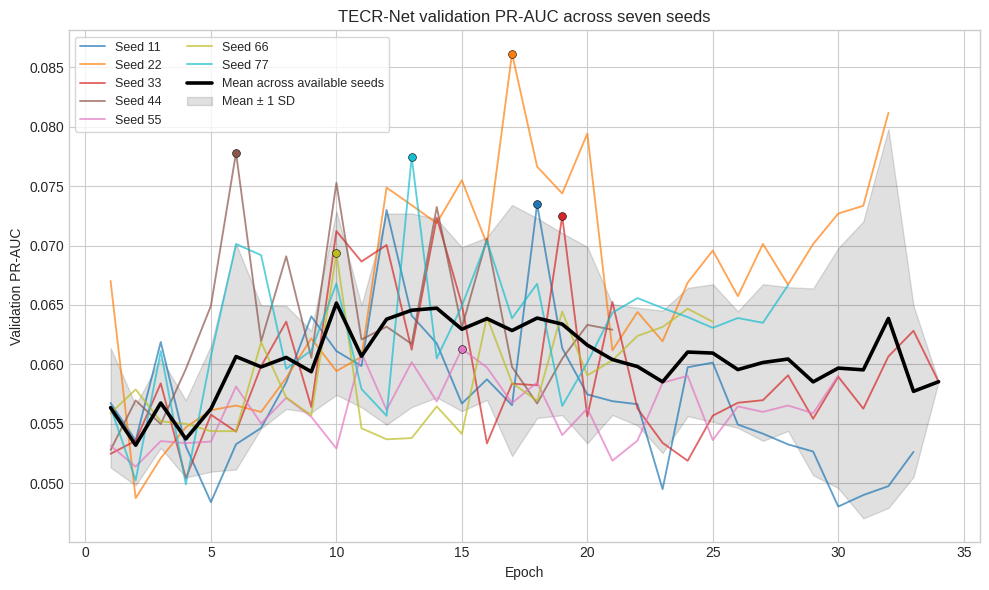

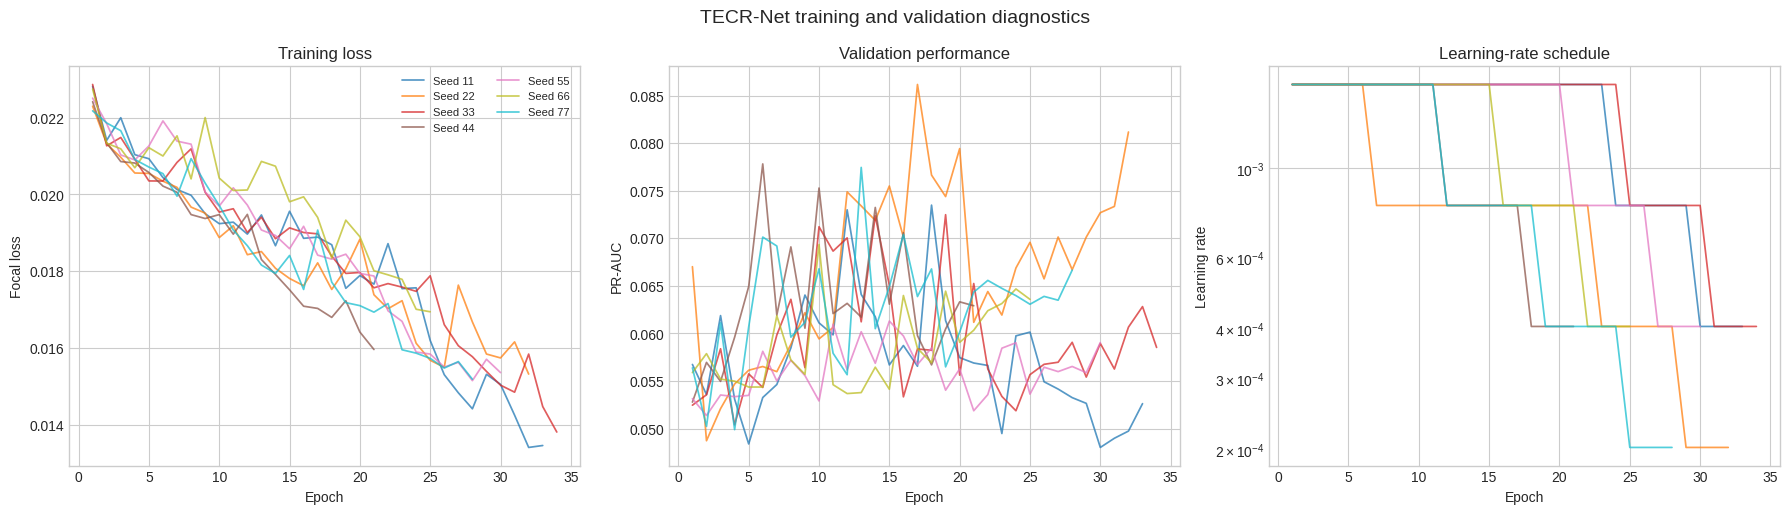


Best validation epoch by seed
 seed  epochs_trained  best_epoch  best_validation_pr_auc  training_loss_at_best_epoch  learning_rate_at_best_epoch
   11              33          18                0.073488                     0.018690                     0.001617
   22              32          17                0.086167                     0.018218                     0.000809
   33              34          19                0.072482                     0.017944                     0.001617
   44              21           6                0.077819                     0.020219                     0.001617
   55              30          15                0.061302                     0.018588                     0.001617
   66              25          10                0.069352                     0.020428                     0.001617
   77              28          13                0.077452                     0.018162                     0.000809

Figures: /kaggle/working/tecrnet_validat

In [7]:
"""Plot TECR-Net validation curves from the seven-seed results archive.

Works in Kaggle with either an attached ZIP/dataset or the original
/kaggle/working results directory. No model retraining is required.
"""

from __future__ import annotations

import re
import shutil
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


OUTPUT = Path("/kaggle/working/tecrnet_validation_curves")
EXPECTED_SEEDS = [11, 22, 33, 44, 55, 66, 77]


def seed_from_path(path: Path) -> int:
    match = re.search(r"history_seed_(\d+)\.csv$", path.name)
    if match is None:
        raise ValueError(f"Cannot read seed from {path}")
    return int(match.group(1))


def locate_histories() -> list[Path]:
    direct_roots = [
        Path("/kaggle/working/bsee_tecrnet_7seed_ensemble"),
        Path("/kaggle/input"),
    ]
    for root in direct_roots:
        if root.exists():
            matches = sorted(root.rglob("history_seed_*.csv"), key=seed_from_path)
            seeds = {seed_from_path(path) for path in matches}
            if set(EXPECTED_SEEDS).issubset(seeds):
                return [
                    next(path for path in matches if seed_from_path(path) == seed)
                    for seed in EXPECTED_SEEDS
                ]

    zip_candidates = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            zip_candidates.extend(root.rglob("bsee_tecrnet_7seed_ensemble*.zip"))
    if not zip_candidates:
        raise FileNotFoundError(
            "No history_seed_*.csv files or TECR-Net result ZIP found. "
            "Attach bsee_tecrnet_7seed_ensemble.zip as a Kaggle input."
        )

    extract_root = Path("/kaggle/working/tecrnet_curve_source")
    if extract_root.exists():
        shutil.rmtree(extract_root)
    extract_root.mkdir(parents=True)
    with zipfile.ZipFile(sorted(zip_candidates)[0]) as archive:
        archive.extractall(extract_root)

    matches = sorted(extract_root.rglob("history_seed_*.csv"), key=seed_from_path)
    seeds = {seed_from_path(path) for path in matches}
    missing = sorted(set(EXPECTED_SEEDS) - seeds)
    if missing:
        raise FileNotFoundError(f"Missing training histories for seeds: {missing}")
    return [
        next(path for path in matches if seed_from_path(path) == seed)
        for seed in EXPECTED_SEEDS
    ]


def load_histories(paths: list[Path]) -> pd.DataFrame:
    frames = []
    required = {"epoch", "training_loss", "validation_pr_auc", "learning_rate"}
    for path in paths:
        frame = pd.read_csv(path)
        missing = required - set(frame.columns)
        if missing:
            raise ValueError(f"{path} is missing columns: {sorted(missing)}")
        frame = frame[list(required)].copy()
        frame["seed"] = seed_from_path(path)
        frames.append(frame)
    result = pd.concat(frames, ignore_index=True)
    result["epoch"] = pd.to_numeric(result["epoch"], errors="raise").astype(int)
    for column in ["training_loss", "validation_pr_auc", "learning_rate"]:
        result[column] = pd.to_numeric(result[column], errors="raise")
    return result.sort_values(["seed", "epoch"]).reset_index(drop=True)


def best_epoch_table(history: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for seed, group in history.groupby("seed", sort=True):
        best_index = group["validation_pr_auc"].idxmax()
        best = history.loc[best_index]
        rows.append({
            "seed": int(seed),
            "epochs_trained": int(group["epoch"].max()),
            "best_epoch": int(best["epoch"]),
            "best_validation_pr_auc": float(best["validation_pr_auc"]),
            "training_loss_at_best_epoch": float(best["training_loss"]),
            "learning_rate_at_best_epoch": float(best["learning_rate"]),
        })
    return pd.DataFrame(rows)


def epoch_summary(history: pd.DataFrame) -> pd.DataFrame:
    return history.groupby("epoch", as_index=False).agg(
        active_seeds=("seed", "nunique"),
        validation_pr_auc_mean=("validation_pr_auc", "mean"),
        validation_pr_auc_std=("validation_pr_auc", "std"),
        training_loss_mean=("training_loss", "mean"),
        training_loss_std=("training_loss", "std"),
        learning_rate_mean=("learning_rate", "mean"),
    ).fillna({"validation_pr_auc_std": 0.0, "training_loss_std": 0.0})


def plot_validation(history: pd.DataFrame, summary: pd.DataFrame) -> None:
    plt.style.use("seaborn-v0_8-whitegrid")
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = plt.cm.tab10(np.linspace(0, 1, history["seed"].nunique()))
    for color, (seed, group) in zip(colors, history.groupby("seed", sort=True)):
        ax.plot(
            group["epoch"], group["validation_pr_auc"],
            color=color, linewidth=1.35, alpha=0.70, label=f"Seed {seed}",
        )
        best = group.loc[group["validation_pr_auc"].idxmax()]
        ax.scatter(
            best["epoch"], best["validation_pr_auc"],
            color=color, edgecolor="black", linewidth=0.4, s=32, zorder=4,
        )

    x = summary["epoch"].to_numpy()
    mean = summary["validation_pr_auc_mean"].to_numpy()
    std = summary["validation_pr_auc_std"].to_numpy()
    ax.plot(x, mean, color="black", linewidth=2.6, label="Mean across available seeds")
    ax.fill_between(x, mean - std, mean + std, color="black", alpha=0.12,
                    label="Mean ± 1 SD")
    ax.set(
        xlabel="Epoch",
        ylabel="Validation PR-AUC",
        title="TECR-Net validation PR-AUC across seven seeds",
    )
    ax.legend(ncol=2, fontsize=9, frameon=True)
    fig.tight_layout()
    fig.savefig(OUTPUT / "validation_pr_auc_curves.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT / "validation_pr_auc_curves.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_diagnostics(history: pd.DataFrame, summary: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
    colors = plt.cm.tab10(np.linspace(0, 1, history["seed"].nunique()))
    for color, (seed, group) in zip(colors, history.groupby("seed", sort=True)):
        axes[0].plot(group["epoch"], group["training_loss"], color=color,
                     alpha=0.75, linewidth=1.25, label=f"Seed {seed}")
        axes[1].plot(group["epoch"], group["validation_pr_auc"], color=color,
                     alpha=0.75, linewidth=1.25)
        axes[2].plot(group["epoch"], group["learning_rate"], color=color,
                     alpha=0.75, linewidth=1.25)

    axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Focal loss")
    axes[1].set(title="Validation performance", xlabel="Epoch", ylabel="PR-AUC")
    axes[2].set(title="Learning-rate schedule", xlabel="Epoch", ylabel="Learning rate")
    axes[2].set_yscale("log")
    axes[0].legend(ncol=2, fontsize=8)
    fig.suptitle("TECR-Net training and validation diagnostics", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUTPUT / "training_validation_diagnostics.png", dpi=300,
                bbox_inches="tight")
    fig.savefig(OUTPUT / "training_validation_diagnostics.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def main() -> None:
    OUTPUT.mkdir(parents=True, exist_ok=True)
    histories = locate_histories()
    history = load_histories(histories)
    best = best_epoch_table(history)
    summary = epoch_summary(history)

    history.to_csv(OUTPUT / "combined_epoch_history.csv", index=False)
    best.to_csv(OUTPUT / "best_validation_epoch_by_seed.csv", index=False)
    summary.to_csv(OUTPUT / "epoch_curve_summary.csv", index=False)
    plot_validation(history, summary)
    plot_diagnostics(history, summary)

    archive = shutil.make_archive(
        "/kaggle/working/tecrnet_validation_curves",
        "zip",
        root_dir=str(OUTPUT.parent),
        base_dir=OUTPUT.name,
    )
    print("\nBest validation epoch by seed")
    print(best.to_string(index=False))
    print(f"\nFigures: {OUTPUT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


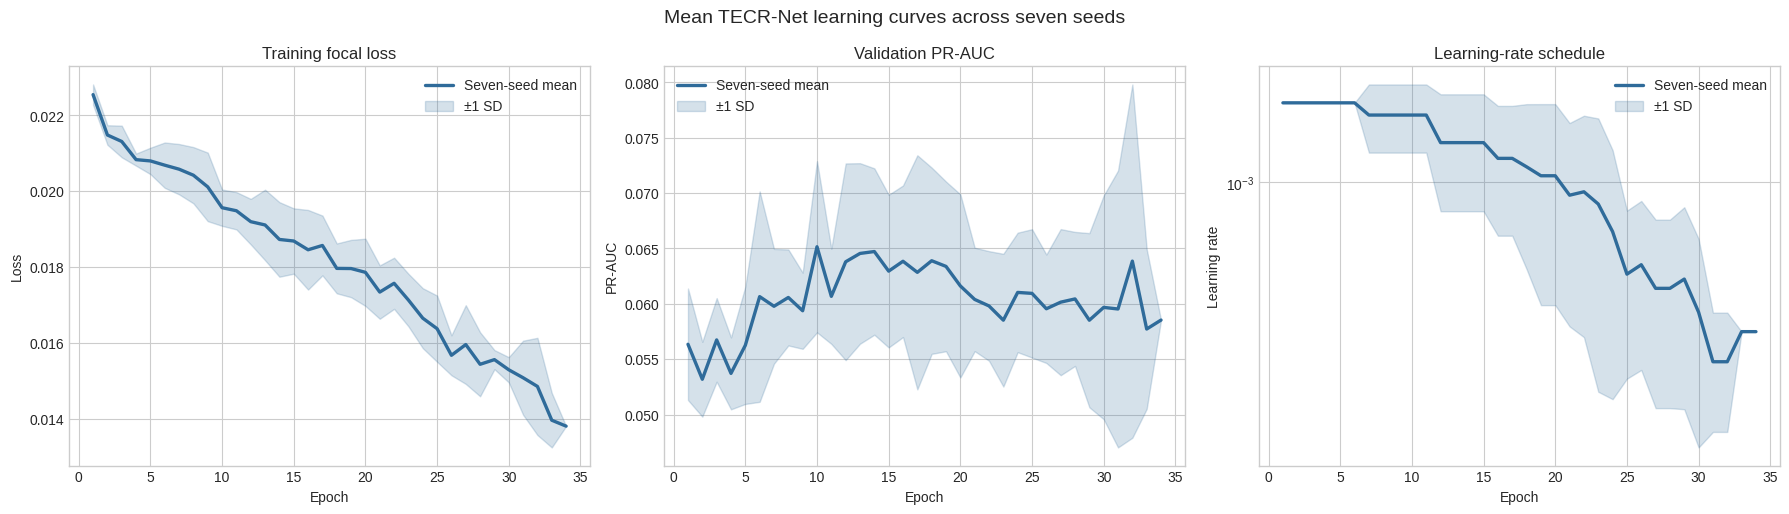

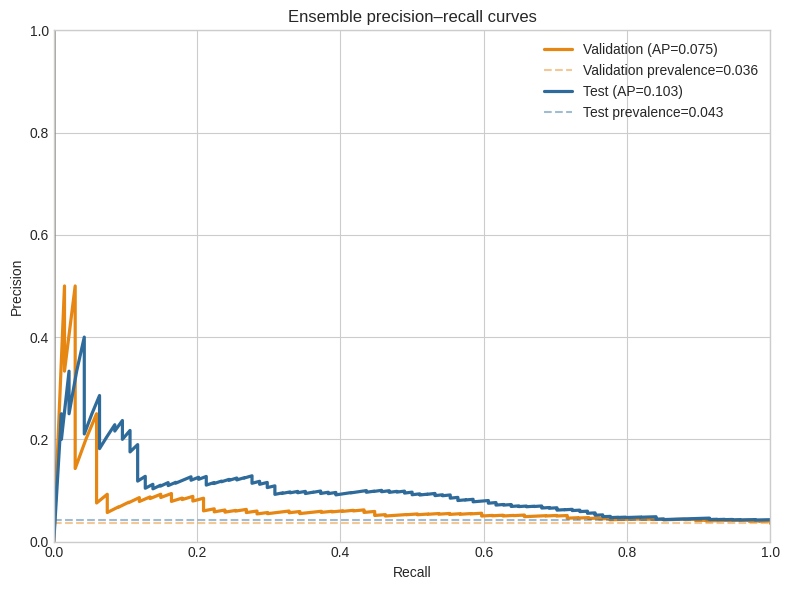

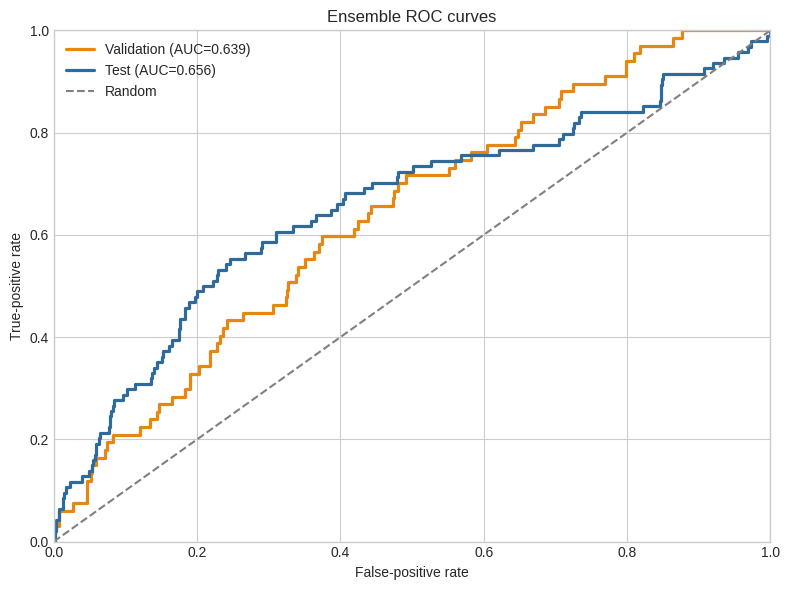

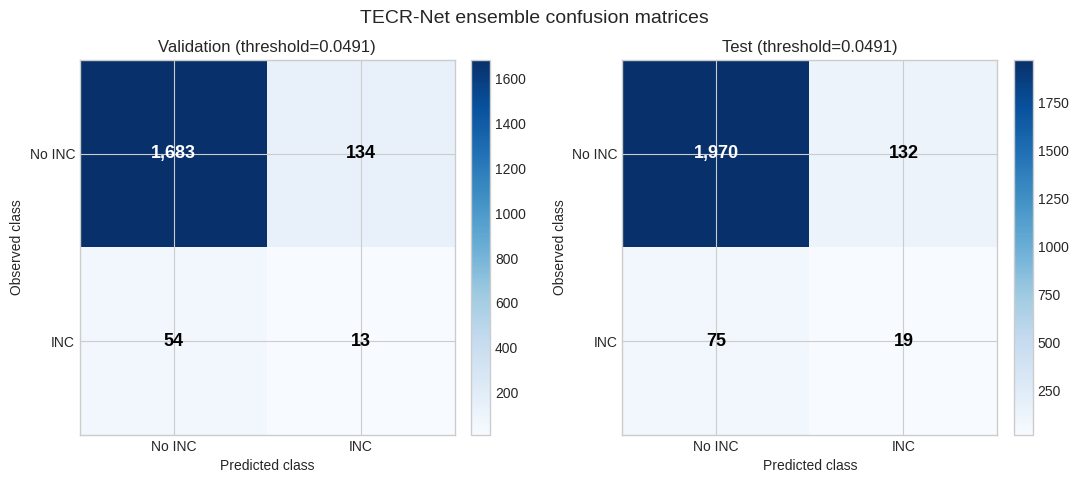

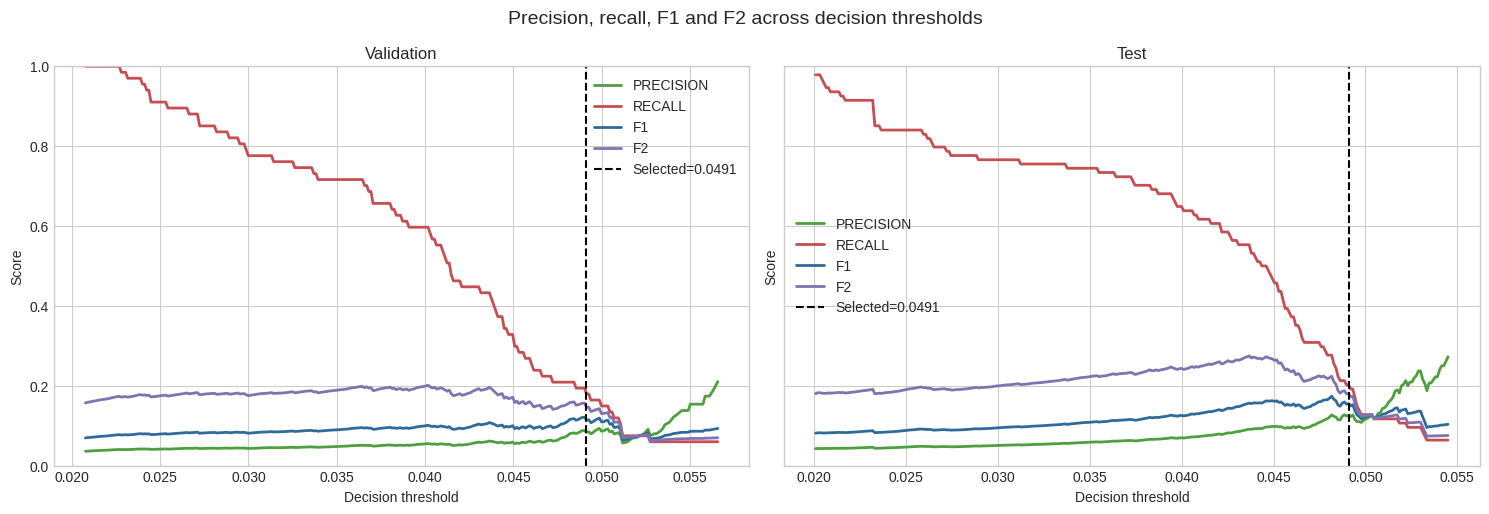

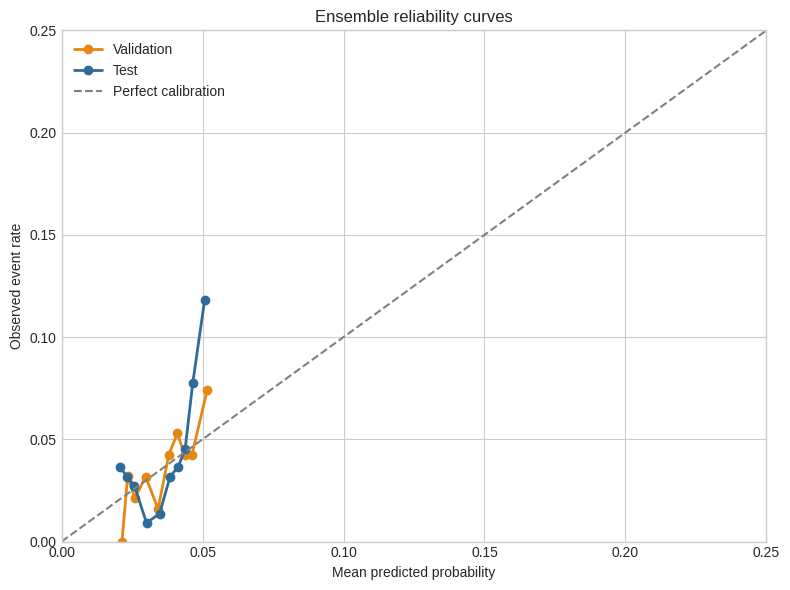

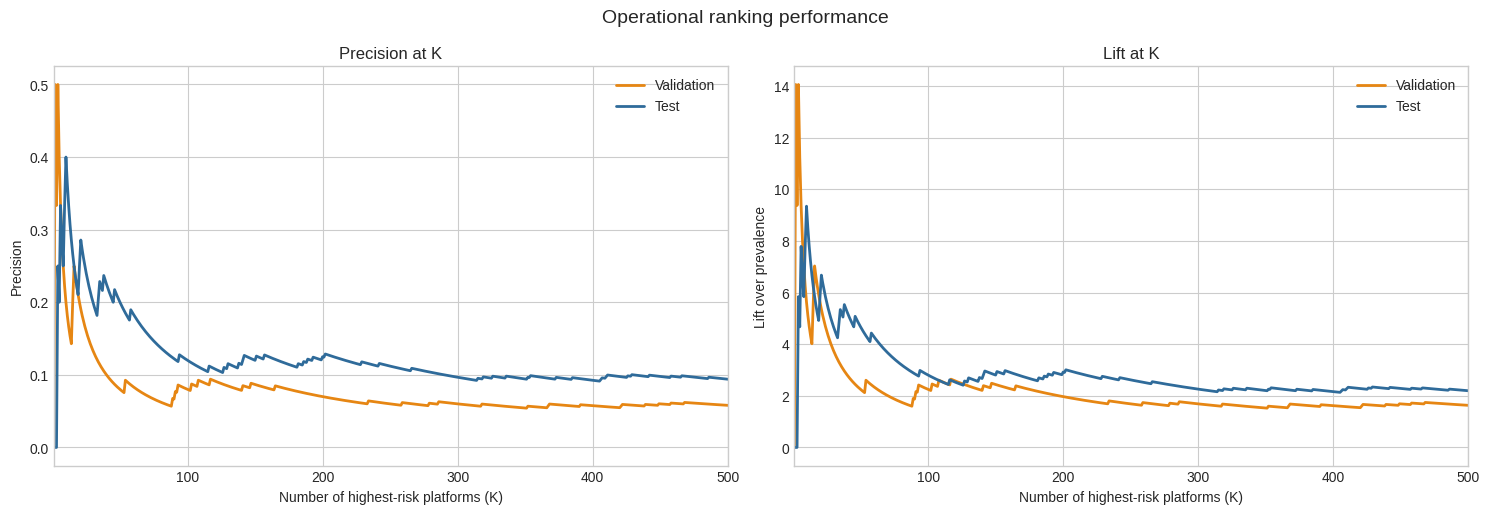

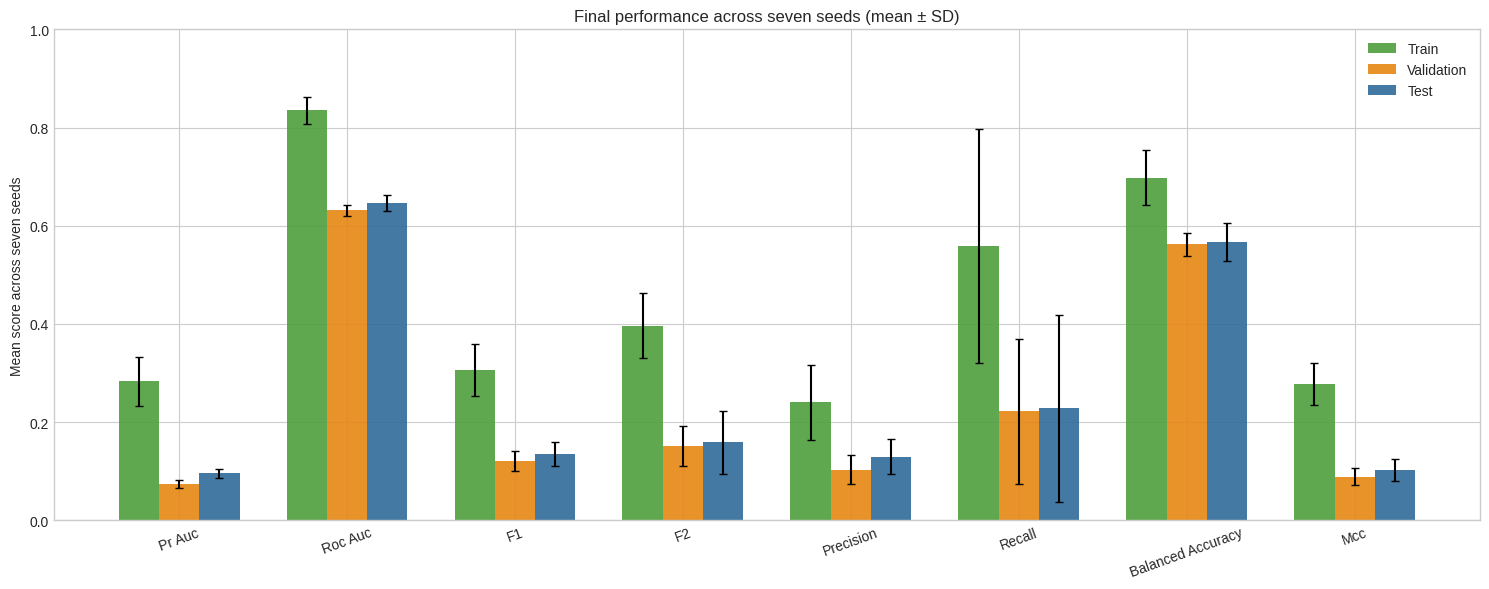

Source results: /kaggle/working/bsee_tecrnet_7seed_ensemble
Figures: /kaggle/working/tecrnet_mean_figures
Downloadable ZIP: /kaggle/working/tecrnet_mean_figures.zip


In [8]:
"""Create aggregate publication figures for the TECR-Net seven-seed run.

The saved epoch histories contain training loss, validation PR-AUC and learning
rate. Other curves are reconstructed from the locked validation/test ensemble
predictions, while final split metrics are summarized across seven seeds.
"""

from __future__ import annotations

import json
import re
import shutil
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)


OUTPUT = Path("/kaggle/working/tecrnet_mean_figures")
EXPECTED_SEEDS = [11, 22, 33, 44, 55, 66, 77]
COLORS = {"validation": "#E68613", "test": "#2F6B9A", "train": "#4E9F3D"}


def find_result_root() -> Path:
    candidates = [Path("/kaggle/working/bsee_tecrnet_7seed_ensemble")]
    if Path("/kaggle/input").exists():
        candidates.extend(
            path.parent for path in Path("/kaggle/input").rglob("all_seed_results.csv")
        )
    for candidate in candidates:
        if (
            (candidate / "all_seed_results.csv").exists()
            and list(candidate.rglob("validation_ensemble_predictions.csv"))
        ):
            return candidate

    zip_candidates = []
    for location in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if location.exists():
            zip_candidates.extend(location.rglob("bsee_tecrnet_7seed_ensemble*.zip"))
    if not zip_candidates:
        raise FileNotFoundError(
            "Attach bsee_tecrnet_7seed_ensemble.zip to this Kaggle notebook."
        )
    extract_root = Path("/kaggle/working/tecrnet_mean_figure_source")
    if extract_root.exists():
        shutil.rmtree(extract_root)
    extract_root.mkdir(parents=True)
    with zipfile.ZipFile(sorted(zip_candidates)[0]) as archive:
        archive.extractall(extract_root)
    matches = list(extract_root.rglob("all_seed_results.csv"))
    if len(matches) != 1:
        raise RuntimeError(f"Expected one result table, found {len(matches)}")
    return matches[0].parent


def seed_number(path: Path) -> int:
    match = re.search(r"history_seed_(\d+)\.csv$", path.name)
    if match is None:
        raise ValueError(f"Cannot identify seed in {path.name}")
    return int(match.group(1))


def load_histories(root: Path) -> pd.DataFrame:
    paths = list(root.rglob("history_seed_*.csv"))
    available = {seed_number(path): path for path in paths}
    missing = sorted(set(EXPECTED_SEEDS) - set(available))
    if missing:
        raise FileNotFoundError(f"Missing histories for seeds {missing}")
    frames = []
    required = ["epoch", "training_loss", "validation_pr_auc", "learning_rate"]
    for seed in EXPECTED_SEEDS:
        frame = pd.read_csv(available[seed])
        absent = sorted(set(required) - set(frame.columns))
        if absent:
            raise ValueError(f"Seed {seed} history is missing {absent}")
        frame = frame[required].copy()
        frame["seed"] = seed
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)


def aggregate_epochs(history: pd.DataFrame) -> pd.DataFrame:
    return history.groupby("epoch", as_index=False).agg(
        active_seeds=("seed", "nunique"),
        training_loss_mean=("training_loss", "mean"),
        training_loss_std=("training_loss", "std"),
        validation_pr_auc_mean=("validation_pr_auc", "mean"),
        validation_pr_auc_std=("validation_pr_auc", "std"),
        learning_rate_mean=("learning_rate", "mean"),
        learning_rate_std=("learning_rate", "std"),
    ).fillna(0.0)


def load_ensemble_predictions(root: Path) -> dict[str, pd.DataFrame]:
    result = {}
    for split in ["validation", "test"]:
        matches = list(root.rglob(f"{split}_ensemble_predictions.csv"))
        if len(matches) != 1:
            raise RuntimeError(f"Expected one {split} ensemble file, found {len(matches)}")
        frame = pd.read_csv(matches[0])
        probability_column = (
            "ensemble_probability" if "ensemble_probability" in frame.columns
            else "probability"
        )
        required = {"target", probability_column}
        if not required.issubset(frame.columns):
            raise ValueError(f"Invalid {split} ensemble-prediction file")
        frame = frame.copy()
        frame["probability"] = pd.to_numeric(frame[probability_column], errors="raise")
        frame["target"] = pd.to_numeric(frame["target"], errors="raise").astype(int)
        result[split] = frame
    return result


def read_threshold(root: Path) -> float:
    matches = list(root.rglob("ensemble_metrics.csv"))
    if matches:
        metrics = pd.read_csv(matches[0])
        validation = metrics.loc[metrics["split"] == "validation"]
        if not validation.empty:
            return float(validation.iloc[0]["threshold"])
    configuration = root / "configuration.json"
    if configuration.exists():
        json.loads(configuration.read_text(encoding="utf-8"))
    raise FileNotFoundError("Could not recover the validation-selected threshold")


def save_figure(fig: plt.Figure, stem: str) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT / f"{stem}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_mean_learning_curves(epoch: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
    x = epoch["epoch"].to_numpy()
    specifications = [
        ("training_loss", "Training focal loss", "Loss", False),
        ("validation_pr_auc", "Validation PR-AUC", "PR-AUC", False),
        ("learning_rate", "Learning-rate schedule", "Learning rate", True),
    ]
    for ax, (metric, title, ylabel, logarithmic) in zip(axes, specifications):
        mean = epoch[f"{metric}_mean"].to_numpy()
        std = epoch[f"{metric}_std"].to_numpy()
        lower = np.maximum(mean - std, 1e-12 if logarithmic else -np.inf)
        ax.plot(x, mean, color="#2F6B9A", linewidth=2.4, label="Seven-seed mean")
        ax.fill_between(x, lower, mean + std, color="#2F6B9A", alpha=0.20,
                        label="±1 SD")
        ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
        if logarithmic:
            ax.set_yscale("log")
        ax.legend()
    fig.suptitle("Mean TECR-Net learning curves across seven seeds", fontsize=14)
    save_figure(fig, "mean_learning_curves")


def plot_precision_recall(predictions: dict[str, pd.DataFrame]) -> None:
    fig, ax = plt.subplots(figsize=(8, 6))
    for split, frame in predictions.items():
        target = frame["target"].to_numpy()
        probability = frame["probability"].to_numpy()
        precision, recall, _ = precision_recall_curve(target, probability)
        ap = average_precision_score(target, probability)
        prevalence = target.mean()
        ax.plot(recall, precision, linewidth=2.3, color=COLORS[split],
                label=f"{split.title()} (AP={ap:.3f})")
        ax.axhline(prevalence, color=COLORS[split], linestyle="--", alpha=0.45,
                   label=f"{split.title()} prevalence={prevalence:.3f}")
    ax.set(xlabel="Recall", ylabel="Precision", title="Ensemble precision–recall curves",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend()
    save_figure(fig, "ensemble_precision_recall_curves")


def plot_roc(predictions: dict[str, pd.DataFrame]) -> None:
    fig, ax = plt.subplots(figsize=(8, 6))
    for split, frame in predictions.items():
        target = frame["target"].to_numpy()
        probability = frame["probability"].to_numpy()
        fpr, tpr, _ = roc_curve(target, probability)
        score = roc_auc_score(target, probability)
        ax.plot(fpr, tpr, linewidth=2.3, color=COLORS[split],
                label=f"{split.title()} (AUC={score:.3f})")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Random")
    ax.set(xlabel="False-positive rate", ylabel="True-positive rate",
           title="Ensemble ROC curves", xlim=(0, 1), ylim=(0, 1))
    ax.legend()
    save_figure(fig, "ensemble_roc_curves")


def plot_confusion_matrices(predictions: dict[str, pd.DataFrame], threshold: float) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    for ax, (split, frame) in zip(axes, predictions.items()):
        target = frame["target"].to_numpy()
        predicted = (frame["probability"].to_numpy() >= threshold).astype(int)
        matrix = confusion_matrix(target, predicted, labels=[0, 1])
        image = ax.imshow(matrix, cmap="Blues")
        for row in range(2):
            for column in range(2):
                ax.text(column, row, f"{matrix[row, column]:,}", ha="center", va="center",
                        color="white" if matrix[row, column] > matrix.max() / 2 else "black",
                        fontsize=13, fontweight="bold")
        ax.set_xticks([0, 1], labels=["No INC", "INC"])
        ax.set_yticks([0, 1], labels=["No INC", "INC"])
        ax.set(xlabel="Predicted class", ylabel="Observed class",
               title=f"{split.title()} (threshold={threshold:.4f})")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle("TECR-Net ensemble confusion matrices", fontsize=14)
    save_figure(fig, "ensemble_confusion_matrices")


def threshold_metrics(frame: pd.DataFrame) -> pd.DataFrame:
    target = frame["target"].to_numpy()
    probability = frame["probability"].to_numpy()
    thresholds = np.linspace(max(0.0, np.quantile(probability, 0.01)),
                             min(1.0, np.quantile(probability, 0.99)), 300)
    rows = []
    for threshold in thresholds:
        predicted = probability >= threshold
        rows.append({
            "threshold": threshold,
            "precision": precision_score(target, predicted, zero_division=0),
            "recall": recall_score(target, predicted, zero_division=0),
            "f1": f1_score(target, predicted, zero_division=0),
            "f2": fbeta_score(target, predicted, beta=2, zero_division=0),
        })
    return pd.DataFrame(rows)


def plot_threshold_curves(predictions: dict[str, pd.DataFrame], threshold: float) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
    combined = []
    for ax, (split, frame) in zip(axes, predictions.items()):
        table = threshold_metrics(frame)
        table["split"] = split
        combined.append(table)
        for metric, color in [("precision", "#4E9F3D"), ("recall", "#C44E52"),
                              ("f1", "#2F6B9A"), ("f2", "#8172B2")]:
            ax.plot(table["threshold"], table[metric], label=metric.upper(),
                    linewidth=2, color=color)
        ax.axvline(threshold, color="black", linestyle="--",
                   label=f"Selected={threshold:.4f}")
        ax.set(title=split.title(), xlabel="Decision threshold", ylabel="Score",
               ylim=(0, 1))
        ax.legend()
    pd.concat(combined, ignore_index=True).to_csv(
        OUTPUT / "threshold_curve_values.csv", index=False
    )
    fig.suptitle("Precision, recall, F1 and F2 across decision thresholds", fontsize=14)
    save_figure(fig, "ensemble_threshold_metric_curves")


def plot_calibration(predictions: dict[str, pd.DataFrame]) -> None:
    fig, ax = plt.subplots(figsize=(8, 6))
    for split, frame in predictions.items():
        observed, predicted = calibration_curve(
            frame["target"], frame["probability"], n_bins=10, strategy="quantile"
        )
        ax.plot(predicted, observed, marker="o", linewidth=2, color=COLORS[split],
                label=split.title())
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    ax.set(xlabel="Mean predicted probability", ylabel="Observed event rate",
           title="Ensemble reliability curves", xlim=(0, 0.25), ylim=(0, 0.25))
    ax.legend()
    save_figure(fig, "ensemble_calibration_curves")


def plot_top_k(predictions: dict[str, pd.DataFrame]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
    output_rows = []
    for split, frame in predictions.items():
        ranked = frame.sort_values("probability", ascending=False)
        target = ranked["target"].to_numpy()
        prevalence = target.mean()
        cumulative_positive = np.cumsum(target)
        k = np.arange(1, len(target) + 1)
        precision = cumulative_positive / k
        recall = cumulative_positive / max(target.sum(), 1)
        lift = precision / prevalence
        axes[0].plot(k, precision, color=COLORS[split], linewidth=2,
                     label=split.title())
        axes[1].plot(k, lift, color=COLORS[split], linewidth=2,
                     label=split.title())
        output_rows.append(pd.DataFrame({
            "split": split, "k": k, "precision_at_k": precision,
            "recall_at_k": recall, "lift_at_k": lift,
        }))
    axes[0].set(title="Precision at K", xlabel="Number of highest-risk platforms (K)",
                ylabel="Precision")
    axes[1].set(title="Lift at K", xlabel="Number of highest-risk platforms (K)",
                ylabel="Lift over prevalence")
    for ax in axes:
        ax.set_xlim(1, 500)
        ax.legend()
    pd.concat(output_rows, ignore_index=True).to_csv(
        OUTPUT / "top_k_curve_values.csv", index=False
    )
    fig.suptitle("Operational ranking performance", fontsize=14)
    save_figure(fig, "ensemble_top_k_curves")


def plot_final_seed_means(root: Path) -> None:
    results = pd.read_csv(root / "all_seed_results.csv")
    metrics = ["pr_auc", "roc_auc", "f1", "f2", "precision", "recall",
               "balanced_accuracy", "mcc"]
    missing = sorted(set(metrics + ["split", "seed"]) - set(results.columns))
    if missing:
        raise ValueError(f"all_seed_results.csv is missing {missing}")
    summary = results.groupby("split")[metrics].agg(["mean", "std"])
    summary.to_csv(OUTPUT / "final_metrics_mean_std.csv")
    order = [split for split in ["train", "validation", "test"] if split in summary.index]
    x = np.arange(len(metrics))
    width = 0.24
    fig, ax = plt.subplots(figsize=(15, 6))
    for index, split in enumerate(order):
        means = summary.loc[split].xs("mean", level=1).to_numpy()
        stds = summary.loc[split].xs("std", level=1).to_numpy()
        ax.bar(x + (index - 1) * width, means, width, yerr=stds, capsize=3,
               label=split.title(), color=COLORS[split], alpha=0.90)
    ax.set_xticks(x, [name.replace("_", " ").title() for name in metrics], rotation=20)
    ax.set(ylabel="Mean score across seven seeds",
           title="Final performance across seven seeds (mean ± SD)", ylim=(0, 1))
    ax.legend()
    save_figure(fig, "final_seed_mean_metrics")


def main() -> None:
    plt.style.use("seaborn-v0_8-whitegrid")
    OUTPUT.mkdir(parents=True, exist_ok=True)
    root = find_result_root()
    history = load_histories(root)
    epoch = aggregate_epochs(history)
    predictions = load_ensemble_predictions(root)
    threshold = read_threshold(root)

    history.to_csv(OUTPUT / "combined_seed_histories.csv", index=False)
    epoch.to_csv(OUTPUT / "mean_epoch_curves.csv", index=False)
    plot_mean_learning_curves(epoch)
    plot_precision_recall(predictions)
    plot_roc(predictions)
    plot_confusion_matrices(predictions, threshold)
    plot_threshold_curves(predictions, threshold)
    plot_calibration(predictions)
    plot_top_k(predictions)
    plot_final_seed_means(root)

    archive = shutil.make_archive(
        "/kaggle/working/tecrnet_mean_figures", "zip",
        root_dir=str(OUTPUT.parent), base_dir=OUTPUT.name,
    )
    print(f"Source results: {root}")
    print(f"Figures: {OUTPUT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


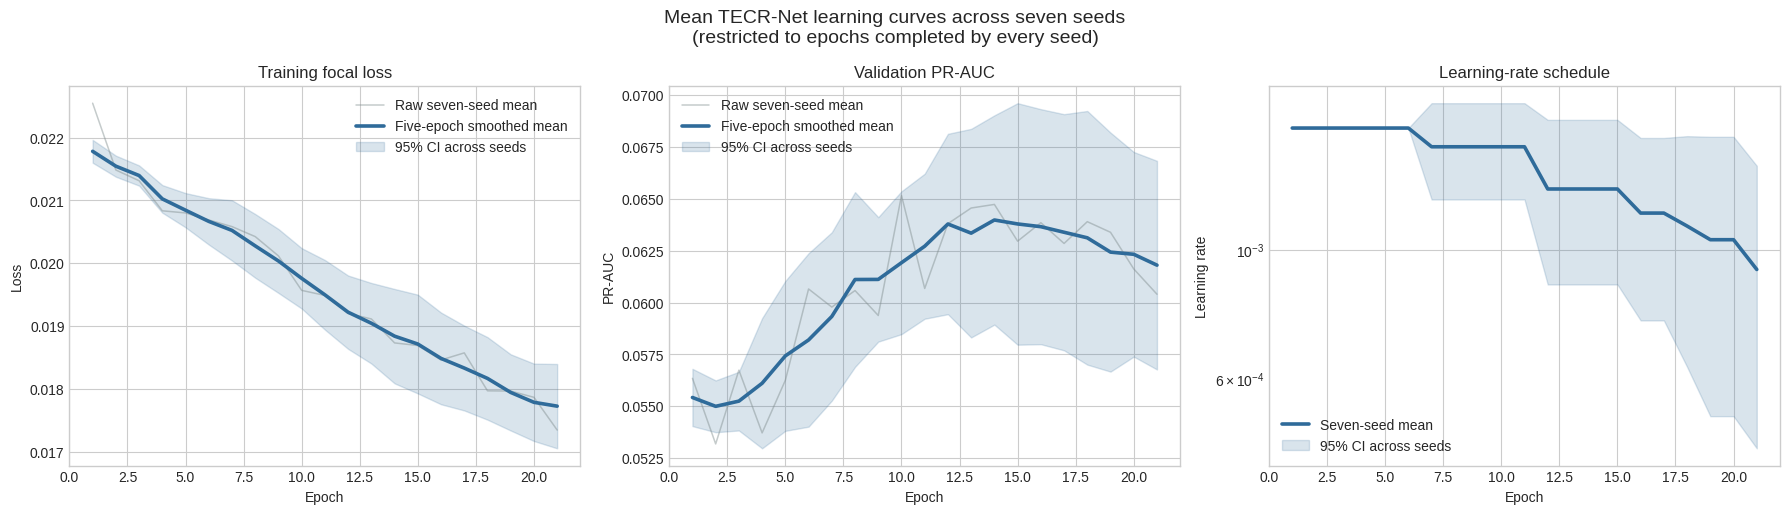

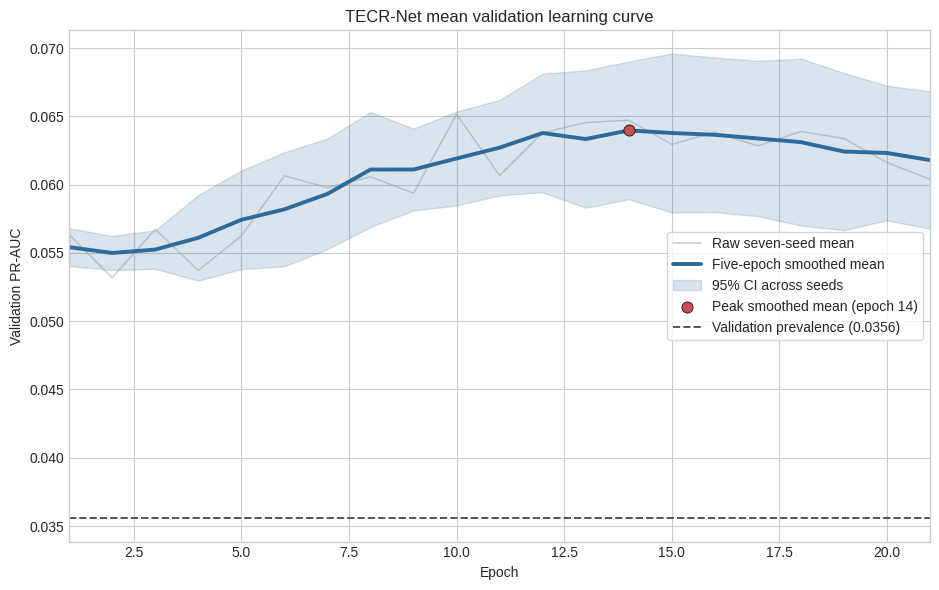

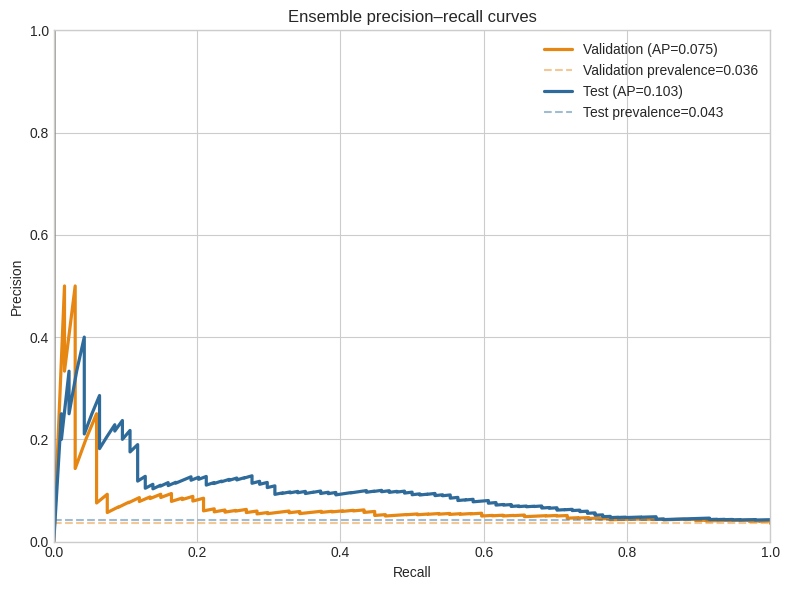

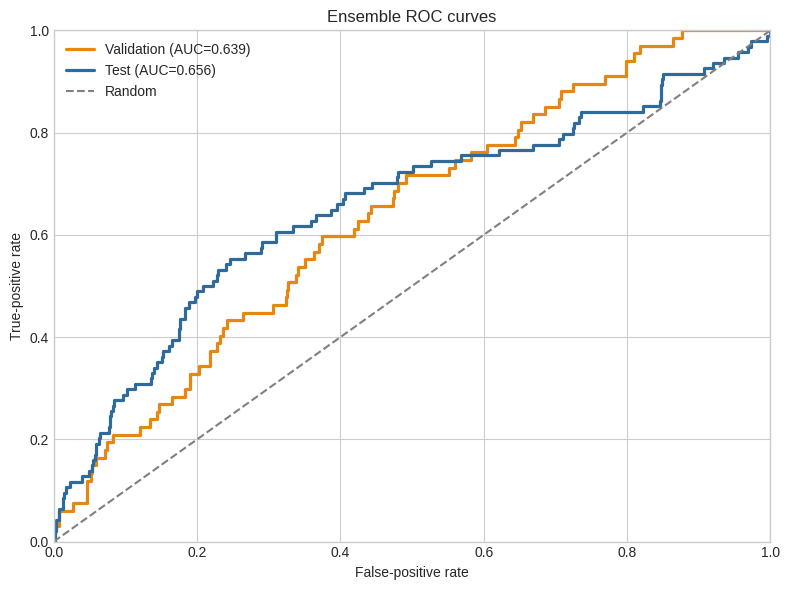

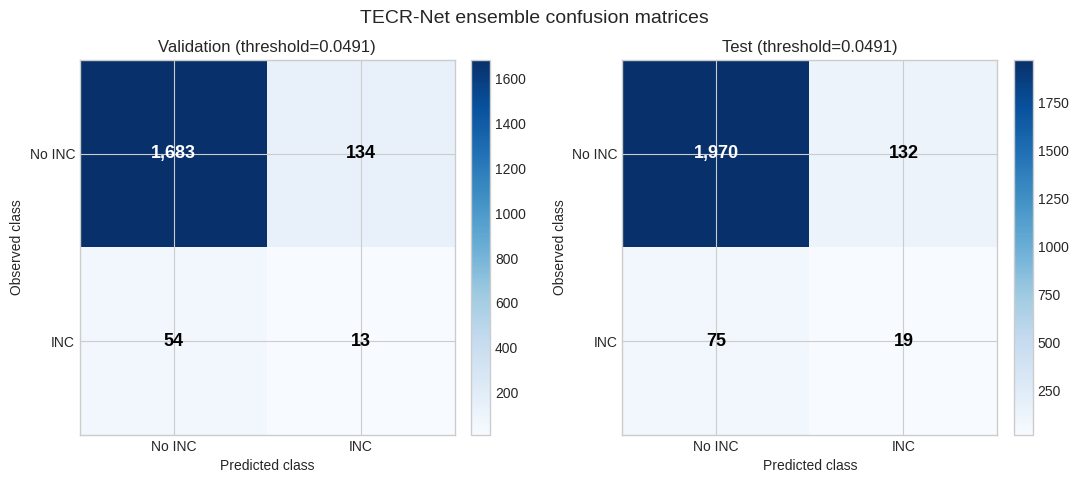

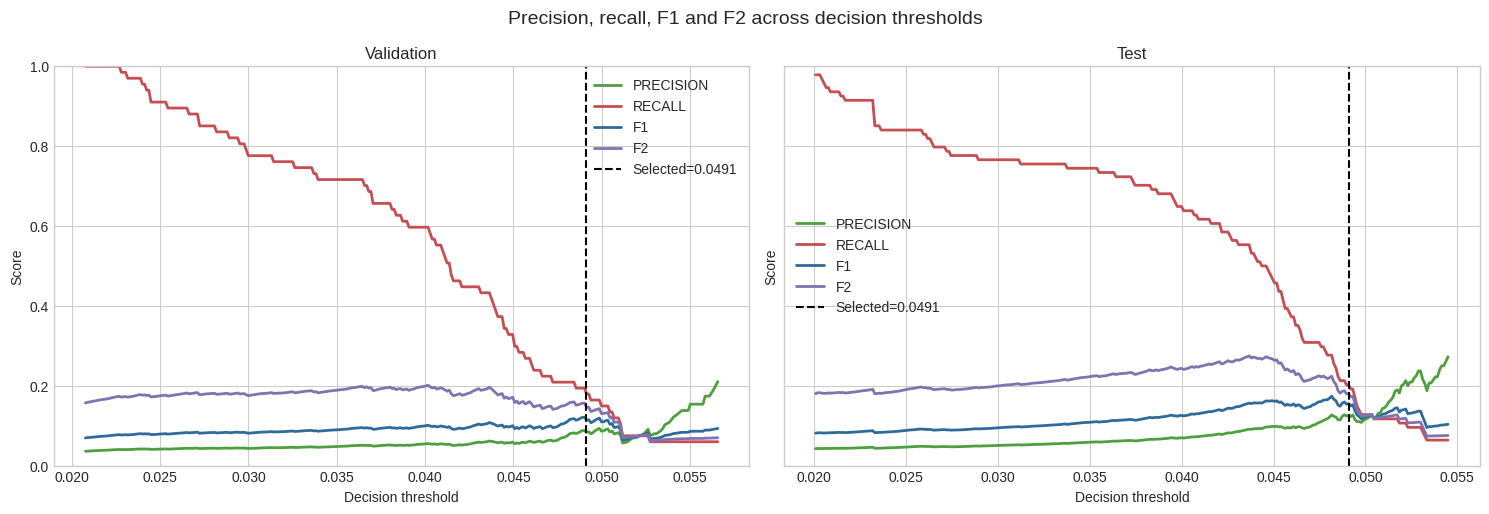

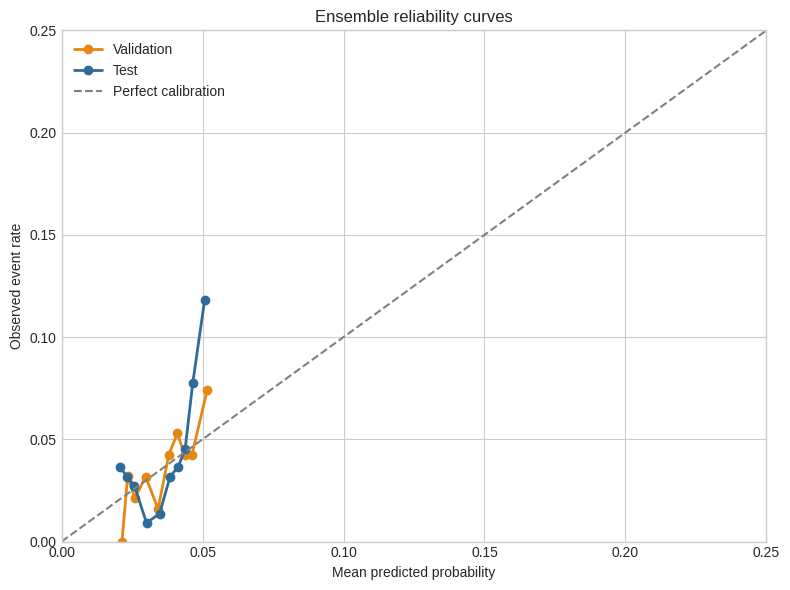

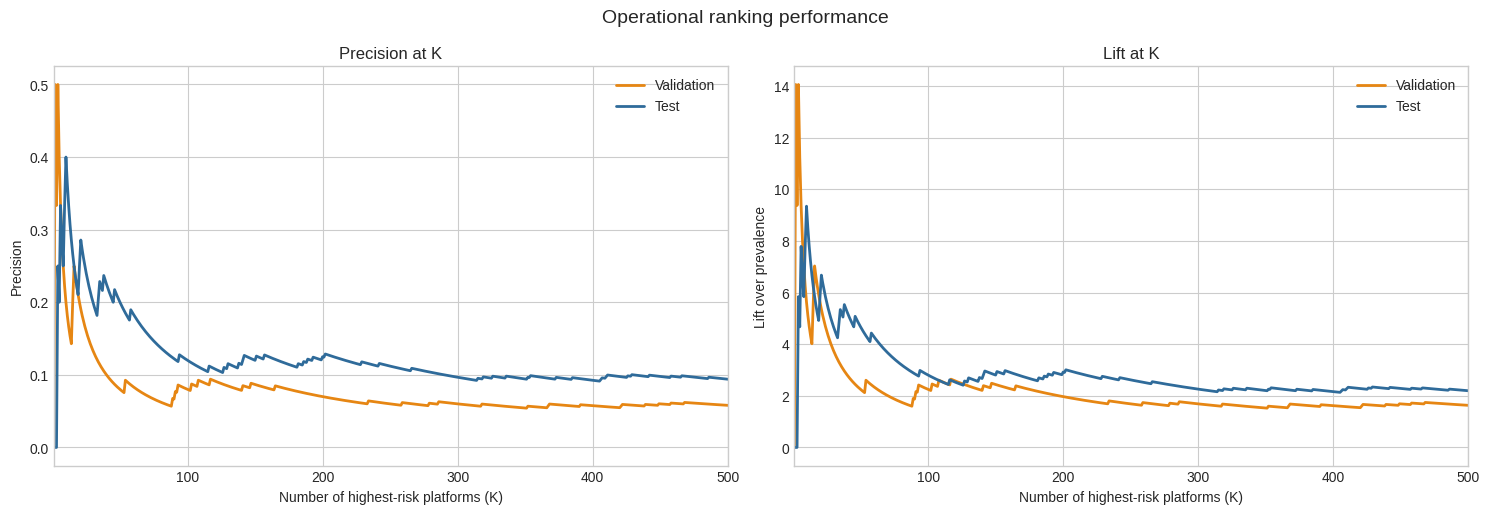

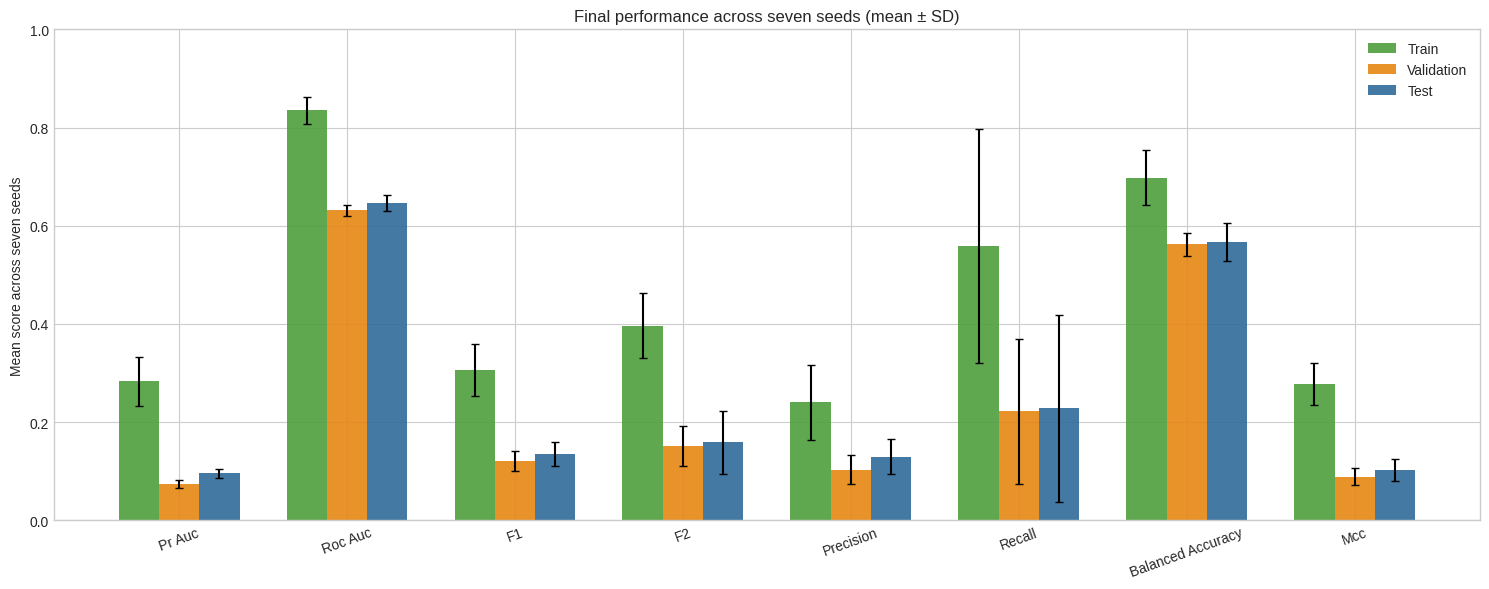

Source results: /kaggle/working/bsee_tecrnet_7seed_ensemble
Figures: /kaggle/working/tecrnet_mean_figures
Downloadable ZIP: /kaggle/working/tecrnet_mean_figures.zip


In [9]:
"""Create aggregate publication figures for the TECR-Net seven-seed run.

The saved epoch histories contain training loss, validation PR-AUC and learning
rate. Other curves are reconstructed from the locked validation/test ensemble
predictions, while final split metrics are summarized across seven seeds.
"""

from __future__ import annotations

import json
import re
import shutil
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)


OUTPUT = Path("/kaggle/working/tecrnet_mean_figures")
EXPECTED_SEEDS = [11, 22, 33, 44, 55, 66, 77]
COLORS = {"validation": "#E68613", "test": "#2F6B9A", "train": "#4E9F3D"}


def find_result_root() -> Path:
    candidates = [Path("/kaggle/working/bsee_tecrnet_7seed_ensemble")]
    if Path("/kaggle/input").exists():
        candidates.extend(
            path.parent for path in Path("/kaggle/input").rglob("all_seed_results.csv")
        )
    for candidate in candidates:
        if (
            (candidate / "all_seed_results.csv").exists()
            and list(candidate.rglob("validation_ensemble_predictions.csv"))
        ):
            return candidate

    zip_candidates = []
    for location in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if location.exists():
            zip_candidates.extend(location.rglob("bsee_tecrnet_7seed_ensemble*.zip"))
    if not zip_candidates:
        raise FileNotFoundError(
            "Attach bsee_tecrnet_7seed_ensemble.zip to this Kaggle notebook."
        )
    extract_root = Path("/kaggle/working/tecrnet_mean_figure_source")
    if extract_root.exists():
        shutil.rmtree(extract_root)
    extract_root.mkdir(parents=True)
    with zipfile.ZipFile(sorted(zip_candidates)[0]) as archive:
        archive.extractall(extract_root)
    matches = list(extract_root.rglob("all_seed_results.csv"))
    if len(matches) != 1:
        raise RuntimeError(f"Expected one result table, found {len(matches)}")
    return matches[0].parent


def seed_number(path: Path) -> int:
    match = re.search(r"history_seed_(\d+)\.csv$", path.name)
    if match is None:
        raise ValueError(f"Cannot identify seed in {path.name}")
    return int(match.group(1))


def load_histories(root: Path) -> pd.DataFrame:
    paths = list(root.rglob("history_seed_*.csv"))
    available = {seed_number(path): path for path in paths}
    missing = sorted(set(EXPECTED_SEEDS) - set(available))
    if missing:
        raise FileNotFoundError(f"Missing histories for seeds {missing}")
    frames = []
    required = ["epoch", "training_loss", "validation_pr_auc", "learning_rate"]
    for seed in EXPECTED_SEEDS:
        frame = pd.read_csv(available[seed])
        absent = sorted(set(required) - set(frame.columns))
        if absent:
            raise ValueError(f"Seed {seed} history is missing {absent}")
        frame = frame[required].copy()
        frame["seed"] = seed
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)


def aggregate_epochs(history: pd.DataFrame, smoothing_window: int = 5) -> pd.DataFrame:
    """Aggregate only epochs observed for every seed.

    Each seed is smoothed independently before aggregation. This avoids both
    artificial late-epoch spikes caused by a changing seed count and smoothing
    across unrelated seed trajectories.
    """
    common_last_epoch = int(history.groupby("seed")["epoch"].max().min())
    common = history.loc[history["epoch"] <= common_last_epoch].copy()
    common = common.sort_values(["seed", "epoch"])
    for metric in ["training_loss", "validation_pr_auc"]:
        common[f"{metric}_smooth"] = common.groupby("seed")[metric].transform(
            lambda values: values.rolling(
                window=smoothing_window, center=True, min_periods=2
            ).mean()
        )

    result = common.groupby("epoch", as_index=False).agg(
        active_seeds=("seed", "nunique"),
        training_loss_mean=("training_loss", "mean"),
        training_loss_std=("training_loss", "std"),
        training_loss_smooth_mean=("training_loss_smooth", "mean"),
        training_loss_smooth_std=("training_loss_smooth", "std"),
        validation_pr_auc_mean=("validation_pr_auc", "mean"),
        validation_pr_auc_std=("validation_pr_auc", "std"),
        validation_pr_auc_smooth_mean=("validation_pr_auc_smooth", "mean"),
        validation_pr_auc_smooth_std=("validation_pr_auc_smooth", "std"),
        learning_rate_mean=("learning_rate", "mean"),
        learning_rate_std=("learning_rate", "std"),
    ).fillna(0.0)
    if not (result["active_seeds"] == len(EXPECTED_SEEDS)).all():
        raise RuntimeError("Common-epoch aggregation does not contain all seven seeds")
    return result


def load_ensemble_predictions(root: Path) -> dict[str, pd.DataFrame]:
    result = {}
    for split in ["validation", "test"]:
        matches = list(root.rglob(f"{split}_ensemble_predictions.csv"))
        if len(matches) != 1:
            raise RuntimeError(f"Expected one {split} ensemble file, found {len(matches)}")
        frame = pd.read_csv(matches[0])
        probability_column = (
            "ensemble_probability" if "ensemble_probability" in frame.columns
            else "probability"
        )
        required = {"target", probability_column}
        if not required.issubset(frame.columns):
            raise ValueError(f"Invalid {split} ensemble-prediction file")
        frame = frame.copy()
        frame["probability"] = pd.to_numeric(frame[probability_column], errors="raise")
        frame["target"] = pd.to_numeric(frame["target"], errors="raise").astype(int)
        result[split] = frame
    return result


def read_threshold(root: Path) -> float:
    matches = list(root.rglob("ensemble_metrics.csv"))
    if matches:
        metrics = pd.read_csv(matches[0])
        validation = metrics.loc[metrics["split"] == "validation"]
        if not validation.empty:
            return float(validation.iloc[0]["threshold"])
    configuration = root / "configuration.json"
    if configuration.exists():
        json.loads(configuration.read_text(encoding="utf-8"))
    raise FileNotFoundError("Could not recover the validation-selected threshold")


def save_figure(fig: plt.Figure, stem: str) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT / f"{stem}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_mean_learning_curves(epoch: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
    x = epoch["epoch"].to_numpy()
    specifications = [
        ("training_loss", "Training focal loss", "Loss", False, True),
        ("validation_pr_auc", "Validation PR-AUC", "PR-AUC", False, True),
        ("learning_rate", "Learning-rate schedule", "Learning rate", True, False),
    ]
    for ax, (metric, title, ylabel, logarithmic, smoothed) in zip(axes, specifications):
        raw_mean = epoch[f"{metric}_mean"].to_numpy()
        if smoothed:
            mean = epoch[f"{metric}_smooth_mean"].to_numpy()
            std = epoch[f"{metric}_smooth_std"].to_numpy()
            ax.plot(x, raw_mean, color="#7F8C8D", linewidth=1.1, alpha=0.45,
                    label="Raw seven-seed mean")
            label = "Five-epoch smoothed mean"
        else:
            mean = raw_mean
            std = epoch[f"{metric}_std"].to_numpy()
            label = "Seven-seed mean"
        # Student-t 95% CI for seven independent seed trajectories (df=6).
        half_width = 2.447 * std / np.sqrt(len(EXPECTED_SEEDS))
        lower = np.maximum(mean - half_width, 1e-12 if logarithmic else -np.inf)
        ax.plot(x, mean, color="#2F6B9A", linewidth=2.6, label=label)
        ax.fill_between(x, lower, mean + half_width, color="#2F6B9A", alpha=0.18,
                        label="95% CI across seeds")
        ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
        if logarithmic:
            ax.set_yscale("log")
        ax.legend()
    fig.suptitle(
        "Mean TECR-Net learning curves across seven seeds\n"
        "(restricted to epochs completed by every seed)",
        fontsize=14,
    )
    save_figure(fig, "mean_learning_curves")


def plot_publication_validation_curve(epoch: pd.DataFrame, prevalence: float) -> None:
    x = epoch["epoch"].to_numpy()
    raw = epoch["validation_pr_auc_mean"].to_numpy()
    mean = epoch["validation_pr_auc_smooth_mean"].to_numpy()
    std = epoch["validation_pr_auc_smooth_std"].to_numpy()
    half_width = 2.447 * std / np.sqrt(len(EXPECTED_SEEDS))
    best_index = int(np.argmax(mean))

    fig, ax = plt.subplots(figsize=(9.5, 6))
    ax.plot(x, raw, color="#95A5A6", linewidth=1.1, alpha=0.55,
            label="Raw seven-seed mean")
    ax.plot(x, mean, color="#2F6B9A", linewidth=2.8,
            label="Five-epoch smoothed mean")
    ax.fill_between(x, mean - half_width, mean + half_width,
                    color="#2F6B9A", alpha=0.18, label="95% CI across seeds")
    ax.scatter(x[best_index], mean[best_index], s=65, color="#C44E52",
               edgecolor="black", linewidth=0.5, zorder=5,
               label=f"Peak smoothed mean (epoch {x[best_index]})")
    ax.axhline(prevalence, color="#555555", linestyle="--", linewidth=1.4,
               label=f"Validation prevalence ({prevalence:.4f})")
    ax.set(
        xlabel="Epoch",
        ylabel="Validation PR-AUC",
        title="TECR-Net mean validation learning curve",
        xlim=(x.min(), x.max()),
    )
    ax.legend(frameon=True)
    save_figure(fig, "publication_validation_pr_auc_curve")


def plot_precision_recall(predictions: dict[str, pd.DataFrame]) -> None:
    fig, ax = plt.subplots(figsize=(8, 6))
    for split, frame in predictions.items():
        target = frame["target"].to_numpy()
        probability = frame["probability"].to_numpy()
        precision, recall, _ = precision_recall_curve(target, probability)
        ap = average_precision_score(target, probability)
        prevalence = target.mean()
        ax.plot(recall, precision, linewidth=2.3, color=COLORS[split],
                label=f"{split.title()} (AP={ap:.3f})")
        ax.axhline(prevalence, color=COLORS[split], linestyle="--", alpha=0.45,
                   label=f"{split.title()} prevalence={prevalence:.3f}")
    ax.set(xlabel="Recall", ylabel="Precision", title="Ensemble precision–recall curves",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend()
    save_figure(fig, "ensemble_precision_recall_curves")


def plot_roc(predictions: dict[str, pd.DataFrame]) -> None:
    fig, ax = plt.subplots(figsize=(8, 6))
    for split, frame in predictions.items():
        target = frame["target"].to_numpy()
        probability = frame["probability"].to_numpy()
        fpr, tpr, _ = roc_curve(target, probability)
        score = roc_auc_score(target, probability)
        ax.plot(fpr, tpr, linewidth=2.3, color=COLORS[split],
                label=f"{split.title()} (AUC={score:.3f})")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Random")
    ax.set(xlabel="False-positive rate", ylabel="True-positive rate",
           title="Ensemble ROC curves", xlim=(0, 1), ylim=(0, 1))
    ax.legend()
    save_figure(fig, "ensemble_roc_curves")


def plot_confusion_matrices(predictions: dict[str, pd.DataFrame], threshold: float) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    for ax, (split, frame) in zip(axes, predictions.items()):
        target = frame["target"].to_numpy()
        predicted = (frame["probability"].to_numpy() >= threshold).astype(int)
        matrix = confusion_matrix(target, predicted, labels=[0, 1])
        image = ax.imshow(matrix, cmap="Blues")
        for row in range(2):
            for column in range(2):
                ax.text(column, row, f"{matrix[row, column]:,}", ha="center", va="center",
                        color="white" if matrix[row, column] > matrix.max() / 2 else "black",
                        fontsize=13, fontweight="bold")
        ax.set_xticks([0, 1], labels=["No INC", "INC"])
        ax.set_yticks([0, 1], labels=["No INC", "INC"])
        ax.set(xlabel="Predicted class", ylabel="Observed class",
               title=f"{split.title()} (threshold={threshold:.4f})")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle("TECR-Net ensemble confusion matrices", fontsize=14)
    save_figure(fig, "ensemble_confusion_matrices")


def threshold_metrics(frame: pd.DataFrame) -> pd.DataFrame:
    target = frame["target"].to_numpy()
    probability = frame["probability"].to_numpy()
    thresholds = np.linspace(max(0.0, np.quantile(probability, 0.01)),
                             min(1.0, np.quantile(probability, 0.99)), 300)
    rows = []
    for threshold in thresholds:
        predicted = probability >= threshold
        rows.append({
            "threshold": threshold,
            "precision": precision_score(target, predicted, zero_division=0),
            "recall": recall_score(target, predicted, zero_division=0),
            "f1": f1_score(target, predicted, zero_division=0),
            "f2": fbeta_score(target, predicted, beta=2, zero_division=0),
        })
    return pd.DataFrame(rows)


def plot_threshold_curves(predictions: dict[str, pd.DataFrame], threshold: float) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
    combined = []
    for ax, (split, frame) in zip(axes, predictions.items()):
        table = threshold_metrics(frame)
        table["split"] = split
        combined.append(table)
        for metric, color in [("precision", "#4E9F3D"), ("recall", "#C44E52"),
                              ("f1", "#2F6B9A"), ("f2", "#8172B2")]:
            ax.plot(table["threshold"], table[metric], label=metric.upper(),
                    linewidth=2, color=color)
        ax.axvline(threshold, color="black", linestyle="--",
                   label=f"Selected={threshold:.4f}")
        ax.set(title=split.title(), xlabel="Decision threshold", ylabel="Score",
               ylim=(0, 1))
        ax.legend()
    pd.concat(combined, ignore_index=True).to_csv(
        OUTPUT / "threshold_curve_values.csv", index=False
    )
    fig.suptitle("Precision, recall, F1 and F2 across decision thresholds", fontsize=14)
    save_figure(fig, "ensemble_threshold_metric_curves")


def plot_calibration(predictions: dict[str, pd.DataFrame]) -> None:
    fig, ax = plt.subplots(figsize=(8, 6))
    for split, frame in predictions.items():
        observed, predicted = calibration_curve(
            frame["target"], frame["probability"], n_bins=10, strategy="quantile"
        )
        ax.plot(predicted, observed, marker="o", linewidth=2, color=COLORS[split],
                label=split.title())
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    ax.set(xlabel="Mean predicted probability", ylabel="Observed event rate",
           title="Ensemble reliability curves", xlim=(0, 0.25), ylim=(0, 0.25))
    ax.legend()
    save_figure(fig, "ensemble_calibration_curves")


def plot_top_k(predictions: dict[str, pd.DataFrame]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
    output_rows = []
    for split, frame in predictions.items():
        ranked = frame.sort_values("probability", ascending=False)
        target = ranked["target"].to_numpy()
        prevalence = target.mean()
        cumulative_positive = np.cumsum(target)
        k = np.arange(1, len(target) + 1)
        precision = cumulative_positive / k
        recall = cumulative_positive / max(target.sum(), 1)
        lift = precision / prevalence
        axes[0].plot(k, precision, color=COLORS[split], linewidth=2,
                     label=split.title())
        axes[1].plot(k, lift, color=COLORS[split], linewidth=2,
                     label=split.title())
        output_rows.append(pd.DataFrame({
            "split": split, "k": k, "precision_at_k": precision,
            "recall_at_k": recall, "lift_at_k": lift,
        }))
    axes[0].set(title="Precision at K", xlabel="Number of highest-risk platforms (K)",
                ylabel="Precision")
    axes[1].set(title="Lift at K", xlabel="Number of highest-risk platforms (K)",
                ylabel="Lift over prevalence")
    for ax in axes:
        ax.set_xlim(1, 500)
        ax.legend()
    pd.concat(output_rows, ignore_index=True).to_csv(
        OUTPUT / "top_k_curve_values.csv", index=False
    )
    fig.suptitle("Operational ranking performance", fontsize=14)
    save_figure(fig, "ensemble_top_k_curves")


def plot_final_seed_means(root: Path) -> None:
    results = pd.read_csv(root / "all_seed_results.csv")
    metrics = ["pr_auc", "roc_auc", "f1", "f2", "precision", "recall",
               "balanced_accuracy", "mcc"]
    missing = sorted(set(metrics + ["split", "seed"]) - set(results.columns))
    if missing:
        raise ValueError(f"all_seed_results.csv is missing {missing}")
    summary = results.groupby("split")[metrics].agg(["mean", "std"])
    summary.to_csv(OUTPUT / "final_metrics_mean_std.csv")
    order = [split for split in ["train", "validation", "test"] if split in summary.index]
    x = np.arange(len(metrics))
    width = 0.24
    fig, ax = plt.subplots(figsize=(15, 6))
    for index, split in enumerate(order):
        means = summary.loc[split].xs("mean", level=1).to_numpy()
        stds = summary.loc[split].xs("std", level=1).to_numpy()
        ax.bar(x + (index - 1) * width, means, width, yerr=stds, capsize=3,
               label=split.title(), color=COLORS[split], alpha=0.90)
    ax.set_xticks(x, [name.replace("_", " ").title() for name in metrics], rotation=20)
    ax.set(ylabel="Mean score across seven seeds",
           title="Final performance across seven seeds (mean ± SD)", ylim=(0, 1))
    ax.legend()
    save_figure(fig, "final_seed_mean_metrics")


def main() -> None:
    plt.style.use("seaborn-v0_8-whitegrid")
    OUTPUT.mkdir(parents=True, exist_ok=True)
    root = find_result_root()
    history = load_histories(root)
    epoch = aggregate_epochs(history)
    predictions = load_ensemble_predictions(root)
    threshold = read_threshold(root)

    history.to_csv(OUTPUT / "combined_seed_histories.csv", index=False)
    epoch.to_csv(OUTPUT / "mean_epoch_curves.csv", index=False)
    plot_mean_learning_curves(epoch)
    plot_publication_validation_curve(
        epoch, float(predictions["validation"]["target"].mean())
    )
    plot_precision_recall(predictions)
    plot_roc(predictions)
    plot_confusion_matrices(predictions, threshold)
    plot_threshold_curves(predictions, threshold)
    plot_calibration(predictions)
    plot_top_k(predictions)
    plot_final_seed_means(root)

    archive = shutil.make_archive(
        "/kaggle/working/tecrnet_mean_figures", "zip",
        root_dir=str(OUTPUT.parent), base_dir=OUTPUT.name,
    )
    print(f"Source results: {root}")
    print(f"Figures: {OUTPUT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


In [ ]:
"""Advanced BSEE platform-risk modelling on Kaggle.

Models: LightGBM, CatBoost, TabNet, and a PyTorch FT-style Transformer.
Protocol: stability-tune on 2020-2021 validation PR-AUC, select the validation
F1 threshold, refit seven seeds on the unchanged training set, and report the
untouched 2022-2024 test set.  No test observation is used for selection.
"""

from __future__ import annotations

import gc
import json
import logging
import math
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("bsee_advanced_models")

# --------------------------- user controls ---------------------------
SEEDS = [11, 22, 33, 44, 55, 66, 77]
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
STABILITY_PENALTY = 0.25
N_TRIALS = 40
NEURAL_EPOCHS = 120
NEURAL_PATIENCE = 15
# The proposed system and the ablation study use enhanced supervision. Keep the
# comparator cohort identical; add "early_warning" only for a separate study.
EXPERIMENTS = ["enhanced_supervision"]
MODELS = ["lightgbm", "catboost", "tabnet", "ft_transformer"]
INPUT_ROOT = Path("/kaggle/working/bsee_model_inputs")
OUTPUT_ROOT = Path("/kaggle/working/bsee_four_sota_7seed_results")


def ensure_packages() -> None:
    """Install only packages missing from the Kaggle image."""
    required = {
        "lightgbm": "lightgbm",
        "catboost": "catboost",
        "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *missing]
        )


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402
from pytorch_tabnet.metrics import Metric  # noqa: E402
from torch import nn  # noqa: E402
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_input_root() -> Path:
    """Find and validate the uploaded bsee_model_inputs directory."""
    direct_candidates = [
        Path("/kaggle/working/bsee_model_inputs"),
        Path("/kaggle/input/bsee-model/bsee_model_inputs"),
        Path("/kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs"),
    ]

    # os.walk is reliable across both standard Kaggle mounts and the newer
    # /kaggle/input/datasets/<owner>/<slug> layout.
    discovered = []
    for search_root in ["/kaggle/input", "/kaggle/working"]:
        if not os.path.isdir(search_root):
            continue
        for directory, subdirectories, _files in os.walk(search_root):
            if os.path.basename(directory).lower() == "bsee_model_inputs":
                discovered.append(Path(directory))
                subdirectories[:] = []

    candidates = direct_candidates + discovered
    seen = set()
    candidates = [p for p in candidates if not (str(p) in seen or seen.add(str(p)))]

    required_relative = [
        Path(experiment) / filename
        for experiment in EXPERIMENTS
        for filename in [
            "X_train.npz", "X_validation.npz", "X_test.npz",
            "y_train.npy", "y_validation.npy", "y_test.npy",
            "validation_metadata.csv", "test_metadata.csv",
        ]
    ]

    diagnostics = []
    for candidate in candidates:
        if not candidate.is_dir():
            continue
        missing = [str(rel) for rel in required_relative if not (candidate / rel).is_file()]
        diagnostics.append((candidate, missing))
        if not missing:
            return candidate

    # Recover an attached/output ZIP if no complete directory was found.
    zip_candidates = [Path("/kaggle/working/bsee_model_inputs.zip")]
    for search_root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if search_root.exists():
            zip_candidates.extend(search_root.rglob("bsee_model_inputs.zip"))
    for zip_path in zip_candidates:
        if not zip_path.is_file():
            continue
        extraction_root = Path("/kaggle/working/bsee_model_inputs_recovered")
        extraction_root.mkdir(parents=True, exist_ok=True)
        LOG.info("Extracting %s", zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(extraction_root)
        for directory, _subdirectories, _files in os.walk(extraction_root):
            candidate = Path(directory)
            if candidate.name.lower() != "bsee_model_inputs":
                continue
            missing = [rel for rel in required_relative if not (candidate / rel).is_file()]
            if not missing:
                return candidate

    message = ["No complete bsee_model_inputs directory was found."]
    for candidate, missing in diagnostics:
        message.append(f"\nFound directory: {candidate}")
        message.append("Missing files:")
        message.extend(f"  - {item}" for item in missing)
    if not diagnostics:
        message.append("No directory named bsee_model_inputs was visible to Python.")
    raise FileNotFoundError("\n".join(message))


def load_experiment(root: Path, name: str) -> dict:
    folder = root / name
    data = {
        "X_train": sparse.load_npz(folder / "X_train.npz").astype(np.float32),
        "X_val": sparse.load_npz(folder / "X_validation.npz").astype(np.float32),
        "X_test": sparse.load_npz(folder / "X_test.npz").astype(np.float32),
        "y_train": np.load(folder / "y_train.npy").astype(np.int64),
        "y_val": np.load(folder / "y_validation.npy").astype(np.int64),
        "y_test": np.load(folder / "y_test.npy").astype(np.int64),
        "meta_val": pd.read_csv(folder / "validation_metadata.csv"),
        "meta_test": pd.read_csv(folder / "test_metadata.csv"),
    }
    data["scale_pos_weight"] = float(
        (data["y_train"] == 0).sum() / (data["y_train"] == 1).sum()
    )
    return data


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    """Select threshold on validation only using exact prediction breakpoints."""
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    index = int(np.argmax(scores))
    return float(candidates[index]), float(scores[index])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    prevalence = float(np.mean(y))
    result = {
        "prevalence": prevalence,
        "pr_auc": safe_pr_auc(y, probability),
        "pr_auc_over_prevalence": safe_pr_auc(y, probability) / max(prevalence, 1e-12),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "f2": float(fbeta_score(y, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(np.sum(y)), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(y))
        hits = int(np.sum(y[order[:effective_k]]))
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = result[f"precision_at_{k}"] / max(prevalence, 1e-12)
    return result


# ------------------------ classical advanced models ------------------------
def suggest_lgbm(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 3000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 180),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def fit_lgbm(params: dict, data: dict, seed: int):
    model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=data["scale_pos_weight"], verbosity=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model


def suggest_catboost(trial: optuna.Trial) -> dict:
    return {
        "iterations": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }


def fit_catboost(params: dict, data: dict, seed: int):
    model = CatBoostClassifier(
        loss_function="Logloss", eval_metric="PRAUC", random_seed=seed,
        auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
        thread_count=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=(data["X_val"], data["y_val"]),
        early_stopping_rounds=100, verbose=False,
    )
    return model


# ------------------------------ TabNet ------------------------------
def suggest_tabnet(trial: optuna.Trial) -> dict:
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width,
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "lr": trial.suggest_float("lr", 5e-4, 3e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


class TabNetPRAUC(Metric):
    """Average precision used for TabNet early stopping."""

    def __init__(self):
        self._name = "pr_auc"
        self._maximize = True

    def __call__(self, y_true, y_score):
        probability = y_score[:, 1] if y_score.ndim == 2 else y_score
        return float(average_precision_score(y_true, probability))


def fit_tabnet(params: dict, data: dict, seed: int):
    Xtr = data["X_train"].toarray().astype(np.float32)
    Xva = data["X_val"].toarray().astype(np.float32)
    p = dict(params)
    lr, batch_size = p.pop("lr"), p.pop("batch_size")
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": lr, "weight_decay": 1e-5},
        # Deliberately omit scheduler_fn/scheduler_params. This avoids
        # pytorch-tabnet/PyTorch callback incompatibilities on Kaggle.
        verbose=0, device_name="auto", **p,
    )
    # Weighted loss without resampling.
    class_weights = {0: 1.0, 1: data["scale_pos_weight"]}
    model.fit(
        Xtr, data["y_train"], eval_set=[(Xva, data["y_val"])],
        eval_name=["validation"], eval_metric=[TabNetPRAUC],
        weights=class_weights, max_epochs=NEURAL_EPOCHS,
        patience=NEURAL_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0,
        drop_last=False,
    )
    return model


# -------------------------- FT-style Transformer --------------------------
class FTTransformer(nn.Module):
    """Tokenizes every transformed scalar feature and applies self-attention."""

    def __init__(self, n_features: int, d_token: int, n_heads: int,
                 n_layers: int, dropout: float, ff_factor: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.xavier_uniform_(self.weight)
        nn.init.zeros_(self.bias)
        layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * ff_factor,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, n_layers)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(self.norm(encoded[:, 0])).squeeze(1)


def suggest_ft(trial: optuna.Trial) -> dict:
    d_token = trial.suggest_categorical("d_token", [24, 32, 48, 64])
    valid_heads = [h for h in [2, 4, 8] if d_token % h == 0]
    return {
        "d_token": d_token,
        "n_heads": trial.suggest_categorical("n_heads", valid_heads),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.05, 0.35),
        "ff_factor": trial.suggest_categorical("ff_factor", [2, 3, 4]),
        "lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


class TorchWrapper:
    def __init__(self, model: nn.Module, device: torch.device, batch_size: int):
        self.model, self.device, self.batch_size = model, device, batch_size

    def predict_proba(self, X):
        array = X.toarray().astype(np.float32) if sparse.issparse(X) else np.asarray(X, np.float32)
        loader = DataLoader(TensorDataset(torch.from_numpy(array)), batch_size=self.batch_size)
        output = []
        self.model.eval()
        with torch.no_grad():
            for (xb,) in loader:
                output.append(torch.sigmoid(self.model(xb.to(self.device))).cpu().numpy())
        p = np.concatenate(output)
        return np.column_stack([1 - p, p])


def fit_ft(params: dict, data: dict, seed: int):
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    Xtr = torch.from_numpy(data["X_train"].toarray().astype(np.float32))
    ytr = torch.from_numpy(data["y_train"].astype(np.float32))
    Xva = data["X_val"]
    p = dict(params)
    lr, wd, batch_size = p.pop("lr"), p.pop("weight_decay"), p.pop("batch_size")
    model = FTTransformer(Xtr.shape[1], **p).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(data["scale_pos_weight"], device=device)
    )
    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_state, bad_epochs = -np.inf, None, 0
    wrapper = TorchWrapper(model, device, batch_size)
    for _epoch in range(NEURAL_EPOCHS):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb.to(device)), yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        score = safe_pr_auc(data["y_val"], wrapper.predict_proba(Xva)[:, 1])
        if score > best_score + 1e-5:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= NEURAL_PATIENCE:
                break
    model.load_state_dict(best_state)
    return wrapper


SUGGESTERS = {
    "lightgbm": suggest_lgbm, "catboost": suggest_catboost,
    "tabnet": suggest_tabnet, "ft_transformer": suggest_ft,
}
FITTERS = {
    "lightgbm": fit_lgbm, "catboost": fit_catboost,
    "tabnet": fit_tabnet, "ft_transformer": fit_ft,
}


def positive_probability(model, model_name: str, X) -> np.ndarray:
    if model_name == "tabnet":
        X = X.toarray().astype(np.float32)
    return np.asarray(model.predict_proba(X)[:, 1], dtype=float)


def tune_model(model_name: str, data: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    def objective(trial: optuna.Trial) -> float:
        params = SUGGESTERS[model_name](trial)
        scores = []
        try:
            for index, tuning_seed in enumerate(TUNING_SEEDS):
                model = FITTERS[model_name](params, data, tuning_seed)
                probability = positive_probability(model, model_name, data["X_val"])
                score = safe_pr_auc(data["y_val"], probability)
                scores.append(score)
                trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", score)
                partial = float(np.mean(scores) - STABILITY_PENALTY * np.std(scores))
                trial.report(partial, step=index)
                del model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            mean_score = float(np.mean(scores))
            score_std = float(np.std(scores, ddof=0))
            trial.set_user_attr("validation_pr_auc_mean", mean_score)
            trial.set_user_attr("validation_pr_auc_std", score_std)
            return mean_score - STABILITY_PENALTY * score_std
        except Exception as error:
            LOG.exception("Trial failed for %s/%s: %s", experiment, model_name, error)
            raise optuna.TrialPruned(str(error)) from error

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=optuna.pruners.NopPruner()
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(
            f"All tuning trials failed for {experiment}/{model_name}. "
            "Review the first logged trial exception before continuing."
        )
    trials = study.trials_dataframe()
    return SUGGESTERS[model_name](optuna.trial.FixedTrial(study.best_params)), trials


def save_model(model, model_name: str, path: Path) -> None:
    if model_name == "lightgbm":
        model.booster_.save_model(str(path.with_suffix(".txt")))
    elif model_name == "catboost":
        model.save_model(str(path.with_suffix(".cbm")))
    elif model_name == "tabnet":
        model.save_model(str(path))
    else:
        torch.save(model.model.state_dict(), path.with_suffix(".pt"))


def run_model(experiment: str, model_name: str, data: dict,
              output: Path) -> tuple[list[dict], list[dict]]:
    model_dir = output / experiment / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s / %s (%d trials)", experiment, model_name, N_TRIALS)
    best_params, trials = tune_model(model_name, data, experiment)
    trials.to_csv(model_dir / "optuna_trials.csv", index=False)
    (model_dir / "best_params.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    rows = []
    for seed in SEEDS:
        LOG.info("Final fit %s / %s / seed %d", experiment, model_name, seed)
        started = time.time()
        model = FITTERS[model_name](best_params, data, seed)
        val_p = positive_probability(model, model_name, data["X_val"])
        test_p = positive_probability(model, model_name, data["X_test"])
        threshold, _ = select_f1_threshold(data["y_val"], val_p)

        for split, y, probability in [
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ]:
            row = {
                "experiment": experiment, "model": model_name,
                "seed": seed, "split": split,
                "runtime_seconds": float(time.time() - started),
                **metrics(y, probability, threshold),
            }
            rows.append(row)

        prediction_frame = data["meta_test"].copy()
        prediction_frame["target"] = data["y_test"]
        prediction_frame["probability"] = test_p
        prediction_frame["threshold"] = threshold
        prediction_frame["prediction"] = (test_p >= threshold).astype(np.int8)
        prediction_frame.to_csv(model_dir / f"test_predictions_seed_{seed}.csv", index=False)
        validation_frame = data["meta_val"].copy()
        validation_frame["target"] = data["y_val"]
        validation_frame["probability"] = val_p
        validation_frame.to_csv(
            model_dir / f"validation_predictions_seed_{seed}.csv", index=False
        )
        save_model(model, model_name, model_dir / f"model_seed_{seed}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    validation_probabilities = np.column_stack([
        pd.read_csv(model_dir / f"validation_predictions_seed_{seed}.csv")["probability"]
        .to_numpy(dtype=float) for seed in SEEDS
    ])
    test_probabilities = np.column_stack([
        pd.read_csv(model_dir / f"test_predictions_seed_{seed}.csv")["probability"]
        .to_numpy(dtype=float) for seed in SEEDS
    ])
    validation_ensemble = validation_probabilities.mean(axis=1)
    test_ensemble = test_probabilities.mean(axis=1)
    ensemble_threshold, _ = select_f1_threshold(data["y_val"], validation_ensemble)
    ensemble_rows = []
    for split, y, probability in [
        ("validation", data["y_val"], validation_ensemble),
        ("test", data["y_test"], test_ensemble),
    ]:
        ensemble_rows.append({
            "experiment": experiment,
            "model": model_name,
            "split": split,
            "ensemble_size": len(SEEDS),
            **metrics(y, probability, ensemble_threshold),
        })
        metadata = data["meta_val"].copy() if split == "validation" else data["meta_test"].copy()
        metadata["target"] = y
        metadata["ensemble_probability"] = probability
        metadata["prediction"] = (probability >= ensemble_threshold).astype(np.int8)
        metadata.to_csv(model_dir / f"{split}_ensemble_predictions.csv", index=False)
    pd.DataFrame(ensemble_rows).to_csv(model_dir / "ensemble_metrics.csv", index=False)
    return rows, ensemble_rows


def aggregate_results(results: pd.DataFrame) -> pd.DataFrame:
    metric_columns = [
        "prevalence", "pr_auc", "pr_auc_over_prevalence", "roc_auc",
        "f1", "f2", "precision", "recall", "balanced_accuracy",
        "specificity", "mcc", "brier_score", "threshold",
        "precision_at_50", "recall_at_50", "lift_at_50",
        "precision_at_100", "recall_at_100", "lift_at_100",
        "precision_at_200", "recall_at_200", "lift_at_200",
        "runtime_seconds",
    ]
    grouped = results.groupby(["experiment", "model", "split"])[metric_columns]
    mean = grouped.mean().add_suffix("_mean")
    std = grouped.std(ddof=1).add_suffix("_std")
    return mean.join(std).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    input_root = locate_input_root()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Model inputs: %s", input_root)
    LOG.info("Results: %s", OUTPUT_ROOT)

    all_rows, all_ensemble_rows = [], []
    for experiment in EXPERIMENTS:
        data = load_experiment(input_root, experiment)
        for model_name in MODELS:
            seed_rows, ensemble_rows = run_model(
                experiment, model_name, data, OUTPUT_ROOT
            )
            all_rows.extend(seed_rows)
            all_ensemble_rows.extend(ensemble_rows)

    results = pd.DataFrame(all_rows)
    summary = aggregate_results(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    ensemble_results = pd.DataFrame(all_ensemble_rows)
    ensemble_results.to_csv(OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False)
    test_ranking = ensemble_results[ensemble_results["split"] == "test"].copy()
    test_ranking["pr_auc_rank"] = test_ranking.groupby("experiment")["pr_auc"].rank(
        ascending=False, method="min"
    ).astype(int)
    test_ranking.sort_values(["experiment", "pr_auc_rank"]).to_csv(
        OUTPUT_ROOT / "test_model_ranking.csv", index=False
    )
    configuration = {
        "models": MODELS,
        "seeds": SEEDS, "tuning_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials_per_model_per_experiment": N_TRIALS,
        "neural_epochs": NEURAL_EPOCHS, "neural_patience": NEURAL_PATIENCE,
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times population standard deviation"
        ),
        "threshold_rule": "maximum validation F1",
        "test_use": "final evaluation only",
    }
    (OUTPUT_ROOT / "run_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_four_sota_7seed_results",
        "zip",
        root_dir=str(OUTPUT_ROOT.parent),
        base_dir=OUTPUT_ROOT.name,
    )
    print("\nSeven-seed results (mean ± standard deviation)")
    print(summary.to_string(index=False))
    print("\nSeven-seed ensemble test ranking")
    print(test_ranking.to_string(index=False))
    print(f"\nOutputs written to: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-13 10:08:55,794 INFO Installing missing packages: pytorch-tabnet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.7 MB/s eta 0:00:00


2026-10-13 10:09:00,207 INFO Model inputs: /kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs
2026-10-13 10:09:00,208 INFO Results: /kaggle/working/bsee_four_sota_7seed_results
2026-10-13 10:09:00,265 INFO Tuning enhanced_supervision / lightgbm (40 trials)


  0%|          | 0/40 [00:00<?, ?it/s]

2026-10-13 10:09:51,666 INFO Final fit enhanced_supervision / lightgbm / seed 11
2026-10-13 10:09:52,161 INFO Final fit enhanced_supervision / lightgbm / seed 22
2026-10-13 10:09:52,658 INFO Final fit enhanced_supervision / lightgbm / seed 33
2026-10-13 10:09:53,166 INFO Final fit enhanced_supervision / lightgbm / seed 44
2026-10-13 10:09:53,663 INFO Final fit enhanced_supervision / lightgbm / seed 55
2026-10-13 10:09:54,169 INFO Final fit enhanced_supervision / lightgbm / seed 66
2026-10-13 10:09:54,665 INFO Final fit enhanced_supervision / lightgbm / seed 77
2026-10-13 10:09:55,908 INFO Tuning enhanced_supervision / catboost (40 trials)


...

2026-10-13 12:03:06,951 INFO Final fit enhanced_supervision / tabnet / seed 77


Successfully saved model at /kaggle/working/bsee_four_sota_7seed_results/enhanced_supervision/tabnet/model_seed_66.zip

Early stopping occurred at epoch 21 with best_epoch = 6 and best_validation_pr_auc = 0.07941
Successfully saved model at /kaggle/working/bsee_four_sota_7seed_results/enhanced_supervision/tabnet/model_seed_77.zip


2026-10-13 12:03:58,397 INFO Tuning enhanced_supervision / ft_transformer (40 trials)


  0%|          | 0/40 [00:00<?, ?it/s]

2026-10-13 13:53:00,954 INFO Final fit enhanced_supervision / ft_transformer / seed 11
2026-10-13 13:54:06,497 INFO Final fit enhanced_supervision / ft_transformer / seed 22


In [2]:
"""Advanced BSEE platform-risk modelling on Kaggle.

Models: LightGBM, CatBoost, and TabNet. The deliberately fast protocol tunes
each model once on 2020-2021 validation PR-AUC, selects the validation F1
threshold, refits seven seeds on the unchanged training set, and reports the
untouched 2022-2024 test set. No test observation is used for selection.
"""

from __future__ import annotations

import gc
import json
import logging
import math
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("bsee_advanced_models")

# --------------------------- user controls ---------------------------
SEEDS = [11, 22, 33, 44, 55, 66, 77]
TUNING_SEED = 2026
TUNING_SEEDS = [2026]
STABILITY_PENALTY = 0.0
N_TRIALS = 12
NEURAL_EPOCHS = 60
NEURAL_PATIENCE = 8
# The proposed system and the ablation study use enhanced supervision. Keep the
# comparator cohort identical; add "early_warning" only for a separate study.
EXPERIMENTS = ["enhanced_supervision"]
MODELS = ["lightgbm", "catboost", "tabnet"]
INPUT_ROOT = Path("/kaggle/working/bsee_model_inputs")
OUTPUT_ROOT = Path("/kaggle/working/bsee_fast_sota_7seed_results")


def ensure_packages() -> None:
    """Install only packages missing from the Kaggle image."""
    required = {
        "lightgbm": "lightgbm",
        "catboost": "catboost",
        "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *missing]
        )


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402
from pytorch_tabnet.metrics import Metric  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_input_root() -> Path:
    """Find and validate the uploaded bsee_model_inputs directory."""
    direct_candidates = [
        Path("/kaggle/working/bsee_model_inputs"),
        Path("/kaggle/input/bsee-model/bsee_model_inputs"),
        Path("/kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs"),
    ]

    # os.walk is reliable across both standard Kaggle mounts and the newer
    # /kaggle/input/datasets/<owner>/<slug> layout.
    discovered = []
    for search_root in ["/kaggle/input", "/kaggle/working"]:
        if not os.path.isdir(search_root):
            continue
        for directory, subdirectories, _files in os.walk(search_root):
            if os.path.basename(directory).lower() == "bsee_model_inputs":
                discovered.append(Path(directory))
                subdirectories[:] = []

    candidates = direct_candidates + discovered
    seen = set()
    candidates = [p for p in candidates if not (str(p) in seen or seen.add(str(p)))]

    required_relative = [
        Path(experiment) / filename
        for experiment in EXPERIMENTS
        for filename in [
            "X_train.npz", "X_validation.npz", "X_test.npz",
            "y_train.npy", "y_validation.npy", "y_test.npy",
            "validation_metadata.csv", "test_metadata.csv",
        ]
    ]

    diagnostics = []
    for candidate in candidates:
        if not candidate.is_dir():
            continue
        missing = [str(rel) for rel in required_relative if not (candidate / rel).is_file()]
        diagnostics.append((candidate, missing))
        if not missing:
            return candidate

    # Recover an attached/output ZIP if no complete directory was found.
    zip_candidates = [Path("/kaggle/working/bsee_model_inputs.zip")]
    for search_root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if search_root.exists():
            zip_candidates.extend(search_root.rglob("bsee_model_inputs.zip"))
    for zip_path in zip_candidates:
        if not zip_path.is_file():
            continue
        extraction_root = Path("/kaggle/working/bsee_model_inputs_recovered")
        extraction_root.mkdir(parents=True, exist_ok=True)
        LOG.info("Extracting %s", zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(extraction_root)
        for directory, _subdirectories, _files in os.walk(extraction_root):
            candidate = Path(directory)
            if candidate.name.lower() != "bsee_model_inputs":
                continue
            missing = [rel for rel in required_relative if not (candidate / rel).is_file()]
            if not missing:
                return candidate

    message = ["No complete bsee_model_inputs directory was found."]
    for candidate, missing in diagnostics:
        message.append(f"\nFound directory: {candidate}")
        message.append("Missing files:")
        message.extend(f"  - {item}" for item in missing)
    if not diagnostics:
        message.append("No directory named bsee_model_inputs was visible to Python.")
    raise FileNotFoundError("\n".join(message))


def load_experiment(root: Path, name: str) -> dict:
    folder = root / name
    data = {
        "X_train": sparse.load_npz(folder / "X_train.npz").astype(np.float32),
        "X_val": sparse.load_npz(folder / "X_validation.npz").astype(np.float32),
        "X_test": sparse.load_npz(folder / "X_test.npz").astype(np.float32),
        "y_train": np.load(folder / "y_train.npy").astype(np.int64),
        "y_val": np.load(folder / "y_validation.npy").astype(np.int64),
        "y_test": np.load(folder / "y_test.npy").astype(np.int64),
        "meta_val": pd.read_csv(folder / "validation_metadata.csv"),
        "meta_test": pd.read_csv(folder / "test_metadata.csv"),
    }
    data["scale_pos_weight"] = float(
        (data["y_train"] == 0).sum() / (data["y_train"] == 1).sum()
    )
    return data


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    """Select threshold on validation only using exact prediction breakpoints."""
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    index = int(np.argmax(scores))
    return float(candidates[index]), float(scores[index])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    prevalence = float(np.mean(y))
    result = {
        "prevalence": prevalence,
        "pr_auc": safe_pr_auc(y, probability),
        "pr_auc_over_prevalence": safe_pr_auc(y, probability) / max(prevalence, 1e-12),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "f2": float(fbeta_score(y, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(np.sum(y)), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(y))
        hits = int(np.sum(y[order[:effective_k]]))
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = result[f"precision_at_{k}"] / max(prevalence, 1e-12)
    return result


# ------------------------ classical advanced models ------------------------
def suggest_lgbm(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 3000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 180),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def fit_lgbm(params: dict, data: dict, seed: int):
    model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=data["scale_pos_weight"], verbosity=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model


def suggest_catboost(trial: optuna.Trial) -> dict:
    return {
        "iterations": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }


def fit_catboost(params: dict, data: dict, seed: int):
    model = CatBoostClassifier(
        loss_function="Logloss", eval_metric="PRAUC", random_seed=seed,
        auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
        thread_count=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=(data["X_val"], data["y_val"]),
        early_stopping_rounds=100, verbose=False,
    )
    return model


# ------------------------------ TabNet ------------------------------
def suggest_tabnet(trial: optuna.Trial) -> dict:
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width,
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "lr": trial.suggest_float("lr", 5e-4, 3e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


class TabNetPRAUC(Metric):
    """Average precision used for TabNet early stopping."""

    def __init__(self):
        self._name = "pr_auc"
        self._maximize = True

    def __call__(self, y_true, y_score):
        probability = y_score[:, 1] if y_score.ndim == 2 else y_score
        return float(average_precision_score(y_true, probability))


def fit_tabnet(params: dict, data: dict, seed: int):
    Xtr = data["X_train"].toarray().astype(np.float32)
    Xva = data["X_val"].toarray().astype(np.float32)
    p = dict(params)
    lr, batch_size = p.pop("lr"), p.pop("batch_size")
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": lr, "weight_decay": 1e-5},
        # Deliberately omit scheduler_fn/scheduler_params. This avoids
        # pytorch-tabnet/PyTorch callback incompatibilities on Kaggle.
        verbose=0, device_name="auto", **p,
    )
    # Weighted loss without resampling.
    class_weights = {0: 1.0, 1: data["scale_pos_weight"]}
    model.fit(
        Xtr, data["y_train"], eval_set=[(Xva, data["y_val"])],
        eval_name=["validation"], eval_metric=[TabNetPRAUC],
        weights=class_weights, max_epochs=NEURAL_EPOCHS,
        patience=NEURAL_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0,
        drop_last=False,
    )
    return model


SUGGESTERS = {
    "lightgbm": suggest_lgbm,
    "catboost": suggest_catboost,
    "tabnet": suggest_tabnet,
}
FITTERS = {
    "lightgbm": fit_lgbm,
    "catboost": fit_catboost,
    "tabnet": fit_tabnet,
}


def positive_probability(model, model_name: str, X) -> np.ndarray:
    if model_name == "tabnet":
        X = X.toarray().astype(np.float32)
    return np.asarray(model.predict_proba(X)[:, 1], dtype=float)


def tune_model(model_name: str, data: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    def objective(trial: optuna.Trial) -> float:
        params = SUGGESTERS[model_name](trial)
        scores = []
        try:
            for index, tuning_seed in enumerate(TUNING_SEEDS):
                model = FITTERS[model_name](params, data, tuning_seed)
                probability = positive_probability(model, model_name, data["X_val"])
                score = safe_pr_auc(data["y_val"], probability)
                scores.append(score)
                trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", score)
                partial = float(np.mean(scores) - STABILITY_PENALTY * np.std(scores))
                trial.report(partial, step=index)
                del model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            mean_score = float(np.mean(scores))
            score_std = float(np.std(scores, ddof=0))
            trial.set_user_attr("validation_pr_auc_mean", mean_score)
            trial.set_user_attr("validation_pr_auc_std", score_std)
            return mean_score - STABILITY_PENALTY * score_std
        except Exception as error:
            LOG.exception("Trial failed for %s/%s: %s", experiment, model_name, error)
            raise optuna.TrialPruned(str(error)) from error

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=optuna.pruners.NopPruner()
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(
            f"All tuning trials failed for {experiment}/{model_name}. "
            "Review the first logged trial exception before continuing."
        )
    trials = study.trials_dataframe()
    return SUGGESTERS[model_name](optuna.trial.FixedTrial(study.best_params)), trials


def save_model(model, model_name: str, path: Path) -> None:
    if model_name == "lightgbm":
        model.booster_.save_model(str(path.with_suffix(".txt")))
    elif model_name == "catboost":
        model.save_model(str(path.with_suffix(".cbm")))
    elif model_name == "tabnet":
        model.save_model(str(path))
    else:
        raise ValueError(f"Unsupported model: {model_name}")


def run_model(experiment: str, model_name: str, data: dict,
              output: Path) -> tuple[list[dict], list[dict]]:
    model_dir = output / experiment / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s / %s (%d trials)", experiment, model_name, N_TRIALS)
    best_params, trials = tune_model(model_name, data, experiment)
    trials.to_csv(model_dir / "optuna_trials.csv", index=False)
    (model_dir / "best_params.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    rows = []
    for seed in SEEDS:
        LOG.info("Final fit %s / %s / seed %d", experiment, model_name, seed)
        started = time.time()
        model = FITTERS[model_name](best_params, data, seed)
        val_p = positive_probability(model, model_name, data["X_val"])
        test_p = positive_probability(model, model_name, data["X_test"])
        threshold, _ = select_f1_threshold(data["y_val"], val_p)

        for split, y, probability in [
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ]:
            row = {
                "experiment": experiment, "model": model_name,
                "seed": seed, "split": split,
                "runtime_seconds": float(time.time() - started),
                **metrics(y, probability, threshold),
            }
            rows.append(row)

        prediction_frame = data["meta_test"].copy()
        prediction_frame["target"] = data["y_test"]
        prediction_frame["probability"] = test_p
        prediction_frame["threshold"] = threshold
        prediction_frame["prediction"] = (test_p >= threshold).astype(np.int8)
        prediction_frame.to_csv(model_dir / f"test_predictions_seed_{seed}.csv", index=False)
        validation_frame = data["meta_val"].copy()
        validation_frame["target"] = data["y_val"]
        validation_frame["probability"] = val_p
        validation_frame.to_csv(
            model_dir / f"validation_predictions_seed_{seed}.csv", index=False
        )
        save_model(model, model_name, model_dir / f"model_seed_{seed}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    validation_probabilities = np.column_stack([
        pd.read_csv(model_dir / f"validation_predictions_seed_{seed}.csv")["probability"]
        .to_numpy(dtype=float) for seed in SEEDS
    ])
    test_probabilities = np.column_stack([
        pd.read_csv(model_dir / f"test_predictions_seed_{seed}.csv")["probability"]
        .to_numpy(dtype=float) for seed in SEEDS
    ])
    validation_ensemble = validation_probabilities.mean(axis=1)
    test_ensemble = test_probabilities.mean(axis=1)
    ensemble_threshold, _ = select_f1_threshold(data["y_val"], validation_ensemble)
    ensemble_rows = []
    for split, y, probability in [
        ("validation", data["y_val"], validation_ensemble),
        ("test", data["y_test"], test_ensemble),
    ]:
        ensemble_rows.append({
            "experiment": experiment,
            "model": model_name,
            "split": split,
            "ensemble_size": len(SEEDS),
            **metrics(y, probability, ensemble_threshold),
        })
        metadata = data["meta_val"].copy() if split == "validation" else data["meta_test"].copy()
        metadata["target"] = y
        metadata["ensemble_probability"] = probability
        metadata["prediction"] = (probability >= ensemble_threshold).astype(np.int8)
        metadata.to_csv(model_dir / f"{split}_ensemble_predictions.csv", index=False)
    pd.DataFrame(ensemble_rows).to_csv(model_dir / "ensemble_metrics.csv", index=False)
    return rows, ensemble_rows


def aggregate_results(results: pd.DataFrame) -> pd.DataFrame:
    metric_columns = [
        "prevalence", "pr_auc", "pr_auc_over_prevalence", "roc_auc",
        "f1", "f2", "precision", "recall", "balanced_accuracy",
        "specificity", "mcc", "brier_score", "threshold",
        "precision_at_50", "recall_at_50", "lift_at_50",
        "precision_at_100", "recall_at_100", "lift_at_100",
        "precision_at_200", "recall_at_200", "lift_at_200",
        "runtime_seconds",
    ]
    grouped = results.groupby(["experiment", "model", "split"])[metric_columns]
    mean = grouped.mean().add_suffix("_mean")
    std = grouped.std(ddof=1).add_suffix("_std")
    return mean.join(std).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    input_root = locate_input_root()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Model inputs: %s", input_root)
    LOG.info("Results: %s", OUTPUT_ROOT)

    all_rows, all_ensemble_rows = [], []
    for experiment in EXPERIMENTS:
        data = load_experiment(input_root, experiment)
        for model_name in MODELS:
            seed_rows, ensemble_rows = run_model(
                experiment, model_name, data, OUTPUT_ROOT
            )
            all_rows.extend(seed_rows)
            all_ensemble_rows.extend(ensemble_rows)

    results = pd.DataFrame(all_rows)
    summary = aggregate_results(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    ensemble_results = pd.DataFrame(all_ensemble_rows)
    ensemble_results.to_csv(OUTPUT_ROOT / "seven_seed_ensemble_metrics.csv", index=False)
    test_ranking = ensemble_results[ensemble_results["split"] == "test"].copy()
    test_ranking["pr_auc_rank"] = test_ranking.groupby("experiment")["pr_auc"].rank(
        ascending=False, method="min"
    ).astype(int)
    test_ranking.sort_values(["experiment", "pr_auc_rank"]).to_csv(
        OUTPUT_ROOT / "test_model_ranking.csv", index=False
    )
    configuration = {
        "models": MODELS,
        "seeds": SEEDS, "tuning_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials_per_model_per_experiment": N_TRIALS,
        "neural_epochs": NEURAL_EPOCHS, "neural_patience": NEURAL_PATIENCE,
        "selection_metric": "validation PR-AUC on the fixed tuning seed",
        "threshold_rule": "maximum validation F1",
        "test_use": "final evaluation only",
    }
    (OUTPUT_ROOT / "run_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_fast_sota_7seed_results",
        "zip",
        root_dir=str(OUTPUT_ROOT.parent),
        base_dir=OUTPUT_ROOT.name,
    )
    print("\nSeven-seed results (mean ± standard deviation)")
    print(summary.to_string(index=False))
    print("\nSeven-seed ensemble test ranking")
    print(test_ranking.to_string(index=False))
    print(f"\nOutputs written to: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-13 15:57:49,568 INFO Model inputs: /kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs
2026-10-13 15:57:49,569 INFO Results: /kaggle/working/bsee_fast_sota_7seed_results
2026-10-13 15:57:49,599 INFO Tuning enhanced_supervision / lightgbm (12 trials)


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-13 15:57:54,913 INFO Final fit enhanced_supervision / lightgbm / seed 11
2026-10-13 15:57:55,483 INFO Final fit enhanced_supervision / lightgbm / seed 22
2026-10-13 15:57:56,057 INFO Final fit enhanced_supervision / lightgbm / seed 33
2026-10-13 15:57:56,620 INFO Final fit enhanced_supervision / lightgbm / seed 44
2026-10-13 15:57:57,184 INFO Final fit enhanced_supervision / lightgbm / seed 55
2026-10-13 15:57:57,750 INFO Final fit enhanced_supervision / lightgbm / seed 66
2026-10-13 15:57:58,312 INFO Final fit enhanced_supervision / lightgbm / seed 77
2026-10-13 15:58:01,574 INFO Tuning enhanced_supervision / catboost (12 trials)


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-13 15:58:19,690 INFO Final fit enhanced_supervision / catboost / seed 11
2026-10-13 15:58:25,239 INFO Final fit enhanced_supervision / catboost / seed 22
2026-10-13 15:58:30,856 INFO Final fit enhanced_supervision / catboost / seed 33
2026-10-13 15:58:37,263 INFO Final fit enhanced_supervision / catboost / seed 44
2026-10-13 15:58:38,263 INFO Final fit enhanced_supervision / catboost / seed 55
2026-10-13 15:58:39,251 INFO Final fit enhanced_supervision / catboost / seed 66
2026-10-13 15:58:44,674 INFO Final fit enhanced_supervision / catboost / seed 77
2026-10-13 15:58:54,829 INFO Tuning enhanced_supervision / tabnet (12 trials)


...

Successfully saved model at /kaggle/working/bsee_fast_sota_7seed_results/enhanced_supervision/tabnet/model_seed_44.zip

Early stopping occurred at epoch 36 with best_epoch = 28 and best_validation_pr_auc = 0.08213


2026-10-13 16:05:06,659 INFO Final fit enhanced_supervision / tabnet / seed 66


Successfully saved model at /kaggle/working/bsee_fast_sota_7seed_results/enhanced_supervision/tabnet/model_seed_55.zip

Early stopping occurred at epoch 23 with best_epoch = 15 and best_validation_pr_auc = 0.07201


2026-10-13 16:05:32,723 INFO Final fit enhanced_supervision / tabnet / seed 77


Successfully saved model at /kaggle/working/bsee_fast_sota_7seed_results/enhanced_supervision/tabnet/model_seed_66.zip

Early stopping occurred at epoch 20 with best_epoch = 12 and best_validation_pr_auc = 0.07919
Successfully saved model at /kaggle/working/bsee_fast_sota_7seed_results/enhanced_supervision/tabnet/model_seed_77.zip

Seven-seed results (mean ± standard deviation)
          experiment    model      split  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_

In [3]:
"""Statistical significance and calibration analysis for proposed TECR-Net only.

Required Kaggle input: the TECR-Net seven-seed result ZIP or directory containing
full_model/test_ensemble_predictions.csv. No baseline predictions are required.
"""

from __future__ import annotations

import json
import logging
import math
import random
import shutil
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import binomtest, chi2, hypergeom, norm
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, fbeta_score, log_loss, matthews_corrcoef,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
    roc_curve,
)

LOG = logging.getLogger("tecrnet_proposed_statistics")
SEED = 2026
N_BOOTSTRAP = 5000
N_PERMUTATIONS = 10000
N_BINS = 10
EPS = 1e-6
OUTPUT = Path("/kaggle/working/tecrnet_proposed_statistics_calibration")


def seed_all(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)


def discover_prediction_file() -> Path:
    """Find direct output first; otherwise inspect and extract attached ZIPs."""
    roots = [Path("/kaggle/input"), Path("/kaggle/working")]
    candidates: list[Path] = []
    for root in roots:
        if root.exists():
            candidates.extend(root.rglob("test_ensemble_predictions.csv"))
    preferred = [p for p in candidates if p.parent.name == "full_model" and "tecr" in str(p).lower()]
    if preferred:
        return sorted(preferred)[0]

    extraction = Path("/kaggle/working/tecrnet_statistics_input")
    extraction.mkdir(parents=True, exist_ok=True)
    archives: list[Path] = []
    for root in roots:
        if root.exists():
            archives.extend(root.rglob("*.zip"))
    for archive in sorted(set(archives)):
        try:
            with zipfile.ZipFile(archive) as handle:
                members = handle.namelist()
                matches = [name for name in members if name.endswith("full_model/test_ensemble_predictions.csv")]
                if not matches:
                    continue
                LOG.info("Extracting TECR-Net predictions from %s", archive)
                destination = extraction / archive.stem
                destination.mkdir(parents=True, exist_ok=True)
                handle.extractall(destination)
                resolved = destination / matches[0]
                if resolved.exists():
                    return resolved
        except zipfile.BadZipFile:
            continue
    visible = "\n".join(f"  - {p}" for p in archives[:100]) or "  none"
    raise FileNotFoundError(
        "Could not find full_model/test_ensemble_predictions.csv. Attach the "
        "TECR-Net seven-seed results ZIP using Kaggle Add Input.\nVisible ZIPs:\n" + visible
    )


def load_predictions(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    probability = next((c for c in ["ensemble_probability", "probability"] if c in frame), None)
    target = next((c for c in ["target", "next_year_any_inc", "label"] if c in frame), None)
    if probability is None or target is None:
        raise ValueError(f"Unrecognized columns: {list(frame.columns)}")
    output = frame.copy()
    output["target"] = pd.to_numeric(output[target], errors="raise").astype(int)
    output["probability"] = np.clip(
        pd.to_numeric(output[probability], errors="raise").astype(float), EPS, 1 - EPS
    )
    if "prediction" in output:
        output["prediction"] = pd.to_numeric(output["prediction"], errors="raise").astype(int)
    else:
        raise ValueError(
            "The ensemble file lacks validation-selected predictions. Rerun the proposed model "
            "so test_ensemble_predictions.csv includes the prediction column."
        )
    if output["target"].nunique() != 2:
        raise ValueError("Both outcome classes are required.")
    return output


def stratified_sample(y: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    positive = np.flatnonzero(y == 1)
    negative = np.flatnonzero(y == 0)
    return np.concatenate([
        rng.choice(positive, len(positive), replace=True),
        rng.choice(negative, len(negative), replace=True),
    ])


def discrimination_metrics(y: np.ndarray, p: np.ndarray, prediction: np.ndarray) -> dict:
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    prevalence = float(y.mean())
    result = {
        "n": len(y), "positives": int(y.sum()), "prevalence": prevalence,
        "pr_auc": float(average_precision_score(y, p)),
        "pr_auc_over_prevalence": float(average_precision_score(y, p) / prevalence),
        "roc_auc": float(roc_auc_score(y, p)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "f2": float(fbeta_score(y, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "specificity": float(tn / max(tn + fp, 1)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "mcc": float(matthews_corrcoef(y, prediction)),
        "brier_score": float(brier_score_loss(y, p)),
        "log_loss": float(log_loss(y, p, labels=[0, 1])),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    null_brier = float(np.mean((y - prevalence) ** 2))
    result["null_prevalence_brier"] = null_brier
    result["brier_skill_score"] = float(1 - result["brier_score"] / null_brier)
    order = np.argsort(-p)
    for k in [50, 100, 200]:
        effective = min(k, len(y))
        hits = int(y[order[:effective]].sum())
        result[f"hits_at_{k}"] = hits
        result[f"precision_at_{k}"] = hits / effective
        result[f"recall_at_{k}"] = hits / max(int(y.sum()), 1)
        result[f"lift_at_{k}"] = result[f"precision_at_{k}"] / prevalence
        # Exact probability of at least this many events under random selection.
        result[f"random_selection_p_at_{k}"] = float(
            hypergeom.sf(hits - 1, len(y), int(y.sum()), effective)
        )
    return result


def bootstrap_confidence_intervals(y: np.ndarray, p: np.ndarray,
                                   prediction: np.ndarray) -> pd.DataFrame:
    rng = np.random.default_rng(SEED)
    metrics = ["pr_auc", "pr_auc_over_prevalence", "roc_auc", "f1", "f2",
               "precision", "recall", "specificity", "balanced_accuracy", "mcc",
               "brier_score", "log_loss", "brier_skill_score",
               "precision_at_50", "recall_at_50", "lift_at_50",
               "precision_at_100", "recall_at_100", "lift_at_100",
               "precision_at_200", "recall_at_200", "lift_at_200"]
    observed = discrimination_metrics(y, p, prediction)
    draws = {metric: np.empty(N_BOOTSTRAP) for metric in metrics}
    for repetition in range(N_BOOTSTRAP):
        indices = stratified_sample(y, rng)
        values = discrimination_metrics(y[indices], p[indices], prediction[indices])
        for metric in metrics:
            draws[metric][repetition] = values[metric]
    rows = []
    for metric in metrics:
        low, high = np.quantile(draws[metric], [0.025, 0.975])
        rows.append({"metric": metric, "estimate": observed[metric],
                     "ci_95_low": float(low), "ci_95_high": float(high)})
    return pd.DataFrame(rows)


def permutation_significance(y: np.ndarray, p: np.ndarray) -> pd.DataFrame:
    """Test association against shuffled-label/no-discrimination null."""
    rng = np.random.default_rng(SEED + 1)
    observed_pr = float(average_precision_score(y, p))
    observed_roc = float(roc_auc_score(y, p))
    pr_null = np.empty(N_PERMUTATIONS)
    roc_null = np.empty(N_PERMUTATIONS)
    for repetition in range(N_PERMUTATIONS):
        permuted = rng.permutation(y)
        pr_null[repetition] = average_precision_score(permuted, p)
        roc_null[repetition] = roc_auc_score(permuted, p)
    return pd.DataFrame([
        {
            "metric": "pr_auc", "observed": observed_pr,
            "null_value": float(y.mean()), "null_mean": float(pr_null.mean()),
            "permutation_p_one_sided": float((1 + np.sum(pr_null >= observed_pr)) /
                                               (N_PERMUTATIONS + 1)),
        },
        {
            "metric": "roc_auc", "observed": observed_roc,
            "null_value": 0.5, "null_mean": float(roc_null.mean()),
            "permutation_p_one_sided": float((1 + np.sum(roc_null >= observed_roc)) /
                                               (N_PERMUTATIONS + 1)),
        },
    ])


def compute_midrank(values: np.ndarray) -> np.ndarray:
    order = np.argsort(values)
    sorted_values = values[order]
    ranks = np.empty(len(values), dtype=float)
    start = 0
    while start < len(values):
        end = start
        while end < len(values) and sorted_values[end] == sorted_values[start]:
            end += 1
        ranks[start:end] = 0.5 * (start + end - 1) + 1
        start = end
    output = np.empty(len(values), dtype=float)
    output[order] = ranks
    return output


def delong_auc_vs_half(y: np.ndarray, p: np.ndarray) -> dict:
    positive = p[y == 1]
    negative = p[y == 0]
    m, n = len(positive), len(negative)
    tx = compute_midrank(positive)
    ty = compute_midrank(negative)
    combined = np.concatenate([positive, negative])
    tz = compute_midrank(combined)
    auc = float(tz[:m].sum() / (m * n) - (m + 1.0) / (2.0 * n))
    v01 = (tz[:m] - tx) / n
    v10 = 1.0 - (tz[m:] - ty) / m
    variance = float(np.var(v01, ddof=1) / m + np.var(v10, ddof=1) / n)
    standard_error = math.sqrt(max(variance, 1e-15))
    z_value = (auc - 0.5) / standard_error
    return {
        "roc_auc": auc, "null_roc_auc": 0.5, "standard_error": standard_error,
        "z": float(z_value), "p_one_sided": float(norm.sf(z_value)),
        "p_two_sided": float(2 * norm.sf(abs(z_value))),
        "ci_95_low": float(max(0, auc - 1.96 * standard_error)),
        "ci_95_high": float(min(1, auc + 1.96 * standard_error)),
    }


def calibration_bins(y: np.ndarray, p: np.ndarray) -> pd.DataFrame:
    groups = np.array_split(np.argsort(p), min(N_BINS, len(y)))
    rows = []
    for number, indices in enumerate(groups, 1):
        mean_probability = float(p[indices].mean())
        observed_rate = float(y[indices].mean())
        rows.append({
            "bin": number, "n": len(indices), "positives": int(y[indices].sum()),
            "mean_probability": mean_probability, "observed_rate": observed_rate,
            "absolute_gap": abs(mean_probability - observed_rate),
        })
    return pd.DataFrame(rows)


def calibration_analysis(y: np.ndarray, p: np.ndarray) -> tuple[dict, pd.DataFrame]:
    p = np.clip(p, EPS, 1 - EPS)
    logits = np.log(p / (1 - p))
    citl_fit = sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(),
                      offset=logits).fit()
    slope_fit = sm.GLM(y, sm.add_constant(logits), family=sm.families.Binomial()).fit()
    bins = calibration_bins(y, p)
    ece = float(np.average(bins["absolute_gap"], weights=bins["n"]))
    expected = bins["n"] * bins["mean_probability"]
    denominator = bins["n"] * bins["mean_probability"] * (1 - bins["mean_probability"])
    hl_statistic = float(np.sum((bins["positives"] - expected) ** 2 /
                                np.maximum(denominator, EPS)))
    hl_df = max(len(bins) - 2, 1)
    spiegelhalter_numerator = float(np.sum((y - p) * (1 - 2 * p)))
    spiegelhalter_denominator = math.sqrt(
        float(np.sum((1 - 2 * p) ** 2 * p * (1 - p)))
    )
    spiegelhalter_z = spiegelhalter_numerator / max(spiegelhalter_denominator, EPS)
    prevalence = float(y.mean())
    brier = float(brier_score_loss(y, p))
    null_brier = float(np.mean((y - prevalence) ** 2))
    result = {
        "brier_score": brier, "null_prevalence_brier": null_brier,
        "brier_skill_score": float(1 - brier / null_brier),
        "log_loss": float(log_loss(y, p, labels=[0, 1])),
        "ece_equal_frequency_10": ece,
        "maximum_calibration_error": float(bins["absolute_gap"].max()),
        "calibration_in_the_large": float(citl_fit.params[0]),
        "citl_ci_95_low": float(citl_fit.conf_int()[0, 0]),
        "citl_ci_95_high": float(citl_fit.conf_int()[0, 1]),
        "calibration_intercept": float(slope_fit.params[0]),
        "calibration_intercept_ci_95_low": float(slope_fit.conf_int()[0, 0]),
        "calibration_intercept_ci_95_high": float(slope_fit.conf_int()[0, 1]),
        "calibration_slope": float(slope_fit.params[1]),
        "calibration_slope_ci_95_low": float(slope_fit.conf_int()[1, 0]),
        "calibration_slope_ci_95_high": float(slope_fit.conf_int()[1, 1]),
        "spiegelhalter_z": float(spiegelhalter_z),
        "spiegelhalter_p_two_sided": float(2 * norm.sf(abs(spiegelhalter_z))),
        "hosmer_lemeshow_chi2": hl_statistic, "hosmer_lemeshow_df": hl_df,
        "hosmer_lemeshow_p": float(chi2.sf(hl_statistic, hl_df)),
    }
    return result, bins


def create_plots(y: np.ndarray, p: np.ndarray, bins: pd.DataFrame) -> None:
    sns.set_theme(style="whitegrid", context="paper")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    axes[0].plot(bins["mean_probability"], bins["observed_rate"], "o-",
                 linewidth=2, label="TECR-Net")
    maximum = max(0.15, float(max(bins["mean_probability"].max(), bins["observed_rate"].max())))
    axes[0].plot([0, maximum], [0, maximum], "k--", label="Perfect calibration")
    axes[0].set(xlabel="Mean predicted probability", ylabel="Observed event rate",
                title="Calibration curve", xlim=(0, maximum), ylim=(0, maximum))
    axes[0].legend()
    precision, recall, _ = precision_recall_curve(y, p)
    axes[1].plot(recall, precision, linewidth=2)
    axes[1].axhline(y.mean(), color="black", linestyle="--", label="No-skill prevalence")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve")
    axes[1].legend()
    false_positive, true_positive, _ = roc_curve(y, p)
    axes[2].plot(false_positive, true_positive, linewidth=2)
    axes[2].plot([0, 1], [0, 1], "k--", label="No discrimination")
    axes[2].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC curve")
    axes[2].legend()
    fig.tight_layout()
    fig.savefig(OUTPUT / "tecrnet_statistical_calibration_curves.png", dpi=300,
                bbox_inches="tight")
    plt.close(fig)


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_all(SEED)
    OUTPUT.mkdir(parents=True, exist_ok=True)
    source = discover_prediction_file()
    LOG.info("Reading %s", source)
    frame = load_predictions(source)
    y = frame["target"].to_numpy(int)
    p = frame["probability"].to_numpy(float)
    prediction = frame["prediction"].to_numpy(int)

    metrics = discrimination_metrics(y, p, prediction)
    confidence_intervals = bootstrap_confidence_intervals(y, p, prediction)
    permutation = permutation_significance(y, p)
    delong = delong_auc_vs_half(y, p)
    calibration, bins = calibration_analysis(y, p)

    frame.to_csv(OUTPUT / "proposed_model_test_predictions.csv", index=False)
    pd.DataFrame([metrics]).to_csv(OUTPUT / "proposed_model_metrics.csv", index=False)
    confidence_intervals.to_csv(OUTPUT / "bootstrap_95ci.csv", index=False)
    permutation.to_csv(OUTPUT / "no_skill_permutation_tests.csv", index=False)
    pd.DataFrame([delong]).to_csv(OUTPUT / "delong_roc_auc_vs_half.csv", index=False)
    pd.DataFrame([calibration]).to_csv(OUTPUT / "calibration_statistics.csv", index=False)
    bins.to_csv(OUTPUT / "calibration_bins.csv", index=False)
    create_plots(y, p, bins)
    configuration = {
        "model": "TECR-Net seven-seed probability ensemble",
        "source": str(source), "seed": SEED,
        "bootstrap_replicates": N_BOOTSTRAP,
        "permutation_replicates": N_PERMUTATIONS,
        "bootstrap_method": "stratified nonparametric bootstrap",
        "pr_auc_null": "outcome labels randomly permuted; expected baseline is prevalence",
        "roc_auc_null": 0.5,
        "calibration_bins": "10 equal-frequency bins",
        "test_set_use": "evaluation only; existing validation-selected predictions retained",
    }
    (OUTPUT / "analysis_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT.parent,
                                  base_dir=OUTPUT.name)
    print("\nProposed TECR-Net test metrics")
    print(pd.DataFrame([metrics]).to_string(index=False))
    print("\nBootstrap 95% confidence intervals")
    print(confidence_intervals.to_string(index=False))
    print("\nNo-skill permutation significance tests")
    print(permutation.to_string(index=False))
    print("\nDeLong ROC-AUC test against 0.5")
    print(pd.DataFrame([delong]).to_string(index=False))
    print("\nCalibration diagnostics")
    print(pd.DataFrame([calibration]).to_string(index=False))
    print(f"\nResults: {OUTPUT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-14 03:37:55,143 INFO Reading /kaggle/input/datasets/kabil908/tecrnet-7seed/bsee_tecrnet_7seed_ensemble/full_model/test_ensemble_predictions.csv



Proposed TECR-Net test metrics
   n  positives  prevalence   pr_auc  pr_auc_over_prevalence  roc_auc       f1       f2  precision   recall  specificity  balanced_accuracy      mcc  brier_score  log_loss   tn  fp  fn  tp  null_prevalence_brier  brier_skill_score  hits_at_50  precision_at_50  recall_at_50  lift_at_50  random_selection_p_at_50  hits_at_100  precision_at_100  recall_at_100  lift_at_100  random_selection_p_at_100  hits_at_200  precision_at_200  recall_at_200  lift_at_200  random_selection_p_at_200
2196         94    0.042805 0.103182                2.410516  0.65592 0.155102 0.180266   0.125828 0.202128     0.937203           0.569665 0.111453     0.040684  0.173371 1970 132  75  19               0.040973           0.007056          10              0.2      0.106383     4.67234                  0.000032           12              0.12        0.12766     2.803404                   0.000863           25             0.125       0.265957     2.920213               3.419445e-07


In [1]:
"""Final validation-only ensemble calibration for the proposed TECR-Net.

This script does not retrain TECR-Net. It reads the seven saved seed-level
validation/test predictions, averages each seed's uncalibrated neural
probability, fits one Platt calibrator on the validation ensemble, selects the
operating threshold on validation F1, and applies both unchanged to test.
"""

from __future__ import annotations

import json
import logging
import math
import random
import shutil
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import chi2, norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    log_loss,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

LOG = logging.getLogger("tecrnet-final-calibration")
SEEDS = [11, 22, 33, 44, 55, 66, 77]
RANDOM_SEED = 2026
N_BOOTSTRAP = 5000
N_BINS = 10
EPS = 1e-6
OUTPUT = Path("/kaggle/working/tecrnet_final_ensemble_calibration")


def seed_all(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)


def is_complete_result_folder(folder: Path) -> bool:
    required = []
    for seed in SEEDS:
        required.extend([
            folder / f"validation_predictions_seed_{seed}.csv",
            folder / f"test_predictions_seed_{seed}.csv",
        ])
    return all(path.is_file() for path in required)


def locate_full_model_folder() -> Path:
    roots = [Path("/kaggle/input"), Path("/kaggle/working")]
    candidates: list[Path] = []
    for root in roots:
        if root.exists():
            candidates.extend(path for path in root.rglob("full_model") if path.is_dir())
    complete = [path for path in candidates if is_complete_result_folder(path)]
    if complete:
        tecr = [path for path in complete if "tecr" in str(path).lower()]
        return sorted(tecr or complete)[0]

    extraction = Path("/kaggle/working/tecrnet_calibration_input")
    extraction.mkdir(parents=True, exist_ok=True)
    archives: list[Path] = []
    for root in roots:
        if root.exists():
            archives.extend(root.rglob("*.zip"))
    required_suffix = "full_model/validation_predictions_seed_11.csv"
    for archive in sorted(set(archives)):
        try:
            with zipfile.ZipFile(archive) as handle:
                members = handle.namelist()
                if not any(name.endswith(required_suffix) for name in members):
                    continue
                destination = extraction / archive.stem
                LOG.info("Extracting TECR-Net results from %s", archive)
                destination.mkdir(parents=True, exist_ok=True)
                handle.extractall(destination)
                extracted = [path for path in destination.rglob("full_model")
                             if path.is_dir() and is_complete_result_folder(path)]
                if extracted:
                    return sorted(extracted)[0]
        except zipfile.BadZipFile:
            continue
    visible = "\n".join(f"  - {path}" for path in archives[:100]) or "  none"
    raise FileNotFoundError(
        "Could not locate all seven validation/test seed prediction files. "
        "Attach bsee_tecrnet_7seed_ensemble.zip with Kaggle Add Input.\n"
        "Visible ZIP files:\n" + visible
    )


def read_prediction_file(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    required = {"platform_id", "feature_year", "target_year", "target",
                "neural_probability", "probability"}
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError(f"{path} is missing columns: {missing}")
    frame = frame.copy()
    frame["platform_id"] = frame["platform_id"].astype(str)
    for column in ["feature_year", "target_year", "target"]:
        frame[column] = pd.to_numeric(frame[column], errors="raise").astype(int)
    for column in ["neural_probability", "probability"]:
        frame[column] = np.clip(
            pd.to_numeric(frame[column], errors="raise").astype(float), EPS, 1 - EPS
        )
    if frame.duplicated(["platform_id", "feature_year", "target_year"]).any():
        raise ValueError(f"Duplicate prediction keys in {path}")
    return frame.sort_values(["platform_id", "feature_year", "target_year"]).reset_index(drop=True)


def load_ensemble(folder: Path, split: str) -> pd.DataFrame:
    frames = [read_prediction_file(folder / f"{split}_predictions_seed_{seed}.csv")
              for seed in SEEDS]
    keys = ["platform_id", "feature_year", "target_year"]
    reference_keys = frames[0][keys]
    reference_target = frames[0]["target"].to_numpy(int)
    for seed, frame in zip(SEEDS[1:], frames[1:]):
        if not reference_keys.equals(frame[keys]):
            raise RuntimeError(f"{split} prediction keys are misaligned for seed {seed}")
        if not np.array_equal(reference_target, frame["target"].to_numpy(int)):
            raise RuntimeError(f"{split} targets differ for seed {seed}")
    output = reference_keys.copy()
    output["target"] = reference_target
    output["raw_ensemble_probability"] = np.mean(
        np.column_stack([frame["neural_probability"].to_numpy(float) for frame in frames]),
        axis=1,
    )
    output["original_ensemble_probability"] = np.mean(
        np.column_stack([frame["probability"].to_numpy(float) for frame in frames]),
        axis=1,
    )
    return output


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    candidates = np.unique(np.clip(probability, EPS, 1 - EPS))
    if len(candidates) > 3000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 3000))
    scores = np.array([f1_score(y, probability >= threshold, zero_division=0)
                       for threshold in candidates])
    best = int(np.argmax(scores))
    return float(candidates[best]), float(scores[best])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    prevalence = float(y.mean())
    result = {
        "n": len(y), "positives": int(y.sum()), "prevalence": prevalence,
        "pr_auc": float(average_precision_score(y, probability)),
        "pr_auc_over_prevalence": float(average_precision_score(y, probability) / prevalence),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "f2": float(fbeta_score(y, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "specificity": float(tn / max(tn + fp, 1)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "mcc": float(matthews_corrcoef(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "log_loss": float(log_loss(y, probability, labels=[0, 1])),
        "threshold": threshold, "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp),
    }
    null_brier = float(np.mean((y - prevalence) ** 2))
    result["brier_skill_score"] = float(1 - result["brier_score"] / null_brier)
    order = np.argsort(-probability)
    for k in [50, 100, 200]:
        effective = min(k, len(y))
        hits = int(y[order[:effective]].sum())
        result[f"precision_at_{k}"] = hits / effective
        result[f"recall_at_{k}"] = hits / max(int(y.sum()), 1)
        result[f"lift_at_{k}"] = result[f"precision_at_{k}"] / prevalence
    return result


def calibration_bins(y: np.ndarray, probability: np.ndarray) -> pd.DataFrame:
    groups = np.array_split(np.argsort(probability), min(N_BINS, len(y)))
    rows = []
    for number, indices in enumerate(groups, 1):
        predicted = float(probability[indices].mean())
        observed = float(y[indices].mean())
        rows.append({
            "bin": number, "n": len(indices), "positives": int(y[indices].sum()),
            "mean_probability": predicted, "observed_rate": observed,
            "absolute_gap": abs(predicted - observed),
        })
    return pd.DataFrame(rows)


def calibration_statistics(y: np.ndarray, probability: np.ndarray) -> tuple[dict, pd.DataFrame]:
    probability = np.clip(probability, EPS, 1 - EPS)
    logits = np.log(probability / (1 - probability))
    citl = sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(),
                  offset=logits).fit()
    slope = sm.GLM(y, sm.add_constant(logits), family=sm.families.Binomial()).fit()
    bins = calibration_bins(y, probability)
    ece = float(np.average(bins["absolute_gap"], weights=bins["n"]))
    expected = bins["n"] * bins["mean_probability"]
    denominator = bins["n"] * bins["mean_probability"] * (1 - bins["mean_probability"])
    hl = float(np.sum((bins["positives"] - expected) ** 2 /
                      np.maximum(denominator, EPS)))
    hl_df = max(len(bins) - 2, 1)
    numerator = float(np.sum((y - probability) * (1 - 2 * probability)))
    denominator_z = math.sqrt(float(np.sum(
        (1 - 2 * probability) ** 2 * probability * (1 - probability)
    )))
    spiegelhalter_z = numerator / max(denominator_z, EPS)
    result = {
        "brier_score": float(brier_score_loss(y, probability)),
        "log_loss": float(log_loss(y, probability, labels=[0, 1])),
        "ece": ece, "maximum_calibration_error": float(bins["absolute_gap"].max()),
        "calibration_in_the_large": float(citl.params[0]),
        "citl_ci_low": float(citl.conf_int()[0, 0]),
        "citl_ci_high": float(citl.conf_int()[0, 1]),
        "calibration_intercept": float(slope.params[0]),
        "calibration_intercept_ci_low": float(slope.conf_int()[0, 0]),
        "calibration_intercept_ci_high": float(slope.conf_int()[0, 1]),
        "calibration_slope": float(slope.params[1]),
        "calibration_slope_ci_low": float(slope.conf_int()[1, 0]),
        "calibration_slope_ci_high": float(slope.conf_int()[1, 1]),
        "spiegelhalter_z": float(spiegelhalter_z),
        "spiegelhalter_p": float(2 * norm.sf(abs(spiegelhalter_z))),
        "hosmer_lemeshow_chi2": hl, "hosmer_lemeshow_df": hl_df,
        "hosmer_lemeshow_p": float(chi2.sf(hl, hl_df)),
    }
    return result, bins


def stratified_sample(y: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    positive = np.flatnonzero(y == 1)
    negative = np.flatnonzero(y == 0)
    return np.concatenate([
        rng.choice(positive, len(positive), replace=True),
        rng.choice(negative, len(negative), replace=True),
    ])


def paired_calibration_bootstrap(y: np.ndarray, original: np.ndarray,
                                 recalibrated: np.ndarray) -> pd.DataFrame:
    rng = np.random.default_rng(RANDOM_SEED)
    rows = []
    for metric_name, function in [
        ("brier_score", lambda yt, p: brier_score_loss(yt, p)),
        ("log_loss", lambda yt, p: log_loss(yt, p, labels=[0, 1])),
    ]:
        differences = np.empty(N_BOOTSTRAP)
        for repetition in range(N_BOOTSTRAP):
            indices = stratified_sample(y, rng)
            differences[repetition] = (
                function(y[indices], recalibrated[indices])
                - function(y[indices], original[indices])
            )
        observed = function(y, recalibrated) - function(y, original)
        low, high = np.quantile(differences, [0.025, 0.975])
        p_value = 2 * min(np.mean(differences <= 0), np.mean(differences >= 0))
        rows.append({
            "metric": metric_name,
            "difference_recalibrated_minus_original": float(observed),
            "ci_95_low": float(low), "ci_95_high": float(high),
            "paired_bootstrap_p": float(min(1, p_value)),
            "interpretation": "negative values favour recalibration",
        })
    return pd.DataFrame(rows)


def plot_results(y: np.ndarray, original: np.ndarray, recalibrated: np.ndarray,
                 original_bins: pd.DataFrame, recalibrated_bins: pd.DataFrame) -> None:
    sns.set_theme(style="whitegrid", context="paper")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    for label, bins, color in [
        ("Original ensemble", original_bins, "#777777"),
        ("Final ensemble-level Platt", recalibrated_bins, "#1565C0"),
    ]:
        axes[0].plot(bins["mean_probability"], bins["observed_rate"], "o-",
                     linewidth=2, label=label, color=color)
    maximum = max(0.15, float(max(original_bins["observed_rate"].max(),
                                  recalibrated_bins["mean_probability"].max())))
    axes[0].plot([0, maximum], [0, maximum], "k--", label="Perfect calibration")
    axes[0].set(xlabel="Mean predicted probability", ylabel="Observed event rate",
                title="Test calibration", xlim=(0, maximum), ylim=(0, maximum))
    axes[0].legend()
    for label, probability, color in [
        ("Original", original, "#777777"), ("Recalibrated", recalibrated, "#1565C0")
    ]:
        precision, recall, _ = precision_recall_curve(y, probability)
        axes[1].plot(recall, precision, linewidth=2, label=label, color=color)
        false_positive, true_positive, _ = roc_curve(y, probability)
        axes[2].plot(false_positive, true_positive, linewidth=2, label=label, color=color)
    axes[1].axhline(y.mean(), color="black", linestyle="--", label="Prevalence")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve")
    axes[2].plot([0, 1], [0, 1], "k--", label="No discrimination")
    axes[2].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC curve")
    axes[1].legend(); axes[2].legend()
    fig.tight_layout()
    fig.savefig(OUTPUT / "ensemble_recalibration_comparison.png", dpi=300,
                bbox_inches="tight")
    plt.close(fig)


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_all(RANDOM_SEED)
    OUTPUT.mkdir(parents=True, exist_ok=True)
    folder = locate_full_model_folder()
    LOG.info("TECR-Net prediction folder: %s", folder)
    validation = load_ensemble(folder, "validation")
    test = load_ensemble(folder, "test")

    calibrator = LogisticRegression(solver="lbfgs", max_iter=2000, random_state=RANDOM_SEED)
    calibrator.fit(
        validation[["raw_ensemble_probability"]].to_numpy(),
        validation["target"].to_numpy(int),
    )
    validation["recalibrated_probability"] = calibrator.predict_proba(
        validation[["raw_ensemble_probability"]].to_numpy()
    )[:, 1]
    test["recalibrated_probability"] = calibrator.predict_proba(
        test[["raw_ensemble_probability"]].to_numpy()
    )[:, 1]

    y_validation = validation["target"].to_numpy(int)
    y_test = test["target"].to_numpy(int)
    recalibrated_threshold, validation_f1 = select_f1_threshold(
        y_validation, validation["recalibrated_probability"].to_numpy(float)
    )
    original_threshold, _ = select_f1_threshold(
        y_validation, validation["original_ensemble_probability"].to_numpy(float)
    )

    metric_rows = []
    calibration_rows = []
    bin_tables = {}
    for split_name, frame, target in [
        ("validation", validation, y_validation), ("test", test, y_test)
    ]:
        for version, probability_column, threshold in [
            ("original_seedwise_platt_ensemble", "original_ensemble_probability", original_threshold),
            ("final_ensemble_level_platt", "recalibrated_probability", recalibrated_threshold),
        ]:
            probability = frame[probability_column].to_numpy(float)
            metric_rows.append({"split": split_name, "version": version,
                                **metrics(target, probability, threshold)})
            statistics, bins = calibration_statistics(target, probability)
            calibration_rows.append({"split": split_name, "version": version, **statistics})
            bins.insert(0, "version", version)
            bins.insert(0, "split", split_name)
            bin_tables[(split_name, version)] = bins

    test["prediction"] = (
        test["recalibrated_probability"] >= recalibrated_threshold
    ).astype(int)
    validation["prediction"] = (
        validation["recalibrated_probability"] >= recalibrated_threshold
    ).astype(int)
    validation.to_csv(OUTPUT / "validation_recalibrated_predictions.csv", index=False)
    test.to_csv(OUTPUT / "test_recalibrated_predictions.csv", index=False)
    pd.DataFrame(metric_rows).to_csv(OUTPUT / "original_vs_recalibrated_metrics.csv", index=False)
    pd.DataFrame(calibration_rows).to_csv(
        OUTPUT / "original_vs_recalibrated_calibration.csv", index=False
    )
    pd.concat(bin_tables.values(), ignore_index=True).to_csv(
        OUTPUT / "calibration_bins_all.csv", index=False
    )
    paired = paired_calibration_bootstrap(
        y_test,
        test["original_ensemble_probability"].to_numpy(float),
        test["recalibrated_probability"].to_numpy(float),
    )
    paired.to_csv(OUTPUT / "paired_calibration_improvement_bootstrap.csv", index=False)
    plot_results(
        y_test,
        test["original_ensemble_probability"].to_numpy(float),
        test["recalibrated_probability"].to_numpy(float),
        bin_tables[("test", "original_seedwise_platt_ensemble")],
        bin_tables[("test", "final_ensemble_level_platt")],
    )

    calibrator_info = {
        "method": "Platt scaling (logistic regression)",
        "fit_split": "validation only",
        "input": "arithmetic mean of seven uncalibrated neural probabilities",
        "coefficient": float(calibrator.coef_[0, 0]),
        "intercept": float(calibrator.intercept_[0]),
        "validation_selected_threshold": recalibrated_threshold,
        "validation_f1_at_threshold": validation_f1,
        "seeds": SEEDS,
        "source_folder": str(folder),
        "test_set_role": "evaluation only",
    }
    (OUTPUT / "final_calibrator.json").write_text(
        json.dumps(calibrator_info, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT.parent,
                                  base_dir=OUTPUT.name)
    print("\nOriginal versus final ensemble-level calibration metrics")
    print(pd.DataFrame(metric_rows).to_string(index=False))
    print("\nCalibration diagnostics")
    print(pd.DataFrame(calibration_rows).to_string(index=False))
    print("\nPaired test-set calibration improvement")
    print(paired.to_string(index=False))
    print("\nFinal calibrator")
    print(json.dumps(calibrator_info, indent=2))
    print(f"\nResults: {OUTPUT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-14 03:53:20,695 INFO TECR-Net prediction folder: /kaggle/input/datasets/kabil908/tecrnet-7seed/bsee_tecrnet_7seed_ensemble/full_model



Original versus final ensemble-level calibration metrics
     split                          version    n  positives  prevalence   pr_auc  pr_auc_over_prevalence  roc_auc       f1       f2  precision   recall  specificity  balanced_accuracy      mcc  brier_score  log_loss  threshold   tn  fp  fn  tp  brier_skill_score  precision_at_50  recall_at_50  lift_at_50  precision_at_100  recall_at_100  lift_at_100  precision_at_200  recall_at_200  lift_at_200
validation original_seedwise_platt_ensemble 1884         67    0.035563 0.075179                2.113983 0.638555 0.121495 0.156627   0.088435 0.194030     0.926252           0.560141 0.083053     0.034061  0.150133   0.049089 1683 134  54  13           0.006919             0.08      0.059701    2.249552              0.08       0.119403     2.249552             0.070       0.208955     1.968358
validation       final_ensemble_level_platt 1884         67    0.035563 0.072698                2.044219 0.638399 0.119816 0.155502   0.086667 0.1

In [2]:
"""Sequence-aligned SOTA baselines for the final TECR-Net evaluation.

Models: LightGBM, CatBoost, and TabNet.
Every model uses the exact TECR-Net sequence_index.csv, three-year enhanced-
supervision inputs, temporal splits, labels, seven seeds, and test cohort.
Hyperparameters and thresholds are selected using validation data only.
"""

from __future__ import annotations

import gc
import json
import logging
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, fbeta_score, log_loss, matthews_corrcoef,
    precision_score, recall_score, roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("aligned-sota")

SEEDS = [11, 22, 33, 44, 55, 66, 77]
TUNING_SEED = 2026
N_TRIALS = 20
TABNET_MAX_EPOCHS = 70
TABNET_PATIENCE = 10
MODELS = ["lightgbm", "catboost", "tabnet"]
OUTPUT = Path("/kaggle/working/bsee_sequence_aligned_sota_7seed")

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)
EXPECTED_TEST_ROWS = 2196
EXPECTED_TEST_POSITIVES = 94

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]
DYNAMIC_NUMERIC = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd", "inc_count", "enforcement_code_count",
    "any_inc", "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]
CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag", "manned_24hr_flag",
]


def ensure_packages() -> None:
    required = {
        "lightgbm": "lightgbm", "catboost": "catboost", "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.metrics import Metric  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches.extend(root.rglob("bsee_platform_year_model.csv"))
            matches.extend(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Attach the BSEE preprocessed dataset containing bsee_platform_year_model.csv.")
    return sorted(matches)[0]


def locate_sequence_index() -> Path:
    roots = [Path("/kaggle/input"), Path("/kaggle/working")]
    candidates = []
    for root in roots:
        if root.exists():
            candidates.extend(root.rglob("sequence_index.csv"))
    tecr = [path for path in candidates if "tecr" in str(path).lower()]
    if tecr:
        return sorted(tecr)[0]
    if candidates:
        return sorted(candidates)[0]
    extraction = Path("/kaggle/working/aligned_sota_sequence_input")
    extraction.mkdir(parents=True, exist_ok=True)
    archives = []
    for root in roots:
        if root.exists():
            archives.extend(root.rglob("*.zip"))
    for archive in sorted(set(archives)):
        try:
            with zipfile.ZipFile(archive) as handle:
                members = handle.namelist()
                matches = [name for name in members if name.endswith("sequence_index.csv")]
                if not matches:
                    continue
                destination = extraction / archive.stem
                destination.mkdir(parents=True, exist_ok=True)
                LOG.info("Extracting sequence index from %s", archive)
                handle.extractall(destination)
                result = destination / matches[0]
                if result.is_file():
                    return result
        except zipfile.BadZipFile:
            continue
    raise FileNotFoundError(
        "Could not find sequence_index.csv. Attach the final TECR-Net result ZIP using Add Input."
    )


class NumericProcessor:
    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64).copy()
        values[~np.isfinite(values)] = np.nan
        features = values.shape[1]
        self.lower = np.zeros(features); self.upper = np.zeros(features)
        self.median = np.zeros(features); self.all_missing = np.zeros(features, dtype=bool)
        for index in range(features):
            finite = values[:, index][np.isfinite(values[:, index])]
            if finite.size == 0:
                self.all_missing[index] = True
            else:
                self.lower[index] = np.quantile(finite, 0.01)
                self.upper[index] = np.quantile(finite, 0.99)
                self.median[index] = np.median(np.clip(
                    finite, self.lower[index], self.upper[index]
                ))
        filled = np.where(
            np.isnan(np.clip(values, self.lower, self.upper)),
            self.median,
            np.clip(values, self.lower, self.upper),
        )
        self.center = np.median(filled, axis=0)
        self.scale = np.quantile(filled, 0.75, axis=0) - np.quantile(filled, 0.25, axis=0)
        self.scale[(~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)] = 1.0
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64).copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        result = (values - self.center) / self.scale
        result[:, self.all_missing] = 0
        return np.nan_to_num(result).astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in
                ["lower", "upper", "median", "center", "scale", "all_missing"]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame):
        self.vocabularies = {}
        for column in CATEGORICAL:
            categories = sorted(frame[column].fillna("Unknown").astype(str).unique())
            self.vocabularies[column] = {value: index + 1 for index, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        result = np.zeros((len(frame), len(CATEGORICAL)), dtype=np.int64)
        for index, column in enumerate(CATEGORICAL):
            result[:, index] = frame[column].fillna("Unknown").astype(str).map(
                self.vocabularies[column]
            ).fillna(0).astype(int)
        return result

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in CATEGORICAL]


def prepare_aligned_data(model_path: Path, index_path: Path) -> tuple[dict, dict]:
    LOG.info("Reading platform panel: %s", model_path)
    frame = pd.read_csv(model_path, low_memory=False)
    missing = sorted(set(["platform_id", "year", *DYNAMIC_NUMERIC,
                          *STATIC_NUMERIC, *CATEGORICAL]).difference(frame.columns))
    if missing:
        raise ValueError("Model panel is missing columns: " + ", ".join(missing))
    frame["platform_id"] = frame["platform_id"].astype(str)
    frame["year"] = pd.to_numeric(frame["year"], errors="raise").astype(int)
    frame = frame.sort_values(["platform_id", "year"]).reset_index(drop=True)

    sequence = pd.read_csv(index_path)
    sequence["platform_id"] = sequence["platform_id"].astype(str)
    required_index = {"platform_id", "feature_year", "target_year", "row_t_minus_2",
                      "row_t_minus_1", "row_t", "target"}
    missing_index = sorted(required_index.difference(sequence.columns))
    if missing_index:
        raise ValueError("Sequence index is missing: " + ", ".join(missing_index))
    for column in required_index - {"platform_id"}:
        sequence[column] = pd.to_numeric(sequence[column], errors="raise").astype(int)

    # Prove that saved row positions still identify the intended platform-years.
    current = frame.loc[sequence["row_t"].to_numpy(), ["platform_id", "year"]].reset_index(drop=True)
    if not np.array_equal(current["platform_id"], sequence["platform_id"]):
        raise RuntimeError("sequence_index row positions do not match this model CSV (platform mismatch).")
    if not np.array_equal(current["year"].to_numpy(), sequence["feature_year"].to_numpy()):
        raise RuntimeError("sequence_index row positions do not match this model CSV (year mismatch).")

    splits = {
        "train": sequence[sequence["feature_year"].isin(TRAIN_YEARS)].copy(),
        "validation": sequence[sequence["feature_year"].isin(VALIDATION_YEARS)].copy(),
        "test": sequence[sequence["feature_year"].isin(TEST_YEARS)].copy(),
    }
    test_rows, test_positives = len(splits["test"]), int(splits["test"]["target"].sum())
    if (test_rows, test_positives) != (EXPECTED_TEST_ROWS, EXPECTED_TEST_POSITIVES):
        raise RuntimeError(
            f"Cohort mismatch: expected {EXPECTED_TEST_ROWS}/{EXPECTED_TEST_POSITIVES} "
            f"test rows/positives, found {test_rows}/{test_positives}. Do not compare this run."
        )

    row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    training_context = np.unique(splits["train"][row_columns].to_numpy().ravel())
    dynamic_processor = NumericProcessor().fit(
        frame.loc[training_context, DYNAMIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    training_current = splits["train"]["row_t"].to_numpy()
    static_processor = NumericProcessor().fit(
        frame.loc[training_current, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(frame.loc[training_current, CATEGORICAL])

    arrays = {}
    for split, samples in splits.items():
        row_matrix = samples[row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, DYNAMIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        arrays[split] = {
            "X": np.concatenate([dynamic.reshape(len(samples), -1), static,
                                 categorical.astype(np.float32)], axis=1).astype(np.float32),
            "y": samples["target"].to_numpy(dtype=np.int64),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }
    categorical_start = 3 * len(DYNAMIC_NUMERIC) + len(STATIC_NUMERIC)
    preprocessing = {
        "dynamic_columns": DYNAMIC_NUMERIC, "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "categorical_indices": list(range(categorical_start,
                                           categorical_start + len(CATEGORICAL))),
        "categorical_cardinalities": category_processor.cardinalities,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
    }
    return arrays, preprocessing


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_threshold(y: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2500:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2500))
    scores = [f1_score(y, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    prevalence = float(y.mean())
    result = {
        "prevalence": prevalence, "pr_auc": safe_pr_auc(y, probability),
        "pr_auc_over_prevalence": safe_pr_auc(y, probability) / prevalence,
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "f2": float(fbeta_score(y, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "log_loss": float(log_loss(y, probability, labels=[0, 1])),
        "threshold": threshold, "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    for k in [50, 100, 200]:
        effective = min(k, len(y)); hits = int(y[order[:effective]].sum())
        result[f"precision_at_{k}"] = hits / effective
        result[f"recall_at_{k}"] = hits / max(int(y.sum()), 1)
        result[f"lift_at_{k}"] = result[f"precision_at_{k}"] / prevalence
    return result


class TabNetPRAUC(Metric):
    def __init__(self):
        self._name = "pr_auc"; self._maximize = True

    def __call__(self, y_true, y_score):
        probability = y_score[:, 1] if y_score.ndim == 2 else y_score
        return float(average_precision_score(y_true, probability))


def suggest_parameters(model: str, trial: optuna.Trial) -> dict:
    if model == "lightgbm":
        return {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 12, 72),
            "max_depth": trial.suggest_int("max_depth", 3, 9),
            "min_child_samples": trial.suggest_int("min_child_samples", 20, 160),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20, log=True),
        }
    if model == "catboost":
        return {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            "depth": trial.suggest_int("depth", 4, 9),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 20, log=True),
            "random_strength": trial.suggest_float("random_strength", 0, 2),
            "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 2),
        }
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width, "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "learning_rate": trial.suggest_float("learning_rate", 5e-4, 0.03, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


def fit_model(model_name: str, params: dict, arrays: dict, preprocessing: dict,
              seed: int):
    X_train, y_train = arrays["train"]["X"], arrays["train"]["y"]
    X_validation, y_validation = arrays["validation"]["X"], arrays["validation"]["y"]
    imbalance = float((y_train == 0).sum() / (y_train == 1).sum())
    categorical_indices = preprocessing["categorical_indices"]
    if model_name == "lightgbm":
        train_frame = pd.DataFrame(X_train)
        validation_frame = pd.DataFrame(X_validation)
        for index in categorical_indices:
            train_frame[index] = pd.Categorical(train_frame[index].round().astype(int))
            validation_frame[index] = pd.Categorical(
                validation_frame[index].round().astype(int),
                categories=train_frame[index].cat.categories,
            )
        model = lgb.LGBMClassifier(
            objective="binary", n_estimators=2500, random_state=seed, n_jobs=-1,
            scale_pos_weight=imbalance, verbosity=-1, subsample_freq=1, **params,
        )
        model.fit(
            train_frame, y_train, eval_set=[(validation_frame, y_validation)],
            eval_metric="average_precision", categorical_feature=categorical_indices,
            callbacks=[lgb.early_stopping(80, verbose=False)],
        )
        return model
    if model_name == "catboost":
        train_frame = pd.DataFrame(X_train)
        validation_frame = pd.DataFrame(X_validation)
        for index in categorical_indices:
            train_frame[index] = train_frame[index].round().astype(int).astype(str)
            validation_frame[index] = validation_frame[index].round().astype(int).astype(str)
        model = CatBoostClassifier(
            iterations=2200, loss_function="Logloss", eval_metric="PRAUC",
            random_seed=seed, auto_class_weights="Balanced", verbose=False,
            allow_writing_files=False, thread_count=-1, **params,
        )
        model.fit(
            train_frame, y_train, cat_features=categorical_indices,
            eval_set=(validation_frame, y_validation), early_stopping_rounds=80,
            verbose=False,
        )
        return model
    parameters = dict(params)
    learning_rate = parameters.pop("learning_rate")
    batch_size = parameters.pop("batch_size")
    parameters.pop("width", None)
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": learning_rate, "weight_decay": 1e-5},
        cat_idxs=categorical_indices,
        cat_dims=preprocessing["categorical_cardinalities"],
        cat_emb_dim=[min(8, max(2, int(np.sqrt(value))))
                     for value in preprocessing["categorical_cardinalities"]],
        verbose=0, device_name="auto", **parameters,
    )
    model.fit(
        X_train, y_train, eval_set=[(X_validation, y_validation)],
        eval_name=["validation"], eval_metric=[TabNetPRAUC],
        weights={0: 1.0, 1: imbalance}, max_epochs=TABNET_MAX_EPOCHS,
        patience=TABNET_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0, drop_last=False,
    )
    return model


def probabilities(model_name: str, model, X: np.ndarray, preprocessing: dict) -> np.ndarray:
    categorical_indices = preprocessing["categorical_indices"]
    if model_name in {"lightgbm", "catboost"}:
        values = pd.DataFrame(X)
        for index in categorical_indices:
            if model_name == "lightgbm":
                values[index] = pd.Categorical(values[index].round().astype(int))
            else:
                values[index] = values[index].round().astype(int).astype(str)
    else:
        values = X
    return np.asarray(model.predict_proba(values)[:, 1], dtype=float)


def tune_model(model_name: str, arrays: dict, preprocessing: dict,
               model_output: Path) -> dict:
    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(model_name, trial)
        try:
            fitted = fit_model(model_name, params, arrays, preprocessing, TUNING_SEED)
            score = safe_pr_auc(
                arrays["validation"]["y"],
                probabilities(model_name, fitted, arrays["validation"]["X"], preprocessing),
            )
            del fitted
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            return score
        except Exception as error:
            LOG.exception("Failed %s trial: %s", model_name, error)
            raise optuna.TrialPruned(str(error)) from error

    study = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=TUNING_SEED),
        pruner=optuna.pruners.NopPruner(),
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [trial for trial in study.trials
                 if trial.state == optuna.trial.TrialState.COMPLETE]
    if not completed:
        raise RuntimeError(f"No tuning trial completed for {model_name}.")
    study.trials_dataframe().to_csv(model_output / "optuna_trials.csv", index=False)
    best = suggest_parameters(model_name, optuna.trial.FixedTrial(study.best_params))
    (model_output / "best_params.json").write_text(json.dumps(best, indent=2), encoding="utf-8")
    return best


def run_model(model_name: str, arrays: dict, preprocessing: dict) -> tuple[list, list]:
    model_output = OUTPUT / model_name
    model_output.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s with %d validation-only trials", model_name, N_TRIALS)
    params = tune_model(model_name, arrays, preprocessing, model_output)
    seed_rows = []
    validation_probabilities = []
    test_probabilities = []
    for seed in SEEDS:
        LOG.info("Training %s seed %d", model_name, seed)
        started = time.time()
        fitted = fit_model(model_name, params, arrays, preprocessing, seed)
        validation_probability = probabilities(
            model_name, fitted, arrays["validation"]["X"], preprocessing
        )
        test_probability = probabilities(
            model_name, fitted, arrays["test"]["X"], preprocessing
        )
        threshold = select_threshold(arrays["validation"]["y"], validation_probability)
        validation_probabilities.append(validation_probability)
        test_probabilities.append(test_probability)
        for split, probability in [("validation", validation_probability),
                                   ("test", test_probability)]:
            seed_rows.append({
                "model": model_name, "seed": seed, "split": split,
                "runtime_seconds": time.time() - started,
                **calculate_metrics(arrays[split]["y"], probability, threshold),
            })
        for split, probability in [("validation", validation_probability),
                                   ("test", test_probability)]:
            output = arrays[split]["metadata"].copy()
            output["target"] = arrays[split]["y"]
            output["probability"] = probability
            output["prediction"] = (probability >= threshold).astype(int)
            output.to_csv(model_output / f"{split}_predictions_seed_{seed}.csv", index=False)
        del fitted
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    validation_ensemble = np.mean(np.column_stack(validation_probabilities), axis=1)
    test_ensemble = np.mean(np.column_stack(test_probabilities), axis=1)
    ensemble_threshold = select_threshold(arrays["validation"]["y"], validation_ensemble)
    ensemble_rows = []
    for split, probability in [("validation", validation_ensemble), ("test", test_ensemble)]:
        ensemble_rows.append({
            "model": model_name, "split": split, "ensemble_size": len(SEEDS),
            **calculate_metrics(arrays[split]["y"], probability, ensemble_threshold),
        })
        output = arrays[split]["metadata"].copy()
        output["target"] = arrays[split]["y"]
        output["ensemble_probability"] = probability
        output["prediction"] = (probability >= ensemble_threshold).astype(int)
        output.to_csv(model_output / f"{split}_ensemble_predictions.csv", index=False)
    pd.DataFrame(ensemble_rows).to_csv(model_output / "ensemble_metrics.csv", index=False)
    return seed_rows, ensemble_rows


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    excluded = {"model", "seed", "split", "tn", "fp", "fn", "tp"}
    metrics = [column for column in results.columns
               if column not in excluded and pd.api.types.is_numeric_dtype(results[column])]
    grouped = results.groupby(["model", "split"])[metrics]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    OUTPUT.mkdir(parents=True, exist_ok=True)
    model_path = locate_model_csv()
    index_path = locate_sequence_index()
    LOG.info("Sequence index: %s", index_path)
    arrays, preprocessing = prepare_aligned_data(model_path, index_path)
    (OUTPUT / "preprocessing.json").write_text(
        json.dumps(preprocessing, indent=2), encoding="utf-8"
    )
    split_rows = []
    for split, values in arrays.items():
        split_rows.append({
            "split": split, "rows": len(values["y"]),
            "platforms": int(values["metadata"]["platform_id"].nunique()),
            "year_start": int(values["metadata"]["feature_year"].min()),
            "year_end": int(values["metadata"]["feature_year"].max()),
            "positives": int(values["y"].sum()),
            "prevalence": float(values["y"].mean()),
        })
    pd.DataFrame(split_rows).to_csv(OUTPUT / "aligned_split_summary.csv", index=False)

    all_seed_rows, all_ensemble_rows = [], []
    for model_name in MODELS:
        seed_rows, ensemble_rows = run_model(model_name, arrays, preprocessing)
        all_seed_rows.extend(seed_rows); all_ensemble_rows.extend(ensemble_rows)
    seed_results = pd.DataFrame(all_seed_rows)
    ensemble_results = pd.DataFrame(all_ensemble_rows)
    summary = summarize(seed_results)
    seed_results.to_csv(OUTPUT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT / "seven_seed_summary.csv", index=False)
    ensemble_results.to_csv(OUTPUT / "ensemble_metrics.csv", index=False)
    ranking = ensemble_results[ensemble_results["split"] == "test"].copy()
    ranking["pr_auc_rank"] = ranking["pr_auc"].rank(ascending=False, method="min").astype(int)
    ranking.sort_values("pr_auc_rank").to_csv(OUTPUT / "aligned_test_ranking.csv", index=False)
    configuration = {
        "models": MODELS, "seeds": SEEDS, "tuning_seed": TUNING_SEED,
        "trials_per_model": N_TRIALS, "primary_metric": "validation PR-AUC",
        "threshold": "maximum validation F1", "sequence_length": 3,
        "feature_set": "enhanced_supervision", "source_sequence_index": str(index_path),
        "expected_test_rows": EXPECTED_TEST_ROWS,
        "expected_test_positives": EXPECTED_TEST_POSITIVES,
        "test_role": "evaluation only",
    }
    (OUTPUT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT.parent,
                                  base_dir=OUTPUT.name)
    print("\nAligned split summary")
    print(pd.DataFrame(split_rows).to_string(index=False))
    print("\nSeven-seed mean ± SD")
    print(summary.to_string(index=False))
    print("\nAligned seven-seed ensemble test ranking")
    print(ranking.to_string(index=False))
    print(f"\nResults: {OUTPUT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-14 04:11:06,643 INFO Installing missing packages: pytorch-tabnet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.5 MB/s eta 0:00:00


2026-10-14 04:11:17,249 INFO Sequence index: /kaggle/input/datasets/kabil908/tecrnet-7seed/bsee_tecrnet_7seed_ensemble/sequence_index.csv
2026-10-14 04:11:17,251 INFO Reading platform panel: /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-14 04:12:52,846 INFO Tuning lightgbm with 20 validation-only trials


  0%|          | 0/20 [00:00<?, ?it/s]

2026-10-14 04:13:02,983 INFO Training lightgbm seed 11
2026-10-14 04:13:03,583 INFO Training lightgbm seed 22
2026-10-14 04:13:04,179 INFO Training lightgbm seed 33
2026-10-14 04:13:04,780 INFO Training lightgbm seed 44
2026-10-14 04:13:05,388 INFO Training lightgbm seed 55
2026-10-14 04:13:05,984 INFO Training lightgbm seed 66
2026-10-14 04:13:06,574 INFO Training lightgbm seed 77
2026-10-14 04:13:08,584 INFO Tuning catboost with 20 validation-only trials


...


Early stopping occurred at epoch 22 with best_epoch = 12 and best_validation_pr_auc = 0.07952


2026-10-14 04:23:18,147 INFO Training tabnet seed 66



Early stopping occurred at epoch 16 with best_epoch = 6 and best_validation_pr_auc = 0.06763


2026-10-14 04:23:35,524 INFO Training tabnet seed 77



Early stopping occurred at epoch 25 with best_epoch = 15 and best_validation_pr_auc = 0.06335

Aligned split summary
     split  rows  platforms  year_start  year_end  positives  prevalence
     train  8200       1607        2014      2019        538    0.065610
validation  1884        982        2020      2021         67    0.035563
      test  2196        876        2022      2024         94    0.042805

Seven-seed mean ± SD
   model      split  runtime_seconds_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  log_loss_mean  threshold_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  r

In [5]:
"""Paired significance tests: TECR-Net versus sequence-aligned SOTA baselines.

Required inputs:
1. Final TECR-Net seven-seed results with full_model/test_ensemble_predictions.csv
2. bsee_sequence_aligned_sota_7seed results with LightGBM, CatBoost and TabNet

The script refuses to compare anything except the locked 2,196-row, 94-positive
evaluation cohort. No model fitting, calibration or threshold tuning occurs.
"""

from __future__ import annotations

import json
import logging
import math
import random
import shutil
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import norm, rankdata
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay, average_precision_score, roc_auc_score,
)
from statsmodels.stats.multitest import multipletests

LOG = logging.getLogger("aligned-significance")
SEED = 2026
N_BOOTSTRAP = 5000
N_PERMUTATIONS = 10000
EXPECTED_ROWS = 2196
EXPECTED_POSITIVES = 94
MODELS = ["TECR-Net", "CatBoost", "LightGBM", "TabNet"]
OUTPUT = Path("/kaggle/working/tecrnet_vs_aligned_sota_statistics")


def seed_all(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)


def extract_prediction_archives() -> list[Path]:
    roots = [Path("/kaggle/input"), Path("/kaggle/working")]
    extraction = Path("/kaggle/working/aligned_statistics_inputs")
    extraction.mkdir(parents=True, exist_ok=True)
    archives: list[Path] = []
    for root in roots:
        if root.exists():
            archives.extend(root.rglob("*.zip"))
    for archive in sorted(set(archives)):
        destination = extraction / archive.stem
        marker = destination / ".complete"
        if marker.exists():
            continue
        try:
            with zipfile.ZipFile(archive) as handle:
                members = handle.namelist()
                relevant = any(name.endswith("test_ensemble_predictions.csv") for name in members)
                if not relevant:
                    continue
                LOG.info("Extracting prediction archive %s", archive)
                destination.mkdir(parents=True, exist_ok=True)
                handle.extractall(destination)
                marker.touch()
        except zipfile.BadZipFile:
            continue
    return roots + [extraction]


def all_prediction_files(roots: list[Path]) -> list[Path]:
    files: list[Path] = []
    for root in roots:
        if root.exists():
            files.extend(root.rglob("test_ensemble_predictions.csv"))
    return sorted(set(files))


def select_files(paths: list[Path]) -> dict[str, Path]:
    selected: dict[str, Path] = {}
    # Require the explicit aligned-result path for every baseline so an older
    # 2,505-row platform-year result can never be selected accidentally.
    for path in paths:
        text = str(path).replace("\\", "/").lower()
        if "/full_model/" in text and "tecr" in text:
            selected.setdefault("TECR-Net", path)
        aligned = "sequence_aligned" in text or "aligned_sota" in text
        if aligned:
            if "/catboost/" in text:
                selected.setdefault("CatBoost", path)
            elif "/lightgbm/" in text:
                selected.setdefault("LightGBM", path)
            elif "/tabnet/" in text:
                selected.setdefault("TabNet", path)
    missing = [model for model in MODELS if model not in selected]
    if missing:
        visible = "\n".join(f"  - {path}" for path in paths[:100]) or "  none"
        raise FileNotFoundError(
            "Missing required aligned predictions for: " + ", ".join(missing)
            + "\nAttach both final result ZIPs. Visible prediction files:\n" + visible
        )
    return selected


def standardize(path: Path, model: str) -> pd.DataFrame:
    frame = pd.read_csv(path)
    probability_column = next(
        (column for column in ["ensemble_probability", "probability"] if column in frame), None
    )
    target_column = next(
        (column for column in ["target", "next_year_any_inc"] if column in frame), None
    )
    year_column = next((column for column in ["feature_year", "year"] if column in frame), None)
    if probability_column is None or target_column is None or year_column is None:
        raise ValueError(f"Unrecognized columns in {path}: {list(frame.columns)}")
    required = ["platform_id", year_column, target_column, probability_column]
    output = frame[required].copy()
    output.columns = ["platform_id", "feature_year", f"target_{model}", model]
    output["platform_id"] = output["platform_id"].astype(str)
    output["feature_year"] = pd.to_numeric(output["feature_year"], errors="raise").astype(int)
    output[f"target_{model}"] = pd.to_numeric(
        output[f"target_{model}"], errors="raise"
    ).astype(int)
    output[model] = np.clip(pd.to_numeric(output[model], errors="raise"), 1e-8, 1 - 1e-8)
    if output.duplicated(["platform_id", "feature_year"]).any():
        raise ValueError(f"Duplicate platform-year keys in {path}")
    return output


def align_predictions(files: dict[str, Path]) -> tuple[pd.DataFrame, dict]:
    frames = {model: standardize(path, model) for model, path in files.items()}
    counts = {model: len(frame) for model, frame in frames.items()}
    aligned = frames["TECR-Net"]
    for model in MODELS[1:]:
        aligned = aligned.merge(frames[model], on=["platform_id", "feature_year"], how="inner")
    target_columns = [f"target_{model}" for model in MODELS]
    if not aligned[target_columns].nunique(axis=1).eq(1).all():
        raise RuntimeError("Targets disagree across aligned prediction files.")
    aligned["target"] = aligned[target_columns[0]].astype(int)
    aligned.drop(columns=target_columns, inplace=True)
    aligned.sort_values(["platform_id", "feature_year"], inplace=True)
    aligned.reset_index(drop=True, inplace=True)
    if len(aligned) != EXPECTED_ROWS or int(aligned["target"].sum()) != EXPECTED_POSITIVES:
        raise RuntimeError(
            f"Locked-cohort failure: found {len(aligned)} rows and "
            f"{int(aligned['target'].sum())} positives; expected "
            f"{EXPECTED_ROWS} rows and {EXPECTED_POSITIVES} positives."
        )
    audit = {
        "files": {model: str(path) for model, path in files.items()},
        "rows_before_alignment": counts,
        "rows_after_alignment": len(aligned),
        "positives": int(aligned["target"].sum()),
        "prevalence": float(aligned["target"].mean()),
        "keys": ["platform_id", "feature_year"],
        "labels_agree": True,
    }
    return aligned, audit


def stratified_indices(y: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    positive = np.flatnonzero(y == 1)
    negative = np.flatnonzero(y == 0)
    return np.concatenate([
        rng.choice(positive, len(positive), replace=True),
        rng.choice(negative, len(negative), replace=True),
    ])


def metric(name: str, y: np.ndarray, p: np.ndarray) -> float:
    if name == "pr_auc":
        return float(average_precision_score(y, p))
    if name == "roc_auc":
        return float(roc_auc_score(y, p))
    if name.startswith("precision_at_"):
        k = min(int(name.rsplit("_", 1)[1]), len(y))
        return float(y[np.argsort(-p)[:k]].mean())
    raise KeyError(name)


def model_confidence_intervals(aligned: pd.DataFrame) -> pd.DataFrame:
    y = aligned["target"].to_numpy(int)
    rng = np.random.default_rng(SEED)
    rows = []
    for model in MODELS:
        p = aligned[model].to_numpy(float)
        for metric_name in ["pr_auc", "roc_auc", "precision_at_50",
                            "precision_at_100", "precision_at_200"]:
            draws = np.empty(N_BOOTSTRAP)
            for repetition in range(N_BOOTSTRAP):
                sample = stratified_indices(y, rng)
                draws[repetition] = metric(metric_name, y[sample], p[sample])
            low, high = np.quantile(draws, [0.025, 0.975])
            rows.append({
                "model": model, "metric": metric_name,
                "estimate": metric(metric_name, y, p),
                "ci_95_low": float(low), "ci_95_high": float(high),
            })
    return pd.DataFrame(rows)


def paired_bootstrap(y: np.ndarray, proposed: np.ndarray, comparator: np.ndarray,
                     metric_name: str, rng: np.random.Generator) -> dict:
    differences = np.empty(N_BOOTSTRAP)
    for repetition in range(N_BOOTSTRAP):
        sample = stratified_indices(y, rng)
        differences[repetition] = (
            metric(metric_name, y[sample], proposed[sample])
            - metric(metric_name, y[sample], comparator[sample])
        )
    observed = metric(metric_name, y, proposed) - metric(metric_name, y, comparator)
    low, high = np.quantile(differences, [0.025, 0.975])
    p_value = 2 * min(np.mean(differences <= 0), np.mean(differences >= 0))
    return {
        "difference": float(observed), "ci_95_low": float(low),
        "ci_95_high": float(high), "bootstrap_p_two_sided": float(min(1, p_value)),
    }


def permutation_test(y: np.ndarray, proposed: np.ndarray, comparator: np.ndarray,
                     metric_name: str, rng: np.random.Generator) -> float:
    # AP, ROC-AUC and Precision@K are ranking measures. Baseline probabilities
    # can occupy very different numerical ranges because class weighting and
    # calibration differ. Convert both models to normalized midranks before
    # swapping paired scores; this preserves each model's ordering while giving
    # the two score vectors the same marginal scale under the exchangeability
    # null.
    proposed_rank = rankdata(proposed, method="average") / (len(proposed) + 1.0)
    comparator_rank = rankdata(comparator, method="average") / (len(comparator) + 1.0)
    observed = abs(
        metric(metric_name, y, proposed_rank)
        - metric(metric_name, y, comparator_rank)
    )
    exceedances = 0
    for _ in range(N_PERMUTATIONS):
        swap = rng.random(len(y)) < 0.5
        first = np.where(swap, comparator_rank, proposed_rank)
        second = np.where(swap, proposed_rank, comparator_rank)
        difference = abs(metric(metric_name, y, first) - metric(metric_name, y, second))
        exceedances += difference >= observed - 1e-15
    return float((exceedances + 1) / (N_PERMUTATIONS + 1))


def midrank(values: np.ndarray) -> np.ndarray:
    order = np.argsort(values)
    sorted_values = values[order]
    ranks = np.empty(len(values), dtype=float)
    start = 0
    while start < len(values):
        end = start
        while end < len(values) and sorted_values[end] == sorted_values[start]:
            end += 1
        ranks[start:end] = 0.5 * (start + end - 1) + 1
        start = end
    output = np.empty(len(values), dtype=float)
    output[order] = ranks
    return output


def fast_delong(predictions: np.ndarray, positive_count: int) -> tuple[np.ndarray, np.ndarray]:
    m = positive_count
    n = predictions.shape[1] - m
    positive = predictions[:, :m]
    negative = predictions[:, m:]
    model_count = predictions.shape[0]
    tx = np.empty((model_count, m)); ty = np.empty((model_count, n))
    tz = np.empty((model_count, m + n))
    for index in range(model_count):
        tx[index] = midrank(positive[index])
        ty[index] = midrank(negative[index])
        tz[index] = midrank(predictions[index])
    aucs = tz[:, :m].sum(axis=1) / (m * n) - (m + 1.0) / (2.0 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    covariance = np.cov(v01) / m + np.cov(v10) / n
    return aucs, covariance


def delong(y: np.ndarray, proposed: np.ndarray, comparator: np.ndarray) -> dict:
    order = np.argsort(-y)
    predictions = np.vstack([proposed, comparator])[:, order]
    aucs, covariance = fast_delong(predictions, int(y.sum()))
    contrast = np.array([1.0, -1.0])
    variance = float(contrast @ covariance @ contrast.T)
    z_value = float((aucs[0] - aucs[1]) / math.sqrt(max(variance, 1e-15)))
    return {
        "tecr_roc_auc": float(aucs[0]), "comparator_roc_auc": float(aucs[1]),
        "difference": float(aucs[0] - aucs[1]), "z": z_value,
        "p_two_sided": float(2 * norm.sf(abs(z_value))),
    }


def create_plots(aligned: pd.DataFrame) -> None:
    y = aligned["target"].to_numpy(int)
    sns.set_theme(style="whitegrid", context="paper")
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
    for model in MODELS:
        PrecisionRecallDisplay.from_predictions(y, aligned[model], name=model, ax=axes[0])
        RocCurveDisplay.from_predictions(y, aligned[model], name=model, ax=axes[1])
    axes[0].axhline(y.mean(), color="black", linestyle="--",
                    label=f"Prevalence = {y.mean():.3f}")
    axes[0].set_title("Aligned precision–recall curves")
    axes[1].set_title("Aligned ROC curves")
    axes[0].legend(); axes[1].legend()
    fig.tight_layout()
    fig.savefig(OUTPUT / "aligned_tecrnet_vs_sota_curves.png", dpi=300,
                bbox_inches="tight")
    plt.close(fig)


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_all(SEED)
    OUTPUT.mkdir(parents=True, exist_ok=True)
    roots = extract_prediction_archives()
    files = select_files(all_prediction_files(roots))
    aligned, audit = align_predictions(files)
    aligned.to_csv(OUTPUT / "locked_aligned_predictions.csv", index=False)
    (OUTPUT / "alignment_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    LOG.info("Locked aligned cohort: %d rows, %d positives", len(aligned), aligned["target"].sum())

    confidence = model_confidence_intervals(aligned)
    confidence.to_csv(OUTPUT / "model_bootstrap_95ci.csv", index=False)
    y = aligned["target"].to_numpy(int)
    tecr = aligned["TECR-Net"].to_numpy(float)
    rng = np.random.default_rng(SEED + 10)
    comparison_rows = []
    delong_rows = []
    for comparator_name in MODELS[1:]:
        comparator = aligned[comparator_name].to_numpy(float)
        for metric_name in ["pr_auc", "roc_auc", "precision_at_50",
                            "precision_at_100", "precision_at_200"]:
            bootstrap = paired_bootstrap(y, tecr, comparator, metric_name, rng)
            permutation_p = permutation_test(y, tecr, comparator, metric_name, rng)
            comparison_rows.append({
                "proposed": "TECR-Net", "comparator": comparator_name,
                "metric": metric_name, **bootstrap,
                "permutation_p_two_sided": permutation_p,
            })
        delong_rows.append({"comparator": comparator_name, **delong(y, tecr, comparator)})

    comparisons = pd.DataFrame(comparison_rows)
    # Correct within each metric family across the three comparator tests.
    comparisons["bootstrap_p_holm"] = np.nan
    comparisons["permutation_p_holm"] = np.nan
    for metric_name, indices in comparisons.groupby("metric").groups.items():
        comparisons.loc[indices, "bootstrap_p_holm"] = multipletests(
            comparisons.loc[indices, "bootstrap_p_two_sided"], method="holm"
        )[1]
        comparisons.loc[indices, "permutation_p_holm"] = multipletests(
            comparisons.loc[indices, "permutation_p_two_sided"], method="holm"
        )[1]
    delong_frame = pd.DataFrame(delong_rows)
    delong_frame["p_holm"] = multipletests(delong_frame["p_two_sided"], method="holm")[1]
    comparisons.to_csv(OUTPUT / "paired_tecrnet_comparisons.csv", index=False)
    delong_frame.to_csv(OUTPUT / "paired_delong_roc_tests.csv", index=False)
    create_plots(aligned)
    configuration = {
        "models": MODELS, "rows": EXPECTED_ROWS, "positives": EXPECTED_POSITIVES,
        "bootstrap_replicates": N_BOOTSTRAP,
        "permutation_replicates": N_PERMUTATIONS,
        "bootstrap": "paired and class-stratified",
        "multiple_testing": "Holm correction within each metric family",
        "primary_metric": "PR-AUC", "test_role": "locked aligned evaluation",
        "calibration_comparison": "not performed; baseline probabilities were not equally calibrated",
    }
    (OUTPUT / "configuration.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")
    archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT.parent,
                                  base_dir=OUTPUT.name)
    print("\nModel estimates and 95% bootstrap confidence intervals")
    print(confidence.to_string(index=False))
    print("\nPaired TECR-Net comparisons")
    print(comparisons.to_string(index=False))
    print("\nPaired DeLong ROC-AUC tests")
    print(delong_frame.to_string(index=False))
    print(f"\nResults: {OUTPUT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-14 04:36:58,649 INFO Locked aligned cohort: 2196 rows, 94 positives



Model estimates and 95% bootstrap confidence intervals
   model           metric  estimate  ci_95_low  ci_95_high
TECR-Net           pr_auc  0.103182   0.075097    0.161622
TECR-Net          roc_auc  0.655920   0.592466    0.717080
TECR-Net  precision_at_50  0.200000   0.100000    0.300000
TECR-Net precision_at_100  0.120000   0.060000    0.180000
TECR-Net precision_at_200  0.125000   0.080000    0.165000
CatBoost           pr_auc  0.078930   0.059057    0.123623
CatBoost          roc_auc  0.633470   0.575108    0.690984
CatBoost  precision_at_50  0.100000   0.020000    0.200000
CatBoost precision_at_100  0.110000   0.050000    0.170000
CatBoost precision_at_200  0.070000   0.040000    0.105000
LightGBM           pr_auc  0.066676   0.053690    0.093180
LightGBM          roc_auc  0.624092   0.570580    0.679367
LightGBM  precision_at_50  0.100000   0.020000    0.180000
LightGBM precision_at_100  0.090000   0.040000    0.150000
LightGBM precision_at_200  0.090000   0.050000    0.125000


In [7]:
"""Frozen-protocol EDA and leakage audit for the BSEE TECR-Net study.

This script is descriptive and diagnostic only; it does not train, tune, or
select a model. It reproduces the exact consecutive three-year cohort used by
the locked TECR-Net experiment:

    input years (t-2, t-1, t) -> recorded INC in calendar year t+1

Neutral coverage summaries use the complete platform-year file. Any target
association, correlation, outlier, or missingness analysis that could affect
modelling is restricted to the frozen 2014-2019 training sequences. Validation
(2020-2021) and temporal evaluation (2022-2024) are used only for post-freeze
distribution-drift description.

Kaggle output:
    /kaggle/working/bsee_frozen_eda_audit/
    /kaggle/working/bsee_frozen_eda_audit.zip
"""

from __future__ import annotations

import json
import logging
import math
import shutil
from pathlib import Path
from typing import Iterable

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ks_2samp


LOG = logging.getLogger("bsee-frozen-eda")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
TRAIN_YEARS = set(range(2014, 2020))
VALIDATION_YEARS = set(range(2020, 2022))
TEST_YEARS = set(range(2022, 2025))
OUTPUT = Path("/kaggle/working/bsee_frozen_eda_audit")

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]

IDENTIFIER_ONLY = [
    "platform_id", "operator_id", "operator_name", "lease_number",
    "complex_id", "structure_number",
]

PROHIBITED_TARGET_COLUMNS = [
    TARGET, "next_year_inc_count",
]

POTENTIALLY_FUTURE_COLUMNS = [
    "removal_date", "years_until_removal",
]

APPROVED_ENHANCED_FEATURES = (
    STATIC_NUMERIC + DYNAMIC_NUMERIC_BASE + COMPLIANCE_NUMERIC + CATEGORICAL
)

CORE_DISTRIBUTION_COLUMNS = [
    "active_months", "producing_wells_mean", "bopd_mean", "mcfd_mean",
    "boepd_mean", "bwpd_mean", "platform_age", "water_depth",
    "operator_facilities_inspected", "previous_year_inc_count",
    "inc_count_previous_3_observations", "inc_count",
]

PLOT_DISTRIBUTION_COLUMNS = [
    "active_months", "producing_wells_mean", "bopd_mean", "mcfd_mean",
    "platform_age", "water_depth", "previous_year_inc_count", "inc_count",
]


def locate_panel() -> Path:
    preferred = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in preferred:
        if path.is_file():
            return path
    matches: list[Path] = []
    for root in (Path("/kaggle/input"), Path("/kaggle/working")):
        if root.exists():
            matches.extend(root.rglob("bsee_platform_year_model.csv"))
            matches.extend(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError(
            "Could not locate bsee_platform_year_model.csv(.gz) below "
            "/kaggle/input or /kaggle/working."
        )
    return sorted(matches, key=lambda p: ("bsee-preprocessed" not in str(p), len(str(p))))[0]


def clean_frame(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    required = {"platform_id", "year", "inc_count", *APPROVED_ENHANCED_FEATURES}
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns are missing:\n" + "\n".join(missing))
    frame["year"] = pd.to_numeric(frame["year"], errors="coerce")
    frame = frame.dropna(subset=["platform_id", "year"]).copy()
    frame["year"] = frame["year"].astype(int)
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    return frame


def split_name(year: int) -> str | None:
    if year in TRAIN_YEARS:
        return "train"
    if year in VALIDATION_YEARS:
        return "validation"
    if year in TEST_YEARS:
        return "test"
    return None


def build_sequence_index(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Construct the same t-2,t-1,t -> t+1 cohort as the locked model."""
    valid: list[dict] = []
    availability: list[dict] = []
    feature_years = sorted(TRAIN_YEARS | VALIDATION_YEARS | TEST_YEARS)

    for platform_id, group in frame.groupby("platform_id", sort=False):
        year_to_row = dict(zip(group["year"].astype(int), group.index))
        for year in feature_years:
            needed_inputs = [year - 2, year - 1, year]
            target_year = year + 1
            missing_inputs = [value for value in needed_inputs if value not in year_to_row]
            has_target_row = target_year in year_to_row
            target_observed = False
            target = np.nan
            if has_target_row:
                count = pd.to_numeric(
                    frame.at[year_to_row[target_year], "inc_count"], errors="coerce"
                )
                target_observed = bool(pd.notna(count))
                if target_observed:
                    target = int(float(count) > 0)

            availability.append({
                "platform_id": platform_id,
                "feature_year": year,
                "target_year": target_year,
                "split": split_name(year),
                "missing_input_year_count": len(missing_inputs),
                "missing_input_years": ",".join(map(str, missing_inputs)),
                "has_next_year_row": int(has_target_row),
                "target_observed": int(target_observed),
                "valid_sequence": int(not missing_inputs and target_observed),
            })
            if missing_inputs or not target_observed:
                continue
            valid.append({
                "platform_id": platform_id,
                "feature_year": year,
                "target_year": target_year,
                "split": split_name(year),
                "row_t_minus_2": year_to_row[year - 2],
                "row_t_minus_1": year_to_row[year - 1],
                "row_t": year_to_row[year],
                "target": int(target),
            })

    sequences = pd.DataFrame(valid)
    availability_frame = pd.DataFrame(availability)
    if sequences.empty:
        raise RuntimeError("No valid consecutive three-year sequences were constructed.")
    return sequences, availability_frame


def save_table(frame: pd.DataFrame, name: str) -> None:
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)


def style() -> None:
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "font.family": "DejaVu Sans",
        "axes.titlesize": 13,
        "axes.labelsize": 11,
    })


def save_figure(fig: plt.Figure, name: str) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(OUTPUT / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)


def complete_dataset_description(frame: pd.DataFrame) -> dict:
    description = {
        "rows": int(len(frame)),
        "platforms": int(frame["platform_id"].nunique()),
        "year_start": int(frame["year"].min()),
        "year_end": int(frame["year"].max()),
        "duplicate_platform_years": int(frame.duplicated(["platform_id", "year"]).sum()),
        "columns": int(frame.shape[1]),
    }
    for column in ["operator_id", "operator_name", "lease_number", "area_code", "region_code"]:
        if column in frame:
            description[f"unique_{column}"] = int(frame[column].nunique(dropna=True))

    annual = frame.groupby("year", as_index=False).agg(
        platform_years=("platform_id", "size"),
        platforms=("platform_id", "nunique"),
        inc_records=("inc_count", lambda x: pd.to_numeric(x, errors="coerce").fillna(0).sum()),
        platform_years_with_inc=("inc_count", lambda x: (pd.to_numeric(x, errors="coerce") > 0).sum()),
    )
    annual["inc_prevalence"] = annual["platform_years_with_inc"] / annual["platform_years"]
    save_table(annual, "01_full_annual_coverage")

    fig, ax1 = plt.subplots(figsize=(11, 5.5))
    ax1.plot(annual["year"], annual["platforms"], color="#1f77b4", linewidth=2,
             label="Observed platforms")
    ax1.set_xlabel("Calendar year")
    ax1.set_ylabel("Observed platforms", color="#1f77b4")
    ax1.tick_params(axis="y", labelcolor="#1f77b4")
    ax2 = ax1.twinx()
    ax2.plot(annual["year"], annual["platform_years_with_inc"], color="#c44e52",
             linewidth=2, label="Platforms with recorded INC")
    ax2.set_ylabel("Platforms with recorded INC", color="#c44e52")
    ax2.tick_params(axis="y", labelcolor="#c44e52")
    ax1.set_title("Annual platform coverage and recorded INC outcomes")
    lines = ax1.lines + ax2.lines
    ax1.legend(lines, [line.get_label() for line in lines], loc="upper left")
    save_figure(fig, "figure_01_annual_platform_inc_coverage")

    spans = frame.groupby("platform_id")["year"].agg(["min", "max", "count"]).reset_index()
    spans["calendar_span"] = spans["max"] - spans["min"] + 1
    spans["coverage_fraction"] = spans["count"] / spans["calendar_span"]
    save_table(spans, "02_platform_observation_spans")
    return description


def sequence_summaries(sequences: pd.DataFrame, availability: pd.DataFrame) -> pd.DataFrame:
    summary = sequences.groupby("split", sort=False).agg(
        year_start=("feature_year", "min"),
        year_end=("feature_year", "max"),
        rows=("target", "size"),
        platforms=("platform_id", "nunique"),
        positive_cases=("target", "sum"),
        prevalence=("target", "mean"),
    ).reset_index()
    order = pd.Categorical(summary["split"], ["train", "validation", "test"], ordered=True)
    summary = summary.assign(_order=order).sort_values("_order").drop(columns="_order")
    save_table(summary, "03_exact_temporal_split_summary")
    save_table(sequences, "04_exact_sequence_index")

    availability_summary = availability.groupby("split", as_index=False).agg(
        candidate_platform_years=("platform_id", "size"),
        platforms_considered=("platform_id", "nunique"),
        complete_input_windows=("missing_input_year_count", lambda x: int((x == 0).sum())),
        next_year_rows=("has_next_year_row", "sum"),
        observable_targets=("target_observed", "sum"),
        valid_sequences=("valid_sequence", "sum"),
    )
    availability_summary["valid_fraction"] = (
        availability_summary["valid_sequences"] /
        availability_summary["candidate_platform_years"]
    )
    save_table(availability_summary, "05_sequence_availability_summary")

    annual = sequences.groupby(["split", "feature_year"], as_index=False).agg(
        sequences=("target", "size"), positives=("target", "sum"),
        platforms=("platform_id", "nunique"), prevalence=("target", "mean")
    )
    save_table(annual, "06_sequence_counts_by_feature_year")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    sns.barplot(data=annual, x="feature_year", y="sequences", hue="split", ax=axes[0])
    axes[0].set_title("Valid consecutive three-year sequences")
    axes[0].set_xlabel("Feature year t")
    axes[0].set_ylabel("Sequence count")
    axes[0].tick_params(axis="x", rotation=45)
    sns.barplot(data=summary, x="split", y="prevalence", ax=axes[1], color="#4c72b0")
    axes[1].axhline(sequences["target"].mean(), color="black", linestyle="--",
                    linewidth=1, label="All-sequence prevalence")
    axes[1].set_title("Target prevalence by temporal split")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("Recorded next-year INC prevalence")
    axes[1].legend()
    save_figure(fig, "figure_02_sequence_availability_and_target_splits")
    return summary


def training_views(frame: pd.DataFrame, sequences: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    train_sequences = sequences[sequences["split"] == "train"].copy()
    if train_sequences.empty:
        raise RuntimeError("Training sequence subset is empty.")
    current_rows = train_sequences["row_t"].astype(int).to_numpy()
    current = frame.loc[current_rows].copy().reset_index(drop=True)
    current["target"] = train_sequences["target"].to_numpy(dtype=int)
    current["feature_year"] = train_sequences["feature_year"].to_numpy(dtype=int)

    context_rows = np.unique(
        train_sequences[["row_t_minus_2", "row_t_minus_1", "row_t"]]
        .to_numpy(dtype=int).ravel()
    )
    context = frame.loc[context_rows].copy().reset_index(drop=True)
    return current, context


def training_missingness_and_quality(current: pd.DataFrame, context: pd.DataFrame) -> None:
    features = [c for c in APPROVED_ENHANCED_FEATURES if c in context]
    records = []
    for column in features:
        series = context[column]
        numeric = pd.to_numeric(series, errors="coerce") if column not in CATEGORICAL else None
        records.append({
            "feature": column,
            "type": "categorical" if column in CATEGORICAL else "numeric",
            "rows": len(series),
            "missing_count": int(series.isna().sum()),
            "missing_percent": float(series.isna().mean() * 100),
            "infinite_count": int(np.isinf(numeric.to_numpy(dtype=float)).sum()) if numeric is not None else 0,
            "unique_nonmissing": int(series.nunique(dropna=True)),
        })
    missingness = pd.DataFrame(records).sort_values("missing_percent", ascending=False)
    save_table(missingness, "07_training_context_feature_quality")

    shown = missingness.head(min(30, len(missingness))).sort_values("missing_percent")
    fig, ax = plt.subplots(figsize=(9, max(5, 0.28 * len(shown))))
    ax.barh(shown["feature"], shown["missing_percent"], color="#4c72b0")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")
    ax.set_title("Training-sequence input missingness learned before preprocessing")
    save_figure(fig, "figure_03_training_only_missingness")

    numeric_records = []
    for column in STATIC_NUMERIC + DYNAMIC_NUMERIC_BASE + COMPLIANCE_NUMERIC:
        values = pd.to_numeric(context[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
        numeric_records.append({
            "feature": column,
            "n": int(values.notna().sum()),
            "missing_percent": float(values.isna().mean() * 100),
            "mean": values.mean(), "std": values.std(), "min": values.min(),
            "q01": values.quantile(.01), "q25": values.quantile(.25),
            "median": values.median(), "q75": values.quantile(.75),
            "q99": values.quantile(.99), "max": values.max(),
            "skew": values.skew(),
        })
    save_table(pd.DataFrame(numeric_records), "08_training_numeric_descriptive_statistics")

    available = [c for c in PLOT_DISTRIBUTION_COLUMNS if c in context]
    fig, axes = plt.subplots(math.ceil(len(available) / 2), 2,
                             figsize=(12, 3.2 * math.ceil(len(available) / 2)))
    axes = np.asarray(axes).reshape(-1)
    for ax, column in zip(axes, available):
        values = pd.to_numeric(context[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
        capped = values.clip(values.quantile(.01), values.quantile(.99)).dropna()
        sns.histplot(capped, bins=35, kde=False, ax=ax, color="#4c72b0")
        ax.set_title(f"{column} (1st-99th percentile view)")
        ax.set_xlabel(column)
    for ax in axes[len(available):]:
        ax.axis("off")
    fig.suptitle("Training-sequence numerical distributions", y=1.01, fontsize=14)
    save_figure(fig, "figure_04_training_numeric_distributions")

    # Target-conditioned summaries use row t only; no validation/test association is examined.
    conditioned = []
    for column in STATIC_NUMERIC + DYNAMIC_NUMERIC_BASE + COMPLIANCE_NUMERIC:
        values = pd.to_numeric(current[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
        for label in (0, 1):
            subset = values[current["target"] == label]
            conditioned.append({
                "feature": column, "target": label, "n": int(subset.notna().sum()),
                "mean": subset.mean(), "median": subset.median(),
                "q25": subset.quantile(.25), "q75": subset.quantile(.75),
            })
    save_table(pd.DataFrame(conditioned), "09_training_numeric_by_target")


def training_correlations(current: pd.DataFrame) -> None:
    columns = STATIC_NUMERIC + DYNAMIC_NUMERIC_BASE + COMPLIANCE_NUMERIC
    numeric = current[columns].apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    numeric["target"] = current["target"].astype(int)
    correlation = numeric.corr(method="spearman")
    correlation.to_csv(OUTPUT / "10_training_spearman_correlation_matrix.csv")
    target_corr = correlation["target"].drop("target").sort_values(key=abs, ascending=False)
    target_corr.rename_axis("feature").reset_index(
        name="spearman_with_target"
    ).to_csv(
        OUTPUT / "11_training_spearman_target_associations.csv", index=False
    )

    fig, ax = plt.subplots(figsize=(15, 12))
    mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)
    sns.heatmap(correlation, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
                square=False, linewidths=.25, cbar_kws={"label": "Spearman correlation"}, ax=ax)
    ax.set_title("Training-only Spearman correlation matrix")
    save_figure(fig, "figure_05_training_only_correlation_heatmap")


def categorical_training_eda(current: pd.DataFrame) -> None:
    frequency_rows = []
    target_rows = []
    for column in CATEGORICAL:
        values = current[column].astype("string").fillna("Unknown")
        counts = values.value_counts(dropna=False)
        for category, count in counts.items():
            frequency_rows.append({
                "feature": column, "category": str(category), "count": int(count),
                "percent": float(count / len(values) * 100),
                "rare_under_1_percent": int(count / len(values) < .01),
            })
        temp = pd.DataFrame({"category": values, "target": current["target"].to_numpy()})
        rates = temp.groupby("category", as_index=False).agg(
            rows=("target", "size"), positives=("target", "sum"),
            target_rate=("target", "mean")
        )
        rates.insert(0, "feature", column)
        target_rows.extend(rates.to_dict("records"))
    frequency = pd.DataFrame(frequency_rows)
    rates = pd.DataFrame(target_rows)
    save_table(frequency, "12_training_categorical_frequencies")
    save_table(rates, "13_training_categorical_target_rates")

    selected = [c for c in ["region_code", "structure_type", "major_structure_flag",
                             "heliport_flag", "attended_8hr_flag", "manned_24hr_flag"]
                if c in current]
    fig, axes = plt.subplots(math.ceil(len(selected) / 2), 2,
                             figsize=(13, 4 * math.ceil(len(selected) / 2)))
    axes = np.asarray(axes).reshape(-1)
    for ax, column in zip(axes, selected):
        subset = rates[(rates["feature"] == column) & (rates["rows"] >= 20)].copy()
        subset = subset.sort_values("rows", ascending=False).head(12)
        sns.barplot(data=subset, x="target_rate", y="category", ax=ax, color="#4c72b0")
        ax.set_title(f"{column} (training; categories with n >= 20)")
        ax.set_xlabel("Next-year recorded INC rate")
        ax.set_ylabel("")
    for ax in axes[len(selected):]:
        ax.axis("off")
    fig.suptitle("Training-only categorical target prevalence", y=1.01, fontsize=14)
    save_figure(fig, "figure_06_training_categorical_target_rates")


def population_stability_index(reference: pd.Series, comparison: pd.Series, bins: int = 10) -> float:
    ref = pd.to_numeric(reference, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    cmp = pd.to_numeric(comparison, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if ref.empty or cmp.empty:
        return np.nan
    edges = np.unique(ref.quantile(np.linspace(0, 1, bins + 1)).to_numpy(dtype=float))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    ref_prop = pd.cut(ref, edges, include_lowest=True).value_counts(sort=False, normalize=True)
    cmp_prop = pd.cut(cmp, edges, include_lowest=True).value_counts(sort=False, normalize=True)
    eps = 1e-6
    r = np.clip(ref_prop.to_numpy(dtype=float), eps, None)
    c = np.clip(cmp_prop.to_numpy(dtype=float), eps, None)
    return float(np.sum((c - r) * np.log(c / r)))


def standardized_mean_difference(reference: pd.Series, comparison: pd.Series) -> float:
    ref = pd.to_numeric(reference, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    cmp = pd.to_numeric(comparison, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if len(ref) < 2 or len(cmp) < 2:
        return np.nan
    pooled = math.sqrt((ref.var(ddof=1) + cmp.var(ddof=1)) / 2)
    return float((cmp.mean() - ref.mean()) / pooled) if pooled > 0 else 0.0


def categorical_psi(reference: pd.Series, comparison: pd.Series) -> float:
    ref = reference.astype("string").fillna("Unknown")
    cmp = comparison.astype("string").fillna("Unknown")
    categories = ref.value_counts(normalize=True).index.union(cmp.value_counts(normalize=True).index)
    eps = 1e-6
    r = ref.value_counts(normalize=True).reindex(categories, fill_value=0).clip(lower=eps)
    c = cmp.value_counts(normalize=True).reindex(categories, fill_value=0).clip(lower=eps)
    return float(((c - r) * np.log(c / r)).sum())


def temporal_drift(frame: pd.DataFrame, sequences: pd.DataFrame) -> None:
    row_t = sequences["row_t"].astype(int).to_numpy()
    view = frame.loc[row_t].copy().reset_index(drop=True)
    view["split"] = sequences["split"].to_numpy()
    view["target"] = sequences["target"].to_numpy(dtype=int)
    train = view[view["split"] == "train"]
    records = []
    for comparison_name in ["validation", "test"]:
        comparison = view[view["split"] == comparison_name]
        for column in [c for c in CORE_DISTRIBUTION_COLUMNS if c in view]:
            ref = pd.to_numeric(train[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
            cmp = pd.to_numeric(comparison[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
            ks = ks_2samp(ref.dropna(), cmp.dropna()) if ref.notna().any() and cmp.notna().any() else None
            records.append({
                "comparison": comparison_name, "feature": column, "type": "numeric",
                "psi": population_stability_index(ref, cmp),
                "standardized_mean_difference": standardized_mean_difference(ref, cmp),
                "ks_statistic": ks.statistic if ks else np.nan,
                "ks_p_value_descriptive_only": ks.pvalue if ks else np.nan,
                "train_missing_percent": ref.isna().mean() * 100,
                "comparison_missing_percent": cmp.isna().mean() * 100,
            })
        for column in CATEGORICAL:
            records.append({
                "comparison": comparison_name, "feature": column, "type": "categorical",
                "psi": categorical_psi(train[column], comparison[column]),
                "standardized_mean_difference": np.nan,
                "ks_statistic": np.nan, "ks_p_value_descriptive_only": np.nan,
                "train_missing_percent": train[column].isna().mean() * 100,
                "comparison_missing_percent": comparison[column].isna().mean() * 100,
            })
    drift = pd.DataFrame(records)
    save_table(drift, "14_postfreeze_temporal_drift")

    plotted = drift.sort_values(["comparison", "psi"], ascending=[True, False])
    fig, ax = plt.subplots(figsize=(11, max(6, .28 * plotted["feature"].nunique())))
    sns.barplot(data=plotted, x="psi", y="feature", hue="comparison", ax=ax)
    ax.axvline(.1, color="#dd8452", linestyle="--", linewidth=1, label="PSI 0.10")
    ax.axvline(.25, color="#c44e52", linestyle=":", linewidth=1.5, label="PSI 0.25")
    ax.set_title("Post-freeze distribution drift relative to training")
    ax.set_xlabel("Population Stability Index")
    ax.set_ylabel("")
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, title="Comparison / reference")
    save_figure(fig, "figure_07_train_validation_test_drift")


def leakage_and_integrity_audit(frame: pd.DataFrame, sequences: pd.DataFrame) -> pd.DataFrame:
    approved = set(APPROVED_ENHANCED_FEATURES)
    findings: list[dict] = []

    def add(check: str, passed: bool, value, detail: str) -> None:
        findings.append({
            "check": check, "status": "PASS" if passed else "FAIL",
            "observed_value": value, "detail": detail,
        })

    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    add("Unique platform-year rows", duplicates == 0, duplicates,
        "Duplicate platform-year rows must be zero.")

    prohibited_in_features = sorted(approved.intersection(PROHIBITED_TARGET_COLUMNS))
    add("No target columns in approved inputs", not prohibited_in_features,
        ", ".join(prohibited_in_features) or "none",
        "next_year_* variables may not enter the model.")

    future_in_features = sorted(approved.intersection(POTENTIALLY_FUTURE_COLUMNS))
    add("No future/removal fields in approved inputs", not future_in_features,
        ", ".join(future_in_features) or "none",
        "Removal timing can contain information unavailable at prediction time.")

    identifiers_in_features = sorted(approved.intersection(IDENTIFIER_ONLY))
    add("No identifiers in model feature whitelist", not identifiers_in_features,
        ", ".join(identifiers_in_features) or "none",
        "Identifiers are retained only for grouping or reporting.")

    compliance_present = set(COMPLIANCE_NUMERIC).issubset(approved)
    add("Enhanced-supervision compliance fields explicitly separated", compliance_present,
        len(COMPLIANCE_NUMERIC),
        "These six year-t fields are permitted only in enhanced supervision.")

    row_year = frame.loc[sequences["row_t"], "year"].to_numpy(dtype=int)
    minus1_year = frame.loc[sequences["row_t_minus_1"], "year"].to_numpy(dtype=int)
    minus2_year = frame.loc[sequences["row_t_minus_2"], "year"].to_numpy(dtype=int)
    consecutive = (row_year - minus1_year == 1) & (minus1_year - minus2_year == 1)
    add("All model windows contain consecutive calendar years", bool(consecutive.all()),
        int((~consecutive).sum()), "Expected zero non-consecutive sequences.")

    target_year_correct = sequences["target_year"].to_numpy(dtype=int) == row_year + 1
    add("Every target year equals t+1", bool(target_year_correct.all()),
        int((~target_year_correct).sum()), "Target must come from the immediate next calendar year.")

    # Constant-time lookup avoids repeatedly scanning the entire panel.
    inc_lookup = {
        (platform_id, int(year)): pd.to_numeric(inc_count, errors="coerce")
        for platform_id, year, inc_count in
        frame[["platform_id", "year", "inc_count"]].itertuples(index=False, name=None)
    }
    recomputed = []
    for platform_id, target_year in sequences[["platform_id", "target_year"]].itertuples(
        index=False, name=None
    ):
        value = inc_lookup.get((platform_id, int(target_year)), np.nan)
        recomputed.append(int(value > 0) if pd.notna(value) else np.nan)
    recomputed = np.asarray(recomputed, dtype=float)
    mismatch = int(np.sum(recomputed != sequences["target"].to_numpy(dtype=float)))
    add("Labels reproduce next-calendar-year inc_count", mismatch == 0, mismatch,
        "Expected zero label mismatches.")

    split_overlap = 0
    split_platform_year = {
        name: set(map(tuple, subset[["platform_id", "feature_year"]].to_numpy()))
        for name, subset in sequences.groupby("split")
    }
    names = list(split_platform_year)
    for i, left in enumerate(names):
        for right in names[i + 1:]:
            split_overlap += len(split_platform_year[left].intersection(split_platform_year[right]))
    add("No platform-feature-year overlap between splits", split_overlap == 0,
        split_overlap, "The same platform may recur, but the same platform-year cannot cross splits.")

    # These are explicit limitations/data-quality flags, not leakage failures.
    if "lease_number" in frame:
        lease = frame.dropna(subset=["lease_number"]).copy()
        repeated = lease.groupby(["lease_number", "year"])["platform_id"].nunique()
        repeated_groups = int((repeated > 1).sum())
        findings.append({
            "check": "Lease-year accident exposure may repeat across platforms",
            "status": "FLAG" if repeated_groups else "PASS",
            "observed_value": repeated_groups,
            "detail": "Report as a coarse lease-level proxy and retain the planned accident-feature ablation.",
        })

    mutable = [c for c in ["structure_type", "major_structure_flag", "heliport_flag",
                            "attended_8hr_flag", "manned_24hr_flag"] if c in frame]
    varying_counts = {}
    for column in mutable:
        varying_counts[column] = int((frame.groupby("platform_id")[column].nunique(dropna=True) > 1).sum())
    findings.append({
        "check": "Mutable platform attributes vary within platform histories",
        "status": "FLAG" if any(varying_counts.values()) else "PASS",
        "observed_value": json.dumps(varying_counts, sort_keys=True),
        "detail": "Confirm that structure attributes are historically valid rather than latest-snapshot backfills.",
    })

    audit = pd.DataFrame(findings)
    save_table(audit, "15_leakage_and_integrity_audit")
    return audit


def preprocessing_boundary_manifest(sequences: pd.DataFrame) -> None:
    manifest = {
        "approved_enhanced_features": APPROVED_ENHANCED_FEATURES,
        "early_warning_features": STATIC_NUMERIC + DYNAMIC_NUMERIC_BASE + CATEGORICAL,
        "enhanced_only_current_year_compliance": COMPLIANCE_NUMERIC,
        "identifiers_grouping_only": IDENTIFIER_ONLY,
        "prohibited_targets": PROHIBITED_TARGET_COLUMNS,
        "future_or_unavailable_exclusions": POTENTIALLY_FUTURE_COLUMNS,
        "preprocessing_fit_boundary": "training sequences only",
        "training_feature_years": sorted(TRAIN_YEARS),
        "validation_feature_years": sorted(VALIDATION_YEARS),
        "evaluation_feature_years": sorted(TEST_YEARS),
        "sequence_length": SEQUENCE_LENGTH,
        "sequence_definition": "t-2,t-1,t predict recorded INC in t+1",
        "note": (
            "This script does not estimate preprocessing parameters. The locked modelling "
            "pipeline must fit clipping, imputation, scaling, and category vocabularies "
            "using training-sequence inputs only."
        ),
        "sequence_rows": int(len(sequences)),
    }
    (OUTPUT / "16_feature_and_preprocessing_manifest.json").write_text(
        json.dumps(manifest, indent=2), encoding="utf-8"
    )


def write_readme(description: dict, split_summary: pd.DataFrame, audit: pd.DataFrame) -> None:
    failed = audit[audit["status"] == "FAIL"]
    flagged = audit[audit["status"] == "FLAG"]
    lines = [
        "BSEE FROZEN-PROTOCOL EDA AND LEAKAGE AUDIT",
        "=" * 47,
        "",
        "Purpose",
        "-------",
        "Descriptive analysis for the locked TECR-Net study. No model is trained or selected.",
        "Target: recorded INC in t+1 from consecutive platform years t-2,t-1,t.",
        "",
        "Complete panel",
        "--------------",
        f"Rows: {description['rows']:,}",
        f"Platforms: {description['platforms']:,}",
        f"Coverage: {description['year_start']}-{description['year_end']}",
        "",
        "Exact sequence cohort",
        "---------------------",
        split_summary.to_string(index=False),
        "",
        "Leakage audit",
        "-------------",
        f"Failures: {len(failed)}",
        f"Data-quality flags: {len(flagged)}",
        "",
        "Interpretation rule",
        "-------------------",
        "Full data are used only for neutral coverage description. Target associations,",
        "correlations, missingness, and distribution decisions use training sequences only.",
        "Validation and evaluation distributions are compared only after the protocol is frozen.",
        "PSI and KS values are descriptive and must not be used for further model selection.",
    ]
    (OUTPUT / "README.txt").write_text("\n".join(lines), encoding="utf-8")


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    OUTPUT.mkdir(parents=True, exist_ok=True)
    style()

    panel_path = locate_panel()
    LOG.info("Reading %s", panel_path)
    frame = clean_frame(pd.read_csv(panel_path, low_memory=False))
    LOG.info("Loaded %d platform-year rows and %d columns", *frame.shape)

    sequences, availability = build_sequence_index(frame)
    LOG.info("Constructed %d exact consecutive sequences", len(sequences))

    description = complete_dataset_description(frame)
    split_summary = sequence_summaries(sequences, availability)
    current, context = training_views(frame, sequences)
    training_missingness_and_quality(current, context)
    training_correlations(current)
    categorical_training_eda(current)
    temporal_drift(frame, sequences)
    audit = leakage_and_integrity_audit(frame, sequences)
    preprocessing_boundary_manifest(sequences)
    write_readme(description, split_summary, audit)

    failures = audit[audit["status"] == "FAIL"]
    if not failures.empty:
        LOG.warning("Leakage/integrity audit contains %d failed checks; inspect output.", len(failures))
    else:
        LOG.info("All hard leakage and integrity checks passed.")

    archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT)
    print("\nExact temporal split summary")
    print(split_summary.to_string(index=False))
    print("\nLeakage and integrity audit")
    print(audit.to_string(index=False))
    print(f"\nOutputs: {OUTPUT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-14 04:51:49,217 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-14 04:51:50,471 INFO Loaded 141730 platform-year rows and 49 columns
2026-10-14 04:51:51,473 INFO Constructed 12280 exact consecutive sequences
2026-10-14 04:51:52,462 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-14 04:51:52,468 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-14 04:52:04,586 INFO All hard leakage and integrity checks passed.



Exact temporal split summary
     split  year_start  year_end  rows  platforms  positive_cases  prevalence
     train        2014      2019  8200       1607             538    0.065610
validation        2020      2021  1884        982              67    0.035563
      test        2022      2024  2196        876              94    0.042805

Leakage and integrity audit
                                                      check status                                                                                                      observed_value                                                                                          detail
                                  Unique platform-year rows   PASS                                                                                                                   0                                                      Duplicate platform-year rows must be zero.
                       No target columns in approved inputs   PASS     

In [8]:
"""Locked seven-seed TECR-Net lease-accident sensitivity analysis.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation. Hyperparameters are the frozen result of
the completed 40-trial, three-tuning-seed Optuna search; they are not retuned.

Two otherwise identical variants are evaluated:
1. full_model: the locked proposed model;
2. without_lease_accident_features: removes the three accident variables that
   may be repeated across platforms sharing a lease-year.

This is a sensitivity analysis, not another model-selection exercise. Both
variants use the same cohort, preprocessing boundary, architecture, frozen
hyperparameters, seven seeds, validation calibration and threshold procedure.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
N_TRIALS = 40
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 15
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_accident_sensitivity")
EXPERIMENTS = ["enhanced_supervision"]
ABLATIONS = ["full_model", "without_lease_accident_features"]
LOCKED_PARAMS = {
    "hidden": 80,
    "gru_layers": 1,
    "attention_heads": 8,
    "dropout": 0.26902465735185316,
    "learning_rate": 0.0016173513206233661,
    "weight_decay": 2.4390872194884464e-05,
    "focal_gamma": 1.752345631149382,
    "batch_size": 256,
}
LOCKED_TUNING_OBJECTIVE = 0.0832876207748394
BOOTSTRAP_REPLICATES = 5000
BOOTSTRAP_SEED = 2026
TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

LEASE_ACCIDENT_FEATURES = [
    "investigated_accident_count",
    "accident_type_count",
    "previous_year_accident_count",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str, ablation: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC
    if ablation == "without_lease_accident_features":
        dynamic_columns = [
            column for column in dynamic_columns
            if column not in LEASE_ACCIDENT_FEATURES
        ]

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4,
                 ablation: str = "full_model"):
        super().__init__()
        if ablation not in ABLATIONS:
            raise ValueError(f"Unknown ablation: {ablation}")
        self.ablation = ablation
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        feature_gate = torch.sigmoid(self.feature_logits)
        temporal_sequence, _ = self.temporal(dynamic * feature_gate)
        time_weights = torch.softmax(
            self.temporal_score(temporal_sequence).squeeze(-1), dim=1
        )
        temporal = torch.sum(
            temporal_sequence * time_weights.unsqueeze(-1), dim=1
        )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str, ablation: str) -> tuple[dict, pd.DataFrame]:
    """Return the frozen winner of the completed validation-only search."""
    return dict(LOCKED_PARAMS), pd.DataFrame([{
        "selection": "locked_optuna_trial_34",
        "objective": LOCKED_TUNING_OBJECTIVE,
        **LOCKED_PARAMS,
    }])

    # Retained below only as provenance for the original tuning procedure.
    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
            ablation=ablation,
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}_{ablation}",
        # Every ablation receives an independent, reproducible search.
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   ablation: str = "full_model",
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
        ablation=ablation,
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"{ablation} seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, _train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    train_probability = calibrator.predict_proba(
        neural_train.reshape(-1, 1)
    )[:, 1]
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "ablation": ablation,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        validation_frame = arrays["validation"]["metadata"].copy()
        validation_frame["target"] = arrays["validation"]["target"].astype(int)
        validation_frame["probability"] = validation_probability
        validation_frame["neural_probability"] = neural_validation
        validation_frame.to_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv",
            index=False,
        )
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], train_probability),
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "ablation", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def paired_stratified_bootstrap_comparison(
    target: np.ndarray,
    full_probability: np.ndarray,
    reduced_probability: np.ndarray,
) -> pd.DataFrame:
    """Paired uncertainty for full minus accident-free ensemble performance."""
    target = np.asarray(target, dtype=int)
    full_probability = np.asarray(full_probability, dtype=float)
    reduced_probability = np.asarray(reduced_probability, dtype=float)
    positive = np.flatnonzero(target == 1)
    negative = np.flatnonzero(target == 0)
    if len(positive) == 0 or len(negative) == 0:
        raise ValueError("Both outcome classes are required for bootstrap comparison.")
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    observed = {
        "pr_auc": average_precision_score(target, full_probability)
        - average_precision_score(target, reduced_probability),
        "roc_auc": roc_auc_score(target, full_probability)
        - roc_auc_score(target, reduced_probability),
    }
    bootstrap = {metric: [] for metric in observed}
    for _ in range(BOOTSTRAP_REPLICATES):
        index = np.concatenate([
            rng.choice(positive, size=len(positive), replace=True),
            rng.choice(negative, size=len(negative), replace=True),
        ])
        rng.shuffle(index)
        y = target[index]
        bootstrap["pr_auc"].append(
            average_precision_score(y, full_probability[index])
            - average_precision_score(y, reduced_probability[index])
        )
        bootstrap["roc_auc"].append(
            roc_auc_score(y, full_probability[index])
            - roc_auc_score(y, reduced_probability[index])
        )
    rows = []
    for metric, difference in observed.items():
        distribution = np.asarray(bootstrap[metric], dtype=float)
        p_value = min(
            1.0,
            2 * min(float(np.mean(distribution <= 0)),
                    float(np.mean(distribution >= 0))),
        )
        rows.append({
            "metric": metric,
            "difference_full_minus_without_accidents": float(difference),
            "ci_95_low": float(np.quantile(distribution, 0.025)),
            "ci_95_high": float(np.quantile(distribution, 0.975)),
            "bootstrap_p_two_sided": float(p_value),
            "bootstrap_replicates": BOOTSTRAP_REPLICATES,
        })
    return pd.DataFrame(rows)


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    all_ensemble_rows = []
    # Both variants use enhanced supervision and the identical architecture.
    # Only the three declared lease-level accident proxies are removed.
    experiment = "enhanced_supervision"
    for ablation in ABLATIONS:
        experiment_dir = OUTPUT_ROOT / ablation
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(
            frame, sequence_index, experiment, ablation
        )
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info(
            "Loading locked Optuna winner for exact reproduction of %s/%s",
            experiment, ablation,
        )
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment, ablation
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", ablation, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", ablation, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, ablation=ablation, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "ablation": ablation,
                    "model": "TECR-Net-Tuned-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # Average calibrated probabilities across the seven independently
        # initialized models. The operating threshold is selected exclusively
        # from the validation ensemble and then applied unchanged to test.
        validation_frames = [pd.read_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv"
        ) for seed in SEEDS]
        test_frames = [pd.read_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv"
        ) for seed in SEEDS]
        key_columns = ["platform_id", "feature_year", "target_year"]
        for frames, split_name in [
            (validation_frames, "validation"), (test_frames, "test")
        ]:
            reference_keys = frames[0][key_columns].astype(str)
            reference_target = frames[0]["target"].to_numpy(dtype=int)
            for frame_index, candidate in enumerate(frames[1:], start=1):
                if not reference_keys.equals(candidate[key_columns].astype(str)):
                    raise RuntimeError(
                        f"{split_name} prediction rows are misaligned at seed "
                        f"{SEEDS[frame_index]}"
                    )
                if not np.array_equal(
                    reference_target, candidate["target"].to_numpy(dtype=int)
                ):
                    raise RuntimeError(f"{split_name} targets differ across seeds")

        validation_ensemble = np.mean(np.column_stack([
            item["probability"].to_numpy(dtype=float)
            for item in validation_frames
        ]), axis=1)
        test_ensemble = np.mean(np.column_stack([
            item["probability"].to_numpy(dtype=float)
            for item in test_frames
        ]), axis=1)
        validation_target = validation_frames[0]["target"].to_numpy(dtype=int)
        test_target = test_frames[0]["target"].to_numpy(dtype=int)
        ensemble_threshold = select_threshold(
            validation_target, validation_ensemble
        )
        ensemble_rows = []
        for split_name, target, probability in [
            ("validation", validation_target, validation_ensemble),
            ("test", test_target, test_ensemble),
        ]:
            ensemble_rows.append({
                "model": "TECR-Net-7Seed-Probability-Ensemble",
                "experiment": experiment,
                "ablation": ablation,
                "split": split_name,
                "ensemble_size": len(SEEDS),
                **calculate_metrics(target, probability, ensemble_threshold),
            })
        pd.DataFrame(ensemble_rows).to_csv(
            experiment_dir / "ensemble_metrics.csv", index=False
        )
        all_ensemble_rows.extend(ensemble_rows)
        for split_name, frames, probability, target in [
            ("validation", validation_frames, validation_ensemble, validation_target),
            ("test", test_frames, test_ensemble, test_target),
        ]:
            output = frames[0][key_columns].copy()
            output["target"] = target
            output["ensemble_probability"] = probability
            output["prediction"] = (
                probability >= ensemble_threshold
            ).astype(int)
            output.to_csv(
                experiment_dir / f"{split_name}_ensemble_predictions.csv",
                index=False,
            )

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    pd.DataFrame(all_ensemble_rows).to_csv(
        OUTPUT_ROOT / "ablation_ensemble_metrics.csv", index=False
    )

    # Confirm identical row alignment and quantify the locked ensemble change.
    full_predictions = pd.read_csv(
        OUTPUT_ROOT / "full_model" / "test_ensemble_predictions.csv"
    )
    reduced_predictions = pd.read_csv(
        OUTPUT_ROOT / "without_lease_accident_features"
        / "test_ensemble_predictions.csv"
    )
    key_columns = ["platform_id", "feature_year", "target_year"]
    if not full_predictions[key_columns].astype(str).equals(
        reduced_predictions[key_columns].astype(str)
    ):
        raise RuntimeError("Sensitivity prediction rows are not aligned.")
    if not np.array_equal(
        full_predictions["target"].to_numpy(dtype=int),
        reduced_predictions["target"].to_numpy(dtype=int),
    ):
        raise RuntimeError("Sensitivity targets are not identical.")
    comparison = paired_stratified_bootstrap_comparison(
        full_predictions["target"].to_numpy(dtype=int),
        full_predictions["ensemble_probability"].to_numpy(dtype=float),
        reduced_predictions["ensemble_probability"].to_numpy(dtype=float),
    )
    comparison.to_csv(
        OUTPUT_ROOT / "paired_test_sensitivity_comparison.csv", index=False
    )

    ensemble_table = pd.DataFrame(all_ensemble_rows)
    test_table = ensemble_table[ensemble_table["split"] == "test"].copy()
    full_pr = float(test_table.loc[
        test_table["ablation"] == "full_model", "pr_auc"
    ].iloc[0])
    reduced_pr = float(test_table.loc[
        test_table["ablation"] == "without_lease_accident_features", "pr_auc"
    ].iloc[0])
    sensitivity_summary = {
        "full_model_test_pr_auc": full_pr,
        "without_accident_features_test_pr_auc": reduced_pr,
        "absolute_change_without_minus_full": reduced_pr - full_pr,
        "relative_percent_change_without_minus_full": (
            (reduced_pr - full_pr) / max(full_pr, 1e-12) * 100
        ),
        "interpretation_rule": (
            "Treat the conclusion as robust when removal causes no material "
            "degradation and the paired uncertainty interval does not support "
            "a large advantage attributable solely to the lease-level proxies."
        ),
    }
    (OUTPUT_ROOT / "sensitivity_summary.json").write_text(
        json.dumps(sensitivity_summary, indent=2), encoding="utf-8"
    )
    configuration = {
        "model": "TECR-Net-Tuned-7Seed", "sequence_length": SEQUENCE_LENGTH,
        "ablation_variants": ABLATIONS,
        "removed_lease_accident_features": LEASE_ACCIDENT_FEATURES,
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "optuna_sampler_seed": TUNING_SEED,
        "tuning_seeds": TUNING_SEEDS,
        "tuning_max_epochs": TUNING_MAX_EPOCHS,
        "tuning_patience": TUNING_PATIENCE,
        "stability_penalty": STABILITY_PENALTY,
        "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "learnable dynamic-feature gates",
            "hierarchical temporal attention over all observed years",
            "GRU temporal encoder",
            "static and categorical encoders",
            "cross-modality attention fusion",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
        "ensemble": (
            "arithmetic mean of seven calibrated probabilities; threshold "
            "selected on validation ensemble only"
        ),
        "sensitivity_inference": {
            "method": "paired stratified bootstrap on locked test rows",
            "replicates": BOOTSTRAP_REPLICATES,
            "seed": BOOTSTRAP_SEED,
        },
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_accident_sensitivity", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nStability-tuned TECR-Net seven-seed summary")
    print(summary.to_string(index=False))
    print("\nSeven-seed probability-ensemble metrics")
    print(pd.DataFrame(all_ensemble_rows).to_string(index=False))
    print("\nPaired test sensitivity comparison (full minus accident-free)")
    print(comparison.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-14 04:57:07,392 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-14 04:57:09,300 INFO Constructed 12280 consecutive three-year sequences
2026-10-14 04:58:45,108 INFO Loading locked Optuna winner for exact reproduction of enhanced_supervision/full_model
2026-10-14 04:58:45,111 INFO Best full_model parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.26902465735185316, 'learning_rate': 0.0016173513206233661, 'weight_decay': 2.4390872194884464e-05, 'focal_gamma': 1.752345631149382, 'batch_size': 256}
2026-10-14 04:58:45,112 INFO Training full_model, seed 11


full_model seed 11:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-14 04:59:02,623 INFO Training full_model, seed 22


full_model seed 22:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-14 04:59:19,481 INFO Training full_model, seed 33


...

2026-10-14 05:03:43,830 INFO Training without_lease_accident_features, seed 66


without_lease_accident_features seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-14 05:03:58,849 INFO Training without_lease_accident_features, seed 77


without_lease_accident_features seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


Stability-tuned TECR-Net seven-seed summary
          experiment                        ablation      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean     fp_mean    fn_mean    tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std      tn_std      fp_std     fn_std     tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  lift_at_

In [11]:
"""Final seven-seed TECR-Net architectural ablation suite.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether the public BSEE data contain a recorded INC in t+1.
This is deliberately not described as INC conditional on inspection because
the public regional files do not contain inspected-without-INC visits.
Preprocessing is fitted on training sequences only. Validation years select
hyperparameters, epochs, calibration, and thresholds; test years are used
only for the locked final evaluation. Every ablation uses the same parameters
selected for the proposed full model. This controlled protocol isolates the
effect of component removal and avoids repeating the completed Optuna search.

The separately verified no-bidirectionality experiment and the static-encoder
removal are intentionally not rerun here. This script evaluates the proposed
full model plus the remaining six component-removal variants and reports
complete per-seed and ensemble metrics for training, validation and temporal
evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import os
import random
import shutil
import time
from pathlib import Path

# Required by deterministic CUDA matrix operations when CUDA is available.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


LOG = logging.getLogger("bsee-recorded-inc")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55, 66, 77]
MAX_EPOCHS = 100
PATIENCE = 15
N_TRIALS = 40
TUNING_SEED = 2026
TUNING_SEEDS = [101, 202, 303]
TUNING_MAX_EPOCHS = 75
TUNING_PATIENCE = 15
STABILITY_PENALTY = 0.25
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_final_ablation_6variants")
EXPERIMENTS = ["enhanced_supervision"]
ABLATIONS = [
    "full_model",
    "no_feature_gate",
    "no_gru_encoder",
    "no_temporal_attention",
    "no_categorical_encoder",
    "no_cross_modality_attention",
    "no_residual_mean_fusion",
]
LOCKED_PARAMS = {
    "hidden": 80,
    "gru_layers": 1,
    "attention_heads": 8,
    "dropout": 0.26902465735185316,
    "learning_rate": 0.0016173513206233661,
    "weight_decay": 2.4390872194884464e-05,
    "focal_gamma": 1.752345631149382,
    "batch_size": 256,
}
LOCKED_TUNING_OBJECTIVE = 0.0832876207748394
TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4,
                 ablation: str = "full_model"):
        super().__init__()
        if ablation not in ABLATIONS:
            raise ValueError(f"Unknown ablation: {ablation}")
        self.ablation = ablation
        self.feature_logits = nn.Parameter(torch.zeros(n_dynamic))
        if ablation == "no_gru_encoder":
            self.temporal = None
            self.nonrecurrent_temporal = nn.Linear(n_dynamic, hidden * 2)
            temporal_width = hidden * 2
        else:
            self.temporal = nn.GRU(
                input_size=n_dynamic, hidden_size=hidden,
                num_layers=gru_layers,
                dropout=dropout if gru_layers > 1 else 0.0,
                batch_first=True, bidirectional=True,
            )
            self.nonrecurrent_temporal = None
            temporal_width = hidden * 2
        self.temporal_projection = nn.Sequential(
            nn.Linear(temporal_width, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.temporal_score = nn.Sequential(
            nn.Linear(temporal_width, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        if self.ablation == "no_feature_gate":
            gated_dynamic = dynamic
        else:
            gated_dynamic = dynamic * torch.sigmoid(self.feature_logits)

        if self.ablation == "no_gru_encoder":
            temporal_sequence = self.nonrecurrent_temporal(gated_dynamic)
        else:
            temporal_sequence, _ = self.temporal(gated_dynamic)

        if self.ablation == "no_temporal_attention":
            temporal = temporal_sequence.mean(dim=1)
        else:
            time_weights = torch.softmax(
                self.temporal_score(temporal_sequence).squeeze(-1), dim=1
            )
            temporal = torch.sum(
                temporal_sequence * time_weights.unsqueeze(-1), dim=1
            )
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        if self.ablation == "no_categorical_encoder":
            category_token = torch.zeros_like(category_token)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        if self.ablation == "no_cross_modality_attention":
            attended = modalities.mean(dim=1, keepdim=True)
            attention = torch.full(
                (dynamic.size(0), modalities.size(1)),
                1.0 / modalities.size(1),
                dtype=modalities.dtype,
                device=modalities.device,
            )
        else:
            query = self.query.expand(dynamic.size(0), -1, -1)
            attended, attention = self.modality_attention(
                query=query, key=modalities, value=modalities,
                need_weights=True, average_attn_weights=True,
            )
        residual_mean = modalities.mean(dim=1)
        if self.ablation == "no_residual_mean_fusion":
            residual_mean = torch.zeros_like(residual_mean)
        fused = torch.cat([attended.squeeze(1), residual_mean], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    # Focus the search around the original TECR-Net configuration rather than
    # increasing capacity on this small, highly imbalanced temporal cohort.
    hidden = trial.suggest_categorical("hidden", [48, 64, 80, 96, 128])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_categorical("gru_layers", [1, 2]),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.12, 0.38),
        "learning_rate": trial.suggest_float(
            "learning_rate", 2e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.25, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str, ablation: str) -> tuple[dict, pd.DataFrame]:
    """Use the locked winner of the full model's validation-only search."""
    return dict(LOCKED_PARAMS), pd.DataFrame([{
        "selection": "fixed_full_model_optuna_trial_34",
        "source_objective": LOCKED_TUNING_OBJECTIVE,
        "ablation": ablation,
        **LOCKED_PARAMS,
    }])

    # The original search implementation is retained below for provenance but
    # is intentionally unreachable in this fast controlled-ablation script.
    def run_tuning_seed(params: dict, tuning_seed: int) -> float:
        """Return the best validation PR-AUC for one deterministic seed."""
        seed_everything(tuning_seed)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(tuning_seed), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
            ablation=ablation,
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        loss_function = FocalLoss(
            alpha=float(np.clip((y_train == 0).mean(), 0.55, 0.95)),
            gamma=float(params["focal_gamma"]),
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for _epoch in range(1, TUNING_MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                validation_logits, _ = predict(model, validation_loader, device)
                probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= TUNING_PATIENCE:
                        break
            return float(best_score)
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        scores = []
        for index, tuning_seed in enumerate(TUNING_SEEDS):
            scores.append(run_tuning_seed(params, tuning_seed))
            partial_objective = float(
                np.mean(scores) - STABILITY_PENALTY * np.std(scores, ddof=0)
            )
            trial.report(partial_objective, step=index)
            trial.set_user_attr(f"validation_pr_auc_seed_{tuning_seed}", scores[-1])
        mean_score = float(np.mean(scores))
        score_std = float(np.std(scores, ddof=0))
        trial.set_user_attr("validation_pr_auc_mean", mean_score)
        trial.set_user_attr("validation_pr_auc_std", score_std)
        return mean_score - STABILITY_PENALTY * score_std

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    # Do not prune across seeds: every configuration must receive the same
    # three-seed stability assessment.
    pruner = optuna.pruners.NopPruner()
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}_{ablation}",
        # Every ablation receives an independent, reproducible search.
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   ablation: str = "full_model",
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
        ablation=ablation,
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    epoch_progress = tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=f"{ablation} seed {seed}",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in epoch_progress:
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if save_outputs and experiment_dir is not None:
            pd.DataFrame(history).to_csv(
                experiment_dir / f"history_seed_{seed}.csv", index=False
            )
        epoch_progress.set_postfix(
            loss=f"{np.mean(losses):.5f}",
            val_pr_auc=f"{validation_pr_auc:.5f}",
            best=f"{max(best_score, validation_pr_auc):.5f}",
            bad_epochs=bad_epochs,
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    train_logits, _train_attention = predict(model, loaders["train"], device)
    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_train = 1 / (1 + np.exp(-np.clip(train_logits, -30, 30)))
    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    raw_validation_probability = neural_validation
    raw_test_probability = neural_test

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    train_probability = calibrator.predict_proba(
        neural_train.reshape(-1, 1)
    )[:, 1]
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "ablation": ablation,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        validation_frame = arrays["validation"]["metadata"].copy()
        validation_frame["target"] = arrays["validation"]["target"].astype(int)
        validation_frame["probability"] = validation_probability
        validation_frame["neural_probability"] = neural_validation
        validation_frame.to_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv",
            index=False,
        )
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("train", arrays["train"]["target"], train_probability),
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "prevalence": float(target.mean()),
        "pr_auc": float(average_precision_score(target, probability)),
        "pr_auc_over_prevalence": float(
            average_precision_score(target, probability) / max(target.mean(), 1e-12)
        ),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "f2": float(fbeta_score(target, prediction, beta=2, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "specificity": float(tn / max(tn + fp, 1)),
        "mcc": float(matthews_corrcoef(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
        result[f"lift_at_{k}"] = (
            result[f"precision_at_{k}"] / max(target.mean(), 1e-12)
        )
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "ablation", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    all_ensemble_rows = []
    # All variants use the enhanced-supervision feature set. Only the named
    # architectural component changes between variants.
    experiment = "enhanced_supervision"
    for ablation in ABLATIONS:
        experiment_dir = OUTPUT_ROOT / ablation
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info(
            "Using locked proposed-model parameters for %s/%s",
            experiment, ablation,
        )
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment, ablation
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(
            experiment_dir / "locked_hyperparameters.csv", index=False
        )
        LOG.info("Locked %s parameters: %s", ablation, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", ablation, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, ablation=ablation, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment,
                    "ablation": ablation,
                    "model": "TECR-Net-FixedParams-7Seed",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # Average calibrated probabilities across the seven independently
        # initialized models. The operating threshold is selected exclusively
        # from the validation ensemble and then applied unchanged to test.
        validation_frames = [pd.read_csv(
            experiment_dir / f"validation_predictions_seed_{seed}.csv"
        ) for seed in SEEDS]
        test_frames = [pd.read_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv"
        ) for seed in SEEDS]
        key_columns = ["platform_id", "feature_year", "target_year"]
        for frames, split_name in [
            (validation_frames, "validation"), (test_frames, "test")
        ]:
            reference_keys = frames[0][key_columns].astype(str)
            reference_target = frames[0]["target"].to_numpy(dtype=int)
            for frame_index, candidate in enumerate(frames[1:], start=1):
                if not reference_keys.equals(candidate[key_columns].astype(str)):
                    raise RuntimeError(
                        f"{split_name} prediction rows are misaligned at seed "
                        f"{SEEDS[frame_index]}"
                    )
                if not np.array_equal(
                    reference_target, candidate["target"].to_numpy(dtype=int)
                ):
                    raise RuntimeError(f"{split_name} targets differ across seeds")

        validation_ensemble = np.mean(np.column_stack([
            item["probability"].to_numpy(dtype=float)
            for item in validation_frames
        ]), axis=1)
        test_ensemble = np.mean(np.column_stack([
            item["probability"].to_numpy(dtype=float)
            for item in test_frames
        ]), axis=1)
        validation_target = validation_frames[0]["target"].to_numpy(dtype=int)
        test_target = test_frames[0]["target"].to_numpy(dtype=int)
        ensemble_threshold = select_threshold(
            validation_target, validation_ensemble
        )
        ensemble_rows = []
        for split_name, target, probability in [
            ("validation", validation_target, validation_ensemble),
            ("test", test_target, test_ensemble),
        ]:
            ensemble_rows.append({
                "model": "TECR-Net-7Seed-Probability-Ensemble",
                "experiment": experiment,
                "ablation": ablation,
                "split": split_name,
                "ensemble_size": len(SEEDS),
                **calculate_metrics(target, probability, ensemble_threshold),
            })
        pd.DataFrame(ensemble_rows).to_csv(
            experiment_dir / "ensemble_metrics.csv", index=False
        )
        all_ensemble_rows.extend(ensemble_rows)
        for split_name, frames, probability, target in [
            ("validation", validation_frames, validation_ensemble, validation_target),
            ("test", test_frames, test_ensemble, test_target),
        ]:
            output = frames[0][key_columns].copy()
            output["target"] = target
            output["ensemble_probability"] = probability
            output["prediction"] = (
                probability >= ensemble_threshold
            ).astype(int)
            output.to_csv(
                experiment_dir / f"{split_name}_ensemble_predictions.csv",
                index=False,
            )

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "seven_seed_summary.csv", index=False)
    pd.DataFrame(all_ensemble_rows).to_csv(
        OUTPUT_ROOT / "ablation_ensemble_metrics.csv", index=False
    )
    ensemble_table = pd.DataFrame(all_ensemble_rows)
    test_comparison = ensemble_table[ensemble_table["split"] == "test"].copy()
    full_test = test_comparison.loc[
        test_comparison["ablation"] == "full_model"
    ].iloc[0]
    for metric in ["pr_auc", "roc_auc", "f1", "precision", "recall", "mcc"]:
        test_comparison[f"delta_{metric}_vs_full"] = (
            test_comparison[metric] - float(full_test[metric])
        )
    test_comparison["pr_auc_rank"] = test_comparison["pr_auc"].rank(
        ascending=False, method="min"
    ).astype(int)
    test_comparison.sort_values("pr_auc_rank").to_csv(
        OUTPUT_ROOT / "ablation_test_comparison.csv", index=False
    )
    configuration = {
        "model": "TECR-Net-Final-Ablation-6Variants-7Seed",
        "sequence_length": SEQUENCE_LENGTH,
        "ablation_variants": ABLATIONS,
        "excluded_variants": ["no_bidirectionality", "no_static_encoder"],
        "estimand": "probability of a recorded INC in year t+1",
        "inspection_denominator_available": False,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "hyperparameter_policy": (
            "all ablations use the locked winner of the completed full-model "
            "40-trial, three-seed validation-only Optuna search"
        ),
        "locked_hyperparameters": LOCKED_PARAMS,
        "source_optuna_sampler_seed": TUNING_SEED,
        "source_tuning_seeds": TUNING_SEEDS,
        "source_stability_penalty": STABILITY_PENALTY,
        "source_n_trials": N_TRIALS,
        "new_tuning_trials_per_ablation": 0,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "source_selection_metric": (
            "mean validation PR-AUC across three tuning seeds minus "
            "0.25 times its population standard deviation"
        ),
        "loss": "class-balanced focal loss",
        "architecture_extensions": [
            "1 learnable dynamic-feature gate",
            "2 bidirectional GRU temporal encoder",
            "3 hierarchical temporal-attention pooling",
            "4 static numerical encoder",
            "5 categorical embedding encoder",
            "6 cross-modality attention",
            "7 residual mean-fusion pathway",
            "8 nonlinear classification head",
        ],
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
        "ensemble": (
            "arithmetic mean of seven calibrated probabilities; threshold "
            "selected on validation ensemble only"
        ),
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_final_ablation_6variants", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTECR-Net final seven-seed architectural ablation suite")
    print(summary.to_string(index=False))
    print("\nSeven-seed probability-ensemble metrics")
    print(pd.DataFrame(all_ensemble_rows).to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-14 05:22:36,181 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-14 05:22:37,973 INFO Constructed 12280 consecutive three-year sequences
2026-10-14 05:24:12,347 INFO Using locked proposed-model parameters for enhanced_supervision/full_model
2026-10-14 05:24:12,350 INFO Locked full_model parameters: {'hidden': 80, 'gru_layers': 1, 'attention_heads': 8, 'dropout': 0.26902465735185316, 'learning_rate': 0.0016173513206233661, 'weight_decay': 2.4390872194884464e-05, 'focal_gamma': 1.752345631149382, 'batch_size': 256}
2026-10-14 05:24:12,350 INFO Training full_model, seed 11


full_model seed 11:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-14 05:24:34,507 INFO Training full_model, seed 22


full_model seed 22:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-14 05:24:56,036 INFO Training full_model, seed 33


...

2026-10-14 05:48:22,704 INFO Training no_residual_mean_fusion, seed 66


no_residual_mean_fusion seed 66:   0%|          | 0/100 [00:00<?, ?epoch/s]

2026-10-14 05:48:40,308 INFO Training no_residual_mean_fusion, seed 77


no_residual_mean_fusion seed 77:   0%|          | 0/100 [00:00<?, ?epoch/s]


TECR-Net final seven-seed architectural ablation suite
          experiment                    ablation      split  best_epoch_mean  prevalence_mean  pr_auc_mean  pr_auc_over_prevalence_mean  roc_auc_mean  f1_mean  f2_mean  precision_mean  recall_mean  balanced_accuracy_mean  specificity_mean  mcc_mean  brier_score_mean  threshold_mean     tn_mean     fp_mean    fn_mean    tp_mean  precision_at_50_mean  recall_at_50_mean  lift_at_50_mean  precision_at_100_mean  recall_at_100_mean  lift_at_100_mean  precision_at_200_mean  recall_at_200_mean  lift_at_200_mean  runtime_seconds_mean  best_epoch_std  prevalence_std  pr_auc_std  pr_auc_over_prevalence_std  roc_auc_std   f1_std   f2_std  precision_std  recall_std  balanced_accuracy_std  specificity_std  mcc_std  brier_score_std  threshold_std      tn_std      fp_std     fn_std     tp_std  precision_at_50_std  recall_at_50_std  lift_at_50_std  precision_at_100_std  recall_at_100_std  lift_at_100_std  precision_at_200_std  recall_at_200_std  l